In [ ]:

!pip -q install tensorflow-datasets

import tensorflow_datasets as tfds

builder = tfds.builder("so2sat/rgb")

print("Dataset:", builder.info.name)
print("Version:", builder.info.version)
print("Features:", builder.info.features)
print("Splits:", builder.info.splits)


Dataset: so2sat
Version: 2.1.0
Features: FeaturesDict({
    'image': Image(shape=(32, 32, 3), dtype=uint8),
    'label': ClassLabel(shape=(), dtype=int64, num_classes=17),
    'sample_id': int64,
})
Splits: {}


In [ ]:

!pip install -q importlib_resources


In [ ]:

import tensorflow_datasets as tfds

builder = tfds.builder("so2sat")

builder.download_and_prepare()

print("Available splits:", builder.info.splits)
print("Dataset size:", builder.info)


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

KeyboardInterrupt: 

In [ ]:
import os
import shutil

print("Disk usage:")
print(shutil.disk_usage("/"))

for folder in [
    "/root/tensorflow_datasets/downloads",
    "/root/tensorflow_datasets/so2sat"
]:
    if os.path.exists(folder):
        print(f"\n{folder}")
        print("Size:", sum(
            os.path.getsize(os.path.join(root, f))
            for root, _, files in os.walk(folder)
            for f in files
        ) / (1024**3), "GB")

Disk usage:
usage(total=115658190848, used=55663132672, free=59978280960)

/root/tensorflow_datasets/downloads
Size: 51.75003641564399 GB

/root/tensorflow_datasets/so2sat
Size: 2.7939677238464355e-08 GB


In [ ]:

!wget -q https://huggingface.co/datasets/zhu-xlab/So2Sat-LCZ42/resolve/main/v4/validation_geo.h5
!wget -q https://huggingface.co/datasets/zhu-xlab/So2Sat-LCZ42/resolve/main/v4/testing_geo.h5

print("Geographic metadata downloaded.")


Geographic metadata downloaded.


In [ ]:

import h5py
import numpy as np

for filename in ["validation_geo.h5", "testing_geo.h5"]:
    print("\n", filename)

    with h5py.File(filename, "r") as f:
        print("Keys:", list(f.keys()))

        cities = f["city"][:]
        unique_cities, counts = np.unique(cities, return_counts=True)

        print("Number of patches:", len(cities))
        print("Cities:")
        for city, count in zip(unique_cities, counts):
            print(city.decode() if isinstance(city, bytes) else city, count)



 validation_geo.h5
Keys: ['city', 'epsg', 'tfw']
Number of patches: 24119
Cities:
guangzhou 2413
jakarta 2411
moscow 2411
mumbai 2413
munich 2412
nairobi 2411
sanfrancisco 2413
santiago 2413
sydney 2411
tehran 2411

 testing_geo.h5
Keys: ['city', 'epsg', 'tfw']
Number of patches: 24188
Cities:
guangzhou 2420
jakarta 2420
moscow 2420
mumbai 2421
munich 2420
nairobi 2417
sanfrancisco 2417
santiago 2418
sydney 2419
tehran 2416


In [ ]:

!wget -c https://huggingface.co/datasets/zhu-xlab/So2Sat-LCZ42/resolve/main/v4/validation.h5.gz


--2026-11-14 16:03:29--  https://huggingface.co/datasets/zhu-xlab/So2Sat-LCZ42/resolve/main/v4/validation.h5.gz
Resolving huggingface.co (huggingface.co)... 3.170.185.33, 3.170.185.35, 3.170.185.25, ...
Connecting to huggingface.co (huggingface.co)|3.170.185.33|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://us.gcp.cdn.hf.co/xet-bridge-us/69208ed98b52b78584c81df4/aea18f89ed07fd469a4bafbea4773e93496c255362ea9fdbdf8e00b475b37776?user_id=public&response-content-type=application%2Fgzip&X-Xet-Cas-Uid=public&xip=PzjyuGbsVw0&response-content-disposition=inline%3B+filename*%3DUTF-8%27%27validation.h5.gz%3B+filename%3D%22validation.h5.gz%22%3B&Expires=1794675809&Policy=eyJTdGF0ZW1lbnQiOlt7IlJlc291cmNlIjoiaHR0cHM6Ly91cy5nY3AuY2RuLmhmLmNvL3hldC1icmlkZ2UtdXMvNjkyMDhlZDk4YjUyYjc4NTg0YzgxZGY0L2FlYTE4Zjg5ZWQwN2ZkNDY5YTRiYWZiZWE0NzczZTkzNDk2YzI1NTM2MmVhOWZkYmRmOGUwMGI0NzViMzc3NzZcXD91c2VyX2lkPXB1YmxpYyZyZXNwb25zZS1jb250ZW50LXR5cGU9KiZYLVhldC1DYXMtVWlkPXB1YmxpYyZ4

In [ ]:
import gzip
import os

file_path = "/content/validation.h5.gz"

print("File exists:", os.path.exists(file_path))
print("File size (GB):", os.path.getsize(file_path) / 1e9)

File exists: True
File size (GB): 1.100208338


In [ ]:
import gzip
import h5py
import os

file_path = "/content/validation.h5.gz"

with gzip.open(file_path, "rb") as gz:
    with open("/content/validation.h5", "wb") as out:
        while chunk := gz.read(1024 * 1024):
            out.write(chunk)

with h5py.File("/content/validation.h5", "r") as f:
    def inspect(name, obj):
        if isinstance(obj, h5py.Dataset):
            print(name, obj.shape, obj.dtype)

    f.visititems(inspect)


label (24119, 17) float64
sen1 (24119, 32, 32, 8) float64
sen2 (24119, 32, 32, 10) float64


Number of samples: 24119
Number of classes: 17

Samples per class:
Class 0: 256
Class 1: 1254
Class 2: 2353
Class 3: 849
Class 4: 757
Class 5: 1906
Class 6: 474
Class 7: 3395
Class 8: 1914
Class 9: 860
Class 10: 2287
Class 11: 382
Class 12: 1202
Class 13: 2747
Class 14: 202
Class 15: 672
Class 16: 2609

Sentinel-2 sample:
Shape: (32, 32, 10)
Minimum: 0.0138
Maximum: 0.1216
Mean: 0.05735187500000001


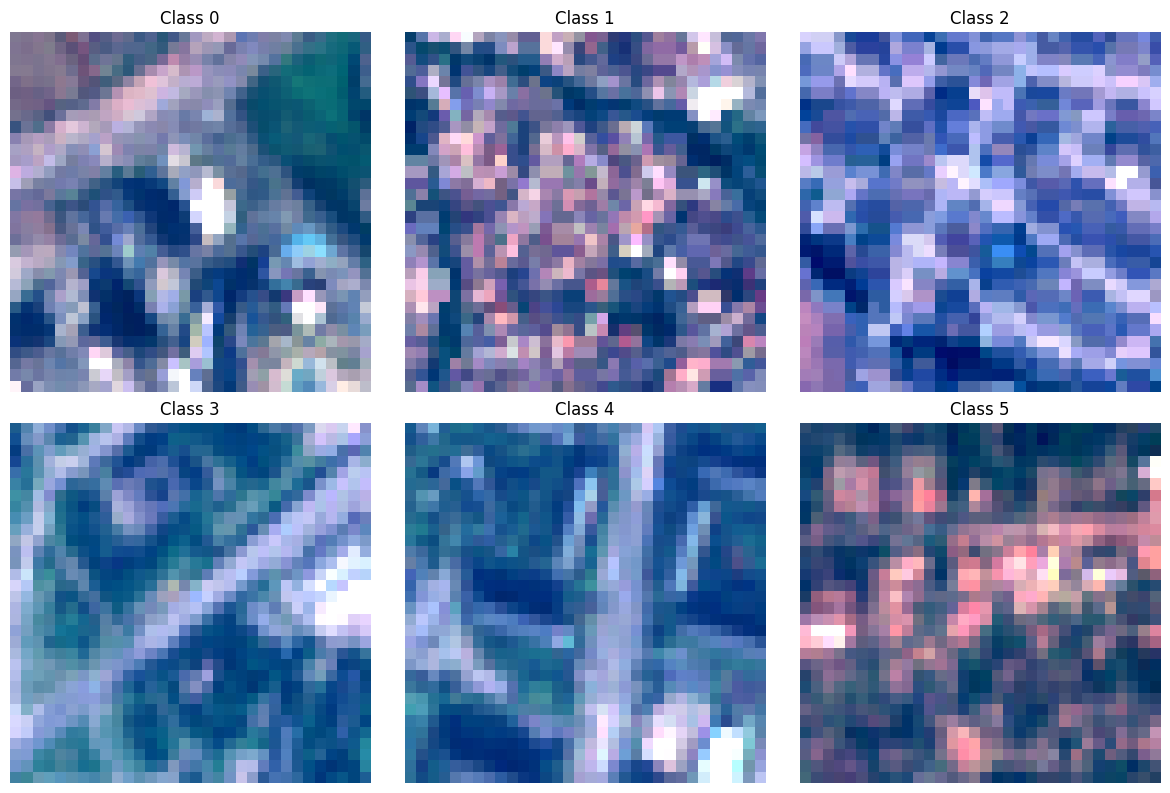

In [ ]:

import h5py
import numpy as np
import matplotlib.pyplot as plt

path = "/content/validation.h5"

with h5py.File(path, "r") as f:
    labels = f["label"][:]
    sen2 = f["sen2"]

    # Convert one-hot labels into class indices
    class_ids = np.argmax(labels, axis=1)

    print("Number of samples:", len(class_ids))
    print("Number of classes:", labels.shape[1])
    print("\nSamples per class:")

    for class_id, count in enumerate(np.bincount(class_ids, minlength=17)):
        print(f"Class {class_id}: {count}")

    # Inspect reflectance values
    sample = sen2[0]

    print("\nSentinel-2 sample:")
    print("Shape:", sample.shape)
    print("Minimum:", sample.min())
    print("Maximum:", sample.max())
    print("Mean:", sample.mean())

    # Select one sample from several classes
    selected_classes = np.unique(class_ids)[:6]

    fig, axes = plt.subplots(2, 3, figsize=(12, 8))

    for ax, class_id in zip(axes.flat, selected_classes):
        idx = np.where(class_ids == class_id)[0][0]

        # B4, B3, B2 = RGB
        rgb = sen2[idx][:, :, [2, 1, 0]]

        low = np.percentile(rgb, 2)
        high = np.percentile(rgb, 98)
        rgb = np.clip((rgb - low) / (high - low + 1e-8), 0, 1)

        ax.imshow(rgb)
        ax.set_title(f"Class {class_id}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()


In [ ]:
import h5py
import numpy as np

path = "/content/validation.h5"

rng = np.random.default_rng(42)
indices = np.sort(rng.choice(24119, size=500, replace=False))

with h5py.File(path, "r") as f:
    rgb_samples = f["sen2"][indices][:, :, :, [2, 1, 0]]

print("RGB shape:", rgb_samples.shape)

for percentile in [0, 1, 5, 25, 50, 75, 95, 99, 100]:
    print(
        f"{percentile}th percentile:",
        np.percentile(rgb_samples, percentile)
    )

RGB shape: (500, 32, 32, 3)
0th percentile: 0.0001
1th percentile: 0.0298
5th percentile: 0.0516
25th percentile: 0.0885
50th percentile: 0.1142
75th percentile: 0.1389
95th percentile: 0.1897
99th percentile: 0.282
100th percentile: 2.5556


In [ ]:
import h5py
import numpy as np

with h5py.File("/content/validation.h5", "r") as f:
    rgb = f["sen2"][indices][:, :, :, [2, 1, 0]]

for channel, name in enumerate(["Red (B4)", "Green (B3)", "Blue (B2)"]):
    values = rgb[..., channel].ravel()

    print(f"\n{name}")
    for p in [50, 90, 95, 99, 99.5, 99.9, 99.99, 100]:
        print(f"{p}%: {np.percentile(values, p):.5f}")

    print("Values > 0.5:", np.sum(values > 0.5))
    print("Values > 1.0:", np.sum(values > 1.0))



Red (B4)
50%: 0.10250
90%: 0.17530
95%: 0.20060
99%: 0.30500
99.5%: 0.37820
99.9%: 0.50590
99.99%: 0.56750
100%: 0.99220
Values > 0.5: 619
Values > 1.0: 0

Green (B3)
50%: 0.11040
90%: 0.15770
95%: 0.17990
99%: 0.27390
99.5%: 0.33730
99.9%: 0.44910
99.99%: 0.54846
100%: 0.97060
Values > 0.5: 132
Values > 1.0: 0

Blue (B2)
50%: 0.12260
90%: 0.16620
95%: 0.18560
99%: 0.27090
99.5%: 0.32790
99.9%: 0.42750
99.99%: 0.92382
100%: 2.55560
Values > 0.5: 128
Values > 1.0: 50


In [ ]:
import h5py
import numpy as np

with h5py.File("/content/validation.h5", "r") as f:
    rgb = f["sen2"][indices][:, :, :, [2, 1, 0]]

for channel, name in enumerate(["Red", "Green", "Blue"]):
    values = rgb[..., channel]

    flat_idx = np.argmax(values)
    sample_idx, row, col = np.unravel_index(
        flat_idx, values.shape
    )

    print(f"\n{name}")
    print("Maximum:", values[sample_idx, row, col])
    print("Original dataset index:", indices[sample_idx])
    print("Pixel coordinates:", (row, col))
    print("All channel values at same pixel:",
          rgb[sample_idx, row, col, :])


Red
Maximum: 0.9922
Original dataset index: 17383
Pixel coordinates: (np.int64(25), np.int64(13))
All channel values at same pixel: [0.9922 0.9706 0.7422]

Green
Maximum: 0.9706
Original dataset index: 17383
Pixel coordinates: (np.int64(25), np.int64(13))
All channel values at same pixel: [0.9922 0.9706 0.7422]

Blue
Maximum: 2.5556
Original dataset index: 19696
Pixel coordinates: (np.int64(8), np.int64(4))
All channel values at same pixel: [0.1232 0.471  2.5556]


In [ ]:
import h5py
import numpy as np

sample_ids = [17383, 19696]

with h5py.File("/content/validation.h5", "r") as f:
    for idx in sample_ids:
        rgb = f["sen2"][idx][:, :, [2, 1, 0]]

        print(f"\nPatch {idx}")
        print("Channel maxima:", rgb.max(axis=(0, 1)))
        print("Channel means:", rgb.mean(axis=(0, 1)))

        # Inspect the 3x3 neighborhood around the blue maximum
        if idx == 19696:
            r, c = 8, 4
            print("Blue-channel neighborhood:")
            print(rgb[r-1:r+2, c-1:c+2, 2])


Patch 17383
Channel maxima: [0.9922 0.9706 0.7422]
Channel means: [0.08817666 0.09237061 0.10486689]

Patch 19696
Channel maxima: [0.3048 0.471  2.5556]
Channel means: [0.09896016 0.10380117 0.12474443]
Blue-channel neighborhood:
[[5.9380e-01 1.1397e+00 2.6590e-01]
 [1.1404e+00 2.5556e+00 9.2580e-01]
 [1.0000e-04 3.8940e-01 3.5140e-01]]


In [ ]:
import h5py
import numpy as np

with h5py.File("/content/validation.h5", "r") as f:
    sen2 = f["sen2"]

    thresholds = [0.5, 1.0, 1.5, 2.0]

    counts = {t: 0 for t in thresholds}
    patches_with_extreme = set()

    for start in range(0, len(sen2), 500):
        batch = sen2[start:start+500, :, :, 0]  # B2

        for t in thresholds:
            counts[t] += np.sum(batch > t)

        patch_max = batch.max(axis=(1, 2))
        patches_with_extreme.update(
            (start + np.where(patch_max > 1.0)[0]).tolist()
        )

print("Blue-channel pixel counts:")
for threshold, count in counts.items():
    print(f"> {threshold}: {count:,}")

print("\nPatches with at least one blue value > 1.0:",
      len(patches_with_extreme))

Blue-channel pixel counts:
> 0.5: 4,367
> 1.0: 356
> 1.5: 176
> 2.0: 76

Patches with at least one blue value > 1.0: 47


In [ ]:
import h5py
import numpy as np

with h5py.File("/content/validation.h5", "r") as f:
    sen2 = f["sen2"]

    band_names = [
        "B2", "B3", "B4", "B5", "B6",
        "B7", "B8", "B8A", "B11", "B12"
    ]

    band_maxima = np.zeros(10)

    for start in range(0, len(sen2), 500):
        batch = sen2[start:start+500]
        band_maxima = np.maximum(
            band_maxima,
            batch.max(axis=(0, 1, 2))
        )

    for name, maximum in zip(band_names, band_maxima):
        print(f"{name}: {maximum:.4f}")

B2: 2.8000
B3: 2.8000
B4: 2.8000
B5: 2.4563
B6: 2.7932
B7: 2.8002
B8: 2.8000
B8A: 2.8005
B11: 2.4939
B12: 2.1559


In [ ]:
import h5py
import numpy as np

with h5py.File("/content/validation.h5", "r") as f:
    # Read B2, B3, B4 in increasing index order
    rgb = f["sen2"][:500, :, :, :3]

    # Reorder B2, B3, B4 into B4, B3, B2
    rgb = rgb[:, :, :, ::-1].copy()

rgb_scaled = np.clip(rgb, 0, 2.8) / 2.8

print("Original range:", rgb.min(), rgb.max())
print("Scaled range:", rgb_scaled.min(), rgb_scaled.max())
print("Scaled mean:", rgb_scaled.mean())
print("Scaled standard deviation:", rgb_scaled.std())

Original range: 0.0001 2.8
Scaled range: 3.571428571428572e-05 1.0
Scaled mean: 0.043128346144903275
Scaled standard deviation: 0.018981059278405737


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import shutil

destination = '/content/drive/MyDrive/TerraScope-AI/data/raw'
os.makedirs(destination, exist_ok=True)

files = [
    'validation.h5',
    'validation.h5.gz',
    'validation_geo.h5',
    'testing_geo.h5'
]

for filename in files:
    source = f'/content/{filename}'

    if os.path.exists(source):
        shutil.copy2(source, destination)
        print(f'Copied: {filename}')
    else:
        print(f'Not found: {filename}')

Mounted at /content/drive
Copied: validation.h5
Copied: validation.h5.gz
Copied: validation_geo.h5
Copied: testing_geo.h5


In [ ]:
import requests
from tqdm.auto import tqdm

url = "https://huggingface.co/datasets/zhu-xlab/So2Sat-LCZ42/resolve/main/v4/testing.h5.gz"
output_path = "/content/testing.h5.gz"

response = requests.get(url, stream=True)
response.raise_for_status()

total = int(response.headers.get("content-length", 0))

with open(output_path, "wb") as f:
    for chunk in tqdm(
        response.iter_content(chunk_size=1024 * 1024),
        total=total // (1024 * 1024),
        unit="MB"
    ):
        if chunk:
            f.write(chunk)

print("Download complete:", output_path)

  0%|          | 0/1049 [00:00<?, ?MB/s]

Download complete: /content/testing.h5.gz


In [ ]:
import shutil
import os

destination = '/content/drive/MyDrive/TerraScope-AI/data/raw/testing.h5.gz'

shutil.copy2('/content/testing.h5.gz', destination)

print("Copied:", os.path.exists(destination))
print("File size (GB):", round(os.path.getsize(destination) / 1e9, 2))

Copied: True
File size (GB): 1.1


In [ ]:
import gzip
import shutil
import os
import h5py

compressed_path = "/content/testing.h5.gz"
extracted_path = "/content/testing.h5"

# Check available storage first
free_gb = shutil.disk_usage("/content").free / 1e9
print(f"Available storage: {free_gb:.2f} GB")

# Extract
with gzip.open(compressed_path, "rb") as source:
    with open(extracted_path, "wb") as destination:
        shutil.copyfileobj(source, destination, length=1024 * 1024 * 16)

print("Extraction complete.")

# Inspect without loading the full dataset into memory
with h5py.File(extracted_path, "r") as f:
    for key in f.keys():
        print(key, f[key].shape, f[key].dtype)

print("Extracted size:", round(os.path.getsize(extracted_path) / 1e9, 2), "GB")

Available storage: 48.44 GB
Extraction complete.
label (24188, 17) float64
sen1 (24188, 32, 32, 8) float64
sen2 (24188, 32, 32, 10) float64
Extracted size: 3.57 GB


In [ ]:
import shutil
import os

source = "/content/testing.h5"
destination = "/content/drive/MyDrive/TerraScope-AI/data/raw/testing.h5"

shutil.copy2(source, destination)

print("Backup verified:", os.path.exists(destination))
print("Size (GB):", round(os.path.getsize(destination) / 1e9, 2))

Backup verified: True
Size (GB): 3.57


In [ ]:
import h5py
import numpy as np

rng = np.random.default_rng(42)

def inspect_rgb(path, name, n=2000):
    with h5py.File(path, "r") as f:
        total = f["sen2"].shape[0]
        indices = np.sort(rng.choice(total, min(n, total), replace=False))

        # Original order: B2, B3, B4
        # Convert to RGB: B4, B3, B2
        rgb = f["sen2"][indices, :, :, :3][..., ::-1].copy()

    values = rgb.reshape(-1, 3)

    print(f"\n{name}: {len(indices)} sampled patches")
    print("Overall min/max:", values.min(), values.max())

    for i, channel in enumerate(["Red (B4)", "Green (B3)", "Blue (B2)"]):
        x = values[:, i]
        print(f"\n{channel}")
        print("  Mean:", round(float(x.mean()), 5))
        print("  Std:", round(float(x.std()), 5))
        print("  Percentiles:", np.percentile(x, [1, 50, 95, 99, 99.9]).round(5))
        print("  Fraction above 1:", round(float(np.mean(x > 1)), 6))

inspect_rgb("/content/validation.h5", "Validation")
inspect_rgb("/content/testing.h5", "Testing")


Validation: 2000 sampled patches
Overall min/max: 0.0001 2.8

Red (B4)
  Mean: 0.1107
  Std: 0.05779
  Percentiles: [0.0264 0.1037 0.2036 0.302  0.5035]
  Fraction above 1: 1.2e-05

Green (B3)
  Mean: 0.11567
  Std: 0.04278
  Percentiles: [0.0509 0.1114 0.1822 0.2677 0.4503]
  Fraction above 1: 3e-06

Blue (B2)
  Mean: 0.12854
  Std: 0.03813
  Percentiles: [0.0753 0.1238 0.1863 0.263  0.4345]
  Fraction above 1: 2.6e-05

Testing: 2000 sampled patches
Overall min/max: 0.0001 2.8

Red (B4)
  Mean: 0.11111
  Std: 0.05704
  Percentiles: [0.0245 0.1062 0.202  0.283  0.4662]
  Fraction above 1: 1.7e-05

Green (B3)
  Mean: 0.11508
  Std: 0.04167
  Percentiles: [0.0467 0.1121 0.1804 0.253  0.4049]
  Fraction above 1: 1.1e-05

Blue (B2)
  Mean: 0.1278
  Std: 0.0363
  Percentiles: [0.0774 0.1254 0.1851 0.2498 0.3872]
  Fraction above 1: 1.2e-05


In [ ]:
import numpy as np
import h5py

def preprocess_sentinel2_rgb(x):
    """
    Input: Sentinel-2 RGB, ordered B4, B3, B2.
    Output: float32 RGB scaled to [0, 1].
    """
    x = np.clip(x, 0.0, 2.8)
    x = x / 2.8
    return x.astype(np.float32)

with h5py.File("/content/validation.h5", "r") as f:
    sample = f["sen2"][0, :, :, :3][..., ::-1].copy()

processed = preprocess_sentinel2_rgb(sample)

print("Original shape:", sample.shape)
print("Processed shape:", processed.shape)
print("Processed range:", processed.min(), processed.max())
print("Processed mean:", processed.mean())
print("Processed dtype:", processed.dtype)

Original shape: (32, 32, 3)
Processed shape: (32, 32, 3)
Processed range: 0.02175 0.04342857
Processed mean: 0.032334585
Processed dtype: float32


In [ ]:
import h5py
import numpy as np

rng = np.random.default_rng(42)
n = 2000

with h5py.File("/content/validation.h5", "r") as f:
    total = f["sen2"].shape[0]
    indices = np.sort(rng.choice(total, n, replace=False))

    rgb = f["sen2"][indices, :, :, :3][..., ::-1].copy()

rgb = preprocess_sentinel2_rgb(rgb)

channel_means = rgb.mean(axis=(0, 1, 2))
channel_stds = rgb.std(axis=(0, 1, 2))

print("RGB means:", channel_means)
print("RGB standard deviations:", channel_stds)

RGB means: [0.03953484 0.04131048 0.0459583 ]
RGB standard deviations: [0.02062614 0.01526319 0.01360236]


In [ ]:
import h5py
import numpy as np
from sklearn.model_selection import train_test_split

with h5py.File("/content/validation.h5", "r") as f:
    labels = np.argmax(f["label"][:], axis=1)

indices = np.arange(len(labels))

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

print("Training patches:", len(train_idx))
print("Internal validation patches:", len(val_idx))

print("\nTraining class counts:")
print(np.bincount(labels[train_idx], minlength=17))

print("\nValidation class counts:")
print(np.bincount(labels[val_idx], minlength=17))

Training patches: 19295
Internal validation patches: 4824

Training class counts:
[ 205 1003 1882  679  606 1525  379 2716 1531  688 1829  306  962 2197
  162  538 2087]

Validation class counts:
[ 51 251 471 170 151 381  95 679 383 172 458  76 240 550  40 134 522]


In [ ]:
import numpy as np
import json
import os

project_dir = "/content/drive/MyDrive/TerraScope-AI"
config_dir = os.path.join(project_dir, "configs")
os.makedirs(config_dir, exist_ok=True)

# Save reproducible split indices
np.savez(
    os.path.join(config_dir, "so2sat_split.npz"),
    train_idx=train_idx,
    val_idx=val_idx
)

# Save preprocessing configuration
config = {
    "seed": 42,
    "source_dataset": "EuroSAT",
    "target_dataset": "So2Sat-LCZ42",
    "adaptation_split": {
        "training_samples": int(len(train_idx)),
        "validation_samples": int(len(val_idx)),
        "method": "stratified 80/20 split",
        "random_state": 42
    },
    "rgb_bands": ["B4", "B3", "B2"],
    "reflectance_clip": [0.0, 2.8],
    "reflectance_scale": 2.8,
    "normalization_mean": [0.03953484, 0.04131048, 0.04595830],
    "normalization_std": [0.02062614, 0.01526319, 0.01360236]
}

with open(os.path.join(config_dir, "preprocessing.json"), "w") as f:
    json.dump(config, f, indent=4)

print("Saved split and preprocessing configuration.")

Saved split and preprocessing configuration.


In [ ]:
import h5py
import numpy as np
import json
import os

rng = np.random.default_rng(42)
sample_size = min(5000, len(train_idx))
sample_idx = np.sort(rng.choice(train_idx, sample_size, replace=False))

with h5py.File("/content/validation.h5", "r") as f:
    rgb = f["sen2"][sample_idx, :, :, :3][..., ::-1].copy()

rgb = preprocess_sentinel2_rgb(rgb)

means = rgb.mean(axis=(0, 1, 2)).tolist()
stds = rgb.std(axis=(0, 1, 2)).tolist()

print("Training-only RGB means:", means)
print("Training-only RGB stds:", stds)

config_path = "/content/drive/MyDrive/TerraScope-AI/configs/preprocessing.json"

with open(config_path, "r") as f:
    config = json.load(f)

config["normalization_mean"] = means
config["normalization_std"] = stds
config["normalization_sample_size"] = sample_size
config["normalization_sample_seed"] = 42

with open(config_path, "w") as f:
    json.dump(config, f, indent=4)

print("\nUpdated preprocessing.json")

Training-only RGB means: [0.0400128997862339, 0.04147166386246681, 0.04605376720428467]
Training-only RGB stds: [0.020939381793141365, 0.015491435304284096, 0.013670714572072029]

Updated preprocessing.json


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
import h5py
import numpy as np

RGB_MEAN = torch.tensor(
    [0.04001290, 0.04147166, 0.04605377]
).view(3, 1, 1)

RGB_STD = torch.tensor(
    [0.02093938, 0.01549144, 0.01367071]
).view(3, 1, 1)


class So2SatDataset(Dataset):
    def __init__(self, h5_path, indices):
        self.h5_path = h5_path
        self.indices = np.asarray(indices)
        self.file = None

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        if self.file is None:
            self.file = h5py.File(self.h5_path, "r")

        actual_idx = int(self.indices[idx])

        # Read Sentinel-2 B2, B3, B4
        image = self.file["sen2"][actual_idx, :, :, :3][..., ::-1].copy()

        # Scale reflectance
        image = np.clip(image, 0.0, 2.8) / 2.8

        # Convert HWC to CHW
        image = torch.from_numpy(image.astype(np.float32)).permute(2, 0, 1)

        # Normalize using training-only statistics
        image = (image - RGB_MEAN) / RGB_STD

        label = int(np.argmax(self.file["label"][actual_idx]))

        return image, label


train_dataset = So2SatDataset("/content/validation.h5", train_idx)
val_dataset = So2SatDataset("/content/validation.h5", val_idx)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0
)

# Test one batch
images, labels_batch = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels_batch.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", labels_batch.dtype)
print("Image range:", images.min().item(), images.max().item())
print("Unique labels:", torch.unique(labels_batch))

Image batch shape: torch.Size([64, 3, 32, 32])
Label batch shape: torch.Size([64])
Image dtype: torch.float32
Label dtype: torch.int64
Image range: -1.4736398458480835 8.682520866394043
Unique labels: tensor([ 0,  1,  2,  4,  5,  6,  7,  8,  9, 10, 12, 13, 15, 16])


In [ ]:
import h5py
import numpy as np

rng = np.random.default_rng(42)
sample_idx = np.sort(
    rng.choice(train_idx, min(2000, len(train_idx)), replace=False)
)

with h5py.File("/content/validation.h5", "r") as f:
    rgb = f["sen2"][sample_idx, :, :, :3][..., ::-1].copy()

rgb = preprocess_sentinel2_rgb(rgb)

# Apply training-only normalization
normalized = (rgb - np.array([0.04001290, 0.04147166, 0.04605377])) / \
             np.array([0.02093938, 0.01549144, 0.01367071])

print("Normalized percentiles:")
print(np.percentile(normalized, [0, 50, 95, 99, 99.9, 99.99, 100]))

print("\nFraction of values with absolute magnitude above thresholds:")
for threshold in [3, 5, 8, 10]:
    print(f">{threshold}: {np.mean(np.abs(normalized) > threshold):.8%}")

print("\nPer-channel maximum:")
for i, channel in enumerate(["Red", "Green", "Blue"]):
    print(channel, normalized[..., i].max())

Normalized percentiles:
[-2.96908386 -0.11805258  1.58334794  3.57262376  7.70545877 11.61331105
 61.87470887]

Fraction of values with absolute magnitude above thresholds:
>3: 1.39505208%
>5: 0.47596029%
>8: 0.07530924%
>10: 0.01790365%

Per-channel maximum:
Red 45.846013587794864
Green 61.87470887147999
Blue 35.38977775557295


In [ ]:
import numpy as np
import h5py

rng = np.random.default_rng(42)

indices = rng.choice(
    len(train_idx),
    min(2000, len(train_idx)),
    replace=False
)

selected = np.sort(train_idx[indices])

with h5py.File("/content/validation.h5", "r") as f:
    rgb = f["sen2"][selected, :, :, :3][..., ::-1].copy()

normalized = (
    np.clip(rgb, 0, 2.8) / 2.8
    - np.array([0.04001290, 0.04147166, 0.04605377])
) / np.array([0.02093938, 0.01549144, 0.01367071])

extreme_mask = np.abs(normalized) > 8
extreme_per_patch = extreme_mask.reshape(len(selected), -1).sum(axis=1)

affected = np.where(extreme_per_patch > 0)[0]

print("Patches containing values above |8|:", len(affected))
print("Total extreme values:", extreme_mask.sum())
print("Maximum extreme values in one patch:", extreme_per_patch.max())

print("\nMost affected patches:")
for i in affected[np.argsort(extreme_per_patch[affected])[-10:]][::-1]:
    print(
        "Dataset index:", selected[i],
        "| Extreme values:", extreme_per_patch[i],
        "| Maximum normalized value:", normalized[i].max()
    )

Patches containing values above |8|: 53
Total extreme values: 4627
Maximum extreme values in one patch: 736

Most affected patches:
Dataset index: 1011 | Extreme values: 736 | Maximum normalized value: 14.392265110833558
Dataset index: 15454 | Extreme values: 529 | Maximum normalized value: 10.498186163807777
Dataset index: 338 | Extreme values: 487 | Maximum normalized value: 10.289188763003951
Dataset index: 325 | Extreme values: 359 | Maximum normalized value: 24.64731019822672
Dataset index: 13372 | Extreme values: 358 | Maximum normalized value: 13.147228218996254
Dataset index: 18395 | Extreme values: 261 | Maximum normalized value: 23.39071332589372
Dataset index: 6007 | Extreme values: 227 | Maximum normalized value: 8.730151988084112
Dataset index: 23944 | Extreme values: 227 | Maximum normalized value: 8.730151988084112
Dataset index: 20248 | Extreme values: 178 | Maximum normalized value: 11.652896803248906
Dataset index: 5525 | Extreme values: 175 | Maximum normalized value

In [ ]:
import h5py
import numpy as np

with h5py.File("/content/validation.h5", "r") as f:
    labels = np.argmax(f["label"][:], axis=1)

    print("Affected patch analysis:\n")

    for i in affected[np.argsort(extreme_per_patch[affected])[-10:]][::-1]:
        idx = selected[i]

        raw = f["sen2"][idx, :, :, :3][..., ::-1].copy()
        class_id = labels[idx]

        print(
            f"Patch {idx} | "
            f"Class {class_id} | "
            f"Extreme pixels {extreme_per_patch[i]} | "
            f"Raw max {raw.max():.4f} | "
            f"Raw mean {raw.mean():.4f} | "
            f"Raw values > 0.5: {np.sum(raw > 0.5)}"
        )

Affected patch analysis:

Patch 1011 | Class 7 | Extreme pixels 736 | Raw max 0.8176 | Raw mean 0.3734 | Raw values > 0.5: 641
Patch 15454 | Class 7 | Extreme pixels 529 | Raw max 0.6037 | Raw mean 0.3890 | Raw values > 0.5: 298
Patch 338 | Class 7 | Extreme pixels 487 | Raw max 0.6208 | Raw mean 0.3801 | Raw values > 0.5: 320
Patch 325 | Class 7 | Extreme pixels 359 | Raw max 1.2657 | Raw mean 0.3477 | Raw values > 0.5: 422
Patch 13372 | Class 7 | Extreme pixels 358 | Raw max 0.7252 | Raw mean 0.3401 | Raw values > 0.5: 327
Patch 18395 | Class 14 | Extreme pixels 261 | Raw max 1.1948 | Raw mean 0.2808 | Raw values > 0.5: 257
Patch 6007 | Class 7 | Extreme pixels 227 | Raw max 0.5904 | Raw mean 0.2565 | Raw values > 0.5: 199
Patch 23944 | Class 7 | Extreme pixels 227 | Raw max 0.5904 | Raw mean 0.2622 | Raw values > 0.5: 199
Patch 20248 | Class 7 | Extreme pixels 178 | Raw max 0.6356 | Raw mean 0.2660 | Raw values > 0.5: 81
Patch 5525 | Class 7 | Extreme pixels 175 | Raw max 0.5977 | R

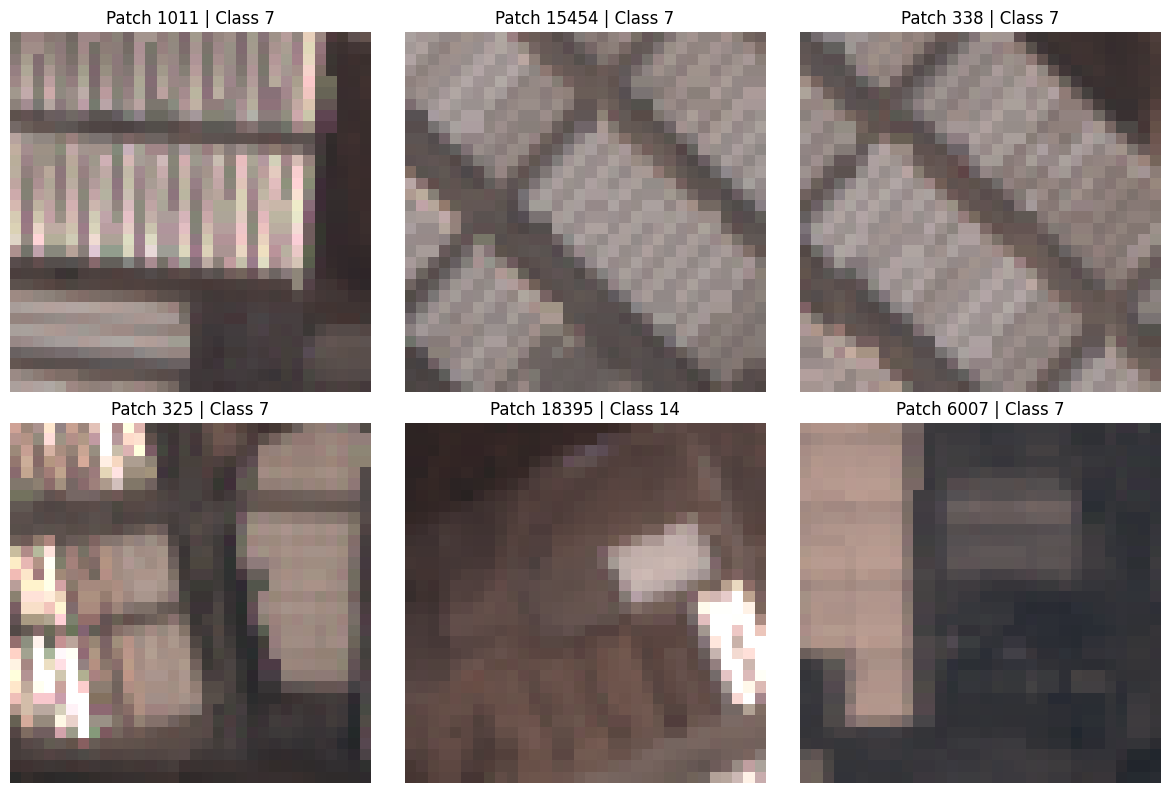

In [ ]:
import matplotlib.pyplot as plt
import h5py
import numpy as np

patch_ids = [1011, 15454, 338, 325, 18395, 6007]

with h5py.File("/content/validation.h5", "r") as f:
    fig, axes = plt.subplots(2, 3, figsize=(12, 8))

    for ax, idx in zip(axes.flat, patch_ids):
        # B2, B3, B4 -> RGB
        rgb = f["sen2"][idx, :, :, :3][..., ::-1].copy()
        label = int(np.argmax(f["label"][idx]))

        # Display using fixed reflectance scaling
        display = np.clip(rgb / 0.8, 0, 1)

        ax.imshow(display)
        ax.set_title(f"Patch {idx} | Class {label}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
import h5py
import numpy as np

rng = np.random.default_rng(42)
sample_idx = np.sort(
    rng.choice(train_idx, min(5000, len(train_idx)), replace=False)
)

with h5py.File("/content/validation.h5", "r") as f:
    rgb = f["sen2"][sample_idx, :, :, :3][..., ::-1].copy()

print("Raw reflectance percentiles by channel:\n")

for i, channel in enumerate(["Red (B4)", "Green (B3)", "Blue (B2)"]):
    values = rgb[..., i].ravel()

    print(f"\n{channel}")
    print(
        np.percentile(
            values,
            [50, 90, 95, 99, 99.5, 99.9, 99.99, 100]
        ).round(5)
    )

Raw reflectance percentiles by channel:


Red (B4)
[0.1048 0.1785 0.2054 0.3094 0.3736 0.5064 0.6657 2.8   ]

Green (B3)
[0.1116 0.1613 0.1842 0.2754 0.3315 0.4465 0.5921 2.8   ]

Blue (B2)
[0.1236 0.1688 0.1885 0.2684 0.3124 0.4279 0.5572 2.5556]


In [ ]:
import torch
import numpy as np

IMAGENET_MEAN = torch.tensor(
    [0.485, 0.456, 0.406]
).view(3, 1, 1)

IMAGENET_STD = torch.tensor(
    [0.229, 0.224, 0.225]
).view(3, 1, 1)

def preprocess_sentinel2_rgb(x):
    x = np.clip(x, 0.0, 2.8) / 2.8

    image = torch.from_numpy(
        x.astype(np.float32)
    ).permute(2, 0, 1)

    return (image - IMAGENET_MEAN) / IMAGENET_STD


images, labels_batch = next(iter(train_loader))

# Check the revised transformation independently
with h5py.File("/content/validation.h5", "r") as f:
    sample = f["sen2"][1011, :, :, :3][..., ::-1].copy()

processed = preprocess_sentinel2_rgb(sample)

print("Shape:", processed.shape)
print("Minimum:", processed.min().item())
print("Maximum:", processed.max().item())
print("Mean:", processed.mean().item())
print("Standard deviation:", processed.std().item())

Shape: torch.Size([3, 32, 32])
Minimum: -1.891297698020935
Maximum: -0.726190447807312
Mean: -1.3961834907531738
Standard deviation: 0.2566145360469818


In [ ]:
class So2SatDataset(Dataset):
    def __init__(self, h5_path, indices):
        self.h5_path = h5_path
        self.indices = np.asarray(indices)
        self.file = None

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        if self.file is None:
            self.file = h5py.File(self.h5_path, "r")

        actual_idx = int(self.indices[idx])

        image = self.file["sen2"][
            actual_idx, :, :, :3
        ][..., ::-1].copy()

        image = preprocess_sentinel2_rgb(image)

        label = int(np.argmax(self.file["label"][actual_idx]))

        return image, label


train_dataset = So2SatDataset(
    "/content/validation.h5", train_idx
)

val_dataset = So2SatDataset(
    "/content/validation.h5", val_idx
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0
)

images, labels_batch = next(iter(train_loader))

print("Image shape:", images.shape)
print("Labels shape:", labels_batch.shape)
print("Image range:", images.min().item(), images.max().item())
print("Image mean:", images.mean().item())
print("Image std:", images.std().item())

Image shape: torch.Size([64, 3, 32, 32])
Labels shape: torch.Size([64])
Image range: -2.1177480220794678 2.248908281326294
Image mean: -1.80317223072052
Image std: 0.164992555975914


In [ ]:
import json

config_path = "/content/drive/MyDrive/TerraScope-AI/configs/preprocessing.json"

with open(config_path, "r") as f:
    config = json.load(f)

config["normalization_method"] = "ImageNet"
config["normalization_mean"] = [0.485, 0.456, 0.406]
config["normalization_std"] = [0.229, 0.224, 0.225]
config["reflectance_clip"] = [0.0, 2.8]
config["reflectance_scale"] = 2.8
config["input_bands"] = ["B4", "B3", "B2"]
config["input_size"] = [32, 32]

with open(config_path, "w") as f:
    json.dump(config, f, indent=4)

print("Final preprocessing configuration saved.")

Final preprocessing configuration saved.


In [ ]:
import torch
import torch.nn as nn
from torchvision.models import resnet18

NUM_CLASSES = 17

def build_resnet18(num_classes):
    model = resnet18(weights=None)

    # Replace the original 1000-class ImageNet classifier
    model.fc = nn.Linear(
        model.fc.in_features,
        num_classes
    )

    return model


# Target-domain model
model = build_resnet18(NUM_CLASSES)

# Check architecture
print(model)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("\nTotal parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")

# Verify output dimensions
dummy_input = torch.randn(4, 3, 32, 32)
output = model(dummy_input)

print("Input shape:", dummy_input.shape)
print("Output shape:", output.shape)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [ ]:
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory (GB):",
        round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2)
    )

PyTorch: 2.14.1+cpu
CUDA available: False


In [ ]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("GPU:", torch.cuda.get_device_name(0))
else:
    device = torch.device("cpu")
    print("Using CPU")

CUDA available: True
GPU: Tesla T4


In [ ]:
from google.colab import drive
import os

if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")

data_dir = "/content/drive/MyDrive/TerraScope-AI/data/raw"

for filename in ["validation.h5", "testing.h5"]:
    path = os.path.join(data_dir, filename)
    print(filename, "FOUND" if os.path.exists(path) else "MISSING")

Mounted at /content/drive
validation.h5 FOUND
testing.h5 FOUND


In [ ]:
from pathlib import Path
import json
import numpy as np
import torch

ROOT = Path("/content/drive/MyDrive/TerraScope-AI")

files_to_check = [
    ROOT / "data/raw/validation.h5",
    ROOT / "data/raw/testing.h5",
    ROOT / "configs/so2sat_split.npz",
    ROOT / "configs/preprocessing.json",
]

for path in files_to_check:
    print(f"{path.name}: {'FOUND' if path.exists() else 'MISSING'}")

print("\nGPU:", torch.cuda.get_device_name(0))
print("CUDA available:", torch.cuda.is_available())

split = np.load(ROOT / "configs/so2sat_split.npz")
print("\nSplit arrays:", split.files)

with open(ROOT / "configs/preprocessing.json") as f:
    config = json.load(f)

print("\nPreprocessing configuration:")
print(json.dumps(config, indent=2))

validation.h5: FOUND
testing.h5: FOUND
so2sat_split.npz: FOUND
preprocessing.json: FOUND

GPU: Tesla T4
CUDA available: True

Split arrays: ['train_idx', 'val_idx']

Preprocessing configuration:
{
  "seed": 42,
  "source_dataset": "EuroSAT",
  "target_dataset": "So2Sat-LCZ42",
  "adaptation_split": {
    "training_samples": 19295,
    "validation_samples": 4824,
    "method": "stratified 80/20 split",
    "random_state": 42
  },
  "rgb_bands": [
    "B4",
    "B3",
    "B2"
  ],
  "reflectance_clip": [
    0.0,
    2.8
  ],
  "reflectance_scale": 2.8,
  "normalization_mean": [
    0.485,
    0.456,
    0.406
  ],
  "normalization_std": [
    0.229,
    0.224,
    0.225
  ],
  "normalization_sample_size": 5000,
  "normalization_sample_seed": 42,
  "normalization_method": "ImageNet",
  "input_bands": [
    "B4",
    "B3",
    "B2"
  ],
  "input_size": [
    32,
    32
  ]
}


In [ ]:
import torch
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

NUM_CLASSES = 17
device = torch.device("cuda")

def build_resnet18(initialization="scratch"):
    if initialization == "imagenet":
        model = resnet18(weights=ResNet18_Weights.DEFAULT)
    elif initialization == "scratch":
        model = resnet18(weights=None)
    else:
        raise ValueError("Use 'scratch' or 'imagenet'")

    # Adapt the network for 32x32 satellite patches
    model.conv1.stride = (1, 1)
    model.maxpool = nn.Identity()

    # Replace ImageNet's 1000-class output layer
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)

    return model

# Test the architecture
model = build_resnet18("imagenet").to(device)

dummy_input = torch.randn(4, 3, 32, 32, device=device)

with torch.no_grad():
    output = model(dummy_input)

print("GPU:", torch.cuda.get_device_name(0))
print("Input shape:", dummy_input.shape)
print("Output shape:", output.shape)
print("Parameters:", sum(p.numel() for p in model.parameters()))
print("Model device:", next(model.parameters()).device)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 169MB/s]


GPU: Tesla T4
Input shape: torch.Size([4, 3, 32, 32])
Output shape: torch.Size([4, 17])
Parameters: 11185233
Model device: cuda:0


In [ ]:
from torchvision.datasets import EuroSAT
from torchvision import transforms
from torch.utils.data import DataLoader, random_split

EUROSAT_ROOT = "/content/drive/MyDrive/TerraScope-AI/data"

eurosat_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eurosat_dataset = EuroSAT(
    root=EUROSAT_ROOT,
    download=True,
    transform=eurosat_transform
)

print("Number of images:", len(eurosat_dataset))
print("Number of classes:", len(eurosat_dataset.classes))
print("Classes:", eurosat_dataset.classes)

100%|██████████| 94.3M/94.3M [00:01<00:00, 84.3MB/s]


Number of images: 27000
Number of classes: 10
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset, DataLoader

SEED = 42
BATCH_SIZE = 64

# Extract labels for stratified splitting
eurosat_labels = np.array(eurosat_dataset.targets)

eurosat_train_idx, eurosat_val_idx = train_test_split(
    np.arange(len(eurosat_labels)),
    test_size=0.20,
    random_state=SEED,
    stratify=eurosat_labels
)

# Create datasets
eurosat_train = Subset(eurosat_dataset, eurosat_train_idx)
eurosat_val = Subset(eurosat_dataset, eurosat_val_idx)

# Create loaders
eurosat_train_loader = DataLoader(
    eurosat_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

eurosat_val_loader = DataLoader(
    eurosat_val,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Training samples:", len(eurosat_train))
print("Validation samples:", len(eurosat_val))

print("\nTraining class distribution:")
print(np.bincount(eurosat_labels[eurosat_train_idx]))

# Verify a batch
images, labels = next(iter(eurosat_train_loader))

print("\nImage batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)

Training samples: 21600
Validation samples: 5400

Training class distribution:
[2400 2400 2400 2000 2000 1600 2000 2400 2000 2400]

Image batch shape: torch.Size([64, 3, 32, 32])
Label batch shape: torch.Size([64])
Image dtype: torch.float32
Label dtype: torch.int64


In [ ]:

import os
import json
import copy
import numpy as np
import torch
import torch.nn as nn

from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score

# ============================================================
# 1. CONFIGURATION
# ============================================================

SEED = 42
MAX_EPOCHS = 12
NUM_CLASSES = 10

CHECKPOINT_DIR = (
    "/content/drive/MyDrive/TerraScope-AI/checkpoints"
)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

torch.manual_seed(SEED)
np.random.seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("Device:", device)
print("Training samples:", len(eurosat_train))
print("Validation samples:", len(eurosat_val))

# ============================================================
# 2. MODEL INITIALIZATION
# ============================================================

# Start from ImageNet-pretrained ResNet-18
eurosat_model = build_resnet18("imagenet").to(device)

# Replace the 17-class head with a 10-class EuroSAT head
eurosat_model.fc = nn.Linear(
    eurosat_model.fc.in_features,
    NUM_CLASSES
).to(device)

criterion = nn.CrossEntropyLoss()

# Lower learning rate for pretrained backbone.
# Higher learning rate for the new classification head.
optimizer = torch.optim.AdamW([
    {"params": eurosat_model.layer1.parameters(), "lr": 1e-4},
    {"params": eurosat_model.layer2.parameters(), "lr": 1e-4},
    {"params": eurosat_model.layer3.parameters(), "lr": 1e-4},
    {"params": eurosat_model.layer4.parameters(), "lr": 1e-4},
    {"params": eurosat_model.conv1.parameters(), "lr": 1e-4},
    {"params": eurosat_model.bn1.parameters(), "lr": 1e-4},
    {"params": eurosat_model.fc.parameters(), "lr": 1e-3}
], weight_decay=1e-4)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

scaler = torch.amp.GradScaler("cuda")

# ============================================================
# 3. TRAINING SETUP
# ============================================================

best_val_loss = float("inf")
best_state = None
history = []

history_path = os.path.join(
    CHECKPOINT_DIR,
    "eurosat_training_history.json"
)

best_checkpoint_path = os.path.join(
    CHECKPOINT_DIR,
    "eurosat_resnet18_best.pth"
)

# ============================================================
# 4. TRAINING LOOP
# ============================================================

for epoch in range(MAX_EPOCHS):

    # -------------------------
    # TRAINING
    # -------------------------

    eurosat_model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    progress = tqdm(
        eurosat_train_loader,
        desc=f"Epoch {epoch+1}/{MAX_EPOCHS}"
    )

    for images, labels in progress:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda"):
            outputs = eurosat_model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss += loss.item() * labels.size(0)

        train_correct += (
            outputs.argmax(dim=1) == labels
        ).sum().item()

        train_total += labels.size(0)

    train_loss /= train_total
    train_accuracy = train_correct / train_total

    # -------------------------
    # VALIDATION
    # -------------------------

    eurosat_model.eval()

    val_loss = 0.0
    val_predictions = []
    val_targets = []

    with torch.no_grad():

        for images, labels in eurosat_val_loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.amp.autocast("cuda"):
                outputs = eurosat_model(images)
                loss = criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)

            val_predictions.extend(
                outputs.argmax(dim=1).cpu().numpy()
            )

            val_targets.extend(
                labels.cpu().numpy()
            )

    val_loss /= len(eurosat_val)

    val_accuracy = accuracy_score(
        val_targets,
        val_predictions
    )

    val_macro_f1 = f1_score(
        val_targets,
        val_predictions,
        average="macro"
    )

    # Update learning-rate scheduler
    scheduler.step(val_loss)

    # -------------------------
    # RECORD METRICS
    # -------------------------

    epoch_results = {
        "epoch": epoch + 1,
        "train_loss": float(train_loss),
        "train_accuracy": float(train_accuracy),
        "val_loss": float(val_loss),
        "val_accuracy": float(val_accuracy),
        "val_macro_f1": float(val_macro_f1),
        "learning_rates": [
            group["lr"] for group in optimizer.param_groups
        ]
    }

    history.append(epoch_results)

    print(
        f"\nEpoch {epoch+1}/{MAX_EPOCHS}\n"
        f"Train loss: {train_loss:.4f}\n"
        f"Train accuracy: {train_accuracy:.4f}\n"
        f"Validation loss: {val_loss:.4f}\n"
        f"Validation accuracy: {val_accuracy:.4f}\n"
        f"Validation macro-F1: {val_macro_f1:.4f}"
    )

    # -------------------------
    # SAVE EVERY EPOCH
    # -------------------------

    epoch_checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        f"eurosat_epoch_{epoch+1}.pth"
    )

    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": eurosat_model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "val_macro_f1": val_macro_f1,
        "architecture": "ResNet18 adapted for 32x32",
        "source_dataset": "EuroSAT",
        "initialization": "ImageNet"
    }, epoch_checkpoint_path)

    # Save history after every epoch
    with open(history_path, "w") as f:
        json.dump(history, f, indent=2)

    # -------------------------
    # SAVE BEST CHECKPOINT
    # -------------------------

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_state = copy.deepcopy(
            eurosat_model.state_dict()
        )

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": best_state,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy,
            "val_macro_f1": val_macro_f1,
            "architecture": "ResNet18 adapted for 32x32",
            "source_dataset": "EuroSAT",
            "initialization": "ImageNet"
        }, best_checkpoint_path)

        print("New best checkpoint saved.")

# ============================================================
# 5. RESTORE BEST MODEL
# ============================================================

eurosat_model.load_state_dict(best_state)

print("\n" + "=" * 50)
print("EUROSAT PRETRAINING COMPLETE")
print("=" * 50)

print("Epochs completed:", len(history))
print("Best validation loss:", best_val_loss)
print("Best epoch:", min(
    history,
    key=lambda x: x["val_loss"]
)["epoch"])

print("\nSaved files:")
print("Best model:", best_checkpoint_path)
print("Training history:", history_path)
print("Individual epoch checkpoints:", MAX_EPOCHS)


Device: cuda
Training samples: 21600
Validation samples: 5400


Epoch 1/12:   0%|          | 0/338 [00:00<?, ?it/s]


Epoch 1/12
Train loss: 0.3571
Train accuracy: 0.8784
Validation loss: 0.1801
Validation accuracy: 0.9352
Validation macro-F1: 0.9341
New best checkpoint saved.


Epoch 2/12:   0%|          | 0/338 [00:00<?, ?it/s]


Epoch 2/12
Train loss: 0.1189
Train accuracy: 0.9602
Validation loss: 0.1695
Validation accuracy: 0.9419
Validation macro-F1: 0.9393
New best checkpoint saved.


Epoch 3/12:   0%|          | 0/338 [00:00<?, ?it/s]

In [ ]:
import os
import glob
import json

checkpoint_dir = (
    "/content/drive/MyDrive/TerraScope-AI/checkpoints"
)

print("Saved epoch checkpoints:")
for path in sorted(glob.glob(
    os.path.join(checkpoint_dir, "eurosat_epoch_*.pth")
)):
    print(os.path.basename(path))

history_path = os.path.join(
    checkpoint_dir, "eurosat_training_history.json"
)

if os.path.exists(history_path):
    with open(history_path) as f:
        saved_history = json.load(f)

    print("\nCompleted epochs:", len(saved_history))
    for row in saved_history:
        print(
            f"Epoch {row['epoch']}: "
            f"val_loss={row['val_loss']:.4f}, "
            f"val_acc={row['val_accuracy']:.4f}"
        )

Saved epoch checkpoints:
eurosat_epoch_1.pth
eurosat_epoch_2.pth

Completed epochs: 2
Epoch 1: val_loss=0.1801, val_acc=0.9352
Epoch 2: val_loss=0.1695, val_acc=0.9419


In [ ]:
import torch
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

NUM_CLASSES = 10
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def build_resnet18(initialization="scratch"):
    if initialization == "imagenet":
        model = resnet18(weights=ResNet18_Weights.DEFAULT)
    elif initialization == "scratch":
        model = resnet18(weights=None)
    else:
        raise ValueError(f"Unknown initialization: {initialization}")

    model.conv1.stride = (1, 1)
    model.maxpool = nn.Identity()
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)

    return model

print("Model builder restored.")
print("Device:", device)

Model builder restored.
Device: cuda


In [ ]:

# ============================================================
# TERRASCOPE AI: EURO-SAT TRAINING (RESUMABLE)
# Resume from epoch 2, train through epoch 12
# ============================================================

import os
import json
import shutil
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision.datasets import EuroSAT
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

SEED = 42
NUM_CLASSES = 10
BATCH_SIZE = 64
MAX_EPOCHS = 12

ROOT = "/content/drive/MyDrive/TerraScope-AI"
DATA_ROOT = os.path.join(ROOT, "data")
CHECKPOINT_DIR = os.path.join(ROOT, "checkpoints")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.manual_seed(SEED)
np.random.seed(SEED)

print("Device:", device)

# ------------------------------------------------------------
# 2. MODEL ARCHITECTURE
# ------------------------------------------------------------

def build_resnet18(initialization="scratch"):
    if initialization == "imagenet":
        model = resnet18(weights=ResNet18_Weights.DEFAULT)
    elif initialization == "scratch":
        model = resnet18(weights=None)
    else:
        raise ValueError(f"Unknown initialization: {initialization}")

    # Adapt ResNet-18 for 32x32 satellite images
    model.conv1.stride = (1, 1)
    model.maxpool = nn.Identity()
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)

    return model

eurosat_model = build_resnet18("scratch").to(device)

# ------------------------------------------------------------
# 3. OPTIMIZER
# ------------------------------------------------------------

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    [
        {"params": eurosat_model.layer1.parameters(), "lr": 1e-4},
        {"params": eurosat_model.layer2.parameters(), "lr": 1e-4},
        {"params": eurosat_model.layer3.parameters(), "lr": 1e-4},
        {"params": eurosat_model.layer4.parameters(), "lr": 1e-4},
        {"params": eurosat_model.conv1.parameters(), "lr": 1e-4},
        {"params": eurosat_model.bn1.parameters(), "lr": 1e-4},
        {"params": eurosat_model.fc.parameters(), "lr": 1e-3},
    ],
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(device.type == "cuda")
)

# ------------------------------------------------------------
# 4. RESTORE EPOCH 2 CHECKPOINT
# ------------------------------------------------------------

checkpoint_path = os.path.join(
    CHECKPOINT_DIR,
    "eurosat_epoch_2.pth"
)

if not os.path.exists(checkpoint_path):
    raise FileNotFoundError(
        f"Checkpoint not found: {checkpoint_path}"
    )

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

eurosat_model.load_state_dict(
    checkpoint["model_state_dict"]
)

optimizer.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

start_epoch = checkpoint["epoch"] + 1

print("Restored checkpoint:", os.path.basename(checkpoint_path))
print("Starting at epoch:", start_epoch)

# ------------------------------------------------------------
# 5. RESTORE TRAINING HISTORY
# ------------------------------------------------------------

history_path = os.path.join(
    CHECKPOINT_DIR,
    "eurosat_training_history.json"
)

if os.path.exists(history_path):
    with open(history_path, "r") as f:
        history = json.load(f)
else:
    history = []

# Prevent accidentally duplicating epochs in the history
history = [
    row for row in history
    if row["epoch"] < start_epoch
]

best_val_loss = min(
    (row["val_loss"] for row in history),
    default=float("inf")
)

print("Previous completed epochs:", len(history))
print("Best previous validation loss:", best_val_loss)

# ------------------------------------------------------------
# 6. RECREATE EUROSAT DATASET AND LOADERS
# ------------------------------------------------------------

eurosat_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eurosat_dataset = EuroSAT(
    root=DATA_ROOT,
    download=True,
    transform=eurosat_transform
)

eurosat_labels = np.array(eurosat_dataset.targets)

train_idx, val_idx = train_test_split(
    np.arange(len(eurosat_labels)),
    test_size=0.20,
    random_state=SEED,
    stratify=eurosat_labels
)

eurosat_train_dataset = Subset(
    eurosat_dataset,
    train_idx
)

eurosat_val_dataset = Subset(
    eurosat_dataset,
    val_idx
)

eurosat_train_loader = DataLoader(
    eurosat_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

eurosat_val_loader = DataLoader(
    eurosat_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

print("Training samples:", len(eurosat_train_dataset))
print("Validation samples:", len(eurosat_val_dataset))

# ------------------------------------------------------------
# 7. TRAINING LOOP
# ------------------------------------------------------------

for epoch in range(start_epoch - 1, MAX_EPOCHS):

    eurosat_model.train()

    running_train_loss = 0.0
    train_predictions = []
    train_targets = []

    progress = tqdm(
        eurosat_train_loader,
        desc=f"Epoch {epoch + 1}/{MAX_EPOCHS}"
    )

    for images, labels in progress:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type=device.type,
            enabled=(device.type == "cuda")
        ):
            outputs = eurosat_model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_train_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        train_predictions.extend(
            predictions.detach().cpu().numpy()
        )

        train_targets.extend(
            labels.detach().cpu().numpy()
        )

    train_loss = (
        running_train_loss / len(eurosat_train_dataset)
    )

    train_accuracy = accuracy_score(
        train_targets,
        train_predictions
    )

    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    eurosat_model.eval()

    running_val_loss = 0.0
    val_predictions = []
    val_targets = []

    with torch.no_grad():

        for images, labels in eurosat_val_loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.amp.autocast(
                device_type=device.type,
                enabled=(device.type == "cuda")
            ):
                outputs = eurosat_model(images)
                loss = criterion(outputs, labels)

            running_val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            val_predictions.extend(
                predictions.cpu().numpy()
            )

            val_targets.extend(
                labels.cpu().numpy()
            )

    val_loss = (
        running_val_loss / len(eurosat_val_dataset)
    )

    val_accuracy = accuracy_score(
        val_targets,
        val_predictions
    )

    val_macro_f1 = f1_score(
        val_targets,
        val_predictions,
        average="macro"
    )

    val_weighted_f1 = f1_score(
        val_targets,
        val_predictions,
        average="weighted"
    )

    # Update learning-rate scheduler
    scheduler.step(val_loss)

    # --------------------------------------------------------
    # RECORD METRICS
    # --------------------------------------------------------

    epoch_record = {
        "epoch": epoch + 1,
        "train_loss": float(train_loss),
        "train_accuracy": float(train_accuracy),
        "val_loss": float(val_loss),
        "val_accuracy": float(val_accuracy),
        "val_macro_f1": float(val_macro_f1),
        "val_weighted_f1": float(val_weighted_f1),
        "learning_rates": [
            float(group["lr"])
            for group in optimizer.param_groups
        ]
    }

    history.append(epoch_record)

    print(f"\nEpoch {epoch + 1} results")
    print(f"Train loss:       {train_loss:.4f}")
    print(f"Train accuracy:   {train_accuracy:.4f}")
    print(f"Validation loss:  {val_loss:.4f}")
    print(f"Validation acc:   {val_accuracy:.4f}")
    print(f"Validation macro: {val_macro_f1:.4f}")
    print(f"Validation weighted F1: {val_weighted_f1:.4f}")

    # --------------------------------------------------------
    # SAVE COMPLETED EPOCH CHECKPOINT
    # --------------------------------------------------------

    epoch_checkpoint = {
        "epoch": epoch + 1,
        "model_state_dict": eurosat_model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "metrics": epoch_record,
        "architecture": "ResNet18 adapted for 32x32 images",
        "num_classes": NUM_CLASSES
    }

    save_path = os.path.join(
        CHECKPOINT_DIR,
        f"eurosat_epoch_{epoch + 1}.pth"
    )

    temporary_path = save_path + ".tmp"

    torch.save(epoch_checkpoint, temporary_path)
    os.replace(temporary_path, save_path)

    # --------------------------------------------------------
    # SAVE BEST MODEL
    # --------------------------------------------------------

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_checkpoint = {
            "epoch": epoch + 1,
            "model_state_dict": eurosat_model.state_dict(),
            "metrics": epoch_record,
            "best_val_loss": float(best_val_loss),
            "architecture": "ResNet18 adapted for 32x32 images",
            "num_classes": NUM_CLASSES
        }

        best_path = os.path.join(
            CHECKPOINT_DIR,
            "eurosat_resnet18_best.pth"
        )

        temporary_best_path = best_path + ".tmp"

        torch.save(best_checkpoint, temporary_best_path)
        os.replace(temporary_best_path, best_path)

        print("New best model saved.")

    # --------------------------------------------------------
    # SAVE HISTORY AFTER EVERY EPOCH
    # --------------------------------------------------------

    temporary_history_path = history_path + ".tmp"

    with open(temporary_history_path, "w") as f:
        json.dump(history, f, indent=4)

    os.replace(temporary_history_path, history_path)

    print(
        f"Checkpoint saved: eurosat_epoch_{epoch + 1}.pth"
    )

# ------------------------------------------------------------
# 8. RESTORE BEST MODEL AFTER TRAINING
# ------------------------------------------------------------

best_path = os.path.join(
    CHECKPOINT_DIR,
    "eurosat_resnet18_best.pth"
)

best_checkpoint = torch.load(
    best_path,
    map_location=device,
    weights_only=False
)

eurosat_model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

print("\nTraining finished.")
print("Best epoch:", best_checkpoint["epoch"])
print("Best validation loss:", best_checkpoint["best_val_loss"])
print("Best validation accuracy:",
      best_checkpoint["metrics"]["val_accuracy"])


Device: cuda
Restored checkpoint: eurosat_epoch_2.pth
Starting at epoch: 3
Previous completed epochs: 2
Best previous validation loss: 0.16949208002399516
Training samples: 21600
Validation samples: 5400


Epoch 3/12:   0%|          | 0/338 [00:00<?, ?it/s]


Epoch 3 results
Train loss:       0.0686
Train accuracy:   0.9768
Validation loss:  0.1478
Validation acc:   0.9580
Validation macro: 0.9566
Validation weighted F1: 0.9578
New best model saved.
Checkpoint saved: eurosat_epoch_3.pth


Epoch 4/12:   0%|          | 0/338 [00:00<?, ?it/s]


Epoch 4 results
Train loss:       0.0488
Train accuracy:   0.9847
Validation loss:  0.1702
Validation acc:   0.9531
Validation macro: 0.9522
Validation weighted F1: 0.9531
Checkpoint saved: eurosat_epoch_4.pth


Epoch 5/12:   0%|          | 0/338 [00:00<?, ?it/s]

... (11 outputs left out)

Epoch 11/12:   0%|          | 0/338 [00:00<?, ?it/s]


Epoch 11 results
Train loss:       0.0073
Train accuracy:   0.9981
Validation loss:  0.1229
Validation acc:   0.9728
Validation macro: 0.9719
Validation weighted F1: 0.9727
New best model saved.
Checkpoint saved: eurosat_epoch_11.pth


Epoch 12/12:   0%|          | 0/338 [00:00<?, ?it/s]


Epoch 12 results
Train loss:       0.0032
Train accuracy:   0.9991
Validation loss:  0.1228
Validation acc:   0.9709
Validation macro: 0.9699
Validation weighted F1: 0.9709
New best model saved.
Checkpoint saved: eurosat_epoch_12.pth

Training finished.
Best epoch: 12
Best validation loss: 0.12278671862902464
Best validation accuracy: 0.970925925925926


In [ ]:
import os

checkpoint_dir = "/content/drive/MyDrive/TerraScope-AI/checkpoints"

print(os.path.exists(
    os.path.join(checkpoint_dir, "eurosat_epoch_3.pth")
))

False


In [ ]:
import numpy as np
import torch
from torch.utils.data import DataLoader
from torchvision.datasets import EuroSAT
from torchvision import transforms
from sklearn.model_selection import train_test_split

EUROSAT_ROOT = "/content/drive/MyDrive/TerraScope-AI/data"

eurosat_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eurosat_dataset = EuroSAT(
    root=EUROSAT_ROOT,
    download=True,
    transform=eurosat_transform
)

eurosat_labels = np.array(eurosat_dataset.targets)

eurosat_train_idx, eurosat_val_idx = train_test_split(
    np.arange(len(eurosat_labels)),
    test_size=0.20,
    random_state=42,
    stratify=eurosat_labels
)

eurosat_train_dataset = torch.utils.data.Subset(
    eurosat_dataset, eurosat_train_idx
)

eurosat_val_dataset = torch.utils.data.Subset(
    eurosat_dataset, eurosat_val_idx
)

eurosat_train_loader = DataLoader(
    eurosat_train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

eurosat_val_loader = DataLoader(
    eurosat_val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("EuroSAT loaders restored.")
print("Training samples:", len(eurosat_train_dataset))
print("Validation samples:", len(eurosat_val_dataset))
print("Training batches:", len(eurosat_train_loader))

EuroSAT loaders restored.
Training samples: 21600
Validation samples: 5400
Training batches: 338


In [ ]:
import torch
import time

print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

if torch.cuda.is_available():
    print("Allocated memory:",
          round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")
    print("Reserved memory:",
          round(torch.cuda.memory_reserved() / 1024**3, 2), "GB")

x = torch.randn(64, 3, 32, 32, device="cuda")
model_test = build_resnet18("scratch").to("cuda")

start = time.time()

with torch.no_grad():
    for _ in range(20):
        y = model_test(x)

torch.cuda.synchronize()
print("GPU test time:", round(time.time() - start, 2), "seconds")

CUDA available: True
GPU: Tesla T4
Allocated memory: 0.23 GB
Reserved memory: 0.43 GB
GPU test time: 0.39 seconds


In [ ]:
from torch.utils.data import DataLoader
import time

eurosat_train_loader = DataLoader(
    eurosat_train,
    batch_size=64,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

eurosat_val_loader = DataLoader(
    eurosat_val,
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Loaders rebuilt with num_workers=0")

Loaders rebuilt with num_workers=0


In [ ]:
start = time.time()

for i, (images, labels) in enumerate(eurosat_train_loader):
    if i == 20:
        break

    images = images.to(device, non_blocking=True)
    labels = labels.to(device, non_blocking=True)

print("Batches tested:", i + 1)
print("Elapsed time:", round(time.time() - start, 2), "seconds")
print("Batch shape:", images.shape)

Batches tested: 21
Elapsed time: 5.75 seconds
Batch shape: torch.Size([64, 3, 32, 32])


In [ ]:
import os
import json

checkpoint_path = os.path.join(
    CHECKPOINT_DIR, "eurosat_resnet18_best.pth"
)

history_path = os.path.join(
    CHECKPOINT_DIR, "eurosat_training_history.json"
)

print("Best checkpoint exists:", os.path.exists(checkpoint_path))
print("Training history exists:", os.path.exists(history_path))

if os.path.exists(history_path):
    with open(history_path) as f:
        saved_history = json.load(f)
    print("Saved epochs:", len(saved_history))
    print(saved_history[-1])

Best checkpoint exists: False
Training history exists: False


In [ ]:
import os
import json
import torch

checkpoint_dir = "/content/drive/MyDrive/TerraScope-AI/checkpoints"

required_files = [
    "eurosat_epoch_12.pth",
    "eurosat_resnet18_best.pth",
    "eurosat_training_history.json"
]

for filename in required_files:
    path = os.path.join(checkpoint_dir, filename)
    print(
        filename,
        "|",
        "FOUND" if os.path.exists(path) else "MISSING",
        "|",
        f"{os.path.getsize(path) / 1e6:.2f} MB"
        if os.path.exists(path) else ""
    )

best = torch.load(
    os.path.join(checkpoint_dir, "eurosat_resnet18_best.pth"),
    map_location="cpu",
    weights_only=False
)

print("\nBest checkpoint epoch:", best["epoch"])
print("Best validation loss:", best["best_val_loss"])
print("Best validation accuracy:", best["metrics"]["val_accuracy"])

with open(os.path.join(checkpoint_dir, "eurosat_training_history.json")) as f:
    history = json.load(f)

print("\nRecorded epochs:", len(history))

eurosat_epoch_12.pth | FOUND | 134.32 MB
eurosat_resnet18_best.pth | FOUND | 44.81 MB
eurosat_training_history.json | FOUND | 0.01 MB

Best checkpoint epoch: 12
Best validation loss: 0.12278671862902464
Best validation accuracy: 0.970925925925926

Recorded epochs: 12


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

PROJECT_DIR = "/content/drive/MyDrive/TerraScope-AI"

for folder in ["data/raw", "configs", "checkpoints", "results"]:
    path = os.path.join(PROJECT_DIR, folder)
    print(f"\n{folder}:")
    if os.path.exists(path):
        print(os.listdir(path))
    else:
        print("MISSING")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

data/raw:
['validation_geo.h5', 'testing_geo.h5', 'validation.h5.gz', 'validation.h5', 'testing.h5.gz', 'testing.h5']

configs:
['so2sat_split.npz', 'preprocessing.json']

checkpoints:
['eurosat_training_history.json', 'eurosat_resnet18_best.pth', 'eurosat_epoch_1.pth', 'eurosat_epoch_2.pth', 'eurosat_epoch_3.pth', 'eurosat_epoch_4.pth', 'eurosat_epoch_5.pth', 'eurosat_epoch_6.pth', 'eurosat_epoch_7.pth', 'eurosat_epoch_8.pth', 'eurosat_epoch_9.pth', 'eurosat_epoch_10.pth', 'eurosat_epoch_11.pth', 'eurosat_epoch_12.pth']

results:
MISSING


In [ ]:
import os
import shutil

results_dir = os.path.join(PROJECT_DIR, "results")
checkpoints_dir = os.path.join(PROJECT_DIR, "checkpoints")

os.makedirs(results_dir, exist_ok=True)

history_source = os.path.join(
    checkpoints_dir, "eurosat_training_history.json"
)

history_destination = os.path.join(
    results_dir, "eurosat_training_history.json"
)

if os.path.exists(history_source):
    shutil.copy2(history_source, history_destination)
    print("Training history copied successfully.")
else:
    print("WARNING: Training history not found.")

print("\nResults folder:")
print(os.listdir(results_dir))

Training history copied successfully.

Results folder:
['eurosat_training_history.json']


In [ ]:
for folder in ["src", "src/data", "src/models", "src/training"]:
    path = os.path.join(PROJECT_DIR, folder)

    print(f"\n{folder}:")
    if os.path.exists(path):
        print(os.listdir(path))
    else:
        print("MISSING")


src:
MISSING

src/data:
MISSING

src/models:
MISSING

src/training:
MISSING


In [ ]:
import os

REPO_URL = "https://github.com/Vansh-Singhal-12/TerraScope-AI.git"
WORK_DIR = "/content/TerraScope-AI"

if not os.path.exists(WORK_DIR):
    !git clone {REPO_URL} {WORK_DIR}
else:
    print("Repository already exists in Colab.")

os.chdir(WORK_DIR)

!find . -maxdepth 3 -type f

Cloning into '/content/TerraScope-AI'...
./.git/config
./.git/info/exclude
./.git/hooks/post-update.sample
./.git/hooks/sendemail-validate.sample
./.git/hooks/push-to-checkout.sample
./.git/hooks/fsmonitor-watchman.sample
./.git/hooks/pre-commit.sample
./.git/hooks/pre-applypatch.sample
./.git/hooks/pre-receive.sample
./.git/hooks/prepare-commit-msg.sample
./.git/hooks/commit-msg.sample
./.git/hooks/update.sample
./.git/hooks/applypatch-msg.sample
./.git/hooks/pre-merge-commit.sample
./.git/hooks/pre-rebase.sample
./.git/hooks/pre-push.sample
./.git/HEAD
./.git/description


In [ ]:
%cd /content/TerraScope-AI

!git pull origin main

!find . -maxdepth 3 -type f

/content
remote: Enumerating objects: 26, done.
remote: Counting objects: 100% (26/26), done.
remote: Compressing objects: 100% (22/22), done.
remote: Total 26 (delta 0), reused 26 (delta 0), pack-reused 0 (from 0)
Unpacking objects: 100% (26/26), 119.22 KiB | 3.41 MiB/s, done.
From https://github.com/Vansh-Singhal-12/TerraScope-AI
 * branch            main       -> FETCH_HEAD
 * [new branch]      main       -> origin/main
./configs/experiment.json
./configs/preprocessing.json
./configs/so2sat_split.npz
./.gitignore
./notebooks/exploration.ipynb
./README.md
./data/README.md
./.git/config
./.git/info/exclude
./.git/hooks/post-update.sample
./.git/hooks/sendemail-validate.sample
./.git/hooks/push-to-checkout.sample
./.git/hooks/fsmonitor-watchman.sample
./.git/hooks/pre-commit.sample
./.git/hooks/pre-applypatch.sample
./.git/hooks/pre-receive.sample
./.git/hooks/prepare-commit-msg.sample
./.git/hooks/commit-msg.sample
./.git/hooks/update.sample
./.git/hooks/applypatch-msg.sample
./.git/h

In [ ]:
%cd /content/TerraScope-AI

!git pull origin main

!find . -maxdepth 4 -type f

/content
From https://github.com/Vansh-Singhal-12/TerraScope-AI
 * branch            main       -> FETCH_HEAD
Already up to date.
./configs/experiment.json
./configs/preprocessing.json
./configs/so2sat_split.npz
./.gitignore
./notebooks/exploration.ipynb
./README.md
./data/README.md
./.git/config
./.git/info/exclude
./.git/hooks/post-update.sample
./.git/hooks/sendemail-validate.sample
./.git/hooks/push-to-checkout.sample
./.git/hooks/fsmonitor-watchman.sample
./.git/hooks/pre-commit.sample
./.git/hooks/pre-applypatch.sample
./.git/hooks/pre-receive.sample
./.git/hooks/prepare-commit-msg.sample
./.git/hooks/commit-msg.sample
./.git/hooks/update.sample
./.git/hooks/applypatch-msg.sample
./.git/hooks/pre-merge-commit.sample
./.git/hooks/pre-rebase.sample
./.git/hooks/pre-push.sample
./.git/ORIG_HEAD
./.git/index
./.git/refs/heads/main
./.git/objects/dc/0de737eb442d7ce2cc09c73d14446c2e6fc220
./.git/objects/ca/f801074f5508e6207123260dab71f638b94d78
./.git/objects/15/e2597f5c399373145888629

In [ ]:
import os
import numpy as np

PROJECT_DIR = "/content/drive/MyDrive/TerraScope-AI"

split_path = os.path.join(
    PROJECT_DIR, "configs", "so2sat_split.npz"
)

with np.load(split_path) as split:
    train_idx = split["train_idx"]
    val_idx = split["val_idx"]

print("Training samples:", len(train_idx))
print("Validation samples:", len(val_idx))
print("Total:", len(train_idx) + len(val_idx))
print("Unique training indices:", len(np.unique(train_idx)))
print("Unique validation indices:", len(np.unique(val_idx)))
print("Overlap:", len(np.intersect1d(train_idx, val_idx)))

Training samples: 19295
Validation samples: 4824
Total: 24119
Unique training indices: 19295
Unique validation indices: 4824
Overlap: 0


In [ ]:
%cd /content/TerraScope-AI

from pathlib import Path

for filename in [
    "src/data/preprocessing.py",
    "src/data/so2sat.py",
    "src/models/resnet.py"
]:
    path = Path(filename)

    print("\n" + "=" * 70)
    print(filename)
    print("=" * 70)

    if path.exists():
        print(path.read_text())
    else:
        print("FILE NOT FOUND")

/content

src/data/preprocessing.py
"""Image preprocessing utilities for TerraScope AI."""

import numpy as np
import torch


IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
SENTINEL2_RGB_BANDS = ("B4", "B3", "B2")


def preprocess_eurosat(image):
    """EuroSAT PIL images are resized and normalized in the dataset transform."""
    raise NotImplementedError(
        "Use the EuroSAT transform defined in src/data/eurosat.py."
    )


def preprocess_sentinel2_rgb(
    image: np.ndarray,
    reflectance_max: float = 2.8,
) -> torch.Tensor:
    """Convert Sentinel-2 RGB reflectance (H,W,3) to normalized (3,H,W).

    The input channel order must be B4, B3, B2 (red, green, blue).
    Values are clipped to the documented project range [0, 2.8], scaled
    to [0, 1], then normalized with ImageNet mean and standard deviation.

    This is the project's chosen consistent preprocessing convention,
    not a claim that ImageNet normalization is optimal for reflectance d

In [ ]:
import os
import sys
import torch
import numpy as np
from torch.utils.data import DataLoader

# Ensure we're using the cloned GitHub repository
WORK_DIR = "/content/TerraScope-AI"
os.chdir(WORK_DIR)

if WORK_DIR not in sys.path:
    sys.path.insert(0, WORK_DIR)

from src.data.so2sat import So2SatDataset

# Google Drive locations
DRIVE_PROJECT = "/content/drive/MyDrive/TerraScope-AI"

VALIDATION_H5 = os.path.join(
    DRIVE_PROJECT, "data/raw/validation.h5"
)

SPLIT_PATH = os.path.join(
    DRIVE_PROJECT, "configs/so2sat_split.npz"
)

# Load the saved split
with np.load(SPLIT_PATH) as split:
    train_idx = split["train_idx"]
    val_idx = split["val_idx"]

# Create a tiny dataset for testing
test_dataset = So2SatDataset(
    h5_path=VALIDATION_H5,
    indices=train_idx[:8]
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0
)

# Retrieve one batch
images, labels = next(iter(test_loader))

print("Image shape:", images.shape)
print("Image dtype:", images.dtype)
print("Label shape:", labels.shape)
print("Label dtype:", labels.dtype)

print("\nImage range:", images.min().item(), images.max().item())
print("Contains NaN:", torch.isnan(images).any().item())
print("Contains infinity:", torch.isinf(images).any().item())

print("\nLabels:", labels.tolist())
print("Unique labels:", torch.unique(labels).tolist())

Image shape: torch.Size([4, 3, 32, 32])
Image dtype: torch.float32
Label shape: torch.Size([4])
Label dtype: torch.int64

Image range: -2.038365602493286 -0.7953968048095703
Contains NaN: False
Contains infinity: False

Labels: [8, 16, 1, 7]
Unique labels: [1, 7, 8, 16]


In [ ]:
import os
import json
import torch

os.chdir("/content/TerraScope-AI")

files_to_inspect = [
    "src/data/eurosat.py",
    "src/training/train_eurosat.py",
    "configs/experiment.json",
    "configs/preprocessing.json",
    "requirements.txt"
]

for filename in files_to_inspect:
    print("\n" + "=" * 75)
    print(filename)
    print("=" * 75)

    if os.path.exists(filename):
        with open(filename, "r") as f:
            print(f.read())
    else:
        print("FILE NOT FOUND")


src/data/eurosat.py
"""EuroSAT dataset and reproducible train/validation split."""

import numpy as np
from torch.utils.data import DataLoader, Subset
from torchvision import transforms
from torchvision.datasets import EuroSAT


def create_eurosat_loaders(
    root: str,
    batch_size: int = 64,
    random_state: int = 42,
    num_workers: int = 0,
):
    """Create the stratified 80/20 EuroSAT train/validation loaders."""
    from sklearn.model_selection import train_test_split

    transform = transforms.Compose([
        transforms.Resize((32, 32)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225],
        ),
    ])

    dataset = EuroSAT(root=root, download=True, transform=transform)
    labels = np.asarray(dataset.targets)

    train_indices, val_indices = train_test_split(
        np.arange(len(labels)),
        test_size=0.20,
        random_state=random_state,
        stratify=labels,
   

In [ ]:
import os
import torch

checkpoint_path = (
    "/content/drive/MyDrive/TerraScope-AI/"
    "checkpoints/eurosat_resnet18_best.pth"
)

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nCheckpoint exists:", os.path.exists(checkpoint_path))

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint epoch:", checkpoint.get("epoch"))
print("Checkpoint validation accuracy:",
      checkpoint.get("val_acc"))
print("Checkpoint keys:", list(checkpoint.keys()))

GPU available: True
GPU: Tesla T4

Checkpoint exists: True
Checkpoint epoch: 12
Checkpoint validation accuracy: None
Checkpoint keys: ['epoch', 'model_state_dict', 'metrics', 'best_val_loss', 'architecture', 'num_classes']


In [ ]:
print("Best checkpoint epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["best_val_loss"])

print("\nRecorded validation metrics:")
for key, value in checkpoint["metrics"].items():
    print(f"{key}: {value}")

Best checkpoint epoch: 12
Best validation loss: 0.12278671862902464

Recorded validation metrics:
epoch: 12
train_loss: 0.0031837647987736596
train_accuracy: 0.9991203703703704
val_loss: 0.12278671862902464
val_accuracy: 0.970925925925926
val_macro_f1: 0.9698977425334819
val_weighted_f1: 0.9708674547907314
learning_rates: [5e-05, 5e-05, 5e-05, 5e-05, 5e-05, 5e-05, 0.0005]


In [ ]:
%cd /content/TerraScope-AI

/content


In [ ]:

# src/training/train_so2sat.py

import argparse
import json
import os
import random

import h5py
import numpy as np
import torch
import torch.nn as nn

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)
from torch.utils.data import DataLoader
from tqdm import tqdm

from src.data.so2sat import So2SatDataset
from src.models.resnet import (
    build_resnet18,
    load_eurosat_backbone,
)


CLASS_NAMES = [
    "LCZ1 Compact high-rise",
    "LCZ2 Compact midrise",
    "LCZ3 Compact low-rise",
    "LCZ4 Open high-rise",
    "LCZ5 Open midrise",
    "LCZ6 Open low-rise",
    "LCZ7 Lightweight low-rise",
    "LCZ8 Large low-rise",
    "LCZ9 Sparsely built",
    "LCZ10 Heavy industry",
    "LCZA Dense trees",
    "LCZB Scattered trees",
    "LCZC Bush/scrub",
    "LCZD Low plants",
    "LCZE Bare rock or paved",
    "LCZF Bare soil or sand",
    "LCZG Water",
]


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def set_backbone_eval(model):
    """Keep frozen backbone BatchNorm layers in evaluation mode."""
    model.conv1.eval()
    model.bn1.eval()

    for layer in [
        model.layer1,
        model.layer2,
        model.layer3,
        model.layer4,
        model.maxpool,
    ]:
        layer.eval()


def build_experiment_model(experiment, eurosat_checkpoint):
    if experiment == "M1":
        model = build_resnet18(
            num_classes=17,
            initialization="scratch",
        )
        train_backbone = True

    elif experiment == "M2":
        model = build_resnet18(
            num_classes=17,
            initialization="imagenet",
        )
        train_backbone = False

    elif experiment in ["M3", "M4"]:
        model = build_resnet18(
            num_classes=17,
            initialization="scratch",
        )

        load_eurosat_backbone(
            model,
            eurosat_checkpoint,
        )

        train_backbone = experiment == "M4"

    else:
        raise ValueError(f"Unknown experiment: {experiment}")

    if not train_backbone:
        for parameter in model.parameters():
            parameter.requires_grad = False

        for parameter in model.fc.parameters():
            parameter.requires_grad = True

    return model, train_backbone


def make_optimizer(model, train_backbone):
    if train_backbone:
        backbone_parameters = [
            p for name, p in model.named_parameters()
            if not name.startswith("fc.")
        ]

        return torch.optim.AdamW(
            [
                {"params": backbone_parameters, "lr": 1e-4},
                {"params": model.fc.parameters(), "lr": 1e-3},
            ],
            weight_decay=1e-4,
        )

    return torch.optim.AdamW(
        model.fc.parameters(),
        lr=1e-3,
        weight_decay=1e-4,
    )


def evaluate(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    predictions = []
    targets = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.amp.autocast(
                device_type=device.type,
                enabled=(device.type == "cuda"),
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            predictions.extend(
                outputs.argmax(1).cpu().numpy()
            )
            targets.extend(labels.cpu().numpy())

    metrics = {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(targets, predictions),
        "macro_f1": f1_score(
            targets, predictions, average="macro"
        ),
        "weighted_f1": f1_score(
            targets, predictions, average="weighted"
        ),
    }

    return metrics, np.array(targets), np.array(predictions)


def train_experiment(args):
    set_seed(args.seed)

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    print("Experiment:", args.experiment)
    print("Device:", device)

    os.makedirs(args.output_dir, exist_ok=True)

    # Load the fixed target-domain split.
    with np.load(args.split_path) as split:
        train_indices = split["train_idx"]
        val_indices = split["val_idx"]

    train_dataset = So2SatDataset(
        args.validation_h5,
        train_indices,
    )

    val_dataset = So2SatDataset(
        args.validation_h5,
        val_indices,
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=args.batch_size,
        shuffle=True,
        num_workers=0,
        pin_memory=True,
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=args.batch_size,
        shuffle=False,
        num_workers=0,
        pin_memory=True,
    )

    # Construct the appropriate model.
    model, train_backbone = build_experiment_model(
        args.experiment,
        args.eurosat_checkpoint,
    )

    model = model.to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = make_optimizer(
        model,
        train_backbone,
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=2,
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=(device.type == "cuda"),
    )

    history = []
    best_val_loss = float("inf")

    # Training loop.
    for epoch in range(args.epochs):

        model.train()

        if not train_backbone:
            set_backbone_eval(model)

        total_train_loss = 0.0
        train_predictions = []
        train_targets = []

        progress = tqdm(
            train_loader,
            desc=f"{args.experiment} Epoch {epoch + 1}/{args.epochs}",
        )

        for images, labels in progress:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast(
                device_type=device.type,
                enabled=(device.type == "cuda"),
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            total_train_loss += loss.item() * images.size(0)

            train_predictions.extend(
                outputs.argmax(1).detach().cpu().numpy()
            )
            train_targets.extend(labels.cpu().numpy())

        train_metrics = {
            "loss": total_train_loss / len(train_loader.dataset),
            "accuracy": accuracy_score(
                train_targets,
                train_predictions,
            ),
        }

        val_metrics, val_targets, val_predictions = evaluate(
            model,
            val_loader,
            criterion,
            device,
        )

        scheduler.step(val_metrics["loss"])

        record = {
            "epoch": epoch + 1,
            "train_loss": train_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_macro_f1": val_metrics["macro_f1"],
            "val_weighted_f1": val_metrics["weighted_f1"],
            "learning_rates": [
                group["lr"] for group in optimizer.param_groups
            ],
        }

        history.append(record)

        print(json.dumps(record, indent=2))

        # Save history after every epoch.
        history_path = os.path.join(
            args.output_dir,
            "training_history.json",
        )

        with open(history_path, "w") as f:
            json.dump(history, f, indent=2)

        # Save the best model using validation loss.
        if val_metrics["loss"] < best_val_loss:
            best_val_loss = val_metrics["loss"]

            checkpoint = {
                "experiment": args.experiment,
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "metrics": record,
                "best_val_loss": best_val_loss,
                "architecture": "ResNet18 adapted for 32x32 images",
                "num_classes": 17,
                "seed": args.seed,
            }

            checkpoint_path = os.path.join(
                args.output_dir,
                "best_model.pth",
            )

            torch.save(checkpoint, checkpoint_path)

            # Detailed validation evaluation at best epoch.
            report = classification_report(
                val_targets,
                val_predictions,
                labels=list(range(17)),
                target_names=CLASS_NAMES,
                output_dict=True,
                zero_division=0,
            )

            with open(
                os.path.join(
                    args.output_dir,
                    "validation_report.json",
                ),
                "w",
            ) as f:
                json.dump(report, f, indent=2)

            np.savetxt(
                os.path.join(
                    args.output_dir,
                    "validation_confusion_matrix.csv",
                ),
                confusion_matrix(
                    val_targets,
                    val_predictions,
                    labels=list(range(17)),
                ),
                delimiter=",",
                fmt="%d",
            )

    print("\nExperiment complete:", args.experiment)
    print("Best validation loss:", best_val_loss)
    print("Output directory:", args.output_dir)


if __name__ == "__main__":
    parser = argparse.ArgumentParser()

    parser.add_argument(
        "--experiment",
        choices=["M1", "M2", "M3", "M4"],
        required=True,
    )

    parser.add_argument("--validation-h5", required=True)
    parser.add_argument("--split-path", required=True)
    parser.add_argument("--eurosat-checkpoint", required=True)
    parser.add_argument("--output-dir", required=True)

    parser.add_argument("--epochs", type=int, default=12)
    parser.add_argument("--batch-size", type=int, default=64)
    parser.add_argument("--seed", type=int, default=42)

    train_experiment(parser.parse_args())


usage: colab_kernel_launcher.py [-h] --experiment {M1,M2,M3,M4}
                                --validation-h5 VALIDATION_H5
                                --split-path SPLIT_PATH
                                --eurosat-checkpoint EUROSAT_CHECKPOINT
                                --output-dir OUTPUT_DIR [--epochs EPOCHS]
                                [--batch-size BATCH_SIZE] [--seed SEED]
colab_kernel_launcher.py: error: the following arguments are required: --experiment, --validation-h5, --split-path, --eurosat-checkpoint, --output-dir
ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.



Traceback (most recent call last):
  File "/usr/lib/python3.13/argparse.py", line 1965, in _parse_known_args2
    namespace, args = self._parse_known_args(args, namespace, intermixed)
                      ~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.13/argparse.py", line 2262, in _parse_known_args
    raise ArgumentError(None, _('the following arguments are required: %s') %
               ', '.join(required_actions))
argparse.ArgumentError: the following arguments are required: --experiment, --validation-h5, --split-path, --eurosat-checkpoint, --output-dir

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py", line 3553, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
    ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_21425/274233052.py", line 415, in <cell line: 0>
    train_exp

TypeError: object of type 'NoneType' has no len()

In [ ]:
%cd /content/TerraScope-AI
!git pull origin main

/content
remote: Enumerating objects: 8, done.
remote: Counting objects: 100% (8/8), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 5 (delta 2), reused 5 (delta 2), pack-reused 0 (from 0)
Unpacking objects: 100% (5/5), 4.32 KiB | 631.00 KiB/s, done.
From https://github.com/Vansh-Singhal-12/TerraScope-AI
 * branch            main       -> FETCH_HEAD
   49b0083..80b09ee  main       -> origin/main
Updating 49b0083..80b09ee
Fast-forward
 src/training/train_so2sat.py | 707 +++++++++++++++++++++++++++++++++++++++++++
 1 file changed, 707 insertions(+)
 create mode 100644 src/training/train_so2sat.py


In [ ]:
%cd /content/TerraScope-AI

!python src/training/train_so2sat.py \
    --experiment M1 \
    --validation-h5 "/content/drive/MyDrive/TerraScope-AI/data/raw/validation.h5" \
    --split-path "/content/drive/MyDrive/TerraScope-AI/configs/so2sat_split.npz" \
    --eurosat-checkpoint "/content/drive/MyDrive/TerraScope-AI/checkpoints/eurosat_resnet18_best.pth" \
    --output-dir "/content/drive/MyDrive/TerraScope-AI/results/so2sat/M1" \
    --epochs 12 \
    --batch-size 64 \
    --seed 42

/content
TERRASCOPE AI: M1
Device: cuda
GPU: Tesla T4

Training samples: 19,295
Validation samples: 4,824

Initializing M1...
Total parameters: 11,185,233
Trainable parameters: 11,185,233
Frozen backbone: False

Epoch 1/12
----------------------------------------
Train loss:      1.405501
Train accuracy:  0.538896
Val loss:        4.676791
Val accuracy:    0.192579
Val macro-F1:    0.066558
Val weighted-F1: 0.114099
Learning rates:  [0.0001, 0.001]
Time:            104.7 seconds
New best checkpoint saved.

Epoch 2/12
----------------------------------------
Train loss:      1.050045
Train accuracy:  0.650428
Val loss:        13.600171
Val accuracy:    0.203358
Val macro-F1:    0.062714
Val weighted-F1: 0.122166
Learning rates:  [0.0001, 0.001]
Time:            40.1 seconds

Epoch 3/12
----------------------------------------
Train loss:      0.873295
Train accuracy:  0.705260
Val loss:        11.911382
Val accuracy:    0.203980
Val macro-F1:    0.094431
Val weighted-F1: 0.139886
Learni

In [ ]:
%cd /content/TerraScope-AI

from pathlib import Path

print("Current directory:", Path.cwd())
print("src directory exists:", Path("src").is_dir())
print("src __init__.py exists:", Path("src/__init__.py").exists())
print("Training file exists:", Path("src/training/train_so2sat.py").exists())

with open("src/training/train_so2sat.py") as f:
    for i in range(1, 30):
        line = f.readline()
        if not line:
            break
        print(f"{i}: {line.rstrip()}")

/content
Current directory: /content/TerraScope-AI
src directory exists: True
src __init__.py exists: True
Training file exists: True
1: 
2: import argparse
3: import json
4: import os
5: import random
6: import time
7: 
8: import h5py
9: import numpy as np
10: import pandas as pd
11: import torch
12: import torch.nn as nn
13: from torch.utils.data import DataLoader
14: from sklearn.metrics import (
15:     accuracy_score,
16:     f1_score,
17:     classification_report,
18:     confusion_matrix,
19: )
20: 
21: from src.data.so2sat import (
22:     So2SatDataset,
23:     load_so2sat_split_indices,
24: )
25: from src.models.resnet import (
26:     build_resnet18,
27:     load_eurosat_backbone,
28: )
29: 


In [ ]:
%cd /content/TerraScope-AI

from pathlib import Path

script_path = Path("src/training/train_so2sat.py")

script = script_path.read_text()

fix = """import sys
from pathlib import Path

PROJECT_ROOT = Path(__file__).resolve().parents[2]
sys.path.insert(0, str(PROJECT_ROOT))

"""

script = fix + script
script_path.write_text(script)

print("Import fix inserted.")
print("\n".join(script.splitlines()[:12]))

/content
Import fix inserted.
import sys
from pathlib import Path

PROJECT_ROOT = Path(__file__).resolve().parents[2]
sys.path.insert(0, str(PROJECT_ROOT))


import argparse
import json
import os
import random
import time


In [ ]:
%cd /content/TerraScope-AI

import sys
sys.path.insert(0, "/content/TerraScope-AI")

from src.data.so2sat import So2SatDataset, load_so2sat_split_indices
from src.models.resnet import build_resnet18, load_eurosat_backbone

print("All project imports successful.")

/content
All project imports successful.


In [ ]:
%cd /content/TerraScope-AI

!python src/training/train_so2sat.py \
    --experiment M2 \
    --validation-h5 "/content/drive/MyDrive/TerraScope-AI/data/raw/validation.h5" \
    --split-path "/content/drive/MyDrive/TerraScope-AI/configs/so2sat_split.npz" \
    --eurosat-checkpoint "/content/drive/MyDrive/TerraScope-AI/checkpoints/eurosat_resnet18_best.pth" \
    --output-dir "/content/drive/MyDrive/TerraScope-AI/results/so2sat/M2" \
    --epochs 12 \
    --batch-size 64 \
    --seed 42

/content
TERRASCOPE AI: M2
Device: cuda
GPU: Tesla T4

Training samples: 19,295
Validation samples: 4,824

Initializing M2...
Total parameters: 11,185,233
Trainable parameters: 8,721
Frozen backbone: True

Epoch 1/12
----------------------------------------
Train loss:      1.872455
Train accuracy:  0.408966
Val loss:        1.663877
Val accuracy:    0.467662
Val macro-F1:    0.275087
Val weighted-F1: 0.409994
Learning rates:  [0.001]
Time:            36.3 seconds
New best checkpoint saved.

Epoch 2/12
----------------------------------------
Train loss:      1.549985
Train accuracy:  0.509718
Val loss:        1.510427
Val accuracy:    0.512645
Val macro-F1:    0.305602
Val weighted-F1: 0.463699
Learning rates:  [0.001]
Time:            25.7 seconds
New best checkpoint saved.

Epoch 3/12
----------------------------------------
Train loss:      1.440723
Train accuracy:  0.542887
Val loss:        1.433402
Val accuracy:    0.543325
Val macro-F1:    0.360391
Val weighted-F1: 0.510075
Lear

In [ ]:
%cd /content/TerraScope-AI

!python src/training/train_so2sat.py \
    --experiment M3 \
    --validation-h5 "/content/drive/MyDrive/TerraScope-AI/data/raw/validation.h5" \
    --split-path "/content/drive/MyDrive/TerraScope-AI/configs/so2sat_split.npz" \
    --eurosat-checkpoint "/content/drive/MyDrive/TerraScope-AI/checkpoints/eurosat_resnet18_best.pth" \
    --output-dir "/content/drive/MyDrive/TerraScope-AI/results/so2sat/M3" \
    --epochs 12 \
    --batch-size 64 \
    --seed 42

/content
TERRASCOPE AI: M3
Device: cuda
GPU: Tesla T4

Training samples: 19,295
Validation samples: 4,824

Initializing M3...
Total parameters: 11,185,233
Trainable parameters: 8,721
Frozen backbone: True

Epoch 1/12
----------------------------------------
Train loss:      1.937053
Train accuracy:  0.358590
Val loss:        1.787789
Val accuracy:    0.394693
Val macro-F1:    0.181549
Val weighted-F1: 0.312701
Learning rates:  [0.001]
Time:            33.5 seconds
New best checkpoint saved.

Epoch 2/12
----------------------------------------
Train loss:      1.702760
Train accuracy:  0.428764
Val loss:        1.705674
Val accuracy:    0.423922
Val macro-F1:    0.197768
Val weighted-F1: 0.339704
Learning rates:  [0.001]
Time:            25.8 seconds
New best checkpoint saved.

Epoch 3/12
----------------------------------------
Train loss:      1.636934
Train accuracy:  0.444053
Val loss:        1.670674
Val accuracy:    0.412935
Val macro-F1:    0.183653
Val weighted-F1: 0.310340
Lear

In [ ]:

%cd /content/TerraScope-AI

!python src/training/train_so2sat.py \
    --experiment M4 \
    --validation-h5 "/content/drive/MyDrive/TerraScope-AI/data/raw/validation.h5" \
    --split-path "/content/drive/MyDrive/TerraScope-AI/configs/so2sat_split.npz" \
    --eurosat-checkpoint "/content/drive/MyDrive/TerraScope-AI/checkpoints/eurosat_resnet18_best.pth" \
    --output-dir "/content/drive/MyDrive/TerraScope-AI/results/so2sat/M4" \
    --epochs 12 \
    --batch-size 64 \
    --seed 42


/content
TERRASCOPE AI: M4
Device: cuda
GPU: Tesla T4

Training samples: 19,295
Validation samples: 4,824

Initializing M4...
Total parameters: 11,185,233
Trainable parameters: 11,185,233
Frozen backbone: False

Epoch 1/12
----------------------------------------
Train loss:      0.793549
Train accuracy:  0.743612
Val loss:        0.971733
Val accuracy:    0.699420
Val macro-F1:    0.584697
Val weighted-F1: 0.676977
Learning rates:  [0.0001, 0.001]
Time:            41.4 seconds
New best checkpoint saved.

Epoch 2/12
----------------------------------------
Train loss:      0.430215
Train accuracy:  0.856750
Val loss:        1.023415
Val accuracy:    0.700871
Val macro-F1:    0.625025
Val weighted-F1: 0.700114
Learning rates:  [0.0001, 0.001]
Time:            30.1 seconds

Epoch 3/12
----------------------------------------
Train loss:      0.264084
Train accuracy:  0.909666
Val loss:        0.452006
Val accuracy:    0.856343
Val macro-F1:    0.791171
Val weighted-F1: 0.855092
Learning 

In [ ]:
%cd /content/TerraScope-AI

# Save the local import-path fix temporarily
!git diff src/training/train_so2sat.py > /content/import_fix.patch

# Remove the local modification from the working copy
!git restore src/training/train_so2sat.py

# Pull the latest GitHub version
!git pull origin main

# Reapply the import-path fix
!git apply /content/import_fix.patch

# Verify M5
!python src/training/train_so2sat.py --help

/content
From https://github.com/Vansh-Singhal-12/TerraScope-AI
 * branch            main       -> FETCH_HEAD
Updating 80b09ee..baa2b1c
error: Your local changes to the following files would be overwritten by merge:
	src/training/train_so2sat.py
Please commit your changes or stash them before you merge.
Aborting
error: No valid patches in input (allow with "--allow-empty")
usage: train_so2sat.py [-h] --experiment {M1,M2,M3,M4}
                       --validation-h5 VALIDATION_H5 --split-path SPLIT_PATH
                       --eurosat-checkpoint EUROSAT_CHECKPOINT
                       --output-dir OUTPUT_DIR [--epochs EPOCHS]
                       [--batch-size BATCH_SIZE] [--seed SEED]

Train TerraScope So2Sat experiments.

options:
  -h, --help            show this help message and exit
  --experiment {M1,M2,M3,M4}
  --validation-h5 VALIDATION_H5
  --split-path SPLIT_PATH
  --eurosat-checkpoint EUROSAT_CHECKPOINT
  --output-dir OUTPUT_DIR
  --epochs EPOCHS
  --batch-size BATCH_SIZ

In [ ]:
%cd /content/TerraScope-AI

# Save the import fix separately
!cp src/training/train_so2sat.py /content/train_so2sat_backup.py

# Download the latest script directly from GitHub
!wget -O src/training/train_so2sat.py https://raw.githubusercontent.com/Vansh-Singhal-12/TerraScope-AI/main/src/training/train_so2sat.py

# Reinsert the project-root import fix

/content
--2026-11-14 23:13:29--  https://raw.githubusercontent.com/Vansh-Singhal-12/TerraScope-AI/main/src/training/train_so2sat.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 17148 (17K) [text/plain]
Saving to: ‘src/training/train_so2sat.py’

src/training/train_ 100%[===================>]  16.75K  --.-KB/s    in 0s      

2026-11-14 23:13:30 (59.9 MB/s) - ‘src/training/train_so2sat.py’ saved [17148/17148]



In [ ]:
%cd /content/TerraScope-AI

from pathlib import Path

p = Path("src/training/train_so2sat.py")
source = p.read_text()

fix = """import sys
from pathlib import Path

PROJECT_ROOT = Path(__file__).resolve().parents[2]
sys.path.insert(0, str(PROJECT_ROOT))

"""

if "PROJECT_ROOT = Path(__file__).resolve().parents[2]" not in source:
    p.write_text(fix + source)

!python src/training/train_so2sat.py --help

/content
usage: train_so2sat.py [-h] --experiment {M1,M2,M3,M4,M5}
                       --validation-h5 VALIDATION_H5 --split-path SPLIT_PATH
                       --eurosat-checkpoint EUROSAT_CHECKPOINT
                       --output-dir OUTPUT_DIR [--epochs EPOCHS]
                       [--batch-size BATCH_SIZE] [--seed SEED]

Train TerraScope So2Sat experiments.

options:
  -h, --help            show this help message and exit
  --experiment {M1,M2,M3,M4,M5}
  --validation-h5 VALIDATION_H5
  --split-path SPLIT_PATH
  --eurosat-checkpoint EUROSAT_CHECKPOINT
  --output-dir OUTPUT_DIR
  --epochs EPOCHS
  --batch-size BATCH_SIZE
  --seed SEED


In [ ]:
%cd /content/TerraScope-AI

!python src/training/train_so2sat.py \
    --experiment M5 \
    --validation-h5 "/content/drive/MyDrive/TerraScope-AI/data/raw/validation.h5" \
    --split-path "/content/drive/MyDrive/TerraScope-AI/configs/so2sat_split.npz" \
    --eurosat-checkpoint "/content/drive/MyDrive/TerraScope-AI/checkpoints/eurosat_resnet18_best.pth" \
    --output-dir "/content/M5" \
    --epochs 12 \
    --batch-size 64 \
    --seed 42

/content
TERRASCOPE AI: M5
Device: cuda
GPU: Tesla T4

Training samples: 19,295
Validation samples: 4,824

Initializing M5...
Total parameters: 11,185,233
Trainable parameters: 11,185,233
Frozen backbone: False

Epoch 1/12
----------------------------------------
Train loss:      0.873212
Train accuracy:  0.721379
Val loss:        0.753650
Val accuracy:    0.740257
Val macro-F1:    0.602181
Val weighted-F1: 0.721692
Learning rates:  [0.0001, 0.001]
Time:            36.8 seconds
New best checkpoint saved.

Epoch 2/12
----------------------------------------
Train loss:      0.510966
Train accuracy:  0.827054
Val loss:        1.273317
Val accuracy:    0.630390
Val macro-F1:    0.536881
Val weighted-F1: 0.622174
Learning rates:  [0.0001, 0.001]
Time:            29.7 seconds

Epoch 3/12
----------------------------------------
Train loss:      0.340024
Train accuracy:  0.883389
Val loss:        0.769909
Val accuracy:    0.752488
Val macro-F1:    0.673219
Val weighted-F1: 0.753742
Learning 

In [ ]:
import shutil
from google.colab import files

shutil.make_archive("/content/M5_results", "zip", "/content/M5")
files.download("/content/M5_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!ls -lh /content/M5

total 43M
-rw-r--r-- 1 root root  43M Nov 14 23:19 best_checkpoint.pth
-rw-r--r-- 1 root root 1.6K Nov 14 23:19 classification_report.csv
-rw-r--r-- 1 root root 1.3K Nov 14 23:19 confusion_matrix.csv
-rw-r--r-- 1 root root 4.4K Nov 14 23:19 training_history.json
-rw-r--r-- 1 root root  161 Nov 14 23:19 validation_metrics.json


In [ ]:
%cd /content/TerraScope-AI

!find src -maxdepth 3 -type f

/content
src/__pycache__/__init__.cpython-313.pyc
src/training/__init__.py
src/training/train_so2sat.py
src/training/train_eurosat.py
src/__init__.py
src/models/__pycache__/__init__.cpython-313.pyc
src/models/__pycache__/resnet.cpython-313.pyc
src/models/__init__.py
src/models/resnet.py
src/data/__pycache__/preprocessing.cpython-313.pyc
src/data/__pycache__/__init__.cpython-313.pyc
src/data/__pycache__/so2sat.cpython-313.pyc
src/data/__init__.py
src/data/eurosat.py
src/data/preprocessing.py
src/data/so2sat.py


In [ ]:
from pathlib import Path

project = Path("/content/drive/MyDrive/TerraScope-AI")

for experiment in ["M1", "M2", "M3", "M4"]:
    folder = project / "results" / "so2sat" / experiment
    print(f"\n{experiment}:")
    if folder.exists():
        for file in sorted(folder.iterdir()):
            print(f"  {file.name} ({file.stat().st_size / 1024**2:.2f} MB)")
    else:
        print("  Folder not found")


M1:
  best_checkpoint.pth (42.75 MB)
  classification_report.csv (0.00 MB)
  confusion_matrix.csv (0.00 MB)
  training_history.json (0.00 MB)
  validation_metrics.json (0.00 MB)

M2:
  best_checkpoint.pth (42.75 MB)
  classification_report.csv (0.00 MB)
  confusion_matrix.csv (0.00 MB)
  training_history.json (0.00 MB)
  validation_metrics.json (0.00 MB)

M3:
  best_checkpoint.pth (42.75 MB)
  classification_report.csv (0.00 MB)
  confusion_matrix.csv (0.00 MB)
  training_history.json (0.00 MB)
  validation_metrics.json (0.00 MB)

M4:
  best_checkpoint.pth (42.75 MB)
  classification_report.csv (0.00 MB)
  confusion_matrix.csv (0.00 MB)
  training_history.json (0.00 MB)
  validation_metrics.json (0.00 MB)


In [ ]:
%cd /content/TerraScope-AI

!git status --short
!cat .gitignore

/content
MM src/training/train_so2sat.py

# Python
__pycache__/
*.py[cod]
*.egg-info/
.venv/
venv/

# Jupyter
.ipynb_checkpoints/

# Datasets
data/raw/
data/processed/
*.h5
*.h5.gz
*.tif
*.tiff

# Model checkpoints
*.pt
*.pth
*.ckpt

# Temporary files
.DS_Store
*.log
*.tmp

# Local configuration
.env


In [ ]:
from pathlib import Path
import shutil

repo = Path("/content/TerraScope-AI")
drive_results = Path("/content/drive/MyDrive/TerraScope-AI/results/so2sat")
m5_results = Path("/content/M5")

files_to_copy = [
    "validation_metrics.json",
    "classification_report.csv",
    "confusion_matrix.csv",
    "training_history.json",
]

for experiment in ["M1", "M2", "M3", "M4", "M5"]:
    source_folder = m5_results if experiment == "M5" else drive_results / experiment
    destination_folder = repo / "results" / "so2sat" / experiment
    destination_folder.mkdir(parents=True, exist_ok=True)

    for filename in files_to_copy:
        source = source_folder / filename
        if not source.exists():
            raise FileNotFoundError(f"Missing: {source}")
        shutil.copy2(source, destination_folder / filename)

    print(f"{experiment}: copied {len(files_to_copy)} files")

M1: copied 4 files
M2: copied 4 files
M3: copied 4 files
M4: copied 4 files
M5: copied 4 files


In [ ]:
%cd /content/TerraScope-AI

!find results -type f
!git status --short

/content
results/eurosat_training_history.json
results/README.md
results/so2sat/M1/training_history.json
results/so2sat/M1/validation_metrics.json
results/so2sat/M1/classification_report.csv
results/so2sat/M1/confusion_matrix.csv
results/so2sat/M5/training_history.json
results/so2sat/M5/validation_metrics.json
results/so2sat/M5/classification_report.csv
results/so2sat/M5/confusion_matrix.csv
results/so2sat/M3/training_history.json
results/so2sat/M3/validation_metrics.json
results/so2sat/M3/classification_report.csv
results/so2sat/M3/confusion_matrix.csv
results/so2sat/M4/training_history.json
results/so2sat/M4/validation_metrics.json
results/so2sat/M4/classification_report.csv
results/so2sat/M4/confusion_matrix.csv
results/so2sat/M2/training_history.json
results/so2sat/M2/validation_metrics.json
results/so2sat/M2/classification_report.csv
results/so2sat/M2/confusion_matrix.csv
MM src/training/train_so2sat.py
?? results/so2sat/


In [ ]:
%cd /content/TerraScope-AI

print("=== STAGED CHANGES ===")
!git diff --cached -- src/training/train_so2sat.py

print("\n=== UNSTAGED CHANGES ===")
!git diff -- src/training/train_so2sat.py

print("\n=== OTHER CHANGES ===")
!git diff --stat

/content
=== STAGED CHANGES ===
diff --git a/src/training/train_so2sat.py b/src/training/train_so2sat.py
index 4cd141a..885a1e5 100644
--- a/src/training/train_so2sat.py
+++ b/src/training/train_so2sat.py
@@ -1,3 +1,9 @@
+import sys
+from pathlib import Path
+
+PROJECT_ROOT = Path(__file__).resolve().parents[2]
+sys.path.insert(0, str(PROJECT_ROOT))
+
 
 import argparse
 import json

=== UNSTAGED CHANGES ===
diff --git a/src/training/train_so2sat.py b/src/training/train_so2sat.py
index 885a1e5..57cc1bd 100644
--- a/src/training/train_so2sat.py
+++ b/src/training/train_so2sat.py
@@ -1,10 +1,10 @@
 import sys
 from pathlib import Path
 
+# Add the repository root to Python's import path.
 PROJECT_ROOT = Path(__file__).resolve().parents[2]
 sys.path.insert(0, str(PROJECT_ROOT))
 
-
 import argparse
 import json
 import os
@@ -127,6 +127,14 @@ def initialize_experiment(experiment, eurosat_checkpoint, device):
         load_eurosat_backbone(model, eurosat_checkpoint)
         frozen = False

In [ ]:
%cd /content/TerraScope-AI

!git add src/training/train_so2sat.py
!git add results/so2sat/

/content


In [ ]:
!git status --short
!git diff --cached --stat

A  results/so2sat/M1/classification_report.csv
A  results/so2sat/M1/confusion_matrix.csv
A  results/so2sat/M1/training_history.json
A  results/so2sat/M1/validation_metrics.json
A  results/so2sat/M2/classification_report.csv
A  results/so2sat/M2/confusion_matrix.csv
A  results/so2sat/M2/training_history.json
A  results/so2sat/M2/validation_metrics.json
A  results/so2sat/M3/classification_report.csv
A  results/so2sat/M3/confusion_matrix.csv
A  results/so2sat/M3/training_history.json
A  results/so2sat/M3/validation_metrics.json
A  results/so2sat/M4/classification_report.csv
A  results/so2sat/M4/confusion_matrix.csv
A  results/so2sat/M4/training_history.json
A  results/so2sat/M4/validation_metrics.json
A  results/so2sat/M5/classification_report.csv
A  results/so2sat/M5/confusion_matrix.csv
A  results/so2sat/M5/training_history.json
A  results/so2sat/M5/validation_metrics.json
M  src/training/train_so2sat.py
 results/so2sat/M1/classification_report.csv |  21 ++++
 results/so2sat/M1/confusio

In [ ]:
%cd /content/TerraScope-AI

!cat README.md
!cat results/README.md
!find docs -maxdepth 2 -type f

/content

# TerraScope AI

**Investigating Geographic Transfer Learning in Satellite Image Classification**

## Overview

TerraScope AI investigates whether learning land-cover representations from satellite imagery in one geographic region improves classification performance in geographically different regions.

The project compares models trained from scratch, models using a frozen pretrained feature extractor, and models fine-tuned on the target dataset.

## Research Question

Does pretraining on EuroSAT improve performance on a geographically different dataset, and how much additional benefit does fine-tuning provide?

## Datasets

- **EuroSAT:** Sentinel-2 satellite imagery with 10 land-use and land-cover classes.
- **So2Sat LCZ42:** Sentinel-1 and Sentinel-2 imagery labeled across 17 Local Climate Zones (LCZs).

So2Sat LCZ42 is used as the target classification task.

## Experimental Design

Three approaches will be compared:

1. **Target-only baseline:** A ResNet-18 trained on S

In [ ]:
from pathlib import Path

readme = """# TerraScope AI

**Investigating Geographic Transfer Learning in Satellite Image Classification**

## Overview

TerraScope AI investigates whether pretraining on EuroSAT improves satellite-image classification on the So2Sat LCZ42 dataset, and whether fine-tuning pretrained representations provides additional benefits.

The project evaluates five ResNet-18 configurations to distinguish the effects of initialization, pretraining history, and target-dataset fine-tuning.

## Research Question

Does pretraining on EuroSAT improve performance on a geographically different dataset, and how much additional benefit does fine-tuning provide?

## Datasets

### EuroSAT
A Sentinel-2 satellite-image dataset containing 10 land-use and land-cover classes. It is used to develop pretrained representations.

### So2Sat LCZ42
A satellite-image dataset containing Sentinel-1 and Sentinel-2 observations labeled across 17 Local Climate Zone (LCZ) classes. It is used as the target classification task.

The experiments use 32 × 32 RGB inputs derived from Sentinel-2 bands B4, B3, and B2.

## Experimental Design

All five experiments use ResNet-18 and the same So2Sat training and validation split.

| Experiment | Initialization | Target-dataset training |
|---|---|---|
| M1 | Random initialization | Full fine-tuning |
| M2 | ImageNet pretrained | Frozen backbone |
| M3 | ImageNet → EuroSAT pretrained | Frozen backbone |
| M4 | ImageNet → EuroSAT pretrained | Full fine-tuning |
| M5 | ImageNet pretrained | Full fine-tuning |

The comparisons address different questions:

- **M2 vs. M3:** Does EuroSAT pretraining change the usefulness of frozen representations relative to ImageNet initialization?
- **M3 vs. M4:** What is the effect of fine-tuning EuroSAT-pretrained representations?
- **M4 vs. M5:** How do EuroSAT and ImageNet initialization compare when both models are fully fine-tuned under the same target-dataset protocol?
- **M2 vs. M5:** What is the effect of fine-tuning an ImageNet-pretrained model?

Comparisons that change more than one experimental factor are interpreted cautiously.

## Data Partitioning

The official So2Sat validation partition contains 24,119 samples. It was internally divided into:

- Training subset: 19,295 samples
- Validation subset: 4,824 samples

The split was fixed and shared across all five experiments.

The official testing partition, containing 24,188 samples, is reserved for final evaluation. It is not used for model training, checkpoint selection, or hyperparameter adjustment.

The validation and testing partitions cover the same ten cities. Therefore, this study examines cross-dataset transfer and generalization to held-out samples, not generalization to entirely unseen cities.

## Training Protocol

The So2Sat experiments use a consistent training protocol:

- Architecture: ResNet-18
- Epochs: 12
- Batch size: 64
- Random seed: 42
- Optimizer: AdamW
- Weight decay: 0.0001
- Backbone learning rate: 0.0001
- Classification-head learning rate: 0.001
- Checkpoint selection: lowest validation loss

The frozen-backbone experiments train the classification head while keeping the pretrained feature extractor frozen.

## Evaluation

The project evaluates:

- Accuracy
- Macro-F1
- Weighted-F1
- Per-class precision, recall, and F1
- Confusion matrices
- Training and validation histories

Macro-F1 is particularly important because the 17 LCZ classes are imbalanced.

## Preliminary Validation Results

The best validation results from each experiment are:

| Experiment | Accuracy | Macro-F1 | Weighted-F1 |
|---|---:|---:|---:|
| M1 | 68.99% | 0.5950 | 0.6899 |
| M2 | 59.02% | 0.4346 | 0.5701 |
| M3 | 51.14% | 0.3292 | 0.4672 |
| M4 | 92.04% | 0.8935 | 0.9198 |
| M5 | 92.23% | 0.8945 | 0.9216 |

These are validation results, not final test results.

M4 and M5 achieved substantially stronger validation performance than the other configurations. Their results were also very close: M5 had slightly higher accuracy and F1 scores, while M4 had slightly lower validation loss.

The official testing partition will be used to assess whether these findings hold on unseen samples.

Detailed experiment outputs are available in `results/so2sat/`.

## Technology

- Python
- PyTorch
- torchvision
- NumPy
- h5py
- scikit-learn
- Matplotlib

## Repository Structure

- `configs/`: Experiment and preprocessing configurations.
- `src/data/`: Dataset loading and preprocessing.
- `src/models/`: Model architecture.
- `src/training/`: EuroSAT and So2Sat training scripts.
- `results/`: Experiment histories and validation outputs.
- `notebooks/`: Exploratory and development notebooks.

## Reproducibility and Storage

Source code, configurations, and compact experiment results are maintained in this repository.

Original datasets and model checkpoints are stored separately because of their size. The data files and checkpoint files are not committed to GitHub.

## Project Status

- [x] Dataset exploration and preprocessing
- [x] EuroSAT pretraining
- [x] So2Sat experiments M1–M5
- [x] Validation analysis
- [ ] Evaluation on the official So2Sat testing partition
- [ ] Final cross-experiment comparison
- [ ] Final documentation and presentation

## Limitations

The study uses a single fixed train-validation split and one primary random seed. Results may therefore be sensitive to the particular partition and initialization.

The official validation and testing partitions cover the same ten cities, so the study does not establish generalization to entirely unseen geographic regions or cities.

The class distribution is imbalanced, making accuracy alone insufficient to characterize model performance. Macro-F1 and per-class metrics are reported alongside accuracy.
"""

Path("README.md").write_text(readme, encoding="utf-8")
print("Updated README.md")

Updated README.md


In [ ]:
from pathlib import Path

results_readme = """# Results

This directory contains training histories and evaluation outputs for TerraScope AI.

## EuroSAT Pretraining

- `eurosat_training_history.json`: Training and validation history from EuroSAT pretraining.

## So2Sat Experiments

Each experiment directory under `so2sat/` contains:

| File | Description |
|---|---|
| `validation_metrics.json` | Aggregate validation metrics |
| `classification_report.csv` | Per-class precision, recall, F1, and support |
| `confusion_matrix.csv` | Validation confusion matrix |
| `training_history.json` | Epoch-level training and validation history |

The five experiments are:

- **M1:** Random initialization, full fine-tuning.
- **M2:** ImageNet initialization, frozen backbone.
- **M3:** ImageNet-to-EuroSAT pretraining, frozen backbone.
- **M4:** ImageNet-to-EuroSAT pretraining, full fine-tuning.
- **M5:** ImageNet initialization, full fine-tuning.

## Validation Summary

| Experiment | Accuracy | Macro-F1 | Weighted-F1 |
|---|---:|---:|---:|
| M1 | 0.6899 | 0.5950 | 0.6899 |
| M2 | 0.5902 | 0.4346 | 0.5701 |
| M3 | 0.5114 | 0.3292 | 0.4672 |
| M4 | 0.9204 | 0.8935 | 0.9198 |
| M5 | 0.9223 | 0.8945 | 0.9216 |

These metrics come from the internal validation subset, not the official testing partition.

## Model Checkpoints

Large model checkpoints (`.pth`) are intentionally excluded from this repository. They are stored separately alongside the datasets.

## Final Testing

The official So2Sat testing partition is reserved for final evaluation. Testing metrics and associated analysis will be added here after that evaluation is completed.
"""

Path("results/README.md").write_text(results_readme, encoding="utf-8")
print("Updated results/README.md")

Updated results/README.md


In [ ]:
%cd /content/TerraScope-AI

!git status --short
!git diff --stat

/content
 M README.md
 M results/README.md
A  results/so2sat/M1/classification_report.csv
A  results/so2sat/M1/confusion_matrix.csv
A  results/so2sat/M1/training_history.json
A  results/so2sat/M1/validation_metrics.json
A  results/so2sat/M2/classification_report.csv
A  results/so2sat/M2/confusion_matrix.csv
A  results/so2sat/M2/training_history.json
A  results/so2sat/M2/validation_metrics.json
A  results/so2sat/M3/classification_report.csv
A  results/so2sat/M3/confusion_matrix.csv
A  results/so2sat/M3/training_history.json
A  results/so2sat/M3/validation_metrics.json
A  results/so2sat/M4/classification_report.csv
A  results/so2sat/M4/confusion_matrix.csv
A  results/so2sat/M4/training_history.json
A  results/so2sat/M4/validation_metrics.json
A  results/so2sat/M5/classification_report.csv
A  results/so2sat/M5/confusion_matrix.csv
A  results/so2sat/M5/training_history.json
A  results/so2sat/M5/validation_metrics.json
M  src/training/train_so2sat.py
 README.md         | 124 +++++++++++++++

In [ ]:
%cd /content/TerraScope-AI

!git add README.md results/README.md
!git add src/
!git add results/so2sat/

/content


In [ ]:
!git status --short
!git diff --cached --stat

M  README.md
M  results/README.md
A  results/so2sat/M1/classification_report.csv
A  results/so2sat/M1/confusion_matrix.csv
A  results/so2sat/M1/training_history.json
A  results/so2sat/M1/validation_metrics.json
A  results/so2sat/M2/classification_report.csv
A  results/so2sat/M2/confusion_matrix.csv
A  results/so2sat/M2/training_history.json
A  results/so2sat/M2/validation_metrics.json
A  results/so2sat/M3/classification_report.csv
A  results/so2sat/M3/confusion_matrix.csv
A  results/so2sat/M3/training_history.json
A  results/so2sat/M3/validation_metrics.json
A  results/so2sat/M4/classification_report.csv
A  results/so2sat/M4/confusion_matrix.csv
A  results/so2sat/M4/training_history.json
A  results/so2sat/M4/validation_metrics.json
A  results/so2sat/M5/classification_report.csv
A  results/so2sat/M5/confusion_matrix.csv
A  results/so2sat/M5/training_history.json
A  results/so2sat/M5/validation_metrics.json
M  src/training/train_so2sat.py
 README.md                                   | 12

In [ ]:
!git commit -m "Complete M1-M5 transfer learning experiments and validation results"

Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@ff3999e35b9d.(none)')


In [ ]:
!git config --global user.name "Vansh-Singhal-12"
!git config --global user.email "vansh12singhal@gmail.com"

In [ ]:
!git commit -m "Complete M1-M5 transfer learning experiments and validation results"

[main 1401f83] Complete M1-M5 transfer learning experiments and validation results
 23 files changed, 1148 insertions(+), 32 deletions(-)
 create mode 100644 results/so2sat/M1/classification_report.csv
 create mode 100644 results/so2sat/M1/confusion_matrix.csv
 create mode 100644 results/so2sat/M1/training_history.json
 create mode 100644 results/so2sat/M1/validation_metrics.json
 create mode 100644 results/so2sat/M2/classification_report.csv
 create mode 100644 results/so2sat/M2/confusion_matrix.csv
 create mode 100644 results/so2sat/M2/training_history.json
 create mode 100644 results/so2sat/M2/validation_metrics.json
 create mode 100644 results/so2sat/M3/classification_report.csv
 create mode 100644 results/so2sat/M3/confusion_matrix.csv
 create mode 100644 results/so2sat/M3/training_history.json
 create mode 100644 results/so2sat/M3/validation_metrics.json
 create mode 100644 results/so2sat/M4/classification_report.csv
 create mode 100644 results/so2sat/M4/confusion_matrix.csv
 cre

In [ ]:
!git status
!git log -1 --oneline

On branch main
Your branch and 'origin/main' have diverged,
and have 1 and 2 different commits each, respectively.
  (use "git pull" if you want to integrate the remote branch with yours)

nothing to commit, working tree clean
1401f83 (HEAD -> main) Complete M1-M5 transfer learning experiments and validation results


In [ ]:
%cd /content/TerraScope-AI

!git fetch origin
!git log --oneline --graph --decorate --all -10

/content
* 1401f83 (HEAD -> main) Complete M1-M5 transfer learning experiments and validation results
| * baa2b1c (origin/main) Update train_so2sat.py
| * 66f5219 Update train_so2sat.py
|/  
* 80b09ee Create train_so2sat.py
* 49b0083 Add initial TerraScope AI project structure


In [ ]:
%cd /content/TerraScope-AI

!git rebase origin/main

/content
Successfully rebased and updated refs/heads/main.


In [ ]:
!git log --oneline -5
!git status

15d0438 (HEAD -> main) Complete M1-M5 transfer learning experiments and validation results
baa2b1c (origin/main) Update train_so2sat.py
66f5219 Update train_so2sat.py
80b09ee Create train_so2sat.py
49b0083 Add initial TerraScope AI project structure
On branch main
Your branch is ahead of 'origin/main' by 1 commit.
  (use "git push" to publish your local commits)

nothing to commit, working tree clean


In [ ]:
!git push origin main

fatal: could not read Username for 'https://github.com': No such device or address


In [ ]:
%cd /content/TerraScope-AI
!git status
!git log --oneline --graph -5

/content
On branch main
Your branch is ahead of 'origin/main' by 1 commit.
  (use "git push" to publish your local commits)

nothing to commit, working tree clean
* 15d0438 (HEAD -> main) Complete M1-M5 transfer learning experiments and validation results
* baa2b1c (origin/main) Update train_so2sat.py
* 66f5219 Update train_so2sat.py
* 80b09ee Create train_so2sat.py
* 49b0083 Add initial TerraScope AI project structure


In [ ]:
from getpass import getpass
import subprocess

token = getpass("GitHub token: ")

result = subprocess.run(
    ["git", "push", "https://Vansh-Singhal-12:" + token +
     "@github.com/Vansh-Singhal-12/TerraScope-AI.git", "main"],
    cwd="/content/TerraScope-AI"
)

token = None

GitHub token: ··········


In [ ]:
!git status

On branch main
Your branch is ahead of 'origin/main' by 1 commit.
  (use "git push" to publish your local commits)

nothing to commit, working tree clean


In [ ]:
%cd /content/TerraScope-AI
!git push origin main

/content
fatal: could not read Username for 'https://github.com': No such device or address


In [ ]:
from getpass import getpass
import os
import subprocess

token = getpass("Paste your GitHub token: ")

askpass_path = "/tmp/terra_git_askpass.sh"

with open(askpass_path, "w") as f:
    f.write("#!/bin/sh\n")
    f.write('case "$1" in\n')
    f.write('  *Username*) echo "Vansh-Singhal-12" ;;\n')
    f.write('  *Password*) echo "$GIT_PASSWORD" ;;\n')
    f.write('  *) exit 1 ;;\n')
    f.write('esac\n')

os.chmod(askpass_path, 0o700)

env = os.environ.copy()
env["GIT_ASKPASS"] = askpass_path
env["GIT_USERNAME"] = "Vansh-Singhal-12"
env["GIT_PASSWORD"] = token
env["GIT_TERMINAL_PROMPT"] = "0"

result = subprocess.run(
    ["git", "push", "origin", "main"],
    cwd="/content/TerraScope-AI",
    env=env,
    capture_output=True,
    text=True
)

token = None
env.pop("GIT_PASSWORD", None)
os.remove(askpass_path)

print(result.stdout)
print(result.stderr)
print("Exit code:", result.returncode)

Paste your GitHub token: ··········

Everything up-to-date

Exit code: 0


In [ ]:
!git -C /content/TerraScope-AI status

On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean


In [ ]:
!cat /content/TerraScope-AI/src/data/so2sat.py

"""So2Sat LCZ42 HDF5 dataset access."""

import h5py
import numpy as np
from torch.utils.data import Dataset

from .preprocessing import preprocess_sentinel2_rgb


class So2SatDataset(Dataset):
    """Read So2Sat Sentinel-2 RGB patches and 17-class one-hot labels.

    Opens the HDF5 file lazily in each process to avoid sharing an HDF5
    handle across DataLoader workers. For this project, num_workers=0
    has been the most reliable Colab configuration.
    """

    def __init__(self, h5_path: str, indices, reflectance_max: float = 2.8):
        self.h5_path = h5_path
        self.indices = np.asarray(indices, dtype=np.int64)
        self.reflectance_max = reflectance_max
        self.file = None

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        if self.file is None:
            self.file = h5py.File(self.h5_path, "r")

        source_index = int(self.indices[index])

        # Stored channel order begins B2, B3, B4. Reverse the first

In [ ]:
!cat /content/TerraScope-AI/src/models/resnet.py

"""ResNet-18 architectures used by TerraScope AI."""

from torch import nn
from torchvision.models import ResNet18_Weights, resnet18


def build_resnet18(num_classes: int, initialization: str = "scratch"):
    """Build the project's ResNet-18 variant for 32x32 satellite images.

    Args:
        num_classes: Number of output classes.
        initialization: "scratch" or "imagenet".

    The 7x7 stem convolution is retained, but its stride is changed to 1
    and the max-pooling layer is removed to preserve spatial information
    in 32x32 inputs.
    """
    if initialization == "imagenet":
        model = resnet18(weights=ResNet18_Weights.DEFAULT)
    elif initialization == "scratch":
        model = resnet18(weights=None)
    else:
        raise ValueError(
            f"initialization must be 'scratch' or 'imagenet', got {initialization!r}"
        )

    model.conv1.stride = (1, 1)
    model.maxpool = nn.Identity()
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    re

In [ ]:
!cat /content/TerraScope-AI/src/training/train_so2sat.py

import sys
from pathlib import Path

# Add the repository root to Python's import path.
PROJECT_ROOT = Path(__file__).resolve().parents[2]
sys.path.insert(0, str(PROJECT_ROOT))

import argparse
import json
import os
import random
import time

import h5py
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

from src.data.so2sat import (
    So2SatDataset,
    load_so2sat_split_indices,
)
from src.models.resnet import (
    build_resnet18,
    load_eurosat_backbone,
)


# ============================================================
# CONFIGURATION
# ============================================================

CLASS_NAMES = [
    "LCZ1 Compact high-rise",
    "LCZ2 Compact midrise",
    "LCZ3 Compact low-rise",
    "LCZ4 Open high-rise",
    "LCZ5 Open midrise",
    "LCZ6 Open low-rise",
    "LCZ7 Lightweight low-

In [ ]:
%%writefile /content/TerraScope-AI/README.md
# TerraScope AI
### Satellite Image Classification Through Transfer Learning

## Overview

TerraScope AI is a deep-learning project that classifies satellite imagery into 17 Local Climate Zone (LCZ) categories using Sentinel-2 data.

Beyond developing an accurate image classifier, this project investigates how transfer learning affects satellite-image classification. In particular, we examine whether pretrained visual representations improve classification, whether additional satellite-specific pretraining provides benefits, and how fine-tuning influences transfer performance.

We compare models initialized randomly, pretrained on ImageNet, and pretrained sequentially on ImageNet and EuroSAT before adapting them to So2Sat.

## Research Question

**To what extent does transfer learning improve satellite-image classification, and how does the choice of pretraining pathway influence its effectiveness across geographically distinct datasets?**

### Research Objectives

1. Evaluate the effect of transfer learning compared with training a model from random initialization.
2. Investigate whether additional satellite-specific pretraining on EuroSAT improves transfer performance over ImageNet initialization alone.
3. Examine how freezing or fine-tuning pretrained feature extractors affects classification performance.
4. Evaluate whether these differences persist when models are tested on held-out So2Sat data.

## Datasets

### ImageNet

ImageNet provides general-purpose visual representations through large-scale natural-image pretraining. We use an ImageNet-pretrained ResNet-18 as one initialization pathway.

### EuroSAT

EuroSAT is a satellite-image land-cover classification dataset containing 10 classes. We use it for additional domain-specific pretraining after ImageNet initialization.

### So2Sat LCZ42

So2Sat is the target dataset. It contains Sentinel-2 satellite imagery associated with 17 Local Climate Zone categories.

- Input: Sentinel-2 imagery
- Selected bands: B4, B3, B2 (RGB)
- Input dimensions: 32 × 32 pixels
- Number of target classes: 17

The official So2Sat validation partition contains 24,119 samples. We divided it into an 80/20 training and validation split:

- Training: 19,295 samples
- Validation: 4,824 samples

The official testing partition contains 24,188 samples and is reserved for final evaluation.

## Experimental Design

We implemented five ResNet-18 experimental configurations.

| Model | Initialization pathway | So2Sat training |
|---|---|---|
| M1 | Random initialization | Full fine-tuning |
| M2 | ImageNet | Frozen backbone |
| M3 | ImageNet → EuroSAT | Frozen backbone |
| M4 | ImageNet → EuroSAT | Full fine-tuning |
| M5 | ImageNet | Full fine-tuning |

The original ImageNet classifier is replaced with a new 17-class LCZ classification head.

### Experimental Comparisons

| Comparison | Purpose |
|---|---|
| M1 vs. M4 / M5 | Compare random initialization with pretrained initialization |
| M2 vs. M3 | Examine the effect of additional EuroSAT pretraining with a frozen backbone |
| M3 vs. M4 | Examine the effect of fine-tuning after EuroSAT pretraining |
| M2 vs. M5 | Examine the effect of fine-tuning ImageNet-pretrained features |
| M4 vs. M5 | Compare the two pretraining pathways under full fine-tuning |

M4 versus M5 is the primary comparison for investigating whether additional satellite-specific pretraining provides an advantage when both models are fully adapted to So2Sat.

## Training Protocol

All So2Sat experiments use the same target training and validation split and a standardized training configuration.

- Architecture: ResNet-18
- Input resolution: 32 × 32
- Batch size: 64
- Epochs: 12
- Random seed: 42
- Optimizer: AdamW
- Weight decay: 0.0001
- Backbone learning rate: 0.0001
- Classification head learning rate: 0.001
- Learning-rate scheduler: ReduceLROnPlateau
- Checkpoint selection: Lowest validation loss
- Mixed precision: Enabled on CUDA

For frozen-backbone experiments, the feature extractor remains frozen while the classification head is trained.

## Evaluation

We evaluate models using:

- Accuracy
- Macro-F1
- Weighted-F1
- Per-class precision, recall, and F1-score
- Confusion matrices
- Training and validation histories

Macro-F1 is particularly important because the 17 LCZ categories are not equally represented.

## Preliminary Validation Results

| Model | Accuracy | Macro-F1 | Weighted-F1 |
|---|---:|---:|---:|
| M1 | 68.99% | 59.50% | 68.99% |
| M2 | 59.02% | 43.46% | 57.01% |
| M3 | 51.14% | 32.92% | 46.72% |
| M4 | 92.04% | 89.35% | 91.98% |
| M5 | 92.23% | 89.45% | 92.16% |

These are internal validation results, not final test-set results.

### Preliminary Findings

- Both fully fine-tuned pretrained models achieve over 92% validation accuracy.
- Fine-tuning substantially improves performance compared with frozen feature extraction.
- ImageNet initialization outperforms the ImageNet-to-EuroSAT pathway in the frozen-backbone comparison.
- After full fine-tuning, M4 and M5 achieve nearly identical validation performance.

The official test evaluation will determine whether these observations persist on held-out samples.

## Geographic Transfer and Limitations

EuroSAT and So2Sat represent different datasets and geographic contexts, allowing us to investigate cross-dataset transfer.

However, the official So2Sat validation and testing partitions cover the same ten cities. Consequently, this experiment does not establish generalization to entirely unseen cities.

Other limitations include:

- A single random seed and training/validation split.
- A limited set of pretraining pathways and model configurations.
- Class imbalance across the 17 LCZ categories.
- The use of RGB bands rather than the full Sentinel-2 spectral information.

These limitations are considered when interpreting the results.

Overwriting /content/TerraScope-AI/README.md


In [ ]:
%%writefile /content/TerraScope-AI/results/README.md
# TerraScope AI: Experimental Results

This directory contains the training and evaluation artifacts for the five ResNet-18 experiments conducted on So2Sat LCZ42.

The experiments investigate transfer learning, additional satellite-specific pretraining, and fine-tuning.

## Experimental Configurations

| Model | Initialization | So2Sat training |
|---|---|---|
| M1 | Random | Full fine-tuning |
| M2 | ImageNet | Frozen backbone |
| M3 | ImageNet -> EuroSAT | Frozen backbone |
| M4 | ImageNet -> EuroSAT | Full fine-tuning |
| M5 | ImageNet | Full fine-tuning |

## Validation Results

| Model | Validation Loss | Accuracy | Macro-F1 | Weighted-F1 |
|---|---:|---:|---:|---:|
| M1 | 1.330417 | 68.99% | 59.50% | 68.99% |
| M2 | 1.235399 | 59.02% | 43.46% | 57.01% |
| M3 | 1.437830 | 51.14% | 32.92% | 46.72% |
| M4 | 0.295866 | 92.04% | 89.35% | 91.98% |
| M5 | 0.301955 | 92.23% | 89.45% | 92.16% |

## Experimental Interpretation

### 1. Transfer Learning Compared with Random Initialization

M1 provides the random-initialization baseline.

M4 and M5 substantially outperform M1 on the validation partition, providing preliminary evidence that pretrained representations are useful for the target classification task.

These comparisons also involve differences in training dynamics, so they should not be interpreted as perfectly isolated measurements of pretraining alone.

### 2. Effect of Additional EuroSAT Pretraining

M2 and M3 both use frozen feature extractors.

- M2 uses ImageNet initialization.
- M3 uses ImageNet initialization followed by EuroSAT pretraining.

M2 achieves 59.02% accuracy, compared with 51.14% for M3.

Under this frozen-feature configuration, additional EuroSAT pretraining does not improve validation performance.

### 3. Effect of Fine-Tuning

For the ImageNet-to-EuroSAT pathway:

- M3: 51.14% accuracy
- M4: 92.04% accuracy

For the ImageNet pathway:

- M2: 59.02% accuracy
- M5: 92.23% accuracy

Both pathways benefit substantially from full fine-tuning.

### 4. Comparison of Pretraining Pathways

M4 and M5 are the primary comparison for evaluating the effect of additional EuroSAT pretraining when both models are fully fine-tuned.

- M4 accuracy: 92.04%
- M5 accuracy: 92.23%
- Difference: approximately 0.19 percentage points in favor of M5.

M4 has a slightly lower validation loss, while M5 has slightly higher accuracy, macro-F1, and weighted-F1.

The difference is very small. These results do not establish a meaningful performance advantage for either pathway.

## EuroSAT Pretraining

The EuroSAT pretraining experiment achieved:

- Validation accuracy: 97.09%
- Macro-F1: 96.99%
- Weighted-F1: 97.09%

These metrics describe performance on EuroSAT and should not be directly compared with So2Sat validation metrics because the datasets have different label spaces and distributions.

## Artifact Organization

Each So2Sat experiment contains four compact result files:

| File | Description |
|---|---|
| validation_metrics.json | Overall validation metrics |
| classification_report.csv | Per-class precision, recall, F1-score, and support |
| confusion_matrix.csv | Confusion matrix |
| training_history.json | Epoch-level training and validation history |

Model checkpoints are stored separately from GitHub because of their size.

## Evaluation Protocol

- Dataset: So2Sat LCZ42
- Internal training samples: 19,295
- Internal validation samples: 4,824
- Official test samples: 24,188
- Number of classes: 17
- Random seed: 42
- Checkpoint selection: Lowest validation loss

The official test partition is reserved for final evaluation and is not used for model selection or hyperparameter tuning.

## Current Status

- [x] M1 training and validation
- [x] M2 training and validation
- [x] M3 training and validation
- [x] M4 training and validation
- [x] M5 training and validation
- [x] Preliminary comparisons
- [ ] Official test-set evaluation
- [ ] Final comparative analysis
- [ ] Final figures and visualizations

Overwriting /content/TerraScope-AI/results/README.md


In [ ]:
!git diff --check
!git status

On branch main
Your branch is up to date with 'origin/main'.

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   README.md
	modified:   results/README.md

no changes added to commit (use "git add" and/or "git commit -a")


In [ ]:
!git -C /content/TerraScope-AI diff --check
!git -C /content/TerraScope-AI diff --stat

 README.md         | 168 ++++++++++++++++++++++++++----------------------------
 results/README.md | 135 +++++++++++++++++++++++++++++++++----------
 2 files changed, 184 insertions(+), 119 deletions(-)


In [ ]:
from getpass import getpass
import os
import subprocess

token = getpass("Paste your GitHub token: ")

askpass_path = "/tmp/terra_git_askpass.sh"

with open(askpass_path, "w") as f:
    f.write("#!/bin/sh\n")
    f.write('case "$1" in\n')
    f.write('  *Username*) echo "Vansh-Singhal-12" ;;\n')
    f.write('  *Password*) echo "$GIT_PASSWORD" ;;\n')
    f.write('  *) exit 1 ;;\n')
    f.write('esac\n')

os.chmod(askpass_path, 0o700)

env = os.environ.copy()
env["GIT_ASKPASS"] = askpass_path
env["GIT_USERNAME"] = "Vansh-Singhal-12"
env["GIT_PASSWORD"] = token
env["GIT_TERMINAL_PROMPT"] = "0"

result = subprocess.run(
    ["git", "push", "origin", "main"],
    cwd="/content/TerraScope-AI",
    env=env,
    capture_output=True,
    text=True
)

token = None
env.pop("GIT_PASSWORD", None)
os.remove(askpass_path)

print(result.stdout)
print(result.stderr)
print("Exit code:", result.returncode)

Paste your GitHub token: ··········

To https://github.com/Vansh-Singhal-12/TerraScope-AI.git
   15d0438..4822e21  main -> main

Exit code: 0


In [ ]:
!git -C /content/TerraScope-AI status

On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean


In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    dirs[:] = [d for d in dirs if d not in ["drive", ".git", "__pycache__"]]

    for file in files:
        if file.endswith((".pth", ".pt", ".ipynb", ".json", ".csv")):
            path = os.path.join(root, file)
            size = os.path.getsize(path) / (1024**2)
            print(f"{path} | {size:.2f} MB")

/content/.config/.last_update_check.json | 0.00 MB
/content/M5/training_history.json | 0.00 MB
/content/M5/validation_metrics.json | 0.00 MB
/content/M5/best_checkpoint.pth | 42.75 MB
/content/M5/classification_report.csv | 0.00 MB
/content/M5/confusion_matrix.csv | 0.00 MB
/content/TerraScope-AI/configs/experiment.json | 0.00 MB
/content/TerraScope-AI/configs/preprocessing.json | 0.00 MB
/content/TerraScope-AI/notebooks/exploration.ipynb | 0.12 MB
/content/TerraScope-AI/results/eurosat_training_history.json | 0.01 MB
/content/TerraScope-AI/results/so2sat/M1/training_history.json | 0.00 MB
/content/TerraScope-AI/results/so2sat/M1/validation_metrics.json | 0.00 MB
/content/TerraScope-AI/results/so2sat/M1/classification_report.csv | 0.00 MB
/content/TerraScope-AI/results/so2sat/M1/confusion_matrix.csv | 0.00 MB
/content/TerraScope-AI/results/so2sat/M5/training_history.json | 0.00 MB
/content/TerraScope-AI/results/so2sat/M5/validation_metrics.json | 0.00 MB
/content/TerraScope-AI/results/

In [ ]:
import os

for root in ["/content/TerraScope-AI", "/content/drive/MyDrive"]:
    print(f"\nSearching: {root}")
    for current, dirs, files in os.walk(root):
        dirs[:] = [d for d in dirs if d not in [".git", "__pycache__"]]
        for file in files:
            if "M5" in file or file == "best_checkpoint.pth":
                path = os.path.join(current, file)
                print(path, f"({os.path.getsize(path) / (1024**2):.2f} MB)")


Searching: /content/TerraScope-AI

Searching: /content/drive/MyDrive
/content/drive/MyDrive/TerraScope-AI/results/so2sat/M1/best_checkpoint.pth (42.75 MB)
/content/drive/MyDrive/TerraScope-AI/results/so2sat/M2/best_checkpoint.pth (42.75 MB)
/content/drive/MyDrive/TerraScope-AI/results/so2sat/M3/best_checkpoint.pth (42.75 MB)
/content/drive/MyDrive/TerraScope-AI/results/so2sat/M4/best_checkpoint.pth (42.75 MB)


In [ ]:
import os
import shutil

source = "/content/M5/best_checkpoint.pth"
destination = "/content/drive/MyDrive/TerraScope-AI/results/so2sat/M5/best_checkpoint.pth"

os.makedirs(os.path.dirname(destination), exist_ok=True)
shutil.copy2(source, destination)

print("Backup complete:", os.path.exists(destination))
print("Size:", f"{os.path.getsize(destination) / (1024**2):.2f} MB")

Backup complete: True
Size: 42.75 MB


In [1]:
import os

base = "/content/drive/MyDrive"

extensions = (".h5", ".hdf5", ".npz", ".pth", ".pt")

print("=== DATASETS, SPLITS, AND CHECKPOINTS ===")

for root, dirs, files in os.walk(base):
    dirs[:] = [d for d in dirs if d not in [".ipynb_checkpoints"]]

    for file in files:
        if file.lower().endswith(extensions):
            path = os.path.join(root, file)
            size_mb = os.path.getsize(path) / (1024**2)
            print(f"{path} | {size_mb:.2f} MB")

=== DATASETS, SPLITS, AND CHECKPOINTS ===


In [2]:
import os

print("Drive mounted:", os.path.exists("/content/drive/MyDrive"))
print("Project folder:", os.path.exists("/content/drive/MyDrive/TerraScope-AI"))

if os.path.exists("/content/drive/MyDrive"):
    print("\nTop-level Drive folders:")
    print(os.listdir("/content/drive/MyDrive"))

if os.path.exists("/content/drive/MyDrive/TerraScope-AI"):
    print("\nTerraScope-AI contents:")
    print(os.listdir("/content/drive/MyDrive/TerraScope-AI"))

Drive mounted: False
Project folder: False


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os

print("Drive mounted:", os.path.exists("/content/drive/MyDrive"))
print("TerraScope-AI exists:", os.path.exists("/content/drive/MyDrive/TerraScope-AI"))

Drive mounted: True
TerraScope-AI exists: True


In [5]:
%cd /content
!git clone https://github.com/Vansh-Singhal-12/TerraScope-AI.git

/content
Cloning into 'TerraScope-AI'...
remote: Enumerating objects: 77, done.
remote: Counting objects: 100% (77/77), done.
remote: Compressing objects: 100% (56/56), done.
remote: Total 77 (delta 24), reused 70 (delta 17), pack-reused 0 (from 0)
Receiving objects: 100% (77/77), 144.33 KiB | 3.28 MiB/s, done.
Resolving deltas: 100% (24/24), done.


In [6]:
import os

project = "/content/drive/MyDrive/TerraScope-AI"

print("Drive mounted:", os.path.exists("/content/drive/MyDrive"))
print("Project exists:", os.path.exists(project))

if os.path.exists(project):
    print("\nProject folders:")
    print(os.listdir(project))

    print("\nModel checkpoints:")
    for model in ["M1", "M2", "M3", "M4", "M5"]:
        path = os.path.join(
            project, "results", "so2sat", model, "best_checkpoint.pth"
        )
        print(f"{model}: {'FOUND' if os.path.exists(path) else 'MISSING'}")

Drive mounted: True
Project exists: True

Project folders:
['data', 'configs', 'checkpoints', 'results']

Model checkpoints:
M1: FOUND
M2: FOUND
M3: FOUND
M4: FOUND
M5: FOUND


In [7]:
import os

data_root = "/content/drive/MyDrive/TerraScope-AI/data"

for root, dirs, files in os.walk(data_root):
    level = root.replace(data_root, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        path = os.path.join(root, file)
        size_gb = os.path.getsize(path) / (1024**3)
        print(f"{indent}  {file} ({size_gb:.3f} GB)")

Streaming output truncated to the last 5000 lines.
        SeaLake_1743.jpg (0.000 GB)
        SeaLake_2656.jpg (0.000 GB)
        SeaLake_1485.jpg (0.000 GB)
        SeaLake_1322.jpg (0.000 GB)
        SeaLake_987.jpg (0.000 GB)
        SeaLake_252.jpg (0.000 GB)
        SeaLake_2590.jpg (0.000 GB)
        SeaLake_2237.jpg (0.000 GB)
        SeaLake_717.jpg (0.000 GB)
        SeaLake_1667.jpg (0.000 GB)
        SeaLake_2772.jpg (0.000 GB)
        SeaLake_1206.jpg (0.000 GB)
        SeaLake_376.jpg (0.000 GB)
        SeaLake_15.jpg (0.000 GB)
        SeaLake_2313.jpg (0.000 GB)
        SeaLake_2465.jpg (0.000 GB)
        SeaLake_2817.jpg (0.000 GB)
        SeaLake_400.jpg (0.000 GB)
        SeaLake_872.jpg (0.000 GB)
        SeaLake_1902.jpg (0.000 GB)
        SeaLake_1570.jpg (0.000 GB)
        SeaLake_2004.jpg (0.000 GB)
        SeaLake_1111.jpg (0.000 GB)
        SeaLake_558.jpg (0.000 GB)
        SeaLake_1428.jpg (0.000 GB)
        SeaLake_1049.jpg (0.000 GB)
        SeaLake_139.jp

In [8]:
import os

data_root = "/content/drive/MyDrive/TerraScope-AI/data"

print("=== DIRECTORY STRUCTURE ===")

for root, dirs, files in os.walk(data_root):
    level = root.replace(data_root, "").count(os.sep)

    # Only show the first two directory levels
    if level > 2:
        dirs[:] = []
        continue

    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

    # Show only non-image files
    for file in files:
        if not file.lower().endswith((".jpg", ".jpeg", ".png")):
            path = os.path.join(root, file)
            size_mb = os.path.getsize(path) / (1024**2)
            print(f"{indent}  {file} ({size_mb:.2f} MB)")

print("\n=== HDF5 / SPLIT FILES ===")

for root, dirs, files in os.walk(data_root):
    for file in files:
        if file.lower().endswith((".h5", ".hdf5", ".npz", ".npy")):
            path = os.path.join(root, file)
            print(path, f"({os.path.getsize(path) / (1024**3):.3f} GB)")

=== DIRECTORY STRUCTURE ===
data/
  raw/
    validation_geo.h5 (0.23 MB)
    testing_geo.h5 (0.23 MB)
    validation.h5.gz (1049.24 MB)
    validation.h5 (3394.86 MB)
    testing.h5.gz (1049.54 MB)
    testing.h5 (3404.58 MB)
  eurosat/
    EuroSAT.zip (89.91 MB)
    2750/

=== HDF5 / SPLIT FILES ===
/content/drive/MyDrive/TerraScope-AI/data/raw/validation_geo.h5 (0.000 GB)
/content/drive/MyDrive/TerraScope-AI/data/raw/testing_geo.h5 (0.000 GB)
/content/drive/MyDrive/TerraScope-AI/data/raw/validation.h5 (3.315 GB)
/content/drive/MyDrive/TerraScope-AI/data/raw/testing.h5 (3.325 GB)


In [9]:
import h5py
import os

data_root = "/content/drive/MyDrive/TerraScope-AI/data/raw"

for filename in ["testing.h5", "testing_geo.h5"]:
    path = os.path.join(data_root, filename)

    print(f"\n{'='*50}")
    print(filename)
    print("="*50)

    with h5py.File(path, "r") as f:
        def inspect(name, obj):
            if isinstance(obj, h5py.Dataset):
                print(
                    f"{name}: "
                    f"shape={obj.shape}, "
                    f"dtype={obj.dtype}"
                )

        f.visititems(inspect)


testing.h5
label: shape=(24188, 17), dtype=float64
sen1: shape=(24188, 32, 32, 8), dtype=float64
sen2: shape=(24188, 32, 32, 10), dtype=float64

testing_geo.h5
city: shape=(24188,), dtype=|S12
epsg: shape=(24188, 1), dtype=int32
tfw: shape=(24188, 6), dtype=float64


In [10]:
import h5py
import os

data_root = "/content/drive/MyDrive/TerraScope-AI/data/raw"

for filename in ["validation.h5", "validation_geo.h5"]:
    path = os.path.join(data_root, filename)

    print(f"\n{filename}")

    with h5py.File(path, "r") as f:
        for key in f.keys():
            item = f[key]
            print(f"{key}: shape={item.shape}, dtype={item.dtype}")


validation.h5
label: shape=(24119, 17), dtype=float64
sen1: shape=(24119, 32, 32, 8), dtype=float64
sen2: shape=(24119, 32, 32, 10), dtype=float64

validation_geo.h5
city: shape=(24119,), dtype=|S12
epsg: shape=(24119, 1), dtype=int32
tfw: shape=(24119, 6), dtype=float64


In [11]:
from pathlib import Path

repo = Path("/content/TerraScope-AI")

files_to_inspect = [
    "src/data/preprocessing.py",
    "src/training/train_so2sat.py",
]

for filename in files_to_inspect:
    path = repo / filename
    print(f"\n{'='*60}")
    print(filename)
    print("="*60)

    if path.exists():
        print(path.read_text())
    else:
        print("FILE NOT FOUND")


src/data/preprocessing.py
"""Image preprocessing utilities for TerraScope AI."""

import numpy as np
import torch


IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
SENTINEL2_RGB_BANDS = ("B4", "B3", "B2")


def preprocess_eurosat(image):
    """EuroSAT PIL images are resized and normalized in the dataset transform."""
    raise NotImplementedError(
        "Use the EuroSAT transform defined in src/data/eurosat.py."
    )


def preprocess_sentinel2_rgb(
    image: np.ndarray,
    reflectance_max: float = 2.8,
) -> torch.Tensor:
    """Convert Sentinel-2 RGB reflectance (H,W,3) to normalized (3,H,W).

    The input channel order must be B4, B3, B2 (red, green, blue).
    Values are clipped to the documented project range [0, 2.8], scaled
    to [0, 1], then normalized with ImageNet mean and standard deviation.

    This is the project's chosen consistent preprocessing convention,
    not a claim that ImageNet normalization is optimal for reflectance data.
    

In [12]:
import os
import json
import torch

drive_project = "/content/drive/MyDrive/TerraScope-AI"
repo = "/content/TerraScope-AI"

print("=== RELEVANT FILES ===")

for base in [drive_project, repo]:
    print(f"\n{base}")
    for root, dirs, files in os.walk(base):
        dirs[:] = [d for d in dirs if d not in [".git", "__pycache__", "2750"]]
        for file in files:
            if file.endswith((".npz", ".pth", ".pt")):
                path = os.path.join(root, file)
                print(path, f"({os.path.getsize(path)/(1024**2):.2f} MB)")

print("\n=== EXPERIMENT CONFIG ===")

config_path = os.path.join(repo, "configs", "experiment.json")
if os.path.exists(config_path):
    with open(config_path) as f:
        print(json.dumps(json.load(f), indent=2))

print("\n=== EUROSAT TRAINING INITIALIZATION ===")

eurosat_script = os.path.join(repo, "src", "training", "train_eurosat.py")
if os.path.exists(eurosat_script):
    with open(eurosat_script) as f:
        lines = f.readlines()

    for i, line in enumerate(lines):
        if any(term in line.lower() for term in [
            "initialization", "resnet18", "weights=", "checkpoint",
            "load_state_dict", "save"
        ]):
            start = max(0, i - 2)
            end = min(len(lines), i + 4)
            print(f"\n--- Lines {start+1}-{end} ---")
            print("".join(lines[start:end]))

=== RELEVANT FILES ===

/content/drive/MyDrive/TerraScope-AI
/content/drive/MyDrive/TerraScope-AI/configs/so2sat_split.npz (0.18 MB)
/content/drive/MyDrive/TerraScope-AI/checkpoints/eurosat_epoch_1.pth (128.09 MB)
/content/drive/MyDrive/TerraScope-AI/checkpoints/eurosat_epoch_2.pth (128.09 MB)
/content/drive/MyDrive/TerraScope-AI/checkpoints/eurosat_epoch_3.pth (128.10 MB)
/content/drive/MyDrive/TerraScope-AI/checkpoints/eurosat_epoch_4.pth (128.10 MB)
/content/drive/MyDrive/TerraScope-AI/checkpoints/eurosat_epoch_5.pth (128.10 MB)
/content/drive/MyDrive/TerraScope-AI/checkpoints/eurosat_epoch_6.pth (128.10 MB)
/content/drive/MyDrive/TerraScope-AI/checkpoints/eurosat_epoch_7.pth (128.10 MB)
/content/drive/MyDrive/TerraScope-AI/checkpoints/eurosat_epoch_8.pth (128.10 MB)
/content/drive/MyDrive/TerraScope-AI/checkpoints/eurosat_epoch_9.pth (128.10 MB)
/content/drive/MyDrive/TerraScope-AI/checkpoints/eurosat_epoch_10.pth (128.10 MB)
/content/drive/MyDrive/TerraScope-AI/checkpoints/eurosat

In [13]:
import os
import json
import numpy as np
import torch

project = "/content/drive/MyDrive/TerraScope-AI"

# 1. Inspect split sizes
split_path = os.path.join(project, "configs/so2sat_split.npz")
split = np.load(split_path)

print("=== SPLIT INFORMATION ===")
for key in split.files:
    print(key, split[key].shape, split[key].dtype)

# 2. Inspect checkpoint metadata
print("\n=== SO2SAT CHECKPOINTS ===")

for name in ["M1", "M2", "M3", "M4", "M5"]:
    path = os.path.join(
        project, "results", "so2sat", name, "best_checkpoint.pth"
    )

    checkpoint = torch.load(
        path, map_location="cpu", weights_only=False
    )

    print(f"\n{name}")
    print("Recorded experiment:", checkpoint.get("experiment"))
    print("Best epoch:", checkpoint.get("epoch"))
    print("Best validation loss:", checkpoint.get("best_val_loss"))
    print("Architecture:", checkpoint.get("architecture"))
    print("Number of classes:", checkpoint.get("num_classes"))

# 3. Inspect EuroSAT checkpoint metadata
print("\n=== EUROSAT CHECKPOINT ===")

eurosat_path = os.path.join(
    project, "checkpoints", "eurosat_resnet18_best.pth"
)

eurosat = torch.load(
    eurosat_path, map_location="cpu", weights_only=False
)

print("Best epoch:", eurosat.get("epoch"))
print("Architecture:", eurosat.get("architecture"))
print("Number of classes:", eurosat.get("num_classes"))
print("Best validation loss:", eurosat.get("best_val_loss"))

# 4. Search notebook for initialization commands
print("\n=== NOTEBOOK INITIALIZATION REFERENCES ===")

notebook_path = "/content/TerraScope-AI/notebooks/exploration.ipynb"

if os.path.exists(notebook_path):
    with open(notebook_path) as f:
        notebook = json.load(f)

    for cell in notebook.get("cells", []):
        source = "".join(cell.get("source", []))
        if "train_eurosat" in source or "--initialization" in source:
            print(source[:2000])

=== SPLIT INFORMATION ===
train_idx (19295,) int64
val_idx (4824,) int64

=== SO2SAT CHECKPOINTS ===

M1
Recorded experiment: M1
Best epoch: 12
Best validation loss: 1.3304166271911926
Architecture: ResNet18
Number of classes: 17

M2
Recorded experiment: M2
Best epoch: 12
Best validation loss: 1.2353986339584908
Architecture: ResNet18
Number of classes: 17

M3
Recorded experiment: M3
Best epoch: 11
Best validation loss: 1.4378297324995102
Architecture: ResNet18
Number of classes: 17

M4
Recorded experiment: M4
Best epoch: 10
Best validation loss: 0.29586598789859964
Architecture: ResNet18
Number of classes: 17

M5
Recorded experiment: M5
Best epoch: 12
Best validation loss: 0.3019548443024036
Architecture: ResNet18
Number of classes: 17

=== EUROSAT CHECKPOINT ===
Best epoch: 12
Architecture: ResNet18 adapted for 32x32 images
Number of classes: 10
Best validation loss: 0.12278671862902464

=== NOTEBOOK INITIALIZATION REFERENCES ===


In [14]:
import os
import json
import h5py
import numpy as np
import torch

repo = "/content/TerraScope-AI"
project = "/content/drive/MyDrive/TerraScope-AI"
notebook_path = os.path.join(repo, "notebooks", "exploration.ipynb")
test_path = os.path.join(project, "data", "raw", "testing.h5")

# 1. Confirm repository and required source files
print("=== SOURCE FILES ===")
for path in [
    "src/data/so2sat.py",
    "src/data/preprocessing.py",
    "src/models/resnet.py",
    "src/train/train_so2sat.py",
    "src/train/train_eurosat.py",
]:
    full_path = os.path.join(repo, path)
    print(path, "FOUND" if os.path.exists(full_path) else "MISSING")

# 2. Inspect test dataset
print("\n=== TEST DATASET ===")
with h5py.File(test_path, "r") as f:
    for key in f.keys():
        print(key, f[key].shape, f[key].dtype)

    labels = np.argmax(f["label"][:], axis=1)
    print("Number of samples:", len(labels))
    print("Number of classes represented:", len(np.unique(labels)))
    print("Label range:", labels.min(), "to", labels.max())

# 3. Inspect notebook for EuroSAT-related cells
print("\n=== EUROSAT NOTEBOOK REFERENCES ===")
if os.path.exists(notebook_path):
    with open(notebook_path) as f:
        notebook = json.load(f)

    matches = 0
    for i, cell in enumerate(notebook.get("cells", [])):
        source = "".join(cell.get("source", []))
        if any(term in source.lower() for term in [
            "eurosat", "initialization", "train_eurosat"
        ]):
            matches += 1
            print(f"\n--- Cell {i} ---")
            print(source[:2500])

    print("\nMatching cells:", matches)
else:
    print("Notebook not found at:", notebook_path)

# 4. Inspect checkpoint keys
print("\n=== CHECKPOINT STRUCTURE ===")
checkpoint_path = os.path.join(
    project, "results", "so2sat", "M4", "best_checkpoint.pth"
)
checkpoint = torch.load(
    checkpoint_path, map_location="cpu", weights_only=False
)
print("Checkpoint keys:", list(checkpoint.keys()))
print("Model state entries:", len(checkpoint["model_state_dict"]))

=== SOURCE FILES ===
src/data/so2sat.py FOUND
src/data/preprocessing.py FOUND
src/models/resnet.py FOUND
src/train/train_so2sat.py MISSING
src/train/train_eurosat.py MISSING

=== TEST DATASET ===
label (24188, 17) float64
sen1 (24188, 32, 32, 8) float64
sen2 (24188, 32, 32, 10) float64
Number of samples: 24188
Number of classes represented: 17
Label range: 0 to 16

=== EUROSAT NOTEBOOK REFERENCES ===

Matching cells: 0

=== CHECKPOINT STRUCTURE ===
Checkpoint keys: ['experiment', 'epoch', 'model_state_dict', 'metrics', 'best_val_loss', 'architecture', 'num_classes', 'seed']
Model state entries: 122


In [15]:
import os
import subprocess

repo = "/content/TerraScope-AI"

print("=== REPOSITORY ===")
print("Exists:", os.path.exists(repo))

for command in [
    ["git", "-C", repo, "status", "-sb"],
    ["git", "-C", repo, "log", "-1", "--oneline"],
    ["git", "-C", repo, "remote", "-v"],
]:
    result = subprocess.run(command, capture_output=True, text=True)
    print("\n$", " ".join(command))
    print(result.stdout or result.stderr)

print("\n=== FILES UNDER src ===")
for root, dirs, files in os.walk(os.path.join(repo, "src")):
    for filename in files:
        print(os.path.relpath(os.path.join(root, filename), repo))

=== REPOSITORY ===
Exists: True

$ git -C /content/TerraScope-AI status -sb
## main...origin/main


$ git -C /content/TerraScope-AI log -1 --oneline
4822e21 Reframe research around transfer learning


$ git -C /content/TerraScope-AI remote -v
origin	https://github.com/Vansh-Singhal-12/TerraScope-AI.git (fetch)
origin	https://github.com/Vansh-Singhal-12/TerraScope-AI.git (push)


=== FILES UNDER src ===
src/__init__.py
src/training/__init__.py
src/training/train_so2sat.py
src/training/train_eurosat.py
src/models/__init__.py
src/models/resnet.py
src/data/__init__.py
src/data/eurosat.py
src/data/preprocessing.py
src/data/so2sat.py


In [16]:
from pathlib import Path

repo = Path("/content/TerraScope-AI")

files_to_inspect = [
    "src/training/train_eurosat.py",
    "src/training/train_so2sat.py",
    "configs/experiment.json",
]

for relative_path in files_to_inspect:
    path = repo / relative_path
    print(f"\n{'='*25}\n{relative_path}\n{'='*25}")

    if path.exists():
        print(path.read_text())
    else:
        print("NOT FOUND")

print("\n=== EUROSTAT INITIALIZATION REFERENCES ===")

for path in repo.rglob("*"):
    if path.is_file() and path.suffix in [".ipynb", ".py", ".json", ".txt", ".log"]:
        try:
            content = path.read_text(errors="ignore")
            lines = content.splitlines()

            matches = [
                (i + 1, line.strip())
                for i, line in enumerate(lines)
                if "train_eurosat" in line
                or "--initialization" in line
                or "eurosat_resnet18_best" in line
            ]

            if matches:
                print(f"\n{path.relative_to(repo)}")
                for line_no, line in matches:
                    print(f"{line_no}: {line[:300]}")
        except Exception:
            pass


src/training/train_eurosat.py
"""EuroSAT pretraining entry point.

This script records the training procedure used for the EuroSAT source
model. It supports CUDA mixed precision and saves an epoch checkpoint,
best checkpoint (selected by validation loss), and JSON history.

Example:
    python -m src.training.train_eurosat \
        --data-root ./data \
        --checkpoint-dir ./checkpoints \
        --epochs 12
"""

import argparse
import json
import os
import random

import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, f1_score
from tqdm import tqdm

from src.data.eurosat import create_eurosat_loaders
from src.models.resnet import build_resnet18


def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    predictions, targets = [], [

In [17]:
import sys
import json
import gc
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

# ------------------------------------------------------------
# PATHS AND IMPORTS
# ------------------------------------------------------------

REPO = Path("/content/TerraScope-AI")
DRIVE_PROJECT = Path("/content/drive/MyDrive/TerraScope-AI")

sys.path.insert(0, str(REPO))

from src.data.so2sat import So2SatDataset
from src.models.resnet import build_resnet18
from src.training.train_so2sat import CLASS_NAMES, NUM_CLASSES

TEST_H5 = DRIVE_PROJECT / "data/raw/testing.h5"
CHECKPOINT_ROOT = DRIVE_PROJECT / "results/so2sat"
OUTPUT_ROOT = DRIVE_PROJECT / "results/so2sat"

assert TEST_H5.exists(), f"Test file not found: {TEST_H5}"

# ------------------------------------------------------------
# DEVICE AND DATASET
# ------------------------------------------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

test_indices = np.arange(24188)

test_dataset = So2SatDataset(
    h5_path=str(TEST_H5),
    indices=test_indices,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

print("Test samples:", len(test_dataset))
print("Number of classes:", NUM_CLASSES)

# ------------------------------------------------------------
# EVALUATE EACH CHECKPOINT
# ------------------------------------------------------------

all_results = []

for experiment in ["M1", "M2", "M3", "M4", "M5"]:

    print("\n" + "=" * 60)
    print("Evaluating", experiment)
    print("=" * 60)

    checkpoint_path = (
        CHECKPOINT_ROOT / experiment / "best_checkpoint.pth"
    )

    assert checkpoint_path.exists(), (
        f"Missing checkpoint: {checkpoint_path}"
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False,
    )

    # Build the architecture without downloading ImageNet weights.
    # The checkpoint supplies the complete trained state.
    model = build_resnet18(
        num_classes=NUM_CLASSES,
        initialization="scratch",
    )

    model.load_state_dict(checkpoint["model_state_dict"])
    model = model.to(device)
    model.eval()

    total_loss = 0.0
    all_predictions = []
    all_labels = []

    criterion = torch.nn.CrossEntropyLoss()

    with torch.inference_mode():

        for batch_idx, (images, labels) in enumerate(test_loader):

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.amp.autocast(
                device_type=device.type,
                enabled=(device.type == "cuda"),
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            all_predictions.extend(
                predictions.cpu().numpy()
            )
            all_labels.extend(
                labels.cpu().numpy()
            )

    # --------------------------------------------------------
    # METRICS
    # --------------------------------------------------------

    average_loss = total_loss / len(test_dataset)

    accuracy = accuracy_score(
        all_labels, all_predictions
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0,
    )

    weighted_f1 = f1_score(
        all_labels,
        all_predictions,
        average="weighted",
        zero_division=0,
    )

    metrics = {
        "experiment": experiment,
        "checkpoint_epoch": int(checkpoint["epoch"]),
        "test_samples": len(all_labels),
        "test_loss": float(average_loss),
        "test_accuracy": float(accuracy),
        "test_macro_f1": float(macro_f1),
        "test_weighted_f1": float(weighted_f1),
    }

    # --------------------------------------------------------
    # CLASSIFICATION REPORT AND CONFUSION MATRIX
    # --------------------------------------------------------

    report = classification_report(
        all_labels,
        all_predictions,
        labels=np.arange(NUM_CLASSES),
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0,
    )

    matrix = confusion_matrix(
        all_labels,
        all_predictions,
        labels=np.arange(NUM_CLASSES),
    )

    output_dir = OUTPUT_ROOT / experiment
    output_dir.mkdir(parents=True, exist_ok=True)

    with open(output_dir / "test_metrics.json", "w") as f:
        json.dump(metrics, f, indent=4)

    pd.DataFrame(report).transpose().to_csv(
        output_dir / "test_classification_report.csv"
    )

    pd.DataFrame(
        matrix,
        index=CLASS_NAMES,
        columns=CLASS_NAMES,
    ).to_csv(
        output_dir / "test_confusion_matrix.csv"
    )

    np.savez_compressed(
        output_dir / "test_predictions.npz",
        labels=np.asarray(all_labels),
        predictions=np.asarray(all_predictions),
    )

    all_results.append(metrics)

    print(f"Best checkpoint epoch: {checkpoint['epoch']}")
    print(f"Test loss:             {average_loss:.6f}")
    print(f"Test accuracy:         {accuracy:.6%}")
    print(f"Test macro-F1:         {macro_f1:.6f}")
    print(f"Test weighted-F1:      {weighted_f1:.6f}")

    print("\nPer-class results:")
    print(
        classification_report(
            all_labels,
            all_predictions,
            labels=np.arange(NUM_CLASSES),
            target_names=CLASS_NAMES,
            zero_division=0,
        )
    )

    del model, checkpoint, all_predictions, all_labels
    gc.collect()

    if device.type == "cuda":
        torch.cuda.empty_cache()

# ------------------------------------------------------------
# COMBINED RESULTS
# ------------------------------------------------------------

results_df = pd.DataFrame(all_results)

results_path = OUTPUT_ROOT / "official_test_comparison.csv"
results_df.to_csv(results_path, index=False)

print("\n" + "=" * 70)
print("OFFICIAL TEST SET COMPARISON")
print("=" * 70)

print(
    results_df.to_string(
        index=False,
        formatters={
            "test_loss": "{:.6f}".format,
            "test_accuracy": "{:.4%}".format,
            "test_macro_f1": "{:.6f}".format,
            "test_weighted_f1": "{:.6f}".format,
        },
    )
)

print("\nSaved comparison to:", results_path)

Device: cuda
GPU: Tesla T4
Test samples: 24188
Number of classes: 17

Evaluating M1
Best checkpoint epoch: 12
Test loss:             1.915643
Test accuracy:         60.761535%
Test macro-F1:         0.492226
Test weighted-F1:      0.602424

Per-class results:
                           precision    recall  f1-score   support

   LCZ1 Compact high-rise       0.26      0.22      0.24       266
     LCZ2 Compact midrise       0.61      0.36      0.45      1262
    LCZ3 Compact low-rise       0.53      0.61      0.56      2465
      LCZ4 Open high-rise       0.51      0.53      0.52       857
        LCZ5 Open midrise       0.27      0.28      0.28       763
       LCZ6 Open low-rise       0.46      0.37      0.41      1936
LCZ7 Lightweight low-rise       0.34      0.30      0.32       503
      LCZ8 Large low-rise       0.74      0.78      0.76      3496
      LCZ9 Sparsely built       0.53      0.69      0.60      2013
     LCZ10 Heavy industry       0.19      0.12      0.14       908
  

In [18]:
import h5py
import numpy as np
import pandas as pd
from pathlib import Path
from scipy.stats import chi2_contingency

PROJECT = Path("/content/drive/MyDrive/TerraScope-AI")

VALIDATION_H5 = PROJECT / "data/raw/validation.h5"
TEST_H5 = PROJECT / "data/raw/testing.h5"

VALIDATION_GEO = PROJECT / "data/raw/validation_geo.h5"
TEST_GEO = PROJECT / "data/raw/testing_geo.h5"

SPLIT_FILE = PROJECT / "configs/so2sat_split.npz"

CLASS_NAMES = [
    "LCZ1 Compact high-rise",
    "LCZ2 Compact midrise",
    "LCZ3 Compact low-rise",
    "LCZ4 Open high-rise",
    "LCZ5 Open midrise",
    "LCZ6 Open low-rise",
    "LCZ7 Lightweight low-rise",
    "LCZ8 Large low-rise",
    "LCZ9 Sparsely built",
    "LCZ10 Heavy industry",
    "LCZA Dense trees",
    "LCZB Scattered trees",
    "LCZC Bush/scrub",
    "LCZD Low plants",
    "LCZE Bare rock or paved",
    "LCZF Bare soil or sand",
    "LCZG Water",
]

# ------------------------------------------------------------
# LOAD INTERNAL VALIDATION INDICES
# ------------------------------------------------------------

split = np.load(SPLIT_FILE)

train_idx = split["train_idx"]
val_idx = split["val_idx"]

print("Internal training samples:", len(train_idx))
print("Internal validation samples:", len(val_idx))

# ------------------------------------------------------------
# LOAD LABELS
# ------------------------------------------------------------

with h5py.File(VALIDATION_H5, "r") as f:
    validation_labels = np.argmax(f["label"][:], axis=1)

with h5py.File(TEST_H5, "r") as f:
    test_labels = np.argmax(f["label"][:], axis=1)

internal_val_labels = validation_labels[val_idx]

# ------------------------------------------------------------
# LOAD CITY METADATA
# ------------------------------------------------------------

def decode_cities(path):
    with h5py.File(path, "r") as f:
        raw = f["city"][:]

    return np.array([
        x.decode("utf-8").strip()
        if isinstance(x, bytes) else str(x).strip()
        for x in raw
    ])

validation_cities = decode_cities(VALIDATION_GEO)
test_cities = decode_cities(TEST_GEO)

internal_val_cities = validation_cities[val_idx]

assert len(internal_val_labels) == len(internal_val_cities)
assert len(test_labels) == len(test_cities)

# ------------------------------------------------------------
# 1. CLASS DISTRIBUTION
# ------------------------------------------------------------

val_counts = np.bincount(
    internal_val_labels,
    minlength=17,
)

test_counts = np.bincount(
    test_labels,
    minlength=17,
)

class_table = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Validation count": val_counts,
    "Test count": test_counts,
})

class_table["Validation %"] = (
    class_table["Validation count"] / len(internal_val_labels) * 100
)

class_table["Test %"] = (
    class_table["Test count"] / len(test_labels) * 100
)

class_table["Difference (pp)"] = (
    class_table["Test %"] - class_table["Validation %"]
)

print("\n" + "=" * 75)
print("CLASS DISTRIBUTION")
print("=" * 75)

print(
    class_table.round(2).to_string(index=False)
)

# Chi-square test for class-distribution differences
class_contingency = np.array([
    val_counts,
    test_counts,
])

chi2, p_value, dof, expected = chi2_contingency(
    class_contingency
)

print("\nClass distribution chi-square test")
print("Chi-square:", chi2)
print("Degrees of freedom:", dof)
print("P-value:", p_value)

# ------------------------------------------------------------
# 2. CITY DISTRIBUTION
# ------------------------------------------------------------

val_city_counts = pd.Series(
    internal_val_cities
).value_counts().sort_index()

test_city_counts = pd.Series(
    test_cities
).value_counts().sort_index()

all_cities = sorted(
    set(val_city_counts.index) | set(test_city_counts.index)
)

city_table = pd.DataFrame({
    "City": all_cities,
    "Validation count": [
        val_city_counts.get(city, 0) for city in all_cities
    ],
    "Test count": [
        test_city_counts.get(city, 0) for city in all_cities
    ],
})

city_table["Validation %"] = (
    city_table["Validation count"] / len(internal_val_cities) * 100
)

city_table["Test %"] = (
    city_table["Test count"] / len(test_cities) * 100
)

city_table["Difference (pp)"] = (
    city_table["Test %"] - city_table["Validation %"]
)

print("\n" + "=" * 75)
print("CITY DISTRIBUTION")
print("=" * 75)

print(city_table.round(2).to_string(index=False))

# ------------------------------------------------------------
# 3. CLASS-BY-CITY DISTRIBUTION
# ------------------------------------------------------------

val_cross = pd.crosstab(
    pd.Series(internal_val_cities, name="City"),
    pd.Series(internal_val_labels, name="Class"),
)

test_cross = pd.crosstab(
    pd.Series(test_cities, name="City"),
    pd.Series(test_labels, name="Class"),
)

val_cross = val_cross.reindex(
    index=all_cities,
    columns=range(17),
    fill_value=0,
)

test_cross = test_cross.reindex(
    index=all_cities,
    columns=range(17),
    fill_value=0,
)

# Convert each city's counts to within-city percentages.
val_cross_pct = val_cross.div(
    val_cross.sum(axis=1), axis=0
) * 100

test_cross_pct = test_cross.div(
    test_cross.sum(axis=1), axis=0
) * 100

cross_difference = test_cross_pct - val_cross_pct

print("\n" + "=" * 75)
print("CLASS COMPOSITION BY CITY: TEST MINUS VALIDATION (pp)")
print("=" * 75)

cross_difference.columns = CLASS_NAMES

print(cross_difference.round(1).to_string())

# ------------------------------------------------------------
# 4. SAVE AUDIT TABLES
# ------------------------------------------------------------

output_dir = PROJECT / "results/so2sat/distribution_audit"
output_dir.mkdir(parents=True, exist_ok=True)

class_table.to_csv(
    output_dir / "class_distribution.csv",
    index=False,
)

city_table.to_csv(
    output_dir / "city_distribution.csv",
    index=False,
)

cross_difference.to_csv(
    output_dir / "class_by_city_difference.csv",
)

print("\nAudit tables saved to:", output_dir)

Internal training samples: 19295
Internal validation samples: 4824

CLASS DISTRIBUTION
                    Class  Validation count  Test count  Validation %  Test %  Difference (pp)
   LCZ1 Compact high-rise                51         266          1.06    1.10             0.04
     LCZ2 Compact midrise               251        1262          5.20    5.22             0.01
    LCZ3 Compact low-rise               471        2465          9.76   10.19             0.43
      LCZ4 Open high-rise               170         857          3.52    3.54             0.02
        LCZ5 Open midrise               151         763          3.13    3.15             0.02
       LCZ6 Open low-rise               381        1936          7.90    8.00             0.11
LCZ7 Lightweight low-rise                95         503          1.97    2.08             0.11
      LCZ8 Large low-rise               679        3496         14.08   14.45             0.38
      LCZ9 Sparsely built               383        2013   

In [19]:
import numpy as np
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/TerraScope-AI")

for model in ["M4", "M5"]:
    path = PROJECT / f"results/so2sat/{model}/test_predictions.npz"
    data = np.load(path)

    print(f"\n{model}")
    print("Keys:", data.files)

    for key in data.files:
        arr = data[key]
        print(f"{key}: shape={arr.shape}, dtype={arr.dtype}")


M4
Keys: ['labels', 'predictions']
labels: shape=(24188,), dtype=int64
predictions: shape=(24188,), dtype=int64

M5
Keys: ['labels', 'predictions']
labels: shape=(24188,), dtype=int64
predictions: shape=(24188,), dtype=int64


In [20]:
import numpy as np
import pandas as pd
import h5py

from pathlib import Path
from sklearn.metrics import accuracy_score, f1_score

PROJECT = Path("/content/drive/MyDrive/TerraScope-AI")

# Load test-city metadata
with h5py.File(PROJECT / "data/raw/testing_geo.h5", "r") as f:
    raw_cities = f["city"][:]

cities = np.array([
    x.decode("utf-8").strip()
    if isinstance(x, bytes) else str(x).strip()
    for x in raw_cities
])

results = []

for model in ["M4", "M5"]:

    data = np.load(
        PROJECT / f"results/so2sat/{model}/test_predictions.npz"
    )

    labels = data["labels"]
    predictions = data["predictions"]

    for city in sorted(np.unique(cities)):

        mask = cities == city

        y_true = labels[mask]
        y_pred = predictions[mask]

        results.append({
            "Model": model,
            "City": city,
            "Samples": len(y_true),
            "Accuracy": accuracy_score(y_true, y_pred),
            "Macro-F1": f1_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0
            )
        })

city_results = pd.DataFrame(results)

# Display side-by-side comparison
accuracy_table = city_results.pivot(
    index="City", columns="Model", values="Accuracy"
)

f1_table = city_results.pivot(
    index="City", columns="Model", values="Macro-F1"
)

print("=" * 75)
print("PER-CITY TEST ACCURACY")
print("=" * 75)
print((accuracy_table * 100).round(2))

print("\n" + "=" * 75)
print("PER-CITY TEST MACRO-F1")
print("=" * 75)
print((f1_table * 100).round(2))

# Save complete results
output_dir = PROJECT / "results/so2sat/distribution_audit"
output_dir.mkdir(parents=True, exist_ok=True)

city_results.to_csv(
    output_dir / "per_city_test_metrics.csv",
    index=False
)

print("\nSaved to:", output_dir)

PER-CITY TEST ACCURACY
Model            M4     M5
City                      
guangzhou     65.29  66.28
jakarta       82.27  80.70
moscow        82.31  82.60
mumbai        75.51  72.53
munich        87.81  87.19
nairobi       64.58  64.50
sanfrancisco  77.87  76.83
santiago      78.25  78.74
sydney        80.12  78.75
tehran        77.36  79.93

PER-CITY TEST MACRO-F1
Model            M4     M5
City                      
guangzhou     43.93  42.73
jakarta       41.16  41.44
moscow        47.01  47.93
mumbai        55.74  55.06
munich        57.84  63.89
nairobi       39.74  38.65
sanfrancisco  51.56  46.48
santiago      50.50  55.24
sydney        46.26  42.80
tehran        60.24  63.62

Saved to: /content/drive/MyDrive/TerraScope-AI/results/so2sat/distribution_audit


In [21]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import accuracy_score, f1_score

PROJECT = Path("/content/drive/MyDrive/TerraScope-AI")
results = []

for model in ["M4", "M5"]:
    data = np.load(
        PROJECT / f"results/so2sat/{model}/test_predictions.npz"
    )

    labels = data["labels"]
    predictions = data["predictions"]

    for city in sorted(np.unique(cities)):
        mask = cities == city
        y_true = labels[mask]
        y_pred = predictions[mask]

        present_classes = np.unique(y_true)

        results.append({
            "Model": model,
            "City": city,
            "Samples": len(y_true),
            "Classes present": len(present_classes),
            "Accuracy": accuracy_score(y_true, y_pred),
            "Macro-F1 (present classes)": f1_score(
                y_true,
                y_pred,
                labels=present_classes,
                average="macro",
                zero_division=0
            )
        })

corrected = pd.DataFrame(results)

print(corrected.pivot(
    index="City",
    columns="Model",
    values="Macro-F1 (present classes)"
).mul(100).round(2))

corrected.to_csv(
    PROJECT / "results/so2sat/distribution_audit/"
    / "per_city_test_metrics_corrected.csv",
    index=False
)

Model            M4     M5
City                      
guangzhou     46.68  45.40
jakarta       43.74  44.03
moscow        49.95  50.93
mumbai        55.74  55.06
munich        71.19  73.72
nairobi       45.85  44.59
sanfrancisco  54.78  49.39
santiago      53.87  58.92
sydney        49.15  45.48
tehran        64.00  67.60


In [22]:
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/TerraScope-AI")

for model in ["M4", "M5"]:
    folder = PROJECT / f"results/so2sat/{model}"

    print(f"\n{model} checkpoint files:")
    for path in folder.rglob("*"):
        if path.is_file() and path.suffix in [".pt", ".pth"]:
            print(path)


M4 checkpoint files:
/content/drive/MyDrive/TerraScope-AI/results/so2sat/M4/best_checkpoint.pth

M5 checkpoint files:
/content/drive/MyDrive/TerraScope-AI/results/so2sat/M5/best_checkpoint.pth


In [24]:
import sys
import h5py
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, f1_score

# --------------------------------------------------
# PATHS AND IMPORTS
# --------------------------------------------------

REPO = Path("/content/TerraScope-AI")
PROJECT = Path("/content/drive/MyDrive/TerraScope-AI")

sys.path.insert(0, str(REPO))

from src.data.so2sat import So2SatDataset
from src.models.resnet import build_resnet18

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)

# --------------------------------------------------
# LOAD INTERNAL VALIDATION INDICES
# --------------------------------------------------

split = np.load(PROJECT / "configs/so2sat_split.npz")
val_idx = split["val_idx"]

dataset = So2SatDataset(
    h5_path=str(PROJECT / "data/raw/validation.h5"),
    indices=val_idx
)

loader = DataLoader(
    dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

# --------------------------------------------------
# LOAD VALIDATION CITY METADATA
# --------------------------------------------------

with h5py.File(PROJECT / "data/raw/validation_geo.h5", "r") as f:
    raw_cities = f["city"][:]

all_validation_cities = np.array([
    x.decode("utf-8").strip()
    if isinstance(x, bytes) else str(x).strip()
    for x in raw_cities
])

validation_cities = all_validation_cities[val_idx]
with h5py.File(PROJECT / "data/raw/testing_geo.h5", "r") as f:
    raw_test_cities = f["city"][:]

all_test_cities = np.array([
    x.decode("utf-8").strip()
    if isinstance(x, bytes) else str(x).strip()
    for x in raw_test_cities
])
# --------------------------------------------------
# EVALUATE BOTH CHECKPOINTS
# --------------------------------------------------

validation_predictions = {}

for model_name in ["M4", "M5"]:

    print(f"\nEvaluating {model_name}...")

    model = build_resnet18(
        num_classes=17,
        initialization="scratch"
    )

    checkpoint_path = (
        PROJECT / f"results/so2sat/{model_name}/best_checkpoint.pth"
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])
    model = model.to(DEVICE)
    model.eval()

    all_labels = []
    all_predictions = []

    with torch.no_grad():
        for images, labels in loader:

            images = images.to(DEVICE)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            all_labels.extend(labels.numpy())
            all_predictions.extend(predictions.cpu().numpy())

    validation_predictions[model_name] = {
        "labels": np.array(all_labels),
        "predictions": np.array(all_predictions)
    }

    print("Samples evaluated:", len(all_labels))
    print("Checkpoint epoch:", checkpoint["epoch"])
    print(
        "Accuracy:",
        f"{accuracy_score(all_labels, all_predictions) * 100:.2f}%"
    )

    del model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

# --------------------------------------------------
# COMPARE VALIDATION AND TEST BY CITY
# --------------------------------------------------

results = []

for model_name in ["M4", "M5"]:

    val_data = validation_predictions[model_name]

    test_data = np.load(
        PROJECT / f"results/so2sat/{model_name}/test_predictions.npz"
    )

    for partition, labels, predictions, city_array in [
        (
            "Validation",
            val_data["labels"],
            val_data["predictions"],
            validation_cities
        ),
        (
            "Test",
            test_data["labels"],
            test_data["predictions"],
            all_test_cities
        )
    ]:

        for city in sorted(np.unique(city_array)):

            mask = city_array == city

            y_true = labels[mask]
            y_pred = predictions[mask]

            present_classes = np.unique(y_true)

            results.append({
                "Model": model_name,
                "Partition": partition,
                "City": city,
                "Samples": len(y_true),
                "Classes present": len(present_classes),
                "Accuracy": accuracy_score(y_true, y_pred),
                "Macro-F1": f1_score(
                    y_true,
                    y_pred,
                    labels=present_classes,
                    average="macro",
                    zero_division=0
                )
            })

comparison = pd.DataFrame(results)

# --------------------------------------------------
# DISPLAY RESULTS
# --------------------------------------------------

for model_name in ["M4", "M5"]:

    subset = comparison[comparison["Model"] == model_name]

    print("\n" + "=" * 75)
    print(f"{model_name}: VALIDATION VS TEST ACCURACY (%)")
    print("=" * 75)

    accuracy = subset.pivot(
        index="City",
        columns="Partition",
        values="Accuracy"
    ) * 100

    accuracy["Change (pp)"] = (
        accuracy["Test"] - accuracy["Validation"]
    )

    print(accuracy.round(2))

    print("\n" + "=" * 75)
    print(f"{model_name}: VALIDATION VS TEST MACRO-F1 (%)")
    print("=" * 75)

    macro_f1 = subset.pivot(
        index="City",
        columns="Partition",
        values="Macro-F1"
    ) * 100

    macro_f1["Change (pp)"] = (
        macro_f1["Test"] - macro_f1["Validation"]
    )

    print(macro_f1.round(2))

# --------------------------------------------------
# SAVE
# --------------------------------------------------

output_path = (
    PROJECT / "results/so2sat/distribution_audit/"
    / "validation_vs_test_per_city.csv"
)

comparison.to_csv(output_path, index=False)

print("\nSaved:", output_path)

Device: cuda

Evaluating M4...
Samples evaluated: 4824
Checkpoint epoch: 10
Accuracy: 91.89%

Evaluating M5...
Samples evaluated: 4824
Checkpoint epoch: 12
Accuracy: 92.21%

M4: VALIDATION VS TEST ACCURACY (%)
Partition      Test  Validation  Change (pp)
City                                        
guangzhou     65.29       93.12       -27.83
jakarta       82.27       92.71       -10.44
moscow        82.31       87.40        -5.08
mumbai        75.51       89.20       -13.69
munich        87.81       97.83       -10.02
nairobi       64.58       93.59       -29.01
sanfrancisco  77.87       93.69       -15.82
santiago      78.25       94.22       -15.98
sydney        80.12       85.53        -5.42
tehran        77.36       91.62       -14.26

M4: VALIDATION VS TEST MACRO-F1 (%)
Partition      Test  Validation  Change (pp)
City                                        
guangzhou     46.68       81.50       -34.83
jakarta       43.74       76.12       -32.38
moscow        49.95       71.89  

In [25]:
import h5py
import numpy as np
import pandas as pd
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/TerraScope-AI")

FILES = {
    "Validation": PROJECT / "data/raw/validation_geo.h5",
    "Test": PROJECT / "data/raw/testing_geo.h5"
}

for partition, path in FILES.items():
    print("\n" + "=" * 75)
    print(partition.upper(), "GEOGRAPHIC METADATA")
    print("=" * 75)

    with h5py.File(path, "r") as f:
        cities = np.array([
            x.decode("utf-8").strip()
            if isinstance(x, bytes) else str(x).strip()
            for x in f["city"][:]
        ])

        epsg = f["epsg"][:].reshape(-1)
        tfw = f["tfw"][:]

        print("Number of samples:", len(cities))
        print("TFW shape:", tfw.shape)
        print("Unique EPSG codes:", np.unique(epsg, return_counts=True))

        print("\nExample TFW rows:")
        print(tfw[:5])

        print("\nTFW column ranges:")
        for i in range(tfw.shape[1]):
            print(
                f"Column {i}: "
                f"min={tfw[:, i].min():.6f}, "
                f"max={tfw[:, i].max():.6f}, "
                f"mean={tfw[:, i].mean():.6f}"
            )

        print("\nPer-city coordinate summary:")
        rows = []

        for city in sorted(np.unique(cities)):
            mask = cities == city
            city_tfw = tfw[mask]

            rows.append({
                "City": city,
                "Samples": mask.sum(),
                "EPSG codes": ", ".join(
                    map(str, np.unique(epsg[mask]))
                ),
                "TFW col 4 min": city_tfw[:, 4].min(),
                "TFW col 4 max": city_tfw[:, 4].max(),
                "TFW col 5 min": city_tfw[:, 5].min(),
                "TFW col 5 max": city_tfw[:, 5].max()
            })

        print(pd.DataFrame(rows).to_string(index=False))


VALIDATION GEOGRAPHIC METADATA
Number of samples: 24119
TFW shape: (24119, 6)
Unique EPSG codes: (array([32610, 32632, 32637, 32639, 32643, 32649, 32719, 32737, 32748,
       32756], dtype=int32), array([2413, 2412, 2411, 2411, 2413, 2413, 2413, 2411, 2411, 2411]))

Example TFW rows:
[[ 1.00000000e+01  0.00000000e+00  0.00000000e+00 -1.00000000e+01
   7.11969334e+05  9.32913056e+06]
 [ 1.00000000e+01  0.00000000e+00  0.00000000e+00 -1.00000000e+01
   7.01069334e+05  9.32603056e+06]
 [ 1.00000000e+01  0.00000000e+00  0.00000000e+00 -1.00000000e+01
   4.10909239e+05  6.16276237e+06]
 [ 1.00000000e+01  0.00000000e+00  0.00000000e+00 -1.00000000e+01
   6.90269334e+05  9.32863056e+06]
 [ 1.00000000e+01  0.00000000e+00  0.00000000e+00 -1.00000000e+01
   2.51622188e+05  9.86178527e+06]]

TFW column ranges:
Column 0: min=10.000000, max=10.000000, mean=10.000000
Column 1: min=0.000000, max=0.000000, mean=0.000000
Column 2: min=0.000000, max=0.000000, mean=0.000000
Column 3: min=-10.000000, max

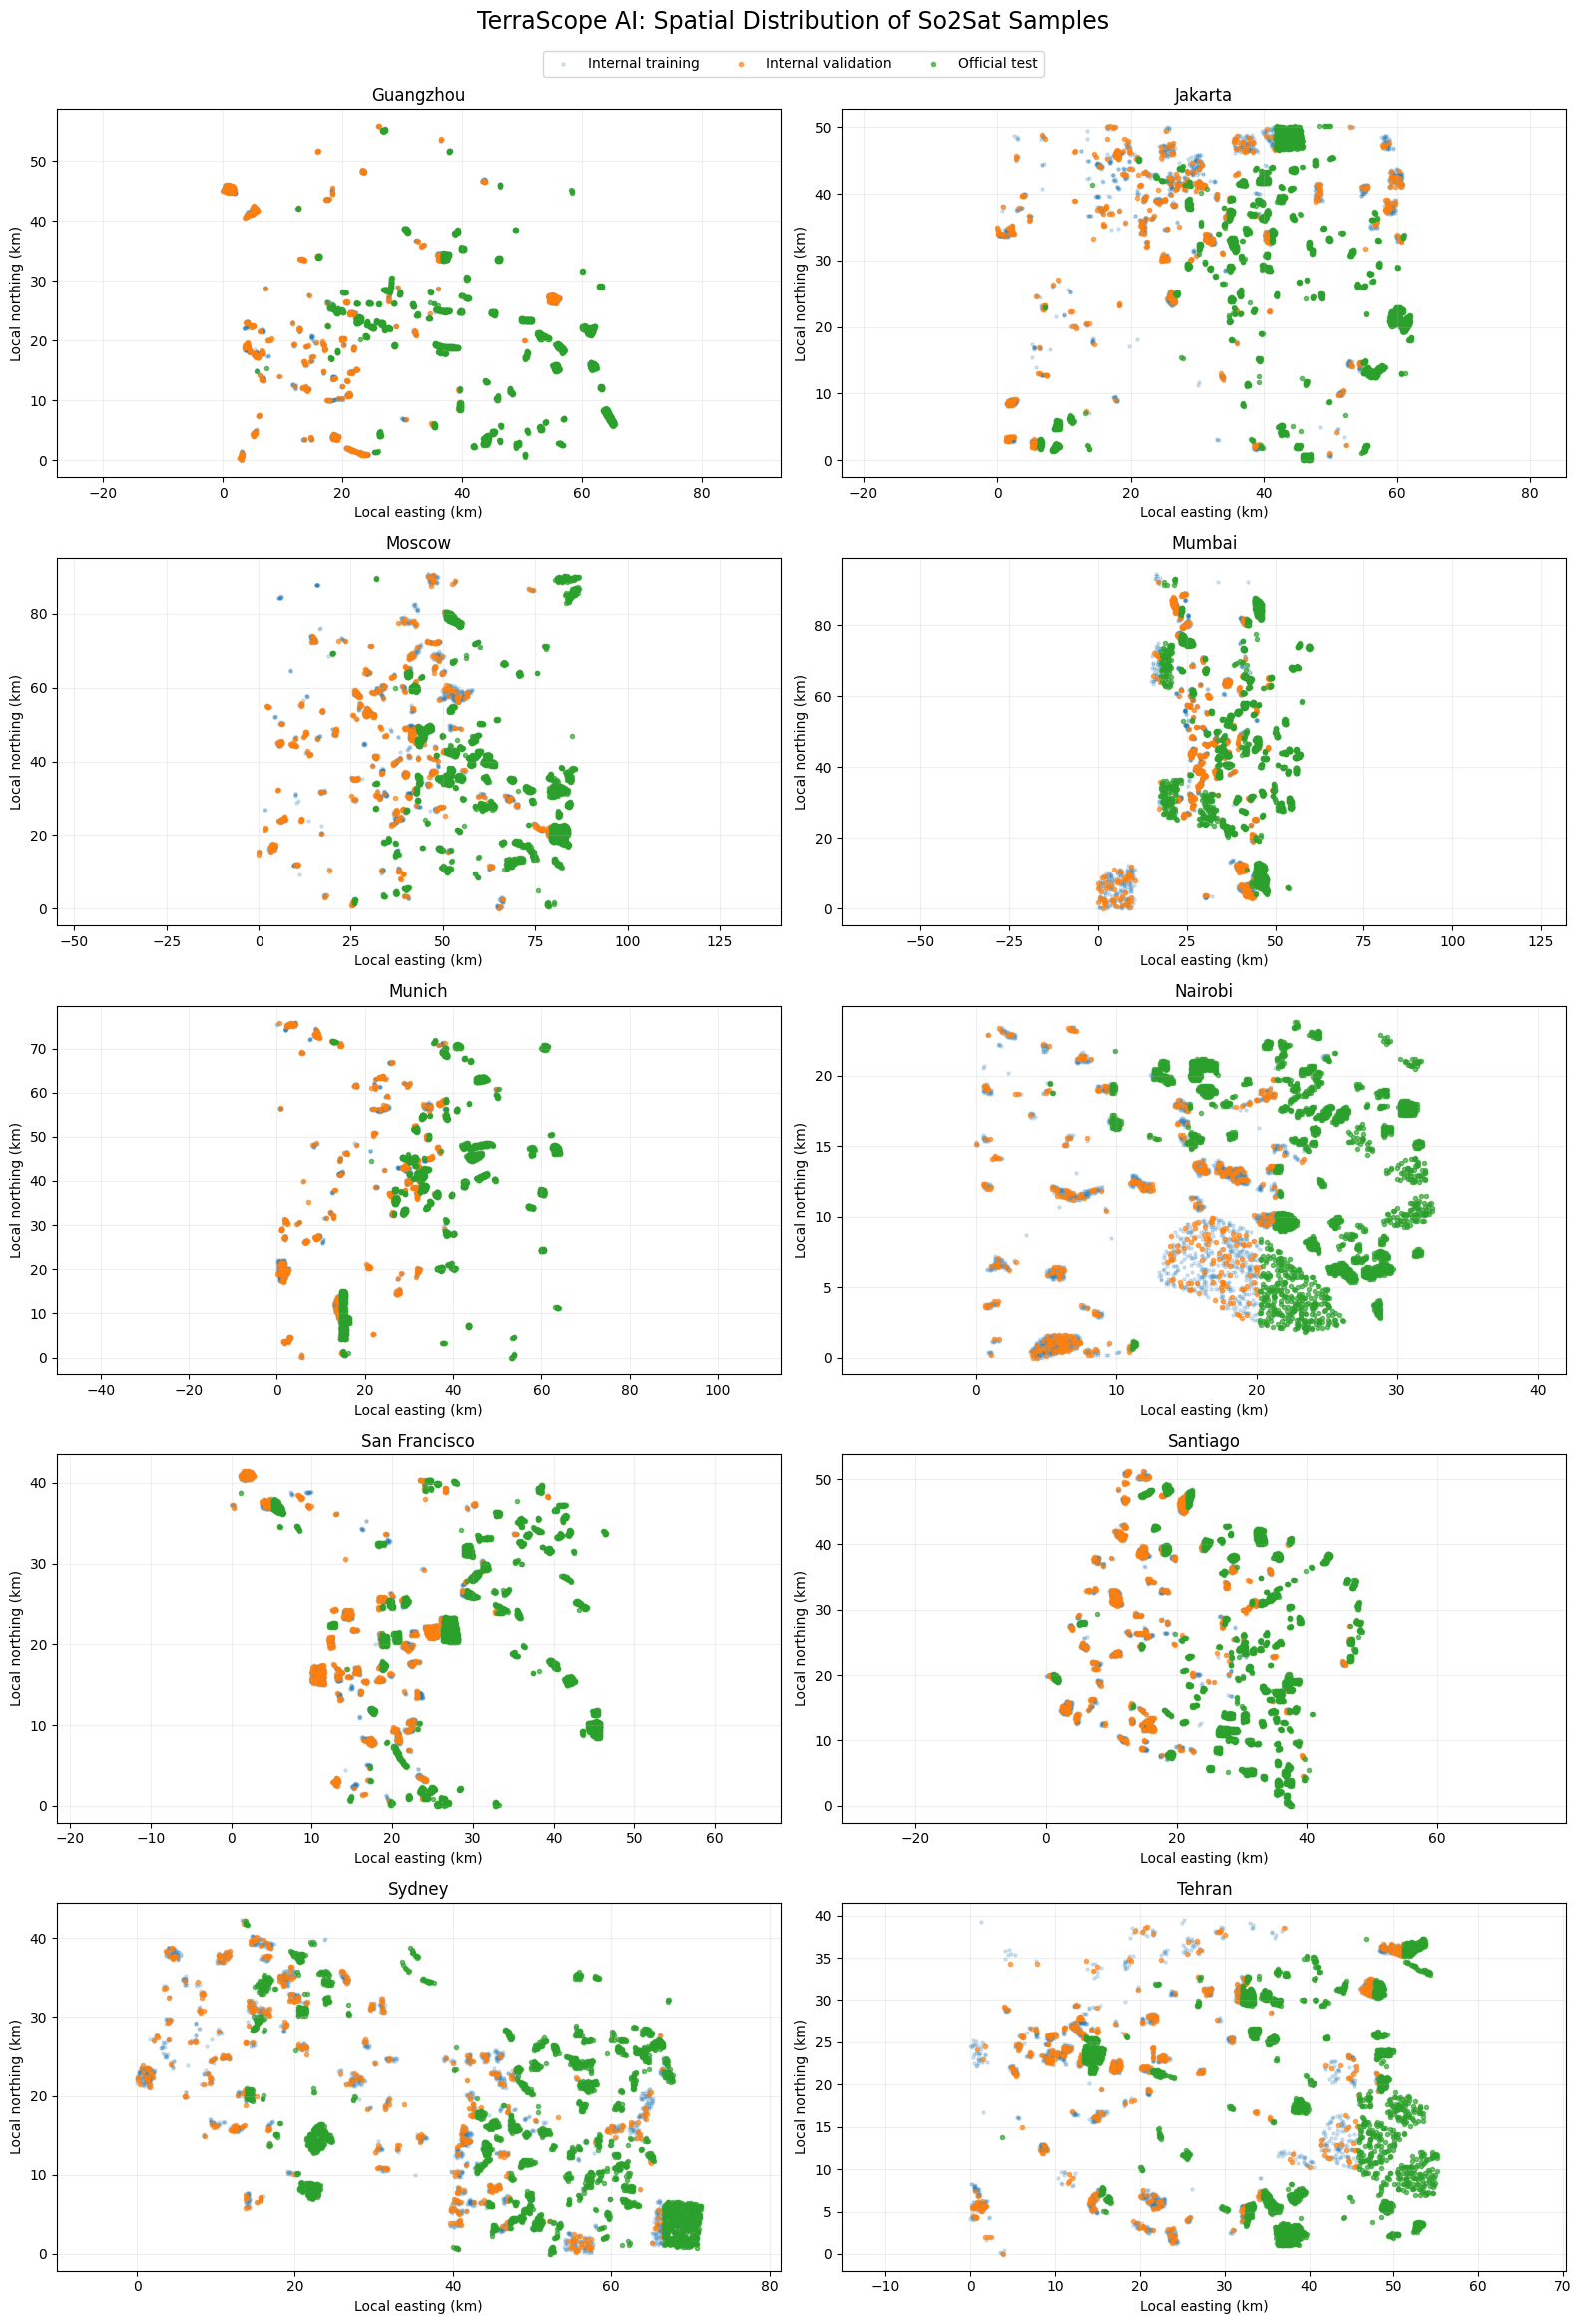


SAMPLE COUNTS
        City  Training samples  Validation samples  Test samples  Validation EPSG  Test EPSG
   guangzhou              1904                 509          2420            32649      32649
     jakarta              1931                 480          2420            32748      32748
      moscow              1919                 492          2420            32637      32637
      mumbai              1950                 463          2421            32643      32643
      munich              1952                 460          2420            32632      32632
     nairobi              1943                 468          2417            32737      32737
sanfrancisco              1922                 491          2417            32610      32610
    santiago              1911                 502          2418            32719      32719
      sydney              1941                 470          2419            32756      32756
      tehran              1922                 489     

In [26]:
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/TerraScope-AI")
OUTPUT = PROJECT / "results/so2sat/distribution_audit"
OUTPUT.mkdir(parents=True, exist_ok=True)

# Load split
split = np.load(PROJECT / "configs/so2sat_split.npz")
train_idx = split["train_idx"]
val_idx = split["val_idx"]

def load_geo(path):
    with h5py.File(path, "r") as f:
        cities = np.array([
            x.decode("utf-8").strip()
            if isinstance(x, bytes) else str(x).strip()
            for x in f["city"][:]
        ])

        tfw = f["tfw"][:]
        epsg = f["epsg"][:].reshape(-1)

    # World-file coordinates refer to the center of the
    # upper-left pixel. Shift to the center of each 32x32 patch.
    x = tfw[:, 4] + 15.5 * tfw[:, 0]
    y = tfw[:, 5] + 15.5 * tfw[:, 3]

    return cities, x, y, epsg

val_cities, val_x, val_y, val_epsg = load_geo(
    PROJECT / "data/raw/validation_geo.h5"
)

test_cities, test_x, test_y, test_epsg = load_geo(
    PROJECT / "data/raw/testing_geo.h5"
)

city_names = sorted(np.unique(val_cities))

fig, axes = plt.subplots(5, 2, figsize=(16, 23))
axes = axes.flatten()

summary = []

for ax, city in zip(axes, city_names):

    # Internal training samples
    train_mask = val_cities[train_idx] == city
    train_global = train_idx[train_mask]

    # Internal validation samples
    val_mask = val_cities[val_idx] == city
    val_global = val_idx[val_mask]

    # Official test samples
    test_mask = test_cities == city

    # Coordinates in kilometers, relative to a shared city origin
    all_x = np.concatenate([
        val_x[train_global],
        val_x[val_global],
        test_x[test_mask]
    ])

    all_y = np.concatenate([
        val_y[train_global],
        val_y[val_global],
        test_y[test_mask]
    ])

    origin_x = all_x.min()
    origin_y = all_y.min()

    def local_coords(x, y):
        return (x - origin_x) / 1000, (y - origin_y) / 1000

    tx, ty = local_coords(
        val_x[train_global], val_y[train_global]
    )

    vx, vy = local_coords(
        val_x[val_global], val_y[val_global]
    )

    qx, qy = local_coords(
        test_x[test_mask], test_y[test_mask]
    )

    ax.scatter(
        tx, ty, s=5, alpha=0.18,
        label="Internal training"
    )

    ax.scatter(
        vx, vy, s=9, alpha=0.65,
        label="Internal validation"
    )

    ax.scatter(
        qx, qy, s=9, alpha=0.65,
        label="Official test"
    )

    ax.set_title(city.replace("sanfrancisco", "San Francisco").title())
    ax.set_xlabel("Local easting (km)")
    ax.set_ylabel("Local northing (km)")
    ax.set_aspect("equal", adjustable="datalim")
    ax.grid(alpha=0.2)

    summary.append({
        "City": city,
        "Training samples": len(train_global),
        "Validation samples": len(val_global),
        "Test samples": int(test_mask.sum()),
        "Validation EPSG": np.unique(val_epsg[val_global])[0],
        "Test EPSG": np.unique(test_epsg[test_mask])[0]
    })

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc="upper center",
    ncol=3,
    bbox_to_anchor=(0.5, 0.995)
)

fig.suptitle(
    "TerraScope AI: Spatial Distribution of So2Sat Samples",
    fontsize=17,
    y=1.01
)

plt.tight_layout()
plt.savefig(
    OUTPUT / "spatial_distribution_by_city.png",
    dpi=220,
    bbox_inches="tight"
)
plt.show()

print("\nSAMPLE COUNTS")
print(pd.DataFrame(summary).to_string(index=False))

print("\nSaved figure:", OUTPUT / "spatial_distribution_by_city.png")

In [27]:
import h5py
import numpy as np
import pandas as pd

from pathlib import Path
from scipy.spatial import cKDTree

PROJECT = Path("/content/drive/MyDrive/TerraScope-AI")
OUTPUT = PROJECT / "results/so2sat/distribution_audit"
OUTPUT.mkdir(parents=True, exist_ok=True)

# Load the reproducible training/validation split
split = np.load(PROJECT / "configs/so2sat_split.npz")
train_idx = split["train_idx"]
val_idx = split["val_idx"]

def load_coordinates(path):
    with h5py.File(path, "r") as f:
        cities = np.array([
            x.decode("utf-8").strip()
            if isinstance(x, bytes) else str(x).strip()
            for x in f["city"][:]
        ])

        tfw = f["tfw"][:]

    # Convert world-file coordinates to patch centers.
    # Each patch is 32 x 32 pixels at 10 m per pixel.
    x = tfw[:, 4] + 15.5 * tfw[:, 0]
    y = tfw[:, 5] + 15.5 * tfw[:, 3]

    return cities, np.column_stack([x, y])

# Load both geographic datasets
val_cities, val_coords = load_coordinates(
    PROJECT / "data/raw/validation_geo.h5"
)

test_cities, test_coords = load_coordinates(
    PROJECT / "data/raw/testing_geo.h5"
)

thresholds = [100, 250, 500, 1000]

summary = []
sample_distances = []

for city in sorted(np.unique(val_cities)):

    # Training samples belonging to this city
    train_mask = val_cities[train_idx] == city
    city_train_idx = train_idx[train_mask]
    train_points = val_coords[city_train_idx]

    # Build nearest-neighbor search tree
    tree = cKDTree(train_points)

    # Internal validation samples
    val_mask = val_cities[val_idx] == city
    city_val_idx = val_idx[val_mask]
    val_points = val_coords[city_val_idx]

    val_distances, _ = tree.query(val_points, k=1)

    # Official test samples
    test_mask = test_cities == city
    city_test_idx = np.where(test_mask)[0]
    city_test_points = test_coords[test_mask]

    test_distances, _ = tree.query(city_test_points, k=1)

    for partition, distances in [
        ("Internal validation", val_distances),
        ("Official test", test_distances)
    ]:

        row = {
            "City": city,
            "Partition": partition,
            "Samples": len(distances),
            "Median distance (m)": np.median(distances),
            "Mean distance (m)": np.mean(distances),
            "75th percentile (m)": np.percentile(distances, 75),
            "90th percentile (m)": np.percentile(distances, 90)
        }

        for threshold in thresholds:
            row[f"Within {threshold}m (%)"] = (
                np.mean(distances <= threshold) * 100
            )

        summary.append(row)

        for distance in distances:
            sample_distances.append({
                "City": city,
                "Partition": partition,
                "Nearest training distance (m)": distance
            })

# Create result tables
summary_df = pd.DataFrame(summary)
distances_df = pd.DataFrame(sample_distances)

# Display median distances
median_table = summary_df.pivot(
    index="City",
    columns="Partition",
    values="Median distance (m)"
)

print("=" * 85)
print("MEDIAN DISTANCE TO NEAREST TRAINING SAMPLE")
print("=" * 85)
print(median_table.round(2))

print("\n" + "=" * 85)
print("DISTANCE DISTRIBUTION BY CITY")
print("=" * 85)

for city in sorted(summary_df["City"].unique()):
    print(f"\n{city.upper()}")

    subset = summary_df[summary_df["City"] == city]
    print(subset.round(2).to_string(index=False))

# Overall comparison
print("\n" + "=" * 85)
print("OVERALL SPATIAL DISTANCE COMPARISON")
print("=" * 85)

for partition in ["Internal validation", "Official test"]:
    distances = distances_df.loc[
        distances_df["Partition"] == partition,
        "Nearest training distance (m)"
    ].to_numpy()

    print(f"\n{partition}")
    print("Samples:", len(distances))
    print("Median:", round(np.median(distances), 2), "m")
    print("Mean:", round(np.mean(distances), 2), "m")
    print("90th percentile:", round(np.percentile(distances, 90), 2), "m")

    for threshold in thresholds:
        print(
            f"Within {threshold} m:",
            f"{np.mean(distances <= threshold) * 100:.2f}%"
        )

# Save results
summary_df.to_csv(
    OUTPUT / "nearest_training_distance_summary.csv",
    index=False
)

distances_df.to_csv(
    OUTPUT / "nearest_training_distances.csv",
    index=False
)

print("\nSaved results to:", OUTPUT)

MEDIAN DISTANCE TO NEAREST TRAINING SAMPLE
Partition     Internal validation  Official test
City                                            
guangzhou                  100.00        4205.35
jakarta                    100.00        2617.25
moscow                     141.42        3256.53
mumbai                     141.42        2213.59
munich                     100.00        2012.46
nairobi                    100.00        2780.29
sanfrancisco               100.00        1303.84
santiago                   100.00        2045.72
sydney                     100.00        2059.13
tehran                     100.00        2193.17

DISTANCE DISTRIBUTION BY CITY

GUANGZHOU
     City           Partition  Samples  Median distance (m)  Mean distance (m)  75th percentile (m)  90th percentile (m)  Within 100m (%)  Within 250m (%)  Within 500m (%)  Within 1000m (%)
guangzhou Internal validation      509               100.00              98.99               100.00               100.00            96.66

In [28]:
import h5py
import numpy as np
import pandas as pd

from pathlib import Path
from scipy.spatial import cKDTree

PROJECT = Path("/content/drive/MyDrive/TerraScope-AI")
OUTPUT = PROJECT / "results/so2sat/distribution_audit"
OUTPUT.mkdir(parents=True, exist_ok=True)

split = np.load(PROJECT / "configs/so2sat_split.npz")
train_idx = split["train_idx"]
val_idx = split["val_idx"]

PATCH_SIZE_M = 320.0

def load_geo(path):
    with h5py.File(path, "r") as f:
        cities = np.array([
            x.decode("utf-8").strip()
            if isinstance(x, bytes) else str(x).strip()
            for x in f["city"][:]
        ])
        tfw = f["tfw"][:]

    # Convert upper-left pixel-center coordinates
    # into patch-center coordinates.
    x = tfw[:, 4] + 15.5 * tfw[:, 0]
    y = tfw[:, 5] + 15.5 * tfw[:, 3]

    return cities, np.column_stack([x, y])

val_cities, val_coords = load_geo(
    PROJECT / "data/raw/validation_geo.h5"
)

test_cities, test_coords = load_geo(
    PROJECT / "data/raw/testing_geo.h5"
)

results = []

for city in sorted(np.unique(val_cities)):

    train_mask = val_cities[train_idx] == city
    train_points = val_coords[train_idx[train_mask]]

    tree = cKDTree(train_points)

    partitions = {
        "Internal validation": val_coords[
            val_idx[val_cities[val_idx] == city]
        ],
        "Official test": test_coords[test_cities == city]
    }

    for partition, query_points in partitions.items():

        # Any overlapping square must have center distance
        # no greater than 320 * sqrt(2).
        candidate_lists = tree.query_ball_point(
            query_points,
            r=PATCH_SIZE_M * np.sqrt(2)
        )

        overlap_counts = []

        for point, candidates in zip(query_points, candidate_lists):

            if not candidates:
                overlap_counts.append(0)
                continue

            nearby = train_points[candidates]

            dx = np.abs(nearby[:, 0] - point[0])
            dy = np.abs(nearby[:, 1] - point[1])

            # Positive-area rectangular intersection
            overlaps = (
                (dx < PATCH_SIZE_M) &
                (dy < PATCH_SIZE_M)
            )

            overlap_counts.append(int(overlaps.sum()))

        overlap_counts = np.array(overlap_counts)

        results.append({
            "City": city,
            "Partition": partition,
            "Samples": len(query_points),
            "Samples with overlap": int(
                np.sum(overlap_counts > 0)
            ),
            "Overlap percentage": (
                np.mean(overlap_counts > 0) * 100
            ),
            "Mean overlapping training patches": (
                np.mean(overlap_counts)
            ),
            "Maximum overlapping training patches": (
                np.max(overlap_counts)
            )
        })

results_df = pd.DataFrame(results)

print("=" * 85)
print("IMAGE-FOOTPRINT OVERLAP WITH TRAINING SAMPLES")
print("=" * 85)

print(results_df.round(3).to_string(index=False))

print("\n" + "=" * 85)
print("OVERALL RESULTS")
print("=" * 85)

overall = results_df.groupby("Partition").agg({
    "Samples": "sum",
    "Samples with overlap": "sum"
})

overall["Overlap percentage"] = (
    overall["Samples with overlap"] /
    overall["Samples"] * 100
)

print(overall.round(3))

results_df.to_csv(
    OUTPUT / "training_footprint_overlap_by_city.csv",
    index=False
)

overall.to_csv(
    OUTPUT / "training_footprint_overlap_overall.csv"
)

print("\nSaved to:", OUTPUT)

IMAGE-FOOTPRINT OVERLAP WITH TRAINING SAMPLES
        City           Partition  Samples  Samples with overlap  Overlap percentage  Mean overlapping training patches  Maximum overlapping training patches
   guangzhou Internal validation      509                   509             100.000                             19.000                                    42
   guangzhou       Official test     2420                   244              10.083                              0.533                                    19
     jakarta Internal validation      480                   465              96.875                              7.319                                    22
     jakarta       Official test     2420                   148               6.116                              0.185                                    12
      moscow Internal validation      492                   462              93.902                              4.224                                    12
      moscow

In [31]:
from pathlib import Path
import subprocess

REPO = Path("/content/TerraScope-AI")

print("Repository exists:", REPO.exists())

if REPO.exists():
    print("\nGit status:")
    subprocess.run(
        ["git", "status", "--short", "--branch"],
        cwd=REPO
    )

    print("\nCurrent commit:")
    subprocess.run(
        ["git", "log", "-1", "--oneline"],
        cwd=REPO
    )

    print("\nTop-level contents:")
    for item in sorted(REPO.iterdir()):
        print(item.name)

Repository exists: True

Git status:

Current commit:

Top-level contents:
.git
.gitignore
README.md
configs
data
notebooks
requirements.txt
results
src


In [32]:
import subprocess
from pathlib import Path

REPO = Path("/content/TerraScope-AI")

commands = {
    "Git version": ["git", "--version"],
    "Repository root": ["git", "rev-parse", "--show-toplevel"],
    "Current branch": ["git", "branch", "--show-current"],
    "Git status": ["git", "status", "--short", "--branch"],
    "Latest commit": ["git", "log", "-1", "--oneline"],
    "Remote": ["git", "remote", "-v"],
}

for name, command in commands.items():
    print(f"\n{'='*20} {name} {'='*20}")
    result = subprocess.run(
        command,
        cwd=REPO,
        capture_output=True,
        text=True
    )
    print(result.stdout or result.stderr or "(No output)")
    print("Return code:", result.returncode)

print("\nExisting results files:")
for path in sorted((REPO / "results").rglob("*")):
    if path.is_file():
        print(path.relative_to(REPO))


==================== Git version ====================
git version 2.43.0

Return code: 0

==================== Repository root ====================
/content/TerraScope-AI

Return code: 0

==================== Current branch ====================
main

Return code: 0

==================== Git status ====================
## main...origin/main

Return code: 0

==================== Latest commit ====================
4822e21 Reframe research around transfer learning

Return code: 0

==================== Remote ====================
origin	https://github.com/Vansh-Singhal-12/TerraScope-AI.git (fetch)
origin	https://github.com/Vansh-Singhal-12/TerraScope-AI.git (push)

Return code: 0

Existing results files:
results/README.md
results/eurosat_training_history.json
results/so2sat/M1/classification_report.csv
results/so2sat/M1/confusion_matrix.csv
results/so2sat/M1/training_history.json
results/so2sat/M1/validation_metrics.json
results/so2sat/M2/classification_report.csv
results/so2sat/M2/confusi

In [33]:
from pathlib import Path

DRIVE = Path("/content/drive/MyDrive/TerraScope-AI")
REPO = Path("/content/TerraScope-AI")

folders = {
    "Drive: So2Sat results": DRIVE / "results/so2sat",
    "Repository: So2Sat results": REPO / "results/so2sat",
    "Drive: configuration": DRIVE / "configs",
    "Repository: configuration": REPO / "configs",
}

for title, folder in folders.items():
    print(f"\n{'='*75}")
    print(title)
    print(f"{'='*75}")

    if not folder.exists():
        print("Folder does not exist.")
        continue

    for file in sorted(folder.rglob("*")):
        if file.is_file():
            size_mb = file.stat().st_size / (1024 * 1024)
            print(f"{file.relative_to(folder)}  ({size_mb:.2f} MB)")


Drive: So2Sat results
M1/best_checkpoint.pth  (42.75 MB)
M1/classification_report.csv  (0.00 MB)
M1/confusion_matrix.csv  (0.00 MB)
M1/test_classification_report.csv  (0.00 MB)
M1/test_confusion_matrix.csv  (0.00 MB)
M1/test_metrics.json  (0.00 MB)
M1/test_predictions.npz  (0.04 MB)
M1/training_history.json  (0.00 MB)
M1/validation_metrics.json  (0.00 MB)
M2/best_checkpoint.pth  (42.75 MB)
M2/classification_report.csv  (0.00 MB)
M2/confusion_matrix.csv  (0.00 MB)
M2/test_classification_report.csv  (0.00 MB)
M2/test_confusion_matrix.csv  (0.00 MB)
M2/test_metrics.json  (0.00 MB)
M2/test_predictions.npz  (0.04 MB)
M2/training_history.json  (0.00 MB)
M2/validation_metrics.json  (0.00 MB)
M3/best_checkpoint.pth  (42.75 MB)
M3/classification_report.csv  (0.00 MB)
M3/confusion_matrix.csv  (0.00 MB)
M3/test_classification_report.csv  (0.00 MB)
M3/test_confusion_matrix.csv  (0.00 MB)
M3/test_metrics.json  (0.00 MB)
M3/test_predictions.npz  (0.04 MB)
M3/training_history.json  (0.00 MB)
M3/vali

In [34]:
from pathlib import Path
import shutil

DRIVE = Path("/content/drive/MyDrive/TerraScope-AI")
REPO = Path("/content/TerraScope-AI")

drive_results = DRIVE / "results/so2sat"
repo_results = REPO / "results/so2sat"

# 1. Copy official test evaluation artifacts
for model in ["M1", "M2", "M3", "M4", "M5"]:
    source = drive_results / model
    destination = repo_results / model
    destination.mkdir(parents=True, exist_ok=True)

    for filename in [
        "test_metrics.json",
        "test_classification_report.csv",
        "test_confusion_matrix.csv",
        "test_predictions.npz"
    ]:
        src = source / filename

        if src.exists():
            shutil.copy2(src, destination / filename)
            print("Copied:", f"{model}/{filename}")
        else:
            print("MISSING:", f"{model}/{filename}")

# 2. Copy combined model comparison
shutil.copy2(
    drive_results / "official_test_comparison.csv",
    repo_results / "official_test_comparison.csv"
)

# 3. Copy spatial/generalization audit artifacts
audit_source = drive_results / "distribution_audit"
audit_destination = repo_results / "distribution_audit"
audit_destination.mkdir(parents=True, exist_ok=True)

for filename in [
    "city_distribution.csv",
    "class_by_city_difference.csv",
    "class_distribution.csv",
    "nearest_training_distance_summary.csv",
    "nearest_training_distances.csv",
    "per_city_test_metrics.csv",
    "per_city_test_metrics_corrected.csv",
    "spatial_distribution_by_city.png",
    "training_footprint_overlap_by_city.csv",
    "training_footprint_overlap_overall.csv",
    "validation_vs_test_per_city.csv"
]:
    src = audit_source / filename

    if src.exists():
        shutil.copy2(src, audit_destination / filename)
        print("Copied:", f"distribution_audit/{filename}")
    else:
        print("MISSING:", f"distribution_audit/{filename}")

print("\nCopy operation complete.")

Copied: M1/test_metrics.json
Copied: M1/test_classification_report.csv
Copied: M1/test_confusion_matrix.csv
Copied: M1/test_predictions.npz
Copied: M2/test_metrics.json
Copied: M2/test_classification_report.csv
Copied: M2/test_confusion_matrix.csv
Copied: M2/test_predictions.npz
Copied: M3/test_metrics.json
Copied: M3/test_classification_report.csv
Copied: M3/test_confusion_matrix.csv
Copied: M3/test_predictions.npz
Copied: M4/test_metrics.json
Copied: M4/test_classification_report.csv
Copied: M4/test_confusion_matrix.csv
Copied: M4/test_predictions.npz
Copied: M5/test_metrics.json
Copied: M5/test_classification_report.csv
Copied: M5/test_confusion_matrix.csv
Copied: M5/test_predictions.npz
Copied: distribution_audit/city_distribution.csv
Copied: distribution_audit/class_by_city_difference.csv
Copied: distribution_audit/class_distribution.csv
Copied: distribution_audit/nearest_training_distance_summary.csv
Copied: distribution_audit/nearest_training_distances.csv
Copied: distribution_a

In [35]:
for path in sorted(repo_results.rglob("*")):
    if path.is_file():
        print(path.relative_to(REPO))

results/so2sat/M1/classification_report.csv
results/so2sat/M1/confusion_matrix.csv
results/so2sat/M1/test_classification_report.csv
results/so2sat/M1/test_confusion_matrix.csv
results/so2sat/M1/test_metrics.json
results/so2sat/M1/test_predictions.npz
results/so2sat/M1/training_history.json
results/so2sat/M1/validation_metrics.json
results/so2sat/M2/classification_report.csv
results/so2sat/M2/confusion_matrix.csv
results/so2sat/M2/test_classification_report.csv
results/so2sat/M2/test_confusion_matrix.csv
results/so2sat/M2/test_metrics.json
results/so2sat/M2/test_predictions.npz
results/so2sat/M2/training_history.json
results/so2sat/M2/validation_metrics.json
results/so2sat/M3/classification_report.csv
results/so2sat/M3/confusion_matrix.csv
results/so2sat/M3/test_classification_report.csv
results/so2sat/M3/test_confusion_matrix.csv
results/so2sat/M3/test_metrics.json
results/so2sat/M3/test_predictions.npz
results/so2sat/M3/training_history.json
results/so2sat/M3/validation_metrics.json
r

In [36]:
from pathlib import Path

REPO = Path("/content/TerraScope-AI")

files = [
    "README.md",
    "configs/experiment.json",
    "configs/preprocessing.json",
    "results/README.md",
    ".gitignore",
]

for filename in files:
    path = REPO / filename
    print("\n" + "=" * 80)
    print(filename)
    print("=" * 80)

    if path.exists():
        print(path.read_text())
    else:
        print("(File does not exist)")


README.md
# TerraScope AI
### Satellite Image Classification Through Transfer Learning

## Overview

TerraScope AI is a deep-learning project that classifies satellite imagery into 17 Local Climate Zone (LCZ) categories using Sentinel-2 data.

Beyond developing an accurate image classifier, this project investigates how transfer learning affects satellite-image classification. In particular, we examine whether pretrained visual representations improve classification, whether additional satellite-specific pretraining provides benefits, and how fine-tuning influences transfer performance.

We compare models initialized randomly, pretrained on ImageNet, and pretrained sequentially on ImageNet and EuroSAT before adapting them to So2Sat.

## Research Question

**To what extent does transfer learning improve satellite-image classification, and how does the choice of pretraining pathway influence its effectiveness across geographically distinct datasets?**

### Research Objectives

1. Evalua

In [37]:
import json
from pathlib import Path

REPO = Path("/content/TerraScope-AI")
CONFIG = REPO / "configs/experiment.json"
DOCS = REPO / "docs"

DOCS.mkdir(exist_ok=True)

# --------------------------------------------------
# 1. Update experiment configuration
# --------------------------------------------------

with open(CONFIG, "r") as f:
    config = json.load(f)

config["research_question"] = (
    "To what extent does transfer learning improve satellite-image "
    "classification, and how does the choice of pretraining pathway "
    "influence its effectiveness across geographically distinct datasets?"
)

config["experiments"] = {
    "M1": "Random initialization, full fine-tuning",
    "M2": "ImageNet initialization, frozen backbone",
    "M3": "EuroSAT-pretrained initialization, frozen backbone",
    "M4": "EuroSAT-pretrained initialization, full fine-tuning",
    "M5": "ImageNet initialization, full fine-tuning"
}

config["pretraining_provenance"] = {
    "M3": "EuroSAT checkpoint; original initialization is provisionally believed to be ImageNet but requires verification from the training invocation or logs.",
    "M4": "EuroSAT checkpoint; original initialization is provisionally believed to be ImageNet but requires verification from the training invocation or logs."
}

config["evaluation"] = {
    "official_test_samples": 24188,
    "official_test_source": "So2Sat official testing partition",
    "test_used_for_model_selection": False,
    "metrics": [
        "accuracy",
        "macro_f1",
        "weighted_f1",
        "per_class_precision",
        "per_class_recall",
        "confusion_matrix"
    ]
}

config["spatial_generalization_audit"] = {
    "internal_validation_samples": 4824,
    "official_test_samples": 24188,
    "median_nearest_training_distance_m": {
        "internal_validation": 100.0,
        "official_test": 2342.01
    },
    "training_footprint_overlap_percent": {
        "internal_validation": 97.699,
        "official_test": 8.277
    },
    "patch_dimensions_pixels": [32, 32],
    "pixel_resolution_m": 10,
    "patch_footprint_m": [320, 320],
    "interpretation": "Internal validation samples are substantially more spatially associated with training samples than official test samples. Spatial dependence may contribute to the validation-to-test performance gap; this analysis does not establish causation."
}

with open(CONFIG, "w") as f:
    json.dump(config, f, indent=2)
    f.write("\n")

print("Updated:", CONFIG)

# --------------------------------------------------
# 2. Create generalization analysis report
# --------------------------------------------------

generalization_report = r"""
# Geographic Generalization and Spatial Dependence

## Purpose

The internal validation results were substantially higher than the official
So2Sat test results for the fully fine-tuned models. This investigation
examined whether differences in geographic proximity between training,
internal validation, and official test samples could help explain the gap.

The analysis considered class distributions, city distributions, per-city
performance, nearest-training-sample distances, and image-footprint overlap.

## Dataset partitions

The official So2Sat validation partition contains 24,119 samples. It was
divided into:

- Internal training: 19,295 samples
- Internal validation: 4,824 samples

The official testing partition contains 24,188 samples.

Both official partitions cover the same ten named cities, but their
geographic samples are distributed across separated areas. The experiment
therefore evaluates geographic separation within represented cities, not
generalization to entirely unseen cities.

## Validation-to-test performance gap

| Model | Validation accuracy | Test accuracy | Change |
|---|---:|---:|---:|
| M1 | 68.99% | 60.76% | -8.23 pp |
| M2 | 59.02% | 57.69% | -1.33 pp |
| M3 | 51.14% | 50.01% | -1.13 pp |
| M4 | 92.04% | 77.14% | -14.90 pp |
| M5 | 92.23% | 76.81% | -15.42 pp |

The fully fine-tuned models show the largest validation-to-test accuracy
decline. M4 and M5 also experience substantial declines in macro-F1.

## Class and city distributions

The internal validation and official test class distributions were
compared using a chi-square test.

- Chi-square statistic: 14.396
- Degrees of freedom: 16
- p-value: 0.569

The test did not detect a statistically significant difference in the
overall class distributions.

City proportions were also similar, with each city accounting for
approximately one tenth of each partition.

These comparisons suggest that the performance gap is not readily explained
by a major difference in the overall class or city proportions. They do not
rule out differences in local class composition or image characteristics.

## Per-city performance

M4 and M5 had lower test accuracy than internal-validation accuracy in
all ten cities.

For M4, the per-city accuracy decline ranged from approximately 5.08
percentage points in Moscow to 29.01 points in Nairobi.

For M5, it ranged from approximately 5.81 points in Moscow to 27.59
points in Nairobi.

The decline across all cities is consistent with a broader geographic
generalization challenge rather than a problem isolated to one city.

## Distance to nearest training sample

For each internal-validation and official-test patch, the distance to its
nearest training-patch center was calculated within the same city using
projected coordinates.

| Metric | Internal validation | Official test |
|---|---:|---:|
| Median distance | 100.00 m | 2,342.01 m |
| Mean distance | 146.32 m | 3,585.98 m |
| 90th percentile | 223.61 m | 8,224.17 m |
| Within 250 m | 93.39% | 4.94% |
| Within 500 m | 98.61% | 11.54% |
| Within 1 km | 99.48% | 24.03% |

The internal-validation samples were substantially closer to training
samples than official-test samples.

## Image-footprint overlap

Each input patch contains 32 × 32 pixels at 10 m per pixel, corresponding
to an approximately 320 m × 320 m ground footprint.

For each validation or test patch, the analysis checked whether its
axis-aligned rectangular footprint had positive-area intersection with
at least one training-patch footprint in the same projected coordinate
system.

| Partition | Samples | Samples overlapping training | Percentage |
|---|---:|---:|---:|
| Internal validation | 4,824 | 4,713 | 97.70% |
| Official test | 24,188 | 2,002 | 8.28% |

The difference is substantial. Nearly all internal-validation patches
intersected at least one training-patch footprint, whereas this occurred
for a much smaller fraction of official-test patches.

This establishes geographic footprint intersection, not necessarily
identical pixel values or identical predictions. The analysis does not
measure the causal contribution of overlap to model performance.

## Interpretation

The combined findings indicate that the random internal validation split
provided an evaluation setting with substantial spatial dependence between
training and validation imagery.

The official test samples were generally much farther from training
samples and had substantially less footprint overlap. This provides a
plausible explanation for why internal-validation performance was
optimistic relative to official-test performance.

The results support the importance of spatially informed evaluation for
satellite-image classification. Random sample-level splits may not
adequately estimate performance on geographically separated imagery
when nearby patches share spatial context.

The analysis does not prove that spatial dependence is the sole cause of
the performance gap. Differences in local scene composition, image
characteristics, and other forms of distribution shift may also contribute.

## Limitations

- The ten cities are represented in both partitions; this is not an
  unseen-city evaluation.
- The internal validation split uses one random seed and one partition.
- Footprint intersection does not establish identical input pixels.
- The nearest-neighbor calculation uses patch-center distances.
- The overlap calculation assumes axis-aligned 320 m square footprints.
- The investigation is observational and does not isolate the causal
  effect of spatial overlap.
- The study does not include repeated spatial-block cross-validation.

## Reproducibility

The numerical outputs are stored in:

`results/so2sat/distribution_audit/`

Important artifacts include:

- `class_distribution.csv`
- `city_distribution.csv`
- `class_by_city_difference.csv`
- `validation_vs_test_per_city.csv`
- `nearest_training_distance_summary.csv`
- `nearest_training_distances.csv`
- `training_footprint_overlap_by_city.csv`
- `training_footprint_overlap_overall.csv`
- `spatial_distribution_by_city.png`

The official test metrics and predictions are stored in the individual
model result directories under `results/so2sat/`.
"""

report_path = DOCS / "generalization_analysis.md"
report_path.write_text(generalization_report.strip() + "\n", encoding="utf-8")

print("Created:", report_path)
print("\nConfiguration and report created successfully.")

Updated: /content/TerraScope-AI/configs/experiment.json
Created: /content/TerraScope-AI/docs/generalization_analysis.md

Configuration and report created successfully.


In [38]:
import json

with open(REPO / "configs/experiment.json") as f:
    updated_config = json.load(f)

print("Models:", list(updated_config["experiments"].keys()))
print("Test samples:", updated_config["evaluation"]["official_test_samples"])
print("Spatial overlap:", updated_config["spatial_generalization_audit"]["training_footprint_overlap_percent"])

print("\nGeneralization report exists:",
      (REPO / "docs/generalization_analysis.md").exists())

Models: ['M1', 'M2', 'M3', 'M4', 'M5']
Test samples: 24188
Spatial overlap: {'internal_validation': 97.699, 'official_test': 8.277}

Generalization report exists: True


In [39]:
from pathlib import Path
import subprocess

REPO = Path("/content/TerraScope-AI")

for filename in [
    "configs/experiment.json",
    "docs/generalization_analysis.md"
]:
    path = REPO / filename

    print("\n" + "=" * 80)
    print(filename)
    print("=" * 80)

    print(path.read_text())

print("\n" + "=" * 80)
print("GIT DIFF")
print("=" * 80)

subprocess.run(
    ["git", "diff", "--", "configs/experiment.json",
     "docs/generalization_analysis.md"],
    cwd=REPO
)

print("\n" + "=" * 80)
print("GIT STATUS")
print("=" * 80)

subprocess.run(
    ["git", "status", "--short"],
    cwd=REPO
)


configs/experiment.json
{
  "project": "TerraScope AI",
  "research_question": "To what extent does transfer learning improve satellite-image classification, and how does the choice of pretraining pathway influence its effectiveness across geographically distinct datasets?",
  "source_dataset": "EuroSAT",
  "target_dataset": "So2Sat LCZ42",
  "source_classes": 10,
  "target_classes": 17,
  "architecture": "ResNet-18",
  "input_size": [
    32,
    32
  ],
  "seed": 42,
  "batch_size": 64,
  "eurosat_split": {
    "method": "stratified random split",
    "train_fraction": 0.8,
    "validation_fraction": 0.2,
    "random_state": 42
  },
  "so2sat_split": {
    "source_file": "configs/so2sat_split.npz",
    "training_source": "official validation partition",
    "internal_validation_fraction": 0.2,
    "random_state": 42,
    "held_out_evaluation_source": "official testing partition",
    "limitation": "Official validation and testing partitions cover the same ten named cities in geograp

CompletedProcess(args=['git', 'status', '--short'], returncode=0)

In [40]:
from pathlib import Path
import json

REPO = Path("/content/TerraScope-AI")
config_path = REPO / "configs/experiment.json"

config = json.loads(config_path.read_text())

# Correctly distinguish pretraining datasets from the target dataset.
config.pop("source_dataset", None)

config["pretraining_datasets"] = [
    "ImageNet",
    "EuroSAT"
]

config["target_dataset"] = "So2Sat LCZ42"

# Preserve the provisional checkpoint provenance.
config["pretraining_provenance"] = {
    "M3": (
        "EuroSAT checkpoint; original initialization is provisionally "
        "believed to be ImageNet but requires verification from the "
        "training invocation or logs."
    ),
    "M4": (
        "EuroSAT checkpoint; original initialization is provisionally "
        "believed to be ImageNet but requires verification from the "
        "training invocation or logs."
    )
}

config_path.write_text(json.dumps(config, indent=2) + "\n")

print("Updated:", config_path)
print(json.dumps(config, indent=2))

Updated: /content/TerraScope-AI/configs/experiment.json
{
  "project": "TerraScope AI",
  "research_question": "To what extent does transfer learning improve satellite-image classification, and how does the choice of pretraining pathway influence its effectiveness across geographically distinct datasets?",
  "target_dataset": "So2Sat LCZ42",
  "source_classes": 10,
  "target_classes": 17,
  "architecture": "ResNet-18",
  "input_size": [
    32,
    32
  ],
  "seed": 42,
  "batch_size": 64,
  "eurosat_split": {
    "method": "stratified random split",
    "train_fraction": 0.8,
    "validation_fraction": 0.2,
    "random_state": 42
  },
  "so2sat_split": {
    "source_file": "configs/so2sat_split.npz",
    "training_source": "official validation partition",
    "internal_validation_fraction": 0.2,
    "random_state": 42,
    "held_out_evaluation_source": "official testing partition",
    "limitation": "Official validation and testing partitions cover the same ten named cities in geograp

In [41]:
from pathlib import Path

REPO = Path("/content/TerraScope-AI")
report_path = REPO / "docs/generalization_analysis.md"

report = report_path.read_text()

anchor = """The fully fine-tuned models show the largest validation-to-test accuracy
decline. M4 and M5 also experience substantial declines in macro-F1.
"""

addition = """
### Official test performance

| Model | Test accuracy | Test macro-F1 | Test weighted-F1 |
|---|---:|---:|---:|
| M4 | 77.14% | 69.81% | 76.58% |
| M5 | 76.81% | 69.95% | 76.37% |

Although M4 and M5 achieved validation accuracies above 92%, their official
test accuracies were approximately 77%. Their test macro-F1 scores were
also substantially lower than their validation macro-F1 scores, indicating
that the decline was not limited to the most frequently represented
classes.
"""

if "### Official test performance" not in report:
    if anchor not in report:
        raise ValueError("Could not find the expected insertion point.")
    report = report.replace(anchor, anchor + addition)
    report_path.write_text(report)
    print("Added official test performance section.")
else:
    print("Official test performance section already exists. No duplicate added.")

print("\nUpdated report section:")
start = report.index("## Validation-to-test performance gap")
end = report.index("## Class and city distributions")
print(report[start:end])

Added official test performance section.

Updated report section:
## Validation-to-test performance gap

| Model | Validation accuracy | Test accuracy | Change |
|---|---:|---:|---:|
| M1 | 68.99% | 60.76% | -8.23 pp |
| M2 | 59.02% | 57.69% | -1.33 pp |
| M3 | 51.14% | 50.01% | -1.13 pp |
| M4 | 92.04% | 77.14% | -14.90 pp |
| M5 | 92.23% | 76.81% | -15.42 pp |

The fully fine-tuned models show the largest validation-to-test accuracy
decline. M4 and M5 also experience substantial declines in macro-F1.

### Official test performance

| Model | Test accuracy | Test macro-F1 | Test weighted-F1 |
|---|---:|---:|---:|
| M4 | 77.14% | 69.81% | 76.58% |
| M5 | 76.81% | 69.95% | 76.37% |

Although M4 and M5 achieved validation accuracies above 92%, their official
test accuracies were approximately 77%. Their test macro-F1 scores were
also substantially lower than their validation macro-F1 scores, indicating
that the decline was not limited to the most frequently represented
classes.




In [42]:
import json
from pathlib import Path

REPO = Path("/content/TerraScope-AI")

config = json.loads(
    (REPO / "configs/experiment.json").read_text()
)

report = (
    REPO / "docs/generalization_analysis.md"
).read_text()

# Configuration checks
assert config["pretraining_datasets"] == ["ImageNet", "EuroSAT"]
assert config["target_dataset"] == "So2Sat LCZ42"
assert set(config["experiments"].keys()) == {"M1", "M2", "M3", "M4", "M5"}
assert "provisionally" in config["pretraining_provenance"]["M4"]

# Report checks
assert "### Official test performance" in report
assert "69.81%" in report
assert "69.95%" in report
assert "8.28%" in report
assert "97.70%" in report

print("All checks passed.")
print("\nExperiment configuration:")
print("Pretraining datasets:", config["pretraining_datasets"])
print("Target dataset:", config["target_dataset"])
print("Models:", list(config["experiments"].keys()))

print("\nGeneralization report:")
print("Official test results included.")
print("Spatial overlap results included.")

All checks passed.

Experiment configuration:
Pretraining datasets: ['ImageNet', 'EuroSAT']
Target dataset: So2Sat LCZ42
Models: ['M1', 'M2', 'M3', 'M4', 'M5']

Generalization report:
Official test results included.
Spatial overlap results included.


In [43]:
import subprocess

REPO = "/content/TerraScope-AI"

commands = [
    ["git", "status", "--short", "--untracked-files=all"],
    ["git", "diff", "--check"],
    ["git", "diff", "--stat"],
]

for command in commands:
    result = subprocess.run(
        command,
        cwd=REPO,
        capture_output=True,
        text=True
    )

    print("\n$", " ".join(command))
    print("Exit code:", result.returncode)
    print(result.stdout or "(no output)")

    if result.stderr:
        print("STDERR:", result.stderr)


$ git status --short --untracked-files=all
Exit code: 0
 M configs/experiment.json
?? docs/generalization_analysis.md
?? results/so2sat/M1/test_classification_report.csv
?? results/so2sat/M1/test_confusion_matrix.csv
?? results/so2sat/M1/test_metrics.json
?? results/so2sat/M1/test_predictions.npz
?? results/so2sat/M2/test_classification_report.csv
?? results/so2sat/M2/test_confusion_matrix.csv
?? results/so2sat/M2/test_metrics.json
?? results/so2sat/M2/test_predictions.npz
?? results/so2sat/M3/test_classification_report.csv
?? results/so2sat/M3/test_confusion_matrix.csv
?? results/so2sat/M3/test_metrics.json
?? results/so2sat/M3/test_predictions.npz
?? results/so2sat/M4/test_classification_report.csv
?? results/so2sat/M4/test_confusion_matrix.csv
?? results/so2sat/M4/test_metrics.json
?? results/so2sat/M4/test_predictions.npz
?? results/so2sat/M5/test_classification_report.csv
?? results/so2sat/M5/test_confusion_matrix.csv
?? results/so2sat/M5/test_metrics.json
?? results/so2sat/M5/te

In [44]:
from pathlib import Path

REPO = Path("/content/TerraScope-AI")
readme_path = REPO / "README.md"

readme = readme_path.read_text()

# Remove outdated lines that say official test evaluation is still pending.
lines = readme.splitlines()
filtered_lines = []

for line in lines:
    lower = line.lower()
    if (
        "official test" in lower
        and any(word in lower for word in ["pending", "will determine", "not yet"])
    ):
        continue
    filtered_lines.append(line)

readme = "\n".join(filtered_lines).rstrip() + "\n"

section = r"""

## Official Test Evaluation

All five experimental configurations were evaluated on the 24,188-sample
official So2Sat testing partition. This partition was not used for model
selection.

| Model | Initialization | Test accuracy | Test macro-F1 | Test weighted-F1 |
|---|---|---:|---:|---:|
| M1 | Random, full fine-tuning | 60.76% | 49.22% | 60.24% |
| M2 | ImageNet, frozen backbone | 57.69% | 42.76% | 55.57% |
| M3 | EuroSAT, frozen backbone | 50.01% | 32.36% | 45.57% |
| M4 | EuroSAT, full fine-tuning | 77.14% | 69.81% | 76.58% |
| M5 | ImageNet, full fine-tuning | 76.81% | 69.95% | 76.37% |

M4 and M5 achieved very similar test performance. M4 had slightly higher
accuracy and weighted-F1, while M5 had slightly higher macro-F1. These
differences are small and do not establish a definitive advantage for
either pretraining pathway.

Fine-tuning substantially improved performance relative to the
corresponding frozen-backbone configurations. M4 outperformed M3 by
27.13 percentage points in test accuracy, while M5 outperformed M2 by
19.12 percentage points.

The EuroSAT checkpoint's original initialization is still being verified.
The descriptions of M3 and M4 therefore refer to EuroSAT-pretrained
checkpoints without treating an ImageNet-to-EuroSAT sequence as confirmed.

## Geographic Generalization

The internal validation split achieved substantially higher performance
than the official test partition for the fully fine-tuned models:

- M4: 92.04% validation accuracy versus 77.14% test accuracy.
- M5: 92.23% validation accuracy versus 76.81% test accuracy.

A spatial audit found that 97.70% of internal-validation patches intersected
at least one training-patch footprint, compared with 8.28% of official-test
patches. Median distance to the nearest training-patch center was 100 m
for internal validation and 2,342.01 m for the official test partition.

These findings indicate substantially greater spatial association between
training and internal-validation samples. Spatial dependence may contribute
to the validation-to-test performance gap, although the analysis does not
establish causation.

Both official partitions contain samples from the same ten cities.
Consequently, this experiment evaluates geographic separation within
represented cities, not generalization to entirely unseen cities.

The full analysis, methodology, additional metrics, and limitations are
documented in [`docs/generalization_analysis.md`](docs/generalization_analysis.md).
"""

if "## Official Test Evaluation" not in readme:
    readme += section
    readme_path.write_text(readme)
    print("Added official test and geographic-generalization sections.")
else:
    print("Official test section already exists. No duplicate added.")

print("README updated:", readme_path)

Added official test and geographic-generalization sections.
README updated: /content/TerraScope-AI/README.md


In [45]:
from pathlib import Path

REPO = Path("/content/TerraScope-AI")
results_readme_path = REPO / "results/README.md"

results_readme = results_readme_path.read_text()

section = r"""

## Official Test Results

The five models were evaluated on the official So2Sat testing partition,
containing 24,188 samples. The test partition was held out from model
selection.

| Model | Test loss | Accuracy | Macro-F1 | Weighted-F1 |
|---|---:|---:|---:|---:|
| M1 | 1.9156 | 60.76% | 49.22% | 60.24% |
| M2 | 1.3007 | 57.69% | 42.76% | 55.57% |
| M3 | 1.5030 | 50.01% | 32.36% | 45.57% |
| M4 | 1.2607 | 77.14% | 69.81% | 76.58% |
| M5 | 1.3104 | 76.81% | 69.95% | 76.37% |

### Per-model files

Each `results/so2sat/Mn/` directory contains:

- `test_metrics.json`: aggregate official test metrics
- `test_classification_report.csv`: per-class precision, recall, and F1
- `test_confusion_matrix.csv`: confusion matrix
- `test_predictions.npz`: saved test predictions and associated arrays

The combined comparison is stored in:

- `official_test_comparison.csv`

## Geographic Distribution Audit

The `results/so2sat/distribution_audit/` directory contains the outputs
of the geographic-generalization investigation.

Important files include:

| File | Contents |
|---|---|
| `class_distribution.csv` | Internal-validation and test class distributions |
| `city_distribution.csv` | City representation across partitions |
| `class_by_city_difference.csv` | Class-composition differences by city |
| `validation_vs_test_per_city.csv` | Per-city validation and test comparison |
| `per_city_test_metrics.csv` | Per-city test metrics |
| `per_city_test_metrics_corrected.csv` | Corrected per-city test metrics |
| `nearest_training_distance_summary.csv` | Summary of distances to nearest training samples |
| `nearest_training_distances.csv` | Individual nearest-training-sample distances |
| `training_footprint_overlap_overall.csv` | Overall training-footprint overlap |
| `training_footprint_overlap_by_city.csv` | Footprint overlap broken down by city |
| `spatial_distribution_by_city.png` | Spatial distribution visualization |

### Main spatial findings

| Measurement | Internal validation | Official test |
|---|---:|---:|
| Samples | 4,824 | 24,188 |
| Median nearest-training-center distance | 100.00 m | 2,342.01 m |
| Samples intersecting training footprints | 97.70% | 8.28% |

Footprint intersection indicates geographic overlap between patch
rectangles. It does not establish identical pixels or prove that spatial
overlap caused the performance difference.

The full methodology, interpretation, and limitations are documented in
[`docs/generalization_analysis.md`](../docs/generalization_analysis.md).

## Interpretation Notes

- M4 and M5 have nearly identical official test performance; the small
  metric differences do not establish a definitive pretraining-pathway winner.
- The internal validation split is a random sample-level split and exhibits
  substantial spatial association with training samples.
- The official test partition is geographically more separated, but still
  represents the same ten cities as the training data.
- The original initialization of the EuroSAT checkpoint used for M3 and M4
  remains subject to verification.
"""

if "## Official Test Results" not in results_readme:
    results_readme = results_readme.rstrip() + "\n" + section
    results_readme_path.write_text(results_readme)
    print("Added official test and spatial-audit documentation.")
else:
    print("Official test section already exists. No duplicate added.")

print("Results README updated:", results_readme_path)

Added official test and spatial-audit documentation.
Results README updated: /content/TerraScope-AI/results/README.md


In [46]:
from pathlib import Path

REPO = Path("/content/TerraScope-AI")

readme = (REPO / "README.md").read_text()
results_readme = (REPO / "results/README.md").read_text()
report = (REPO / "docs/generalization_analysis.md").read_text()

checks = {
    "Main README has official test results":
        "## Official Test Evaluation" in readme,

    "Main README has geographic analysis":
        "## Geographic Generalization" in readme,

    "Results README has official test results":
        "## Official Test Results" in results_readme,

    "Results README documents spatial audit":
        "## Geographic Distribution Audit" in results_readme,

    "M4 test accuracy is documented":
        "77.14%" in readme and "77.14%" in results_readme,

    "M5 test macro-F1 is documented":
        "69.95%" in readme and "69.95%" in results_readme,

    "Spatial overlap is documented":
        "97.70%" in readme and "8.28%" in results_readme,

    "EuroSAT provenance uncertainty is disclosed":
        "still being verified" in readme
        and "remains subject to verification" in results_readme,

    "Detailed generalization report exists":
        "## Limitations" in report,
}

for description, passed in checks.items():
    print(("PASS" if passed else "FAIL"), description)

assert all(checks.values()), "One or more documentation checks failed."

print("\nAll documentation checks passed.")

PASS Main README has official test results
PASS Main README has geographic analysis
PASS Results README has official test results
PASS Results README documents spatial audit
PASS M4 test accuracy is documented
PASS M5 test macro-F1 is documented
PASS Spatial overlap is documented
PASS EuroSAT provenance uncertainty is disclosed
PASS Detailed generalization report exists

All documentation checks passed.


In [47]:
import subprocess

REPO = "/content/TerraScope-AI"

commands = [
    ["git", "status", "--short", "--untracked-files=all"],
    ["git", "diff", "--check"],
    ["git", "diff", "--stat"],
    ["git", "status", "--ignored", "--short"],
]

for command in commands:
    result = subprocess.run(
        command,
        cwd=REPO,
        capture_output=True,
        text=True
    )

    print("\n$", " ".join(command))
    print("Exit code:", result.returncode)
    print(result.stdout or "(no output)")

    if result.stderr:
        print("STDERR:", result.stderr)


$ git status --short --untracked-files=all
Exit code: 0
 M README.md
 M configs/experiment.json
 M results/README.md
?? docs/generalization_analysis.md
?? results/so2sat/M1/test_classification_report.csv
?? results/so2sat/M1/test_confusion_matrix.csv
?? results/so2sat/M1/test_metrics.json
?? results/so2sat/M1/test_predictions.npz
?? results/so2sat/M2/test_classification_report.csv
?? results/so2sat/M2/test_confusion_matrix.csv
?? results/so2sat/M2/test_metrics.json
?? results/so2sat/M2/test_predictions.npz
?? results/so2sat/M3/test_classification_report.csv
?? results/so2sat/M3/test_confusion_matrix.csv
?? results/so2sat/M3/test_metrics.json
?? results/so2sat/M3/test_predictions.npz
?? results/so2sat/M4/test_classification_report.csv
?? results/so2sat/M4/test_confusion_matrix.csv
?? results/so2sat/M4/test_metrics.json
?? results/so2sat/M4/test_predictions.npz
?? results/so2sat/M5/test_classification_report.csv
?? results/so2sat/M5/test_confusion_matrix.csv
?? results/so2sat/M5/test_me

In [48]:
from pathlib import Path

REPO = Path("/content/TerraScope-AI")

print("=" * 70)
print("EXISTING PYTHON SCRIPTS")
print("=" * 70)

for path in sorted(REPO.rglob("*.py")):
    if ".git" in path.parts or "__pycache__" in path.parts:
        continue

    print(f"\n{path.relative_to(REPO)}")
    print(f"Size: {path.stat().st_size:,} bytes")

print("\n" + "=" * 70)
print("EXISTING NOTEBOOKS")
print("=" * 70)

for path in sorted((REPO / "notebooks").rglob("*.ipynb")):
    print(path.relative_to(REPO))

EXISTING PYTHON SCRIPTS

src/__init__.py
Size: 0 bytes

src/data/__init__.py
Size: 0 bytes

src/data/eurosat.py
Size: 1,486 bytes

src/data/preprocessing.py
Size: 1,545 bytes

src/data/so2sat.py
Size: 1,707 bytes

src/models/__init__.py
Size: 0 bytes

src/models/resnet.py
Size: 1,988 bytes

src/training/__init__.py
Size: 0 bytes

src/training/train_eurosat.py
Size: 7,186 bytes

src/training/train_so2sat.py
Size: 17,148 bytes

EXISTING NOTEBOOKS
notebooks/exploration.ipynb


In [49]:
from pathlib import Path

REPO = Path("/content/TerraScope-AI")

files_to_inspect = [
    "src/data/so2sat.py",
    "src/data/preprocessing.py",
    "src/models/resnet.py",
    "src/training/train_so2sat.py",
    "src/training/train_eurosat.py",
]

for filename in files_to_inspect:
    path = REPO / filename

    print("\n" + "=" * 90)
    print(filename)
    print("=" * 90)

    print(path.read_text())


src/data/so2sat.py
"""So2Sat LCZ42 HDF5 dataset access."""

import h5py
import numpy as np
from torch.utils.data import Dataset

from .preprocessing import preprocess_sentinel2_rgb


class So2SatDataset(Dataset):
    """Read So2Sat Sentinel-2 RGB patches and 17-class one-hot labels.

    Opens the HDF5 file lazily in each process to avoid sharing an HDF5
    handle across DataLoader workers. For this project, num_workers=0
    has been the most reliable Colab configuration.
    """

    def __init__(self, h5_path: str, indices, reflectance_max: float = 2.8):
        self.h5_path = h5_path
        self.indices = np.asarray(indices, dtype=np.int64)
        self.reflectance_max = reflectance_max
        self.file = None

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        if self.file is None:
            self.file = h5py.File(self.h5_path, "r")

        source_index = int(self.indices[index])

        # Stored channel order begins B2, B3, B

In [51]:
from pathlib import Path

REPO = Path("/content/TerraScope-AI")
(REPO / "src/evaluation").mkdir(parents=True, exist_ok=True)
(REPO / "src/evaluation/__init__.py").write_text("")

script = r'''"""Evaluate saved TerraScope checkpoints on the official So2Sat test set.

Example:
python -m src.evaluation.evaluate_so2sat \
    --test-h5 data/raw/testing.h5 \
    --checkpoint-root /path/to/checkpoints/so2sat \
    --output-root results/so2sat
"""

import argparse
import json
import random
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, f1_score
)
from torch.utils.data import DataLoader

from src.data.so2sat import So2SatDataset
from src.models.resnet import build_resnet18


CLASS_NAMES = [
    "LCZ1 Compact high-rise", "LCZ2 Compact midrise",
    "LCZ3 Compact low-rise", "LCZ4 Open high-rise",
    "LCZ5 Open midrise", "LCZ6 Open low-rise",
    "LCZ7 Lightweight low-rise", "LCZ8 Large low-rise",
    "LCZ9 Sparsely built", "LCZ10 Heavy industry",
    "LCZA Dense trees", "LCZB Scattered trees",
    "LCZC Bush/scrub", "LCZD Low plants",
    "LCZE Bare rock or paved", "LCZF Bare soil or sand",
    "LCZG Water",
]
NUM_CLASSES = len(CLASS_NAMES)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def load_model(checkpoint_path, device):
    checkpoint_path = Path(checkpoint_path)
    if not checkpoint_path.is_file():
        raise FileNotFoundError(f"Checkpoint not found: {checkpoint_path}")

    checkpoint = torch.load(
        checkpoint_path, map_location="cpu", weights_only=False
    )
    if "model_state_dict" not in checkpoint:
        raise KeyError(f"Missing model_state_dict: {checkpoint_path}")

    model = build_resnet18(NUM_CLASSES, initialization="scratch")
    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    model.to(device).eval()
    return model, checkpoint


def predict(model, loader, device):
    criterion = nn.CrossEntropyLoss()
    total_loss = 0.0
    labels_all, predictions_all = [], []

    model.eval()
    with torch.inference_mode():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.amp.autocast(
                device_type=device.type,
                enabled=(device.type == "cuda"),
            ):
                logits = model(images)
                loss = criterion(logits, labels)

            total_loss += loss.item() * labels.size(0)
            labels_all.extend(labels.cpu().numpy())
            predictions_all.extend(logits.argmax(1).cpu().numpy())

    labels_all = np.asarray(labels_all, dtype=np.int64)
    predictions_all = np.asarray(predictions_all, dtype=np.int64)

    metrics = {
        "test_loss": float(total_loss / len(loader.dataset)),
        "test_accuracy": float(accuracy_score(labels_all, predictions_all)),
        "test_macro_f1": float(f1_score(
            labels_all, predictions_all,
            labels=np.arange(NUM_CLASSES),
            average="macro", zero_division=0,
        )),
        "test_weighted_f1": float(f1_score(
            labels_all, predictions_all,
            labels=np.arange(NUM_CLASSES),
            average="weighted", zero_division=0,
        )),
        "test_samples": int(len(labels_all)),
    }
    return metrics, labels_all, predictions_all


def evaluate_experiment(
    experiment, test_h5, checkpoint_root, output_root, batch_size, device
):
    checkpoint_path = (
        Path(checkpoint_root) / experiment / "best_checkpoint.pth"
    )
    output_dir = Path(output_root) / experiment
    output_dir.mkdir(parents=True, exist_ok=True)

    print(f"\nEvaluating {experiment}")
    model, checkpoint = load_model(checkpoint_path, device)

    with h5py.File(test_h5, "r") as handle:
        sample_count = int(handle["label"].shape[0])

    dataset = So2SatDataset(
        h5_path=str(test_h5),
        indices=np.arange(sample_count, dtype=np.int64),
    )
    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
        pin_memory=(device.type == "cuda"),
    )

    metrics, labels, predictions = predict(model, loader, device)
    metrics.update({
        "experiment": experiment,
        "checkpoint_epoch": checkpoint.get("epoch"),
        "checkpoint_path": str(checkpoint_path),
    })

    report = classification_report(
        labels, predictions,
        labels=np.arange(NUM_CLASSES),
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0,
    )
    matrix = confusion_matrix(
        labels, predictions, labels=np.arange(NUM_CLASSES)
    )

    (output_dir / "test_metrics.json").write_text(
        json.dumps(metrics, indent=2) + "\n"
    )
    pd.DataFrame(report).transpose().to_csv(
        output_dir / "test_classification_report.csv"
    )
    pd.DataFrame(
        matrix, index=CLASS_NAMES, columns=CLASS_NAMES
    ).to_csv(output_dir / "test_confusion_matrix.csv")

    np.savez_compressed(
        output_dir / "test_predictions.npz",
        labels=labels,
        predictions=predictions,
        y_true=labels,
        y_pred=predictions,
    )

    print(json.dumps(metrics, indent=2))
    del model, dataset, loader
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return metrics


def main():
    parser = argparse.ArgumentParser(
        description="Evaluate TerraScope checkpoints on the official test set."
    )
    parser.add_argument("--test-h5", required=True)
    parser.add_argument("--checkpoint-root", required=True)
    parser.add_argument("--output-root", default="results/so2sat")
    parser.add_argument(
        "--experiments", nargs="+",
        default=["M1", "M2", "M3", "M4", "M5"],
        choices=["M1", "M2", "M3", "M4", "M5"],
    )
    parser.add_argument("--batch-size", type=int, default=64)
    parser.add_argument("--seed", type=int, default=42)
    parser.add_argument(
        "--device", choices=["auto", "cpu", "cuda"], default="auto"
    )
    args = parser.parse_args()

    if args.batch_size < 1:
        parser.error("--batch-size must be positive")

    set_seed(args.seed)
    if args.device == "auto":
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    else:
        if args.device == "cuda" and not torch.cuda.is_available():
            parser.error("CUDA was requested but is unavailable")
        device = torch.device(args.device)

    output_root = Path(args.output_root)
    output_root.mkdir(parents=True, exist_ok=True)
    print("Device:", device)

    results = [
        evaluate_experiment(
            experiment, args.test_h5, args.checkpoint_root,
            output_root, args.batch_size, device,
        )
        for experiment in args.experiments
    ]

    comparison = pd.DataFrame(results)
    comparison.to_csv(output_root / "official_test_comparison.csv", index=False)
    print("\nOfficial test comparison:")
    print(comparison.to_string(index=False))


if __name__ == "__main__":
    main()
'''

path = REPO / "src/evaluation/evaluate_so2sat.py"
path.write_text(script)
print("Created:", path)
print("Lines:", len(script.splitlines()))

Created: /content/TerraScope-AI/src/evaluation/evaluate_so2sat.py
Lines: 230


In [53]:
from pathlib import Path

REPO = Path("/content/TerraScope-AI")

(REPO / "src" / "analysis").mkdir(parents=True, exist_ok=True)
(REPO / "src" / "evaluation").mkdir(parents=True, exist_ok=True)

(REPO / "src" / "analysis" / "__init__.py").touch()
(REPO / "src" / "evaluation" / "__init__.py").touch()

print("Directories and package files ready.")

Directories and package files ready.


In [54]:
script = r'''"""Reproduce TerraScope's geographic generalization audit.

Run from the repository root:
python -m src.analysis.spatial_generalization \
    --validation-h5 data/raw/validation.h5 \
    --testing-h5 data/raw/testing.h5 \
    --validation-geo data/raw/validation_geo.h5 \
    --testing-geo data/raw/testing_geo.h5 \
    --split-path configs/so2sat_split.npz \
    --checkpoint-root /path/to/checkpoints/so2sat \
    --results-root results/so2sat

Coordinates are calculated from the So2Sat tfw metadata. Distances and
footprint intersections are compared only within the same city and EPSG.
"""

import argparse
import json
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.spatial import cKDTree
from scipy.stats import chisquare
from sklearn.metrics import accuracy_score, f1_score
from torch.utils.data import DataLoader

from src.data.so2sat import So2SatDataset
from src.models.resnet import build_resnet18


CLASS_NAMES = [
    "LCZ1 Compact high-rise", "LCZ2 Compact midrise",
    "LCZ3 Compact low-rise", "LCZ4 Open high-rise",
    "LCZ5 Open midrise", "LCZ6 Open low-rise",
    "LCZ7 Lightweight low-rise", "LCZ8 Large low-rise",
    "LCZ9 Sparsely built", "LCZ10 Heavy industry",
    "LCZA Dense trees", "LCZB Scattered trees",
    "LCZC Bush/scrub", "LCZD Low plants",
    "LCZE Bare rock or paved", "LCZF Bare soil or sand",
    "LCZG Water",
]
NUM_CLASSES = len(CLASS_NAMES)
PATCH_SIZE_M = 320.0


def decode_strings(values):
    result = []
    for value in values.reshape(-1):
        if isinstance(value, (bytes, np.bytes_)):
            result.append(value.decode("utf-8").strip("\x00 "))
        else:
            result.append(str(value))
    return np.asarray(result, dtype=object)


def read_geo(path):
    with h5py.File(path, "r") as handle:
        cities = decode_strings(handle["city"][:])
        epsg = np.asarray(handle["epsg"][:]).reshape(-1).astype(str)
        tfw = np.asarray(handle["tfw"][:], dtype=np.float64)

    # Pixel-center coordinates for the center of a 32 x 32 patch.
    x = tfw[:, 4] + 15.5 * tfw[:, 0]
    y = tfw[:, 5] + 15.5 * tfw[:, 3]
    return {
        "city": cities,
        "epsg": epsg,
        "x": x,
        "y": y,
    }


def read_labels(path):
    with h5py.File(path, "r") as handle:
        return np.asarray(handle["label"][:]).argmax(axis=1).astype(np.int64)


def grouped_indices(geo, indices):
    groups = {}
    for index in np.asarray(indices, dtype=np.int64):
        key = (geo["city"][index], geo["epsg"][index])
        groups.setdefault(key, []).append(int(index))
    return {
        key: np.asarray(values, dtype=np.int64)
        for key, values in groups.items()
    }


def calculate_nearest_distances(train_geo, query_geo, train_indices, query_indices):
    train_groups = grouped_indices(train_geo, train_indices)
    query_groups = grouped_indices(query_geo, query_indices)
    records = []

    for key, query_ids in query_groups.items():
        train_ids = train_groups.get(key)
        if train_ids is None or len(train_ids) == 0:
            raise ValueError(f"No training samples for city/EPSG group {key}")

        train_xy = np.column_stack((
            train_geo["x"][train_ids], train_geo["y"][train_ids]
        ))
        query_xy = np.column_stack((
            query_geo["x"][query_ids], query_geo["y"][query_ids]
        ))
        distances, _ = cKDTree(train_xy).query(query_xy, k=1)

        for index, distance in zip(query_ids, distances):
            records.append({
                "sample_index": int(index),
                "city": key[0],
                "epsg": key[1],
                "nearest_training_distance_m": float(distance),
            })

    return pd.DataFrame(records)


def calculate_footprint_overlap(
    train_geo, query_geo, train_indices, query_indices, partition
):
    train_groups = grouped_indices(train_geo, train_indices)
    query_groups = grouped_indices(query_geo, query_indices)
    records = []

    search_radius = np.sqrt(2.0) * PATCH_SIZE_M

    for key, query_ids in query_groups.items():
        train_ids = train_groups.get(key)
        if train_ids is None or len(train_ids) == 0:
            raise ValueError(f"No training samples for city/EPSG group {key}")

        train_xy = np.column_stack((
            train_geo["x"][train_ids], train_geo["y"][train_ids]
        ))
        query_xy = np.column_stack((
            query_geo["x"][query_ids], query_geo["y"][query_ids]
        ))
        tree = cKDTree(train_xy)

        for sample_index, point in zip(query_ids, query_xy):
            candidates = tree.query_ball_point(point, r=search_radius)
            overlaps = False
            if candidates:
                offsets = np.abs(train_xy[candidates] - point)
                # Positive-area intersection for equal, axis-aligned squares.
                overlaps = bool(np.any(
                    (offsets[:, 0] < PATCH_SIZE_M)
                    & (offsets[:, 1] < PATCH_SIZE_M)
                ))
            records.append({
                "partition": partition,
                "sample_index": int(sample_index),
                "city": key[0],
                "overlaps_training_footprint": overlaps,
            })

    return pd.DataFrame(records)


def distribution_tables(val_labels, test_labels, val_geo, test_geo, out_dir):
    rows = []
    for partition, labels in [
        ("internal_validation", val_labels),
        ("official_test", test_labels),
    ]:
        counts = np.bincount(labels, minlength=NUM_CLASSES)
        for class_id, count in enumerate(counts):
            rows.append({
                "partition": partition,
                "class_id": class_id,
                "class_name": CLASS_NAMES[class_id],
                "count": int(count),
                "proportion": float(count / len(labels)),
            })
    pd.DataFrame(rows).to_csv(out_dir / "class_distribution.csv", index=False)

    city_rows = []
    for partition, geo in [
        ("internal_validation", val_geo),
        ("official_test", test_geo),
    ]:
        cities, counts = np.unique(geo["city"], return_counts=True)
        total = int(counts.sum())
        for city, count in zip(cities, counts):
            city_rows.append({
                "partition": partition,
                "city": city,
                "count": int(count),
                "proportion": float(count / total),
            })
    pd.DataFrame(city_rows).to_csv(
        out_dir / "city_distribution.csv", index=False
    )

    city_class_rows = []
    for city in sorted(set(val_geo["city"]) | set(test_geo["city"])):
        val_mask = val_geo["city"] == city
        test_mask = test_geo["city"] == city
        val_city_labels = val_labels[val_mask]
        test_city_labels = test_labels[test_mask]

        val_counts = np.bincount(val_city_labels, minlength=NUM_CLASSES)
        test_counts = np.bincount(test_city_labels, minlength=NUM_CLASSES)
        val_total = max(1, len(val_city_labels))
        test_total = max(1, len(test_city_labels))

        for class_id in range(NUM_CLASSES):
            val_fraction = val_counts[class_id] / val_total
            test_fraction = test_counts[class_id] / test_total
            city_class_rows.append({
                "city": city,
                "class_id": class_id,
                "class_name": CLASS_NAMES[class_id],
                "validation_count": int(val_counts[class_id]),
                "test_count": int(test_counts[class_id]),
                "validation_proportion": float(val_fraction),
                "test_proportion": float(test_fraction),
                "test_minus_validation_proportion": float(
                    test_fraction - val_fraction
                ),
            })

    pd.DataFrame(city_class_rows).to_csv(
        out_dir / "class_by_city_difference.csv", index=False
    )

    val_counts = np.bincount(val_labels, minlength=NUM_CLASSES)
    test_counts = np.bincount(test_labels, minlength=NUM_CLASSES)
    expected = val_counts * (len(test_labels) / len(val_labels))
    chi2, p_value = chisquare(test_counts, f_exp=expected)

    summary = {
        "class_distribution_chi_square": float(chi2),
        "class_distribution_degrees_of_freedom": NUM_CLASSES - 1,
        "class_distribution_p_value": float(p_value),
        "internal_validation_samples": int(len(val_labels)),
        "official_test_samples": int(len(test_labels)),
    }
    (out_dir / "distribution_test_summary.json").write_text(
        json.dumps(summary, indent=2) + "\n"
    )
    return summary


def load_model(checkpoint_root, experiment, device):
    path = Path(checkpoint_root) / experiment / "best_checkpoint.pth"
    if not path.is_file():
        raise FileNotFoundError(f"Missing checkpoint: {path}")
    checkpoint = torch.load(path, map_location="cpu", weights_only=False)
    model = build_resnet18(NUM_CLASSES, initialization="scratch")
    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    model.to(device).eval()
    return model


def predict_indices(model, h5_path, indices, batch_size, device):
    dataset = So2SatDataset(str(h5_path), indices)
    loader = DataLoader(
        dataset, batch_size=batch_size, shuffle=False,
        num_workers=0, pin_memory=(device.type == "cuda"),
    )
    labels, predictions = [], []
    model.eval()
    with torch.inference_mode():
        for images, targets in loader:
            images = images.to(device, non_blocking=True)
            logits = model(images)
            predictions.extend(logits.argmax(1).cpu().numpy())
            labels.extend(targets.numpy())

    del loader, dataset
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return np.asarray(labels), np.asarray(predictions)


def load_saved_test_predictions(path):
    with np.load(path) as data:
        if "predictions" in data:
            predictions = data["predictions"]
        elif "y_pred" in data:
            predictions = data["y_pred"]
        else:
            raise KeyError(f"No predictions/y_pred array in {path}")
    return np.asarray(predictions, dtype=np.int64)


def per_city_metrics(labels, predictions, geo, model_name, partition):
    rows = []
    for city in sorted(np.unique(geo["city"])):
        mask = geo["city"] == city
        rows.append({
            "model": model_name,
            "partition": partition,
            "city": city,
            "samples": int(mask.sum()),
            "accuracy": float(accuracy_score(labels[mask], predictions[mask])),
            "macro_f1": float(f1_score(
                labels[mask], predictions[mask],
                labels=np.arange(NUM_CLASSES),
                average="macro", zero_division=0,
            )),
        })
    return rows


def plot_spatial_distribution(
    train_geo, val_geo, test_geo, train_indices, val_indices, out_path
):
    cities = sorted(set(train_geo["city"]) & set(val_geo["city"]) & set(test_geo["city"]))
    fig, axes = plt.subplots(2, 5, figsize=(19, 8))
    axes = axes.ravel()

    train_groups = grouped_indices(train_geo, train_indices)
    val_groups = grouped_indices(val_geo, val_indices)
    test_groups = grouped_indices(test_geo, np.arange(len(test_geo["city"])))

    for ax, city in zip(axes, cities):
        # Use a city-local origin so the plot is readable across projections.
        city_train = np.concatenate([
            ids for (name, _), ids in train_groups.items() if name == city
        ])
        city_val = np.concatenate([
            ids for (name, _), ids in val_groups.items() if name == city
        ])
        city_test = np.concatenate([
            ids for (name, _), ids in test_groups.items() if name == city
        ])

        x0 = np.median(train_geo["x"][city_train])
        y0 = np.median(train_geo["y"][city_train])

        ax.scatter(
            (train_geo["x"][city_train] - x0) / 1000,
            (train_geo["y"][city_train] - y0) / 1000,
            s=2, alpha=0.25, label="Training",
        )
        ax.scatter(
            (val_geo["x"][city_val] - x0) / 1000,
            (val_geo["y"][city_val] - y0) / 1000,
            s=4, alpha=0.5, label="Internal validation",
        )
        ax.scatter(
            (test_geo["x"][city_test] - x0) / 1000,
            (test_geo["y"][city_test] - y0) / 1000,
            s=4, alpha=0.5, label="Official test",
        )
        ax.set_title(city)
        ax.set_xlabel("Local easting offset (km)")
        ax.set_ylabel("Local northing offset (km)")
        ax.grid(alpha=0.2)

    for ax in axes[len(cities):]:
        ax.set_visible(False)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=3)
    fig.suptitle("So2Sat training, validation, and test patch locations")
    fig.tight_layout(rect=[0, 0, 1, 0.93])
    fig.savefig(out_path, dpi=200, bbox_inches="tight")
    plt.close(fig)


def main():
    parser = argparse.ArgumentParser(
        description="Reproduce TerraScope geographic generalization audit."
    )
    parser.add_argument("--validation-h5", required=True)
    parser.add_argument("--testing-h5", required=True)
    parser.add_argument("--validation-geo", required=True)
    parser.add_argument("--testing-geo", required=True)
    parser.add_argument("--split-path", required=True)
    parser.add_argument("--checkpoint-root", required=True)
    parser.add_argument("--results-root", default="results/so2sat")
    parser.add_argument("--models", nargs="+", default=["M4", "M5"],
                        choices=["M4", "M5"])
    parser.add_argument("--batch-size", type=int, default=64)
    parser.add_argument("--device", choices=["auto", "cpu", "cuda"], default="auto")
    args = parser.parse_args()

    out_dir = Path(args.results_root) / "distribution_audit"
    out_dir.mkdir(parents=True, exist_ok=True)

    if args.device == "auto":
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    else:
        if args.device == "cuda" and not torch.cuda.is_available():
            parser.error("CUDA was requested but is unavailable")
        device = torch.device(args.device)

    split = np.load(args.split_path)
    train_indices = np.asarray(split["train_idx"], dtype=np.int64)
    val_indices = np.asarray(split["val_idx"], dtype=np.int64)
    test_indices = None

    val_geo = read_geo(args.validation_geo)
    test_geo = read_geo(args.testing_geo)
    train_geo = val_geo

    val_labels_all = read_labels(args.validation_h5)
    test_labels = read_labels(args.testing_h5)
    val_labels = val_labels_all[val_indices]
    test_indices = np.arange(len(test_labels), dtype=np.int64)

    if len(val_geo["city"]) != len(val_labels_all):
        raise ValueError("validation_geo sample count does not match validation HDF5")
    if len(test_geo["city"]) != len(test_labels):
        raise ValueError("testing_geo sample count does not match testing HDF5")

    print("Internal validation:", len(val_indices))
    print("Official test:", len(test_indices))
    print("Device:", device)

    distribution_summary = distribution_tables(
        val_labels, test_labels, val_geo, test_geo, out_dir
    )

    val_distances = calculate_nearest_distances(
        train_geo, val_geo, train_indices, val_indices
    )
    val_distances["partition"] = "internal_validation"
    test_distances = calculate_nearest_distances(
        train_geo, test_geo, train_indices, test_indices
    )
    test_distances["partition"] = "official_test"

    distances = pd.concat(
        [val_distances, test_distances], ignore_index=True
    )
    distances.to_csv(out_dir / "nearest_training_distances.csv", index=False)

    distance_summary = []
    for partition, frame in distances.groupby("partition"):
        values = frame["nearest_training_distance_m"].to_numpy()
        distance_summary.append({
            "partition": partition,
            "samples": int(len(values)),
            "mean_distance_m": float(np.mean(values)),
            "median_distance_m": float(np.median(values)),
            "p90_distance_m": float(np.percentile(values, 90)),
            "within_100m_pct": float(np.mean(values <= 100) * 100),
            "within_250m_pct": float(np.mean(values <= 250) * 100),
            "within_500m_pct": float(np.mean(values <= 500) * 100),
            "within_1km_pct": float(np.mean(values <= 1000) * 100),
        })
    pd.DataFrame(distance_summary).to_csv(
        out_dir / "nearest_training_distance_summary.csv", index=False
    )

    val_overlap = calculate_footprint_overlap(
        train_geo, val_geo, train_indices, val_indices, "internal_validation"
    )
    test_overlap = calculate_footprint_overlap(
        train_geo, test_geo, train_indices, test_indices, "official_test"
    )
    overlap = pd.concat([val_overlap, test_overlap], ignore_index=True)

    overlap_by_city = overlap.groupby(
        ["partition", "city"], as_index=False
    ).agg(
        samples=("overlaps_training_footprint", "size"),
        overlapping_samples=("overlaps_training_footprint", "sum"),
    )
    overlap_by_city["overlap_percent"] = (
        100 * overlap_by_city["overlapping_samples"] / overlap_by_city["samples"]
    )
    overlap_by_city.to_csv(
        out_dir / "training_footprint_overlap_by_city.csv", index=False
    )

    overlap_overall = overlap.groupby("partition", as_index=False).agg(
        samples=("overlaps_training_footprint", "size"),
        overlapping_samples=("overlaps_training_footprint", "sum"),
    )
    overlap_overall["overlap_percent"] = (
        100 * overlap_overall["overlapping_samples"] / overlap_overall["samples"]
    )
    overlap_overall.to_csv(
        out_dir / "training_footprint_overlap_overall.csv", index=False
    )

    per_city_test_rows = []
    validation_test_rows = []

    for model_name in args.models:
        checkpoint = load_model(args.checkpoint_root, model_name, device)

        val_true, val_pred = predict_indices(
            checkpoint, args.validation_h5, val_indices,
            args.batch_size, device,
        )
        test_prediction_path = (
            Path(args.results_root) / model_name / "test_predictions.npz"
        )
        if test_prediction_path.exists():
            test_pred = load_saved_test_predictions(test_prediction_path)
        else:
            _, test_pred = predict_indices(
                checkpoint, args.testing_h5, test_indices,
                args.batch_size, device,
            )

        if len(test_pred) != len(test_labels):
            raise ValueError(
                f"{model_name}: test prediction count does not match test labels"
            )

        val_geo_subset = {
            key: values[val_indices] for key, values in val_geo.items()
        }

        per_city_test_rows.extend(
            per_city_metrics(
                test_labels, test_pred, test_geo, model_name, "official_test"
            )
        )
        val_rows = per_city_metrics(
            val_true, val_pred, val_geo_subset, model_name, "internal_validation"
        )
        val_by_city = {row["city"]: row for row in val_rows}
        test_rows = {
            row["city"]: row
            for row in per_city_metrics(
                test_labels, test_pred, test_geo, model_name, "official_test"
            )
        }

        for city in sorted(val_by_city):
            v = val_by_city[city]
            t = test_rows[city]
            validation_test_rows.append({
                "model": model_name,
                "city": city,
                "validation_samples": v["samples"],
                "validation_accuracy": v["accuracy"],
                "validation_macro_f1": v["macro_f1"],
                "test_samples": t["samples"],
                "test_accuracy": t["accuracy"],
                "test_macro_f1": t["macro_f1"],
                "accuracy_change_percentage_points": (
                    t["accuracy"] - v["accuracy"]
                ) * 100,
            })

        del checkpoint
        if device.type == "cuda":
            torch.cuda.empty_cache()

    test_metrics_df = pd.DataFrame(per_city_test_rows)
    test_metrics_df.to_csv(
        out_dir / "per_city_test_metrics.csv", index=False
    )
    test_metrics_df.to_csv(
        out_dir / "per_city_test_metrics_corrected.csv", index=False
    )
    pd.DataFrame(validation_test_rows).to_csv(
        out_dir / "validation_vs_test_per_city.csv", index=False
    )

    plot_spatial_distribution(
        train_geo, val_geo, test_geo,
        train_indices, val_indices,
        out_dir / "spatial_distribution_by_city.png",
    )

    overlap_summary = {
        row["partition"]: round(float(row["overlap_percent"]), 3)
        for _, row in overlap_overall.iterrows()
    }
    final_summary = {
        **distribution_summary,
        "training_footprint_overlap_percent": overlap_summary,
        "patch_dimensions_pixels": [32, 32],
        "pixel_resolution_m": 10,
        "patch_footprint_m": [320, 320],
        "interpretation": (
            "Spatial association differs between the random internal "
            "validation split and the official test partition. This "
            "observational audit does not establish causation."
        ),
    }
    (out_dir / "spatial_audit_summary.json").write_text(
        json.dumps(final_summary, indent=2) + "\n"
    )

    print("\nSpatial audit complete.")
    print(json.dumps(final_summary, indent=2))
    print("Outputs:", out_dir)


if __name__ == "__main__":
    main()
'''

path = REPO / "src/analysis/spatial_generalization.py"
path.write_text(script)
print("Created:", path)
print("Lines:", len(script.splitlines()))

Created: /content/TerraScope-AI/src/analysis/spatial_generalization.py
Lines: 596


In [55]:
script = r'''"""Build consolidated TerraScope experiment comparisons.

Run from the repository root:
python -m src.analysis.compare_experiments \
    --results-root results/so2sat \
    --output-root results/so2sat
"""

import argparse
import json
from pathlib import Path

import pandas as pd


MODELS = ["M1", "M2", "M3", "M4", "M5"]


def read_json(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Required metrics file not found: {path}")
    with path.open("r") as handle:
        return json.load(handle)


def first_value(data, candidates):
    for key in candidates:
        if key in data and data[key] is not None:
            return data[key]
    return None


def collect_results(results_root):
    rows = []

    for model in MODELS:
        model_dir = Path(results_root) / model
        validation = read_json(model_dir / "validation_metrics.json")
        test = read_json(model_dir / "test_metrics.json")

        rows.append({
            "model": model,
            "validation_loss": first_value(
                validation, ["val_loss", "validation_loss"]
            ),
            "validation_accuracy": first_value(
                validation, ["val_accuracy", "accuracy"]
            ),
            "validation_macro_f1": first_value(
                validation, ["val_macro_f1", "macro_f1"]
            ),
            "validation_weighted_f1": first_value(
                validation, ["val_weighted_f1", "weighted_f1"]
            ),
            "test_loss": first_value(
                test, ["test_loss", "loss"]
            ),
            "test_accuracy": first_value(
                test, ["test_accuracy", "accuracy"]
            ),
            "test_macro_f1": first_value(
                test, ["test_macro_f1", "macro_f1"]
            ),
            "test_weighted_f1": first_value(
                test, ["test_weighted_f1", "weighted_f1"]
            ),
            "test_samples": first_value(
                test, ["test_samples", "samples", "n_samples"]
            ),
        })

    return pd.DataFrame(rows)


def build_contrasts(comparison):
    indexed = comparison.set_index("model")
    pairs = [
        ("M3", "M4", "EuroSAT path: fine-tuning effect"),
        ("M2", "M5", "ImageNet path: fine-tuning effect"),
        ("M4", "M5", "Full fine-tuning: EuroSAT minus ImageNet"),
        ("M2", "M3", "Frozen backbone: ImageNet minus EuroSAT"),
        ("M1", "M4", "Random initialization vs EuroSAT-pretrained"),
        ("M1", "M5", "Random initialization vs ImageNet-pretrained"),
    ]

    rows = []
    metrics = [
        "validation_accuracy",
        "test_accuracy",
        "validation_macro_f1",
        "test_macro_f1",
        "test_weighted_f1",
    ]

    for first, second, description in pairs:
        row = {
            "comparison": f"{second} minus {first}",
            "interpretation": description,
            "first_model": first,
            "second_model": second,
        }
        for metric in metrics:
            a = indexed.loc[first, metric]
            b = indexed.loc[second, metric]
            row[f"{metric}_difference"] = (
                float(b - a) if pd.notna(a) and pd.notna(b) else None
            )
        rows.append(row)

    return pd.DataFrame(rows)


def main():
    parser = argparse.ArgumentParser(
        description="Consolidate TerraScope validation and test metrics."
    )
    parser.add_argument("--results-root", default="results/so2sat")
    parser.add_argument("--output-root", default="results/so2sat")
    args = parser.parse_args()

    results_root = Path(args.results_root)
    output_root = Path(args.output_root)
    output_root.mkdir(parents=True, exist_ok=True)

    comparison = collect_results(results_root)

    comparison.to_csv(
        output_root / "experiment_comparison.csv", index=False
    )

    # Keep the established filename used by the project README.
    comparison[[
        "model", "test_loss", "test_accuracy",
        "test_macro_f1", "test_weighted_f1", "test_samples",
    ]].to_csv(
        output_root / "official_test_comparison.csv", index=False
    )

    contrasts = build_contrasts(comparison)
    contrasts.to_csv(
        output_root / "experiment_contrasts.csv", index=False
    )

    print("\nCombined validation and test results:")
    print(comparison.to_string(index=False))

    print("\nExperimental contrasts:")
    print(contrasts.to_string(index=False))

    print("\nSaved:")
    print(output_root / "experiment_comparison.csv")
    print(output_root / "official_test_comparison.csv")
    print(output_root / "experiment_contrasts.csv")


if __name__ == "__main__":
    main()
'''

path = REPO / "src/analysis/compare_experiments.py"
path.write_text(script)
print("Created:", path)
print("Lines:", len(script.splitlines()))

Created: /content/TerraScope-AI/src/analysis/compare_experiments.py
Lines: 158


In [56]:
from pathlib import Path

REPO = Path("/content/TerraScope-AI")

scripts = [
    "src/evaluation/evaluate_so2sat.py",
    "src/analysis/spatial_generalization.py",
    "src/analysis/compare_experiments.py",
]

for filename in scripts:
    path = REPO / filename
    source = path.read_text()

    # Compile in memory. This checks syntax without executing the script.
    compile(source, str(path), "exec")

    print(
        f"PASS | {filename} | "
        f"{len(source.splitlines())} lines | "
        f"{path.stat().st_size:,} bytes"
    )

assert (REPO / "src/evaluation/__init__.py").exists()
assert (REPO / "src/analysis/__init__.py").exists()

print("\nAll three scripts passed Python syntax checks.")

PASS | src/evaluation/evaluate_so2sat.py | 230 lines | 7,100 bytes
PASS | src/analysis/spatial_generalization.py | 596 lines | 21,571 bytes
PASS | src/analysis/compare_experiments.py | 158 lines | 4,680 bytes

All three scripts passed Python syntax checks.


In [57]:
import subprocess

REPO = "/content/TerraScope-AI"

commands = [
    ["python", "-m", "src.evaluation.evaluate_so2sat", "--help"],
    ["python", "-m", "src.analysis.spatial_generalization", "--help"],
    ["python", "-m", "src.analysis.compare_experiments", "--help"],
]

for command in commands:
    result = subprocess.run(
        command,
        cwd=REPO,
        capture_output=True,
        text=True,
    )

    print("\n$", " ".join(command))
    print("Exit code:", result.returncode)

    if result.returncode != 0:
        print(result.stderr)
    else:
        print(result.stdout[:1200])

    assert result.returncode == 0, f"Command failed: {command}"


$ python -m src.evaluation.evaluate_so2sat --help
Exit code: 0
usage: evaluate_so2sat.py [-h] --test-h5 TEST_H5
                          --checkpoint-root CHECKPOINT_ROOT
                          [--output-root OUTPUT_ROOT]
                          [--experiments {M1,M2,M3,M4,M5} [{M1,M2,M3,M4,M5} ...]]
                          [--batch-size BATCH_SIZE] [--seed SEED]
                          [--device {auto,cpu,cuda}]

Evaluate TerraScope checkpoints on the official test set.

options:
  -h, --help            show this help message and exit
  --test-h5 TEST_H5
  --checkpoint-root CHECKPOINT_ROOT
  --output-root OUTPUT_ROOT
  --experiments {M1,M2,M3,M4,M5} [{M1,M2,M3,M4,M5} ...]
  --batch-size BATCH_SIZE
  --seed SEED
  --device {auto,cpu,cuda}


$ python -m src.analysis.spatial_generalization --help
Exit code: 0
usage: spatial_generalization.py [-h] --validation-h5 VALIDATION_H5
                                 --testing-h5 TESTING_H5
                                 --validation

In [58]:
from pathlib import Path
import subprocess

REPO = Path("/content/TerraScope-AI")

print("NEW SCRIPTS")
for path in [
    REPO / "src/evaluation/evaluate_so2sat.py",
    REPO / "src/analysis/spatial_generalization.py",
    REPO / "src/analysis/compare_experiments.py",
]:
    print(path.relative_to(REPO), f"({path.stat().st_size:,} bytes)")

print("\nGIT STATUS")
result = subprocess.run(
    ["git", "status", "--short"],
    cwd=REPO,
    capture_output=True,
    text=True,
)
print(result.stdout)

NEW SCRIPTS
src/evaluation/evaluate_so2sat.py (7,100 bytes)
src/analysis/spatial_generalization.py (21,571 bytes)
src/analysis/compare_experiments.py (4,680 bytes)

GIT STATUS
 M README.md
 M configs/experiment.json
 M results/README.md
?? docs/
?? results/so2sat/M1/test_classification_report.csv
?? results/so2sat/M1/test_confusion_matrix.csv
?? results/so2sat/M1/test_metrics.json
?? results/so2sat/M1/test_predictions.npz
?? results/so2sat/M2/test_classification_report.csv
?? results/so2sat/M2/test_confusion_matrix.csv
?? results/so2sat/M2/test_metrics.json
?? results/so2sat/M2/test_predictions.npz
?? results/so2sat/M3/test_classification_report.csv
?? results/so2sat/M3/test_confusion_matrix.csv
?? results/so2sat/M3/test_metrics.json
?? results/so2sat/M3/test_predictions.npz
?? results/so2sat/M4/test_classification_report.csv
?? results/so2sat/M4/test_confusion_matrix.csv
?? results/so2sat/M4/test_metrics.json
?? results/so2sat/M4/test_predictions.npz
?? results/so2sat/M5/test_classifi

In [59]:
from pathlib import Path

REPO = Path("/content/TerraScope-AI")

files_to_check = [
    REPO / "README.md",
    REPO / "results" / "README.md",
    REPO / "configs" / "experiment.json",
    REPO / "docs" / "generalization_analysis.md",
]

terms = [
    "provisional",
    "unverified",
    "not verified",
    "believed",
    "requires verification",
    "initialization uncertain",
    "ImageNet",
    "EuroSAT",
]

for path in files_to_check:
    if not path.exists():
        continue

    lines = path.read_text().splitlines()
    matches = []

    for i, line in enumerate(lines):
        if any(term.lower() in line.lower() for term in terms):
            matches.append((i + 1, line.strip()))

    print(f"\n{'='*75}")
    print(path.relative_to(REPO))

    for line_number, line in matches:
        print(f"{line_number}: {line}")


README.md
10: We compare models initialized randomly, pretrained on ImageNet, and pretrained sequentially on ImageNet and EuroSAT before adapting them to So2Sat.
19: 2. Investigate whether additional satellite-specific pretraining on EuroSAT improves transfer performance over ImageNet initialization alone.
25: ### ImageNet
27: ImageNet provides general-purpose visual representations through large-scale natural-image pretraining. We use an ImageNet-pretrained ResNet-18 as one initialization pathway.
29: ### EuroSAT
31: EuroSAT is a satellite-image land-cover classification dataset containing 10 classes. We use it for additional domain-specific pretraining after ImageNet initialization.
56: | M2 | ImageNet | Frozen backbone |
57: | M3 | ImageNet → EuroSAT | Frozen backbone |
58: | M4 | ImageNet → EuroSAT | Full fine-tuning |
59: | M5 | ImageNet | Full fine-tuning |
61: The original ImageNet classifier is replaced with a new 17-class LCZ classification head.
68: | M2 vs. M3 | Examine the

In [60]:
from pathlib import Path

REPO = Path("/content/TerraScope-AI")

checks = {
    "README.md": [(158, 174)],
    "results/README.md": [(184, 202)],
    "configs/experiment.json": [(50, 65)],
}

for filename, ranges in checks.items():
    path = REPO / filename
    lines = path.read_text().splitlines()

    print(f"\n{'='*70}\n{filename}")

    for start, end in ranges:
        for i in range(start - 1, min(end, len(lines))):
            print(f"{i+1}: {lines[i]}")



README.md
158: accuracy and weighted-F1, while M5 had slightly higher macro-F1. These
159: differences are small and do not establish a definitive advantage for
160: either pretraining pathway.
161: 
162: Fine-tuning substantially improved performance relative to the
163: corresponding frozen-backbone configurations. M4 outperformed M3 by
164: 27.13 percentage points in test accuracy, while M5 outperformed M2 by
165: 19.12 percentage points.
166: 
167: The EuroSAT checkpoint's original initialization is still being verified.
168: The descriptions of M3 and M4 therefore refer to EuroSAT-pretrained
169: checkpoints without treating an ImageNet-to-EuroSAT sequence as confirmed.
170: 
171: ## Geographic Generalization
172: 
173: The internal validation split achieved substantially higher performance
174: than the official test partition for the fully fine-tuned models:

results/README.md
184: 
185: ## Interpretation Notes
186: 
187: - M4 and M5 have nearly identical official test performa

In [61]:
from pathlib import Path
import json

REPO = Path("/content/TerraScope-AI")

# --------------------------------------------------
# 1. Update main README
# --------------------------------------------------
readme_path = REPO / "README.md"
readme = readme_path.read_text()

old_paragraph = """The EuroSAT checkpoint's original initialization is still being verified.
The descriptions of M3 and M4 therefore refer to EuroSAT-pretrained
checkpoints without treating an ImageNet-to-EuroSAT sequence as confirmed."""

new_paragraph = """The EuroSAT checkpoints used for M3 and M4 were initialized
with ImageNet-pretrained weights before EuroSAT pretraining. Their complete
pretraining pathway is therefore ImageNet → EuroSAT → So2Sat."""

assert old_paragraph in readme, "Could not locate the outdated README paragraph."
readme = readme.replace(old_paragraph, new_paragraph)

# Correct the official test results table descriptions.
readme = readme.replace(
    "| M3 | EuroSAT, frozen backbone |",
    "| M3 | ImageNet → EuroSAT, frozen backbone |"
)
readme = readme.replace(
    "| M4 | EuroSAT, full fine-tuning |",
    "| M4 | ImageNet → EuroSAT, full fine-tuning |"
)

readme_path.write_text(readme)
print("Updated README.md")


# --------------------------------------------------
# 2. Update results README
# --------------------------------------------------
results_path = REPO / "results" / "README.md"
results_readme = results_path.read_text()

results_readme = results_readme.replace(
    "| M3 | EuroSAT, frozen backbone |",
    "| M3 | ImageNet → EuroSAT, frozen backbone |"
)
results_readme = results_readme.replace(
    "| M4 | EuroSAT, full fine-tuning |",
    "| M4 | ImageNet → EuroSAT, full fine-tuning |"
)

old_note = """- The original initialization of the EuroSAT checkpoint used for M3 and M4
  remains subject to verification."""

new_note = """- The EuroSAT checkpoints used for M3 and M4 were initialized with
  ImageNet-pretrained weights before EuroSAT pretraining."""

assert old_note in results_readme, "Could not locate the outdated results note."
results_readme = results_readme.replace(old_note, new_note)

results_path.write_text(results_readme)
print("Updated results/README.md")


# --------------------------------------------------
# 3. Update experiment configuration
# --------------------------------------------------
config_path = REPO / "configs" / "experiment.json"
config = json.loads(config_path.read_text())

config["pretraining_provenance"] = {
    "M3": "ImageNet-pretrained ResNet-18 followed by EuroSAT pretraining; EuroSAT-pretrained backbone transferred to So2Sat with the backbone frozen.",
    "M4": "ImageNet-pretrained ResNet-18 followed by EuroSAT pretraining; EuroSAT-pretrained backbone transferred to So2Sat with full fine-tuning."
}

config["models"]["M3"] = "ImageNet → EuroSAT pretraining, frozen backbone during So2Sat training"
config["models"]["M4"] = "ImageNet → EuroSAT pretraining, full fine-tuning during So2Sat training"

config_path.write_text(json.dumps(config, indent=2) + "\n")
print("Updated configs/experiment.json")


# --------------------------------------------------
# 4. Verify
# --------------------------------------------------
for path in [readme_path, results_path]:
    content = path.read_text()
    assert "remains subject to verification" not in content
    assert "still being verified" not in content

verified_config = json.loads(config_path.read_text())

assert "ImageNet" in verified_config["pretraining_provenance"]["M3"]
assert "EuroSAT" in verified_config["pretraining_provenance"]["M3"]
assert "ImageNet" in verified_config["pretraining_provenance"]["M4"]
assert "EuroSAT" in verified_config["pretraining_provenance"]["M4"]

print("\nAll provenance updates verified.")


Updated README.md
Updated results/README.md


KeyError: 'models'

In [62]:
from pathlib import Path
import json

path = Path("/content/TerraScope-AI/configs/experiment.json")
config = json.loads(path.read_text())

print("Top-level keys:", list(config.keys()))
print("\nCurrent configuration:")
print(json.dumps(config, indent=2))

Top-level keys: ['project', 'research_question', 'target_dataset', 'source_classes', 'target_classes', 'architecture', 'input_size', 'seed', 'batch_size', 'eurosat_split', 'so2sat_split', 'sentinel2', 'experiments', 'metrics', 'pretraining_provenance', 'evaluation', 'spatial_generalization_audit', 'pretraining_datasets']

Current configuration:
{
  "project": "TerraScope AI",
  "research_question": "To what extent does transfer learning improve satellite-image classification, and how does the choice of pretraining pathway influence its effectiveness across geographically distinct datasets?",
  "target_dataset": "So2Sat LCZ42",
  "source_classes": 10,
  "target_classes": 17,
  "architecture": "ResNet-18",
  "input_size": [
    32,
    32
  ],
  "seed": 42,
  "batch_size": 64,
  "eurosat_split": {
    "method": "stratified random split",
    "train_fraction": 0.8,
    "validation_fraction": 0.2,
    "random_state": 42
  },
  "so2sat_split": {
    "source_file": "configs/so2sat_split.npz"

In [63]:
from pathlib import Path
import json

REPO = Path("/content/TerraScope-AI")
path = REPO / "configs" / "experiment.json"

config = json.loads(path.read_text())

# Correct the experiment descriptions
config["experiments"]["M3"] = (
    "ImageNet → EuroSAT pretraining, frozen backbone during So2Sat training"
)
config["experiments"]["M4"] = (
    "ImageNet → EuroSAT pretraining, full fine-tuning during So2Sat training"
)

# Record verified checkpoint provenance
config["pretraining_provenance"] = {
    "M3": (
        "ResNet-18 initialized with ImageNet-pretrained weights, "
        "then pretrained on EuroSAT; transferred to So2Sat with "
        "the backbone frozen."
    ),
    "M4": (
        "ResNet-18 initialized with ImageNet-pretrained weights, "
        "then pretrained on EuroSAT; transferred to So2Sat with "
        "full fine-tuning."
    )
}

path.write_text(json.dumps(config, indent=2) + "\n")

# Verify
updated = json.loads(path.read_text())

print("Updated experiment descriptions:")
for model in ["M1", "M2", "M3", "M4", "M5"]:
    print(f"{model}: {updated['experiments'][model]}")

print("\nVerified provenance:")
for model, description in updated["pretraining_provenance"].items():
    print(f"{model}: {description}")

print("\nConfiguration successfully updated.")

Updated experiment descriptions:
M1: Random initialization, full fine-tuning
M2: ImageNet initialization, frozen backbone
M3: ImageNet → EuroSAT pretraining, frozen backbone during So2Sat training
M4: ImageNet → EuroSAT pretraining, full fine-tuning during So2Sat training
M5: ImageNet initialization, full fine-tuning

Verified provenance:
M3: ResNet-18 initialized with ImageNet-pretrained weights, then pretrained on EuroSAT; transferred to So2Sat with the backbone frozen.
M4: ResNet-18 initialized with ImageNet-pretrained weights, then pretrained on EuroSAT; transferred to So2Sat with full fine-tuning.

Configuration successfully updated.


In [64]:
%cd /content/TerraScope-AI

!python -m src.analysis.compare_experiments \
    --results-root results/so2sat \
    --output-root results/so2sat

/content/TerraScope-AI

Combined validation and test results:
model  validation_loss  validation_accuracy  validation_macro_f1  validation_weighted_f1  test_loss  test_accuracy  test_macro_f1  test_weighted_f1  test_samples
   M1         1.330417             0.689884             0.595032                0.689890   1.915643       0.607615       0.492226          0.602424         24188
   M2         1.235399             0.590174             0.434590                0.570126   1.300685       0.576856       0.427636          0.555740         24188
   M3         1.437830             0.511401             0.329228                0.467197   1.502965       0.500124       0.323599          0.455710         24188
   M4         0.295866             0.920398             0.893547                0.919812   1.260684       0.771374       0.698140          0.765784         24188
   M5         0.301955             0.922264             0.894500                0.921596   1.310367       0.768067       0.69948

In [65]:
from pathlib import Path

REPO = Path("/content/TerraScope-AI")

files = [
    REPO / "README.md",
    REPO / "results" / "README.md",
]

replacements = {
    "EuroSAT, frozen backbone":
        "ImageNet → EuroSAT, frozen backbone",
    "EuroSAT, full fine-tuning":
        "ImageNet → EuroSAT, full fine-tuning",
    "EuroSAT-pretrained initialization":
        "ImageNet → EuroSAT-pretrained initialization",
}

for path in files:
    content = path.read_text()
    original = content

    for old, new in replacements.items():
        content = content.replace(old, new)

    if content != original:
        path.write_text(content)
        print(f"Updated: {path.relative_to(REPO)}")
    else:
        print(f"No matching descriptions needed replacement: {path.relative_to(REPO)}")

# Show all M1-M5 rows in both result documents
for path in files:
    print(f"\n{'='*65}")
    print(path.relative_to(REPO))

    for line in path.read_text().splitlines():
        if line.strip().startswith(("| M1 |", "| M2 |", "| M3 |", "| M4 |", "| M5 |")):
            print(line)

# Check for outdated provenance language
for path in files:
    content = path.read_text().lower()
    for phrase in [
        "still being verified",
        "remains subject to verification",
        "provisionally believed",
        "requires verification",
    ]:
        assert phrase not in content, (
            f"Outdated wording found in {path.name}: {phrase}"
        )

print("\nREADME provenance checks passed.")

Updated: README.md
No matching descriptions needed replacement: results/README.md

README.md
| M1 | Random initialization | Full fine-tuning |
| M2 | ImageNet | Frozen backbone |
| M3 | ImageNet → EuroSAT | Frozen backbone |
| M4 | ImageNet → EuroSAT | Full fine-tuning |
| M5 | ImageNet | Full fine-tuning |
| M1 | 68.99% | 59.50% | 68.99% |
| M2 | 59.02% | 43.46% | 57.01% |
| M3 | 51.14% | 32.92% | 46.72% |
| M4 | 92.04% | 89.35% | 91.98% |
| M5 | 92.23% | 89.45% | 92.16% |
| M1 | Random, full fine-tuning | 60.76% | 49.22% | 60.24% |
| M2 | ImageNet, frozen backbone | 57.69% | 42.76% | 55.57% |
| M3 | ImageNet → ImageNet → EuroSAT, frozen backbone | 50.01% | 32.36% | 45.57% |
| M4 | ImageNet → ImageNet → EuroSAT, full fine-tuning | 77.14% | 69.81% | 76.58% |
| M5 | ImageNet, full fine-tuning | 76.81% | 69.95% | 76.37% |

results/README.md
| M1 | Random | Full fine-tuning |
| M2 | ImageNet | Frozen backbone |
| M3 | ImageNet -> EuroSAT | Frozen backbone |
| M4 | ImageNet -> EuroSAT | Fu

In [66]:
from pathlib import Path

REPO = Path("/content/TerraScope-AI")

for filename in [
    "README.md",
    "results/README.md",
    "docs/generalization_analysis.md",
]:
    path = REPO / filename
    print(f"\n{'='*90}\n{filename}\n{'='*90}")
    print(path.read_text())

print("\nEXPERIMENT CONFIGURATION")
print((REPO / "configs/experiment.json").read_text())


README.md
# TerraScope AI
### Satellite Image Classification Through Transfer Learning

## Overview

TerraScope AI is a deep-learning project that classifies satellite imagery into 17 Local Climate Zone (LCZ) categories using Sentinel-2 data.

Beyond developing an accurate image classifier, this project investigates how transfer learning affects satellite-image classification. In particular, we examine whether pretrained visual representations improve classification, whether additional satellite-specific pretraining provides benefits, and how fine-tuning influences transfer performance.

We compare models initialized randomly, pretrained on ImageNet, and pretrained sequentially on ImageNet and EuroSAT before adapting them to So2Sat.

## Research Question

**To what extent does transfer learning improve satellite-image classification, and how does the choice of pretraining pathway influence its effectiveness across geographically distinct datasets?**

### Research Objectives

1. Evalua

In [68]:
from pathlib import Path
import json

REPO = Path("/content/TerraScope-AI")

# ============================================================
# 1. MAIN README
# ============================================================

readme = r"""# TerraScope AI
### Deep Learning for Local Climate Zone Classification

## Overview

TerraScope AI is a satellite-image classification project that uses deep learning to identify Local Climate Zones (LCZs) from Sentinel-2 imagery.

The system classifies satellite-image patches into 17 categories representing different urban forms and natural land-cover types, including compact and open development, vegetation, bare surfaces, and water.

The primary model uses a ResNet-18 architecture adapted to Sentinel-2 imagery. It is initialized through ImageNet and EuroSAT pretraining before being fine-tuned on the So2Sat LCZ42 dataset.

Beyond developing the classifier, we investigate how transfer learning strategies influence classification performance and geographic generalization.

## The Classification Model

**Primary configuration: M4**

| Component | Description |
|---|---|
| Task | 17-class Local Climate Zone classification |
| Architecture | ResNet-18 |
| Input dataset | So2Sat LCZ42 |
| Image source | Sentinel-2 |
| Input bands | B4, B3, B2 (RGB) |
| Input dimensions | 32 × 32 pixels |
| Output | 17 LCZ categories |
| Initialization | ImageNet → EuroSAT |
| Target training | Full fine-tuning |

The original ResNet-18 classification head is replaced with a new 17-class output layer.

M4 is designated as the primary demonstration configuration because it achieved the lowest validation loss among the fully fine-tuned pretrained configurations. Its official test results are reported separately below.

## Research Question

**How effectively can deep learning classify satellite imagery into Local Climate Zones, and how do transfer-learning strategies influence classification performance and geographic generalization?**

### Research Objectives

1. Develop a deep-learning classifier for 17 Local Climate Zone categories using Sentinel-2 imagery.
2. Investigate whether pretrained representations improve classification compared with random initialization.
3. Examine whether additional satellite-specific pretraining on EuroSAT improves transfer performance.
4. Evaluate the effect of freezing versus fine-tuning pretrained feature extractors.
5. Investigate how geographic separation between training and evaluation samples affects measured performance.

## Datasets

### ImageNet

ImageNet provides general-purpose visual representations through large-scale natural-image pretraining. It is used to initialize the ResNet-18 models.

### EuroSAT

EuroSAT is a satellite-image land-cover classification dataset containing 10 classes. It provides additional domain-specific pretraining after ImageNet initialization.

### So2Sat LCZ42

So2Sat is the target dataset. It contains Sentinel-2 satellite imagery associated with 17 Local Climate Zone categories.

- Input: Sentinel-2 imagery
- Selected bands: B4, B3, B2
- Input dimensions: 32 × 32 pixels
- Number of target classes: 17

The official So2Sat validation partition contains 24,119 samples. We divided it into an 80/20 training and internal-validation split:

- Training: 19,295 samples
- Internal validation: 4,824 samples

The official testing partition contains 24,188 samples and is reserved for final evaluation.

## Experimental Investigations

After developing the classifier, we conducted five experimental configurations to investigate the effects of different training strategies.

| Model | Initialization pathway | So2Sat training |
|---|---|---|
| M1 | Random initialization | Full fine-tuning |
| M2 | ImageNet | Frozen backbone |
| M3 | ImageNet → EuroSAT | Frozen backbone |
| M4 | ImageNet → EuroSAT | Full fine-tuning |
| M5 | ImageNet | Full fine-tuning |

The EuroSAT checkpoints used for M3 and M4 were initialized with ImageNet-pretrained weights.

### 1. Transfer Learning

We compare pretrained models with a randomly initialized ResNet-18 to investigate whether previously learned visual representations improve satellite-image classification.

M1 provides the random-initialization baseline, while M4 and M5 represent fully fine-tuned pretrained configurations.

### 2. Domain-Specific Pretraining

We investigate whether additional pretraining on EuroSAT provides useful satellite-specific representations before adapting the model to So2Sat.

M2 and M3 provide the frozen-backbone comparison, while M4 and M5 allow comparison under full fine-tuning.

### 3. Fine-Tuning

We investigate whether adapting pretrained feature extractors to the target dataset improves performance compared with keeping the backbone frozen.

- M2 versus M5: ImageNet initialization.
- M3 versus M4: ImageNet → EuroSAT initialization.

### 4. Geographic Generalization

We examine the difference between internal validation performance and performance on the geographically separated official testing partition.

A spatial audit investigates the geographic proximity of evaluation patches to training patches, including nearest-neighbor distances and image-footprint overlap.

## Training Protocol

All So2Sat experiments use the same target training and validation split and a standardized training configuration.

- Architecture: ResNet-18
- Input resolution: 32 × 32
- Batch size: 64
- Epochs: 12
- Random seed: 42
- Optimizer: AdamW
- Weight decay: 0.0001
- Backbone learning rate: 0.0001
- Classification head learning rate: 0.001
- Learning-rate scheduler: ReduceLROnPlateau
- Checkpoint selection: Lowest validation loss
- Mixed precision: Enabled on CUDA

For frozen-backbone experiments, the feature extractor remains frozen while the classification head is trained.

## Evaluation

Models are evaluated using:

- Accuracy
- Macro-F1
- Weighted-F1
- Per-class precision, recall, and F1-score
- Confusion matrices
- Training and validation histories

Macro-F1 is particularly important because the 17 LCZ categories are not equally represented.

## Results

### Internal Validation

| Model | Accuracy | Macro-F1 | Weighted-F1 |
|---|---:|---:|---:|
| M1 | 68.99% | 59.50% | 68.99% |
| M2 | 59.02% | 43.46% | 57.01% |
| M3 | 51.14% | 32.92% | 46.72% |
| M4 | 92.04% | 89.35% | 91.98% |
| M5 | 92.23% | 89.45% | 92.16% |

Both fully fine-tuned pretrained configurations achieved over 92% internal-validation accuracy.

### Official Test Evaluation

All five configurations were evaluated on the 24,188-sample official So2Sat testing partition.

| Model | Accuracy | Macro-F1 | Weighted-F1 |
|---|---:|---:|---:|
| M1 | 60.76% | 49.22% | 60.24% |
| M2 | 57.69% | 42.76% | 55.57% |
| M3 | 50.01% | 32.36% | 45.57% |
| **M4** | **77.14%** | **69.81%** | **76.58%** |
| M5 | 76.81% | 69.95% | 76.37% |

M4 achieved the highest test accuracy and weighted-F1 among the five configurations. M5 achieved a slightly higher macro-F1. The differences between M4 and M5 are small and do not establish a definitive advantage for either pretraining pathway.

### Main Experimental Findings

- **Transfer learning:** Fully fine-tuned pretrained models substantially outperformed the random-initialization baseline.
- **Domain-specific pretraining:** Additional EuroSAT pretraining did not demonstrate a clear advantage over ImageNet-only pretraining under full fine-tuning.
- **Fine-tuning:** Full fine-tuning substantially improved performance compared with frozen feature extraction.
- **Primary model:** M4 was designated as the primary demonstration configuration based on its lower validation loss among the fully fine-tuned pretrained configurations.
- **Evaluation:** Official test performance was substantially lower than internal-validation performance for M4 and M5, motivating the geographic-generalization investigation.

## Geographic Generalization

The fully fine-tuned configurations showed a substantial validation-to-test performance gap:

- M4: 92.04% validation accuracy versus 77.14% test accuracy.
- M5: 92.23% validation accuracy versus 76.81% test accuracy.

A spatial audit found that 97.70% of internal-validation patches intersected at least one training-patch footprint, compared with 8.28% of official-test patches.

Median distance to the nearest training-patch center was:

- Internal validation: 100 m
- Official test: 2,342.01 m

These findings indicate substantially greater spatial association between training and internal-validation samples. Spatial dependence may contribute to the validation-to-test performance gap, although the analysis does not establish causation.

Both official partitions contain samples from the same ten cities. Consequently, this experiment evaluates geographic separation within represented cities, not generalization to entirely unseen cities.

The full methodology, additional metrics, and limitations are documented in [`docs/generalization_analysis.md`](docs/generalization_analysis.md).

## Limitations

- A single random seed and training/validation split.
- A limited set of pretraining pathways and model configurations.
- Class imbalance across the 17 LCZ categories.
- The use of RGB bands rather than the full Sentinel-2 spectral information.
- No evaluation on entirely unseen cities.
- Spatial footprint intersection does not establish identical input pixels or prove causation.

These limitations are considered when interpreting the results.
"""



In [69]:
from pathlib import Path
import json
import subprocess

REPO = Path("/content/TerraScope-AI")

print("========== REPOSITORY FILES ==========")

for folder in ["src", "notebooks", "configs", "results"]:
    path = REPO / folder
    print(f"\n{folder}/")

    if path.exists():
        for file in sorted(path.rglob("*")):
            if file.is_file():
                print(" ", file.relative_to(REPO))

print("\n========== MODEL CODE SEARCH ==========")

keywords = [
    "class ResNet",
    "resnet18",
    "models.resnet18",
    "optimizer",
    "load_state_dict",
    "state_dict",
    "torch.save",
    "torch.load",
    "freeze",
]

for file in list(REPO.rglob("*.py")) + list(REPO.rglob("*.ipynb")):
    if ".git" in file.parts:
        continue

    try:
        if file.suffix == ".py":
            content = file.read_text(errors="ignore")
        else:
            notebook = json.loads(file.read_text())
            content = "\n".join(
                "".join(cell.get("source", []))
                for cell in notebook.get("cells", [])
                if cell.get("cell_type") == "code"
            )

        matches = [word for word in keywords if word in content]

        if matches:
            print(f"\n{file.relative_to(REPO)}")
            print("  Matches:", ", ".join(matches))

    except Exception as e:
        print(f"Could not inspect {file.name}: {e}")

print("\n========== GIT STATUS ==========")

result = subprocess.run(
    ["git", "status", "--short", "--untracked-files=all"],
    cwd=REPO,
    capture_output=True,
    text=True
)

print(result.stdout or "No uncommitted changes.")

print("\n========== CHECKPOINTS ON DRIVE ==========")

DRIVE = Path("/content/drive/MyDrive/TerraScope-AI")

for file in sorted(DRIVE.rglob("*")):
    if file.is_file() and file.suffix in [".pt", ".pth", ".ckpt"]:
        print(
            file.relative_to(DRIVE),
            f"{file.stat().st_size / (1024**2):.2f} MB"
        )

========== REPOSITORY FILES ==========

src/
  src/__init__.py
  src/__pycache__/__init__.cpython-313.pyc
  src/analysis/__init__.py
  src/analysis/__pycache__/__init__.cpython-313.pyc
  src/analysis/__pycache__/compare_experiments.cpython-313.pyc
  src/analysis/__pycache__/spatial_generalization.cpython-313.pyc
  src/analysis/compare_experiments.py
  src/analysis/spatial_generalization.py
  src/data/__init__.py
  src/data/__pycache__/__init__.cpython-313.pyc
  src/data/__pycache__/preprocessing.cpython-313.pyc
  src/data/__pycache__/so2sat.cpython-313.pyc
  src/data/eurosat.py
  src/data/preprocessing.py
  src/data/so2sat.py
  src/evaluation/__init__.py
  src/evaluation/__pycache__/__init__.cpython-313.pyc
  src/evaluation/__pycache__/evaluate_so2sat.cpython-313.pyc
  src/evaluation/evaluate_so2sat.py
  src/models/__init__.py
  src/models/__pycache__/__init__.cpython-313.pyc
  src/models/__pycache__/resnet.cpython-313.pyc
  src/models/resnet.py
  src/training/__init__.py
  src/trainin

In [70]:
from pathlib import Path
import subprocess

REPO = Path("/content/TerraScope-AI")
DRIVE = Path("/content/drive/MyDrive/TerraScope-AI")

# 1. Search for all possible model weight files
extensions = {".pt", ".pth", ".ckpt", ".safetensors"}

print("========== ALL MODEL WEIGHTS ON DRIVE ==========")

for file in sorted(DRIVE.rglob("*")):
    if file.is_file() and file.suffix.lower() in extensions:
        print(
            f"{file.relative_to(DRIVE)}"
            f" | {file.stat().st_size / (1024**2):.2f} MB"
        )

# 2. Inspect where the So2Sat training script saves checkpoints
print("\n========== CHECKPOINT REFERENCES IN TRAINING CODE ==========")

for filename in [
    "src/models/resnet.py",
    "src/training/train_so2sat.py",
    "src/training/train_eurosat.py",
]:
    path = REPO / filename
    print(f"\n--- {filename} ---")

    lines = path.read_text().splitlines()

    for i, line in enumerate(lines):
        if any(term in line.lower() for term in [
            "save", "checkpoint", "load_state_dict",
            "torch.load", "state_dict", "output_dir"
        ]):
            start = max(0, i - 1)
            end = min(len(lines), i + 2)

            for j in range(start, end):
                print(f"{j+1}: {lines[j]}")
            print()

# 3. Check whether model and training files are tracked by Git
print("\n========== TRACKED MODEL AND TRAINING FILES ==========")

result = subprocess.run(
    ["git", "ls-files", "src/models", "src/training", "src/data"],
    cwd=REPO,
    capture_output=True,
    text=True
)

print(result.stdout)

========== ALL MODEL WEIGHTS ON DRIVE ==========
checkpoints/eurosat_epoch_1.pth | 128.09 MB
checkpoints/eurosat_epoch_10.pth | 128.10 MB
checkpoints/eurosat_epoch_11.pth | 128.10 MB
checkpoints/eurosat_epoch_12.pth | 128.10 MB
checkpoints/eurosat_epoch_2.pth | 128.09 MB
checkpoints/eurosat_epoch_3.pth | 128.10 MB
checkpoints/eurosat_epoch_4.pth | 128.10 MB
checkpoints/eurosat_epoch_5.pth | 128.10 MB
checkpoints/eurosat_epoch_6.pth | 128.10 MB
checkpoints/eurosat_epoch_7.pth | 128.10 MB
checkpoints/eurosat_epoch_8.pth | 128.10 MB
checkpoints/eurosat_epoch_9.pth | 128.10 MB
checkpoints/eurosat_resnet18_best.pth | 42.73 MB
results/so2sat/M1/best_checkpoint.pth | 42.75 MB
results/so2sat/M2/best_checkpoint.pth | 42.75 MB
results/so2sat/M3/best_checkpoint.pth | 42.75 MB
results/so2sat/M4/best_checkpoint.pth | 42.75 MB
results/so2sat/M5/best_checkpoint.pth | 42.75 MB

========== CHECKPOINT REFERENCES IN TRAINING CODE ==========

--- src/models/resnet.py ---
32: 
33: def load_eurosat_backbone

In [71]:
from pathlib import Path

REPO = Path("/content/TerraScope-AI")

for filename in [
    "src/models/resnet.py",
    "src/training/train_so2sat.py",
    "src/training/train_eurosat.py",
    "src/evaluation/evaluate_so2sat.py",
]:
    path = REPO / filename
    print(f"\n{'='*70}\n{filename}\n{'='*70}")
    print(path.read_text())


src/models/resnet.py
"""ResNet-18 architectures used by TerraScope AI."""

from torch import nn
from torchvision.models import ResNet18_Weights, resnet18


def build_resnet18(num_classes: int, initialization: str = "scratch"):
    """Build the project's ResNet-18 variant for 32x32 satellite images.

    Args:
        num_classes: Number of output classes.
        initialization: "scratch" or "imagenet".

    The 7x7 stem convolution is retained, but its stride is changed to 1
    and the max-pooling layer is removed to preserve spatial information
    in 32x32 inputs.
    """
    if initialization == "imagenet":
        model = resnet18(weights=ResNet18_Weights.DEFAULT)
    elif initialization == "scratch":
        model = resnet18(weights=None)
    else:
        raise ValueError(
            f"initialization must be 'scratch' or 'imagenet', got {initialization!r}"
        )

    model.conv1.stride = (1, 1)
    model.maxpool = nn.Identity()
    model.fc = nn.Linear(model.fc.in_feature

In [72]:
from pathlib import Path

REPO = Path("/content/TerraScope-AI")

files = [
    "src/data/preprocessing.py",
    "src/data/so2sat.py",
    "src/data/eurosat.py",
    "configs/preprocessing.json",
    "configs/experiment.json",
    "requirements.txt",
]

for filename in files:
    path = REPO / filename

    print(f"\n{'='*70}")
    print(filename)
    print('='*70)

    if path.exists():
        print(path.read_text())
    else:
        print("FILE NOT FOUND")


src/data/preprocessing.py
"""Image preprocessing utilities for TerraScope AI."""

import numpy as np
import torch


IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
SENTINEL2_RGB_BANDS = ("B4", "B3", "B2")


def preprocess_eurosat(image):
    """EuroSAT PIL images are resized and normalized in the dataset transform."""
    raise NotImplementedError(
        "Use the EuroSAT transform defined in src/data/eurosat.py."
    )


def preprocess_sentinel2_rgb(
    image: np.ndarray,
    reflectance_max: float = 2.8,
) -> torch.Tensor:
    """Convert Sentinel-2 RGB reflectance (H,W,3) to normalized (3,H,W).

    The input channel order must be B4, B3, B2 (red, green, blue).
    Values are clipped to the documented project range [0, 2.8], scaled
    to [0, 1], then normalized with ImageNet mean and standard deviation.

    This is the project's chosen consistent preprocessing convention,
    not a claim that ImageNet normalization is optimal for reflectance data.
    

In [73]:
from pathlib import Path
import subprocess
import sys
import torch
import torchvision
import sklearn
import numpy
import h5py

REPO = Path("/content/TerraScope-AI")

print("=" * 70)
print("EUROSAT TRAINING SCRIPT")
print("=" * 70)
print((REPO / "src/training/train_eurosat.py").read_text())

print("\n" + "=" * 70)
print("PREPROCESSING FUNCTION REFERENCES")
print("=" * 70)

result = subprocess.run(
    ["grep", "-R", "-n", "--exclude-dir=.git",
     "--exclude-dir=__pycache__", "preprocess_eurosat", str(REPO / "src")],
    capture_output=True, text=True
)
print(result.stdout or "No references found.")

print("\n" + "=" * 70)
print("INSTALLED PACKAGE VERSIONS")
print("=" * 70)
print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("NumPy:", numpy.__version__)
print("scikit-learn:", sklearn.__version__)
print("h5py:", h5py.__version__)

print("\n" + "=" * 70)
print("README")
print("=" * 70)
print((REPO / "README.md").read_text())

EUROSAT TRAINING SCRIPT
"""EuroSAT pretraining entry point.

This script records the training procedure used for the EuroSAT source
model. It supports CUDA mixed precision and saves an epoch checkpoint,
best checkpoint (selected by validation loss), and JSON history.

Example:
    python -m src.training.train_eurosat \
        --data-root ./data \
        --checkpoint-dir ./checkpoints \
        --epochs 12
"""

import argparse
import json
import os
import random

import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, f1_score
from tqdm import tqdm

from src.data.eurosat import create_eurosat_loaders
from src.models.resnet import build_resnet18


def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    predictions, targets = [], []

    

In [75]:
from pathlib import Path
import os

REPO = Path("/content/TerraScope-AI")

# --------------------------------------------------
# 1. Correct the research question in README and config
# --------------------------------------------------

research_question = (
    "To what extent does transfer learning improve satellite-image "
    "classification, and how do pretraining pathways influence "
    "classification performance and spatial generalization?"
)

readme_path = REPO / "README.md"
readme = readme_path.read_text()

old_question = (
    "To what extent does transfer learning improve satellite-image "
    "classification, and how does the choice of pretraining pathway "
    "influence its effectiveness across geographically distinct datasets?"
)

assert old_question in readme, "Original README research question not found."
readme = readme.replace(old_question, research_question)

# Correct M3's pretraining pathway in the official test table.
readme = readme.replace(
    "ImageNet → ImageNet → EuroSAT, frozen backbone",
    "ImageNet → EuroSAT, frozen backbone"
)

# Correct the comparison's description.
readme = readme.replace(
    "M4 versus M5 is the primary comparison for investigating whether "
    "additional satellite-specific pretraining provides an advantage "
    "when both models are fully adapted to So2Sat.",
    "M4 versus M5 is the key comparison for investigating whether "
    "additional satellite-specific pretraining provides an advantage "
    "when both models are fully adapted to So2Sat."
)

readme_path.write_text(readme)

# Keep experiment configuration synchronized.
config_path = REPO / "configs/experiment.json"
import json

config = json.loads(config_path.read_text())
config["research_question"] = research_question
config_path.write_text(json.dumps(config, indent=2) + "\n")


# --------------------------------------------------
# 2. Remove unused EuroSAT preprocessing placeholder
# --------------------------------------------------

preprocessing_path = REPO / "src/data/preprocessing.py"
preprocessing = preprocessing_path.read_text()

placeholder = '''def preprocess_eurosat(image):
    """EuroSAT PIL images are resized and normalized in the dataset transform."""
    raise NotImplementedError(
        "Use the EuroSAT transform defined in src/data/eurosat.py."
    )


'''

assert placeholder in preprocessing, "Placeholder function not found."
preprocessing_path.write_text(preprocessing.replace(placeholder, ""))


# --------------------------------------------------
# 3. Save EuroSAT split indices during training
# --------------------------------------------------

training_path = REPO / "src/training/train_eurosat.py"
training = training_path.read_text()

old_loader = '''    train_loader, val_loader, _, _ = create_eurosat_loaders(
        root=args.data_root,
        batch_size=args.batch_size,
        random_state=args.seed,
        num_workers=args.num_workers,
    )
'''

new_loader = '''    train_loader, val_loader, train_indices, val_indices = (
        create_eurosat_loaders(
            root=args.data_root,
            batch_size=args.batch_size,
            random_state=args.seed,
            num_workers=args.num_workers,
        )
    )

    # Preserve the exact stratified split used for EuroSAT pretraining.
    split_path = os.path.join(args.checkpoint_dir, "eurosat_split.npz")
    np.savez_compressed(
        split_path,
        train_indices=train_indices,
        val_indices=val_indices,
        random_state=np.array(args.seed),
    )
    print(f"Saved EuroSAT split indices to {split_path}")
'''

assert old_loader in training, "Original EuroSAT loader block not found."
training_path.write_text(training.replace(old_loader, new_loader))


# --------------------------------------------------
# 4. Verify changes
# --------------------------------------------------

print("Changes completed.\n")

print("README research question:")
print(research_question)

print("\nM3 test-table entry:")
for line in readme.splitlines():
    if line.startswith("| M3 |"):
        print(line)

print("\nUnused placeholder references:")
import subprocess
result = subprocess.run(
    [
        "grep", "-R", "-n", "--exclude-dir=.git",
        "--exclude-dir=__pycache__", "preprocess_eurosat",
        str(REPO / "src")
    ],
    capture_output=True,
    text=True
)
print(result.stdout if result.stdout else "None found.")

print("\nEuroSAT split-saving code:")
print("train_eurosat.py updated:", "eurosat_split.npz" in training_path.read_text())

Changes completed.

README research question:
To what extent does transfer learning improve satellite-image classification, and how do pretraining pathways influence classification performance and spatial generalization?

M3 test-table entry:
| M3 | ImageNet → EuroSAT | Frozen backbone |
| M3 | 51.14% | 32.92% | 46.72% |
| M3 | ImageNet → EuroSAT, frozen backbone | 50.01% | 32.36% | 45.57% |

Unused placeholder references:
None found.

EuroSAT split-saving code:
train_eurosat.py updated: True


In [76]:
from pathlib import Path
import subprocess
import sys

REPO = Path("/content/TerraScope-AI")

files = [
    "src/training/train_so2sat.py",
    "src/evaluation/evaluate_so2sat.py",
    "src/training/train_eurosat.py",
]

for filename in files:
    path = REPO / filename
    content = path.read_text()

    print("\n" + "=" * 70)
    print(filename)
    print("=" * 70)

    # Display the argument parser and entry point.
    lines = content.splitlines()
    start = next(
        (i for i, line in enumerate(lines)
         if 'if __name__ == "__main__"' in line),
        max(0, len(lines) - 100)
    )
    print("\n".join(lines[start:]))

print("\n" + "=" * 70)
print("CURRENT INSTALLED PACKAGE VERSIONS")
print("=" * 70)

packages = [
    "torch", "torchvision", "numpy",
    "scikit-learn", "h5py", "tqdm", "Pillow"
]

for package in packages:
    result = subprocess.run(
        [sys.executable, "-m", "pip", "show", package],
        capture_output=True,
        text=True
    )
    version = next(
        (line.split(": ", 1)[1]
         for line in result.stdout.splitlines()
         if line.startswith("Version:")),
        "NOT INSTALLED"
    )
    print(f"{package}: {version}")


src/training/train_so2sat.py
if __name__ == "__main__":
    main()

src/evaluation/evaluate_so2sat.py
if __name__ == "__main__":
    main()

src/training/train_eurosat.py
if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("--data-root", default="./data")
    parser.add_argument("--checkpoint-dir", default="./checkpoints")
    parser.add_argument("--epochs", type=int, default=12)
    parser.add_argument("--batch-size", type=int, default=64)
    parser.add_argument("--seed", type=int, default=42)
    parser.add_argument("--num-workers", type=int, default=0)
    parser.add_argument(
        "--initialization",
        choices=["imagenet", "scratch"],
        default="imagenet",
    )
    main(parser.parse_args())

CURRENT INSTALLED PACKAGE VERSIONS
torch: 2.14.1+cu130
torchvision: 0.29.1+cu130
numpy: 2.4.6
scikit-learn: 1.6.1
h5py: 3.14.0
tqdm: 4.67.3
Pillow: 11.3.0


In [77]:
from pathlib import Path

REPO = Path("/content/TerraScope-AI")

for filename in [
    "src/training/train_so2sat.py",
    "src/evaluation/evaluate_so2sat.py",
]:
    print("\n" + "=" * 80)
    print(filename)
    print("=" * 80)
    print((REPO / filename).read_text())


src/training/train_so2sat.py
import sys
from pathlib import Path

# Add the repository root to Python's import path.
PROJECT_ROOT = Path(__file__).resolve().parents[2]
sys.path.insert(0, str(PROJECT_ROOT))

import argparse
import json
import os
import random
import time

import h5py
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

from src.data.so2sat import (
    So2SatDataset,
    load_so2sat_split_indices,
)
from src.models.resnet import (
    build_resnet18,
    load_eurosat_backbone,
)


# ============================================================
# CONFIGURATION
# ============================================================

CLASS_NAMES = [
    "LCZ1 Compact high-rise",
    "LCZ2 Compact midrise",
    "LCZ3 Compact low-rise",
    "LCZ4 Open high-rise",
    "LCZ5 Open midrise",
    "LCZ6 Open low-ris

In [78]:
import importlib.metadata as metadata

for package in [
    "pandas",
    "matplotlib",
    "scipy",
    "tqdm",
    "Pillow",
]:
    try:
        print(f"{package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")

pandas: 2.2.3
matplotlib: 3.10.0
scipy: 1.16.3
tqdm: 4.67.3
Pillow: 11.3.0


In [80]:
from pathlib import Path

REPO = Path("/content/TerraScope-AI")

requirements = """torch==2.14.1
torchvision==0.29.1
numpy==2.4.6
scikit-learn==1.6.1
h5py==3.14.0
pandas==2.2.3
matplotlib==3.10.0
scipy==1.16.3
tqdm==4.67.3
Pillow==11.3.0
"""

(REPO / "requirements.txt").write_text(requirements)

print("requirements.txt updated.")

requirements.txt updated.


In [81]:
training_path = REPO / "src/training/train_so2sat.py"
training = training_path.read_text()

old_argument = '''    parser.add_argument(
        "--eurosat-checkpoint",
        type=str,
        required=True,
    )
'''

new_argument = '''    parser.add_argument(
        "--eurosat-checkpoint",
        type=str,
        default=None,
        help="Required only for M3 and M4.",
    )
'''

assert old_argument in training, "Could not locate checkpoint argument."

training = training.replace(old_argument, new_argument)

old_validation = '''    args = parser.parse_args()

    train_experiment(args)
'''

new_validation = '''    args = parser.parse_args()

    if args.experiment in ("M3", "M4"):
        if not args.eurosat_checkpoint:
            parser.error(
                f"--eurosat-checkpoint is required for {args.experiment}."
            )

        if not Path(args.eurosat_checkpoint).is_file():
            parser.error(
                f"EuroSAT checkpoint not found: {args.eurosat_checkpoint}"
            )

    train_experiment(args)
'''

assert old_validation in training, "Could not locate argument validation block."

training = training.replace(old_validation, new_validation)
training_path.write_text(training)

print("Training CLI updated.")

Training CLI updated.


In [84]:
from pathlib import Path

readme_path = Path("/content/TerraScope-AI/README.md")

print(readme_path.read_text())

# TerraScope AI
### Satellite Image Classification Through Transfer Learning

## Overview

TerraScope AI is a deep-learning project that classifies satellite imagery into 17 Local Climate Zone (LCZ) categories using Sentinel-2 data.

Beyond developing an accurate image classifier, this project investigates how transfer learning affects satellite-image classification. In particular, we examine whether pretrained visual representations improve classification, whether additional satellite-specific pretraining provides benefits, and how fine-tuning influences transfer performance.

We compare models initialized randomly, pretrained on ImageNet, and pretrained sequentially on ImageNet and EuroSAT before adapting them to So2Sat.

## Research Question

**To what extent does transfer learning improve satellite-image classification, and how do pretraining pathways influence classification performance and spatial generalization?**

### Research Objectives

1. Evaluate the effect of transfer lear

In [85]:
from pathlib import Path

path = Path("/content/TerraScope-AI/README.md")
readme = path.read_text()

# 1. Correct the M4 pretraining pathway.
readme = readme.replace(
    "| M4 | ImageNet → ImageNet → EuroSAT, full fine-tuning |",
    "| M4 | ImageNet → EuroSAT, full fine-tuning |"
)

# 2. Clarify the geographic-generalization objective.
readme = readme.replace(
    "4. Evaluate whether these differences persist when models are tested on held-out So2Sat data.",
    "4. Evaluate whether these differences persist on held-out So2Sat data and investigate geographic separation within the represented cities."
)

# 3. Clarify cross-dataset transfer versus geographic generalization.
readme = readme.replace(
    "EuroSAT and So2Sat represent different datasets and geographic contexts, allowing us to investigate cross-dataset transfer.",
    "EuroSAT and So2Sat represent different datasets and image domains, allowing us to investigate cross-dataset transfer through satellite-specific pretraining. This is distinct from the geographic generalization audit, which examines spatial separation between So2Sat partitions."
)

# 4. Add reproducibility documentation if it is not already present.
if "## Reproducibility and Setup" not in readme:

    addition = r"""

## Reproducibility and Setup

### Environment

The experiments were developed in Google Colab using the following environment:

| Package | Version |
|---|---|
| Python | 3.13.16 |
| PyTorch | 2.14.1 |
| Torchvision | 0.29.1 |
| NumPy | 2.4.6 |
| scikit-learn | 1.6.1 |
| h5py | 3.14.0 |
| pandas | 2.2.3 |
| Matplotlib | 3.10.0 |
| SciPy | 1.16.3 |
| tqdm | 4.67.3 |
| Pillow | 11.3.0 |

The recorded PyTorch environment used CUDA 13.0 builds. GPU availability depends on the installed PyTorch build and hardware.

### Installation

Clone the repository and install its dependencies:

```bash
git clone https://github.com/Vansh-Singhal-12/TerraScope-AI.git
cd TerraScope-AI
pip install -r requirements.txt
```

For GPU training, install a compatible PyTorch and Torchvision build using the [official PyTorch installation selector](https://pytorch.org/get-started/locally/).

### Dataset Setup

The datasets are not included in the repository. Place the So2Sat files in `data/raw/`:

```text
data/
└── raw/
    ├── validation.h5
    └── testing.h5
```

The saved So2Sat split indices belong in:

```text
configs/so2sat_split.npz
```

EuroSAT must also be available locally. Configure its dataset directory according to the path expected by `src/training/train_eurosat.py`.

### Training

Run commands from the repository root.

First, train the EuroSAT model:

```bash
python -m src.training.train_eurosat
```

Then train the So2Sat configurations:

**M1: Random initialization, full fine-tuning**

```bash
python -m src.training.train_so2sat --experiment M1 --validation-h5 data/raw/validation.h5 --split-path configs/so2sat_split.npz --output-dir checkpoints/M1
```

**M2: ImageNet initialization, frozen backbone**

```bash
python -m src.training.train_so2sat --experiment M2 --validation-h5 data/raw/validation.h5 --split-path configs/so2sat_split.npz --output-dir checkpoints/M2
```

**M3: ImageNet → EuroSAT, frozen backbone**

```bash
python -m src.training.train_so2sat --experiment M3 --validation-h5 data/raw/validation.h5 --split-path configs/so2sat_split.npz --eurosat-checkpoint checkpoints/eurosat/best_checkpoint.pth --output-dir checkpoints/M3
```

**M4: ImageNet → EuroSAT, full fine-tuning**

```bash
python -m src.training.train_so2sat --experiment M4 --validation-h5 data/raw/validation.h5 --split-path configs/so2sat_split.npz --eurosat-checkpoint checkpoints/eurosat/best_checkpoint.pth --output-dir checkpoints/M4
```

**M5: ImageNet initialization, full fine-tuning**

```bash
python -m src.training.train_so2sat --experiment M5 --validation-h5 data/raw/validation.h5 --split-path configs/so2sat_split.npz --output-dir checkpoints/M5
```

The scripts support additional arguments for epochs, batch size, and random seed.

### Evaluation

Evaluate the saved checkpoints on the official testing partition:

```bash
python -m src.evaluation.evaluate_so2sat --test-h5 data/raw/testing.h5 --checkpoint-root checkpoints --output-root results/so2sat
```

The evaluation script generates comparative metrics, classification reports, confusion matrices, and prediction files.

The official testing partition must remain separate from training, hyperparameter tuning, and checkpoint selection.

### Checkpoints and Results

Each experiment saves its best checkpoint, selected using internal validation loss, along with training history and evaluation outputs.

The EuroSAT checkpoint is required for M3 and M4. M1, M2, and M5 do not require it.

Large model checkpoints and raw datasets should not be committed directly to Git. If distributed, checkpoints should be provided through GitHub Releases or another file-hosting service.

### Reproducibility Considerations

The reported experiments use random seed 42 and one training/validation split. Re-running experiments may produce small differences due to hardware, library versions, and nondeterministic GPU operations.

Reproducing the exact reported metrics requires the original checkpoints and corresponding dataset partitions.
"""

    readme += addition

# 5. Save the updated README.
path.write_text(readme)

# 6. Verify the changes.
updated = path.read_text()

checks = {
    "M4 pathway corrected": "ImageNet → ImageNet → EuroSAT" not in updated,
    "Reproducibility section present": "## Reproducibility and Setup" in updated,
    "Environment documented": "### Environment" in updated,
    "Dataset setup documented": "### Dataset Setup" in updated,
    "Training instructions present": "### Training" in updated,
    "Evaluation instructions present": "### Evaluation" in updated,
    "Checkpoint instructions present": "### Checkpoints and Results" in updated,
    "Reproducibility considerations present": "### Reproducibility Considerations" in updated,
}

print("README verification")
print("-" * 40)

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}: {name}")

assert all(checks.values()), "At least one README verification failed."

print("\nREADME updated successfully.")
print(f"File: {path}")
print(f"Total lines: {len(updated.splitlines())}")

README verification
----------------------------------------
PASS: M4 pathway corrected
PASS: Reproducibility section present
PASS: Environment documented
PASS: Dataset setup documented
PASS: Training instructions present
PASS: Evaluation instructions present
PASS: Checkpoint instructions present
PASS: Reproducibility considerations present

README updated successfully.
File: /content/TerraScope-AI/README.md
Total lines: 318


In [86]:
from pathlib import Path

readme_path = Path("/content/TerraScope-AI/README.md")

print(readme_path.read_text())

# TerraScope AI
### Satellite Image Classification Through Transfer Learning

## Overview

TerraScope AI is a deep-learning project that classifies satellite imagery into 17 Local Climate Zone (LCZ) categories using Sentinel-2 data.

Beyond developing an accurate image classifier, this project investigates how transfer learning affects satellite-image classification. In particular, we examine whether pretrained visual representations improve classification, whether additional satellite-specific pretraining provides benefits, and how fine-tuning influences transfer performance.

We compare models initialized randomly, pretrained on ImageNet, and pretrained sequentially on ImageNet and EuroSAT before adapting them to So2Sat.

## Research Question

**To what extent does transfer learning improve satellite-image classification, and how do pretraining pathways influence classification performance and spatial generalization?**

### Research Objectives

1. Evaluate the effect of transfer lear

In [87]:
from pathlib import Path
import subprocess
import sys
import importlib.metadata

ROOT = Path("/content/TerraScope-AI")

if not ROOT.exists():
    raise FileNotFoundError(f"Repository not found: {ROOT}")

def check(label, passed, detail=""):
    status = "PASS" if passed else "REVIEW"
    print(f"[{status}] {label}")
    if detail:
        print(f"       {detail}")

print("=" * 65)
print("TERRASCOPE AI: FINAL REPOSITORY AUDIT")
print("=" * 65)

# 1. Required files
print("\n1. REQUIRED FILES")

required_files = [
    "README.md",
    "requirements.txt",
    "configs/experiment.json",
    "configs/preprocessing.json",
    "configs/so2sat_split.npz",
    "src/data/preprocessing.py",
    "src/data/so2sat.py",
    "src/data/eurosat.py",
    "src/training/train_eurosat.py",
    "src/training/train_so2sat.py",
    "src/evaluation/evaluate_so2sat.py",
    "docs/generalization_analysis.md",
]

for item in required_files:
    exists = (ROOT / item).is_file()
    check(item, exists)

# 2. Dependencies
print("\n2. DEPENDENCIES")

requirements_path = ROOT / "requirements.txt"
requirements = requirements_path.read_text().splitlines()

for line in requirements:
    line = line.strip()
    if not line or line.startswith("#"):
        continue

    package = line.split("==")[0].split(">=")[0].strip()

    try:
        installed = importlib.metadata.version(package)
        check(
            package,
            True,
            f"Required: {line} | Installed: {installed}"
        )
    except importlib.metadata.PackageNotFoundError:
        check(package, False, f"Not installed; requirement: {line}")

# 3. Python syntax
print("\n3. PYTHON SYNTAX")

result = subprocess.run(
    [sys.executable, "-m", "compileall", "-q", "src"],
    cwd=ROOT,
    capture_output=True,
    text=True
)

check(
    "All Python files in src/",
    result.returncode == 0,
    result.stderr.strip() or "Compilation completed."
)

# 4. Verify documented command-line interfaces
print("\n4. COMMAND-LINE INTERFACES")

modules = {
    "EuroSAT training": "src.training.train_eurosat",
    "So2Sat training": "src.training.train_so2sat",
    "So2Sat evaluation": "src.evaluation.evaluate_so2sat",
}

for label, module in modules.items():
    result = subprocess.run(
        [sys.executable, "-m", module, "--help"],
        cwd=ROOT,
        capture_output=True,
        text=True,
        timeout=60
    )

    output = result.stdout + result.stderr

    check(
        label,
        result.returncode == 0,
        "Help command executed successfully."
        if result.returncode == 0
        else output[-1500:]
    )

    if result.returncode == 0 and module != "src.training.train_eurosat":
        expected_flags = (
            ["--experiment", "--validation-h5", "--split-path", "--output-dir"]
            if module == "src.training.train_so2sat"
            else ["--test-h5", "--checkpoint-root", "--output-root"]
        )

        for flag in expected_flags:
            check(
                f"{label}: {flag}",
                flag in output
            )

# 5. Data and checkpoint availability
print("\n5. DATA AND CHECKPOINT AVAILABILITY")

optional_paths = [
    "data/raw/validation.h5",
    "data/raw/testing.h5",
    "configs/so2sat_split.npz",
    "checkpoints/eurosat/best_checkpoint.pth",
    "checkpoints/M1/best_checkpoint.pth",
    "checkpoints/M2/best_checkpoint.pth",
    "checkpoints/M3/best_checkpoint.pth",
    "checkpoints/M4/best_checkpoint.pth",
    "checkpoints/M5/best_checkpoint.pth",
]

for item in optional_paths:
    exists = (ROOT / item).exists()
    check(
        item,
        exists,
        "Available" if exists else "Not found in this repository directory"
    )

# 6. Git status
print("\n6. GIT STATUS")

git_result = subprocess.run(
    ["git", "status", "--short", "--branch"],
    cwd=ROOT,
    capture_output=True,
    text=True
)

if git_result.returncode == 0:
    print(git_result.stdout or "Working tree clean.")
else:
    check("Git status", False, git_result.stderr.strip())

print("\n" + "=" * 65)
print("AUDIT COMPLETE")
print("=" * 65)

TERRASCOPE AI: FINAL REPOSITORY AUDIT

1. REQUIRED FILES
[PASS] README.md
[PASS] requirements.txt
[PASS] configs/experiment.json
[PASS] configs/preprocessing.json
[PASS] configs/so2sat_split.npz
[PASS] src/data/preprocessing.py
[PASS] src/data/so2sat.py
[PASS] src/data/eurosat.py
[PASS] src/training/train_eurosat.py
[PASS] src/training/train_so2sat.py
[PASS] src/evaluation/evaluate_so2sat.py
[PASS] docs/generalization_analysis.md

2. DEPENDENCIES
[PASS] torch
       Required: torch==2.14.1 | Installed: 2.14.1+cu130
[PASS] torchvision
       Required: torchvision==0.29.1 | Installed: 0.29.1+cu130
[PASS] numpy
       Required: numpy==2.4.6 | Installed: 2.4.6
[PASS] scikit-learn
       Required: scikit-learn==1.6.1 | Installed: 1.6.1
[PASS] h5py
       Required: h5py==3.14.0 | Installed: 3.14.0
[PASS] pandas
       Required: pandas==2.2.3 | Installed: 2.2.3
[PASS] matplotlib
       Required: matplotlib==3.10.0 | Installed: 3.10.0
[PASS] scipy
       Required: scipy==1.16.3 | Installed: 1.

In [88]:
from pathlib import Path
import subprocess

ROOT = Path("/content/TerraScope-AI")

print("=" * 60)
print("1. TRACKED FILE CHANGES")
print("=" * 60)

result = subprocess.run(
    ["git", "diff", "--stat"],
    cwd=ROOT,
    capture_output=True,
    text=True
)
print(result.stdout or "No tracked changes.")

print("\n" + "=" * 60)
print("2. NEW FILES AND SIZES")
print("=" * 60)

result = subprocess.run(
    ["git", "ls-files", "--others", "--exclude-standard"],
    cwd=ROOT,
    capture_output=True,
    text=True
)

for filename in result.stdout.splitlines():
    file = ROOT / filename
    if file.is_file():
        size_mb = file.stat().st_size / (1024 * 1024)
        print(f"{size_mb:8.2f} MB  {filename}")

print("\n" + "=" * 60)
print("3. GITIGNORE")
print("=" * 60)

gitignore = ROOT / ".gitignore"

if gitignore.exists():
    print(gitignore.read_text())
else:
    print("No .gitignore file found.")

print("\n" + "=" * 60)
print("4. CURRENT BRANCH")
print("=" * 60)

result = subprocess.run(
    ["git", "branch", "--show-current"],
    cwd=ROOT,
    capture_output=True,
    text=True
)
print(result.stdout.strip())

1. TRACKED FILE CHANGES
 README.md                     | 187 ++++++++++++++++++++++++++++++++++++++++--
 configs/experiment.json       |  53 ++++++++++--
 requirements.txt              |  16 ++--
 results/README.md             |  75 +++++++++++++++++
 src/data/preprocessing.py     |   7 --
 src/training/train_eurosat.py |  22 +++--
 src/training/train_so2sat.py  |  14 +++-
 7 files changed, 345 insertions(+), 29 deletions(-)


2. NEW FILES AND SIZES
    0.01 MB  docs/generalization_analysis.md
    0.00 MB  results/so2sat/M1/test_classification_report.csv
    0.00 MB  results/so2sat/M1/test_confusion_matrix.csv
    0.00 MB  results/so2sat/M1/test_metrics.json
    0.04 MB  results/so2sat/M1/test_predictions.npz
    0.00 MB  results/so2sat/M2/test_classification_report.csv
    0.00 MB  results/so2sat/M2/test_confusion_matrix.csv
    0.00 MB  results/so2sat/M2/test_metrics.json
    0.04 MB  results/so2sat/M2/test_predictions.npz
    0.00 MB  results/so2sat/M3/test_classification_report.csv

In [89]:
%cd /content/TerraScope-AI

!git diff --check

!git add \
  README.md \
  requirements.txt \
  configs/experiment.json \
  results/README.md \
  src/data/preprocessing.py \
  src/training/train_eurosat.py \
  src/training/train_so2sat.py \
  docs/generalization_analysis.md \
  results/so2sat \
  src/analysis \
  src/evaluation

/content/TerraScope-AI


In [90]:
!git status --short
!git diff --cached --stat

M  README.md
M  configs/experiment.json
A  docs/generalization_analysis.md
M  requirements.txt
M  results/README.md
A  results/so2sat/M1/test_classification_report.csv
A  results/so2sat/M1/test_confusion_matrix.csv
A  results/so2sat/M1/test_metrics.json
A  results/so2sat/M1/test_predictions.npz
A  results/so2sat/M2/test_classification_report.csv
A  results/so2sat/M2/test_confusion_matrix.csv
A  results/so2sat/M2/test_metrics.json
A  results/so2sat/M2/test_predictions.npz
A  results/so2sat/M3/test_classification_report.csv
A  results/so2sat/M3/test_confusion_matrix.csv
A  results/so2sat/M3/test_metrics.json
A  results/so2sat/M3/test_predictions.npz
A  results/so2sat/M4/test_classification_report.csv
A  results/so2sat/M4/test_confusion_matrix.csv
A  results/so2sat/M4/test_metrics.json
A  results/so2sat/M4/test_predictions.npz
A  results/so2sat/M5/test_classification_report.csv
A  results/so2sat/M5/test_confusion_matrix.csv
A  results/so2sat/M5/test_metrics.json
A  results/so2sat/M5/test_

In [91]:
%cd /content/TerraScope-AI

!git commit -m "Finalize TerraScope AI experiments and documentation"

/content/TerraScope-AI
Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@9f244c5a7f93.(none)')


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

paths = [
    "/content/TerraScope-AI",
    "/content/drive/MyDrive/TerraScope-AI"
]

for path in paths:
    print("\n", path)
    print("Exists:", os.path.exists(path))

    if os.path.exists(path):
        print("README exists:", os.path.exists(os.path.join(path, "README.md")))
        print("Generalization report exists:",
              os.path.exists(os.path.join(path, "docs/generalization_analysis.md")))
        print("Evaluation script exists:",
              os.path.exists(os.path.join(path, "src/evaluation/evaluate_so2sat.py")))


 /content/TerraScope-AI
Exists: False

 /content/drive/MyDrive/TerraScope-AI
Exists: True
README exists: False
Generalization report exists: False
Evaluation script exists: False


In [4]:
%cd /content
!git clone https://github.com/Vansh-Singhal-12/TerraScope-AI.git
%cd /content/TerraScope-AI

/content
Cloning into 'TerraScope-AI'...
remote: Enumerating objects: 77, done.
remote: Counting objects: 100% (77/77), done.
remote: Compressing objects: 100% (56/56), done.
remote: Total 77 (delta 24), reused 70 (delta 17), pack-reused 0 (from 0)
Receiving objects: 100% (77/77), 144.33 KiB | 1.18 MiB/s, done.
Resolving deltas: 100% (24/24), done.
/content/TerraScope-AI


In [6]:
!git status
!git log -1 --oneline
!ls

On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
4822e21 (HEAD -> main, origin/main, origin/HEAD) Reframe research around transfer learning
configs  data  notebooks  README.md  requirements.txt  results	src


In [7]:
import os

root = "/content/drive/MyDrive/TerraScope-AI"

for name in os.listdir(root):
    path = os.path.join(root, name)
    print(f"{name}/" if os.path.isdir(path) else name)

data/
configs/
checkpoints/
results/


In [9]:
import os

root = "/content/drive/MyDrive/TerraScope-AI"

for folder in ["data", "configs", "checkpoints", "results"]:
    path = os.path.join(root, folder)
    print(f"\n--- {folder} ---")

    for current, dirs, files in os.walk(path):
        level = current.replace(path, "").count(os.sep)

        if level > 2:
            dirs[:] = []
            continue

        indent = "  " * level
        print(f"{indent}{os.path.basename(current)}/")

        for f in files[:10]:
            print(f"{indent}  {f}")


--- data ---
data/
  raw/
    validation_geo.h5
    testing_geo.h5
    validation.h5.gz
    validation.h5
    testing.h5.gz
    testing.h5
  eurosat/
    EuroSAT.zip
    2750/

--- configs ---
configs/
  so2sat_split.npz
  preprocessing.json

--- checkpoints ---
checkpoints/
  eurosat_epoch_1.pth
  eurosat_epoch_2.pth
  eurosat_epoch_3.pth
  eurosat_epoch_4.pth
  eurosat_epoch_5.pth
  eurosat_epoch_6.pth
  eurosat_epoch_7.pth
  eurosat_epoch_8.pth
  eurosat_epoch_9.pth
  eurosat_epoch_10.pth

--- results ---
results/
  eurosat_training_history.json
  so2sat/
    official_test_comparison.csv
    M1/
      validation_metrics.json
      classification_report.csv
      confusion_matrix.csv
      training_history.json
      best_checkpoint.pth
      test_metrics.json
      test_classification_report.csv
      test_confusion_matrix.csv
      test_predictions.npz
    M2/
      validation_metrics.json
      classification_report.csv
      confusion_matrix.csv
      training_history.json
     

In [10]:
from pathlib import Path
import subprocess

REPO = Path("/content/TerraScope-AI")

print("Repository exists:", REPO.exists())

if REPO.exists():
    print("\nGit status:")
    subprocess.run(
        ["git", "status", "--short", "--branch"],
        cwd=REPO
    )

    print("\nCurrent commit:")
    subprocess.run(
        ["git", "log", "-1", "--oneline"],
        cwd=REPO
    )

    print("\nTop-level contents:")
    for item in sorted(REPO.iterdir()):
        print(item.name)

Repository exists: True

Git status:

Current commit:

Top-level contents:
.git
.gitignore
README.md
configs
data
notebooks
requirements.txt
results
src


In [11]:
import subprocess
from pathlib import Path

REPO = Path("/content/TerraScope-AI")

commands = {
    "Git version": ["git", "--version"],
    "Repository root": ["git", "rev-parse", "--show-toplevel"],
    "Current branch": ["git", "branch", "--show-current"],
    "Git status": ["git", "status", "--short", "--branch"],
    "Latest commit": ["git", "log", "-1", "--oneline"],
    "Remote": ["git", "remote", "-v"],
}

for name, command in commands.items():
    print(f"\n{'='*20} {name} {'='*20}")
    result = subprocess.run(
        command,
        cwd=REPO,
        capture_output=True,
        text=True
    )
    print(result.stdout or result.stderr or "(No output)")
    print("Return code:", result.returncode)

print("\nExisting results files:")
for path in sorted((REPO / "results").rglob("*")):
    if path.is_file():
        print(path.relative_to(REPO))


==================== Git version ====================
git version 2.43.0

Return code: 0

==================== Repository root ====================
/content/TerraScope-AI

Return code: 0

==================== Current branch ====================
main

Return code: 0

==================== Git status ====================
## main...origin/main

Return code: 0

==================== Latest commit ====================
4822e21 Reframe research around transfer learning

Return code: 0

==================== Remote ====================
origin	https://github.com/Vansh-Singhal-12/TerraScope-AI.git (fetch)
origin	https://github.com/Vansh-Singhal-12/TerraScope-AI.git (push)

Return code: 0

Existing results files:
results/README.md
results/eurosat_training_history.json
results/so2sat/M1/classification_report.csv
results/so2sat/M1/confusion_matrix.csv
results/so2sat/M1/training_history.json
results/so2sat/M1/validation_metrics.json
results/so2sat/M2/classification_report.csv
results/so2sat/M2/confusi

In [12]:
from pathlib import Path

DRIVE = Path("/content/drive/MyDrive/TerraScope-AI")
REPO = Path("/content/TerraScope-AI")

folders = {
    "Drive: So2Sat results": DRIVE / "results/so2sat",
    "Repository: So2Sat results": REPO / "results/so2sat",
    "Drive: configuration": DRIVE / "configs",
    "Repository: configuration": REPO / "configs",
}

for title, folder in folders.items():
    print(f"\n{'='*75}")
    print(title)
    print(f"{'='*75}")

    if not folder.exists():
        print("Folder does not exist.")
        continue

    for file in sorted(folder.rglob("*")):
        if file.is_file():
            size_mb = file.stat().st_size / (1024 * 1024)
            print(f"{file.relative_to(folder)}  ({size_mb:.2f} MB)")


Drive: So2Sat results
M1/best_checkpoint.pth  (42.75 MB)
M1/classification_report.csv  (0.00 MB)
M1/confusion_matrix.csv  (0.00 MB)
M1/test_classification_report.csv  (0.00 MB)
M1/test_confusion_matrix.csv  (0.00 MB)
M1/test_metrics.json  (0.00 MB)
M1/test_predictions.npz  (0.04 MB)
M1/training_history.json  (0.00 MB)
M1/validation_metrics.json  (0.00 MB)
M2/best_checkpoint.pth  (42.75 MB)
M2/classification_report.csv  (0.00 MB)
M2/confusion_matrix.csv  (0.00 MB)
M2/test_classification_report.csv  (0.00 MB)
M2/test_confusion_matrix.csv  (0.00 MB)
M2/test_metrics.json  (0.00 MB)
M2/test_predictions.npz  (0.04 MB)
M2/training_history.json  (0.00 MB)
M2/validation_metrics.json  (0.00 MB)
M3/best_checkpoint.pth  (42.75 MB)
M3/classification_report.csv  (0.00 MB)
M3/confusion_matrix.csv  (0.00 MB)
M3/test_classification_report.csv  (0.00 MB)
M3/test_confusion_matrix.csv  (0.00 MB)
M3/test_metrics.json  (0.00 MB)
M3/test_predictions.npz  (0.04 MB)
M3/training_history.json  (0.00 MB)
M3/vali

In [13]:
from pathlib import Path
import shutil

DRIVE = Path("/content/drive/MyDrive/TerraScope-AI")
REPO = Path("/content/TerraScope-AI")

drive_results = DRIVE / "results/so2sat"
repo_results = REPO / "results/so2sat"

# 1. Copy official test evaluation artifacts
for model in ["M1", "M2", "M3", "M4", "M5"]:
    source = drive_results / model
    destination = repo_results / model
    destination.mkdir(parents=True, exist_ok=True)

    for filename in [
        "test_metrics.json",
        "test_classification_report.csv",
        "test_confusion_matrix.csv",
        "test_predictions.npz"
    ]:
        src = source / filename

        if src.exists():
            shutil.copy2(src, destination / filename)
            print("Copied:", f"{model}/{filename}")
        else:
            print("MISSING:", f"{model}/{filename}")

# 2. Copy combined model comparison
shutil.copy2(
    drive_results / "official_test_comparison.csv",
    repo_results / "official_test_comparison.csv"
)

# 3. Copy spatial/generalization audit artifacts
audit_source = drive_results / "distribution_audit"
audit_destination = repo_results / "distribution_audit"
audit_destination.mkdir(parents=True, exist_ok=True)

for filename in [
    "city_distribution.csv",
    "class_by_city_difference.csv",
    "class_distribution.csv",
    "nearest_training_distance_summary.csv",
    "nearest_training_distances.csv",
    "per_city_test_metrics.csv",
    "per_city_test_metrics_corrected.csv",
    "spatial_distribution_by_city.png",
    "training_footprint_overlap_by_city.csv",
    "training_footprint_overlap_overall.csv",
    "validation_vs_test_per_city.csv"
]:
    src = audit_source / filename

    if src.exists():
        shutil.copy2(src, audit_destination / filename)
        print("Copied:", f"distribution_audit/{filename}")
    else:
        print("MISSING:", f"distribution_audit/{filename}")

print("\nCopy operation complete.")

Copied: M1/test_metrics.json
Copied: M1/test_classification_report.csv
Copied: M1/test_confusion_matrix.csv
Copied: M1/test_predictions.npz
Copied: M2/test_metrics.json
Copied: M2/test_classification_report.csv
Copied: M2/test_confusion_matrix.csv
Copied: M2/test_predictions.npz
Copied: M3/test_metrics.json
Copied: M3/test_classification_report.csv
Copied: M3/test_confusion_matrix.csv
Copied: M3/test_predictions.npz
Copied: M4/test_metrics.json
Copied: M4/test_classification_report.csv
Copied: M4/test_confusion_matrix.csv
Copied: M4/test_predictions.npz
Copied: M5/test_metrics.json
Copied: M5/test_classification_report.csv
Copied: M5/test_confusion_matrix.csv
Copied: M5/test_predictions.npz
Copied: distribution_audit/city_distribution.csv
Copied: distribution_audit/class_by_city_difference.csv
Copied: distribution_audit/class_distribution.csv
Copied: distribution_audit/nearest_training_distance_summary.csv
Copied: distribution_audit/nearest_training_distances.csv
Copied: distribution_a

In [14]:
for path in sorted(repo_results.rglob("*")):
    if path.is_file():
        print(path.relative_to(REPO))

results/so2sat/M1/classification_report.csv
results/so2sat/M1/confusion_matrix.csv
results/so2sat/M1/test_classification_report.csv
results/so2sat/M1/test_confusion_matrix.csv
results/so2sat/M1/test_metrics.json
results/so2sat/M1/test_predictions.npz
results/so2sat/M1/training_history.json
results/so2sat/M1/validation_metrics.json
results/so2sat/M2/classification_report.csv
results/so2sat/M2/confusion_matrix.csv
results/so2sat/M2/test_classification_report.csv
results/so2sat/M2/test_confusion_matrix.csv
results/so2sat/M2/test_metrics.json
results/so2sat/M2/test_predictions.npz
results/so2sat/M2/training_history.json
results/so2sat/M2/validation_metrics.json
results/so2sat/M3/classification_report.csv
results/so2sat/M3/confusion_matrix.csv
results/so2sat/M3/test_classification_report.csv
results/so2sat/M3/test_confusion_matrix.csv
results/so2sat/M3/test_metrics.json
results/so2sat/M3/test_predictions.npz
results/so2sat/M3/training_history.json
results/so2sat/M3/validation_metrics.json
r

In [15]:
from pathlib import Path

REPO = Path("/content/TerraScope-AI")

files = [
    "README.md",
    "configs/experiment.json",
    "configs/preprocessing.json",
    "results/README.md",
    ".gitignore",
]

for filename in files:
    path = REPO / filename
    print("\n" + "=" * 80)
    print(filename)
    print("=" * 80)

    if path.exists():
        print(path.read_text())
    else:
        print("(File does not exist)")


README.md
# TerraScope AI
### Satellite Image Classification Through Transfer Learning

## Overview

TerraScope AI is a deep-learning project that classifies satellite imagery into 17 Local Climate Zone (LCZ) categories using Sentinel-2 data.

Beyond developing an accurate image classifier, this project investigates how transfer learning affects satellite-image classification. In particular, we examine whether pretrained visual representations improve classification, whether additional satellite-specific pretraining provides benefits, and how fine-tuning influences transfer performance.

We compare models initialized randomly, pretrained on ImageNet, and pretrained sequentially on ImageNet and EuroSAT before adapting them to So2Sat.

## Research Question

**To what extent does transfer learning improve satellite-image classification, and how does the choice of pretraining pathway influence its effectiveness across geographically distinct datasets?**

### Research Objectives

1. Evalua

In [16]:
import json
from pathlib import Path

REPO = Path("/content/TerraScope-AI")
CONFIG = REPO / "configs/experiment.json"
DOCS = REPO / "docs"

DOCS.mkdir(exist_ok=True)

# --------------------------------------------------
# 1. Update experiment configuration
# --------------------------------------------------

with open(CONFIG, "r") as f:
    config = json.load(f)

config["research_question"] = (
    "To what extent does transfer learning improve satellite-image "
    "classification, and how does the choice of pretraining pathway "
    "influence its effectiveness across geographically distinct datasets?"
)

config["experiments"] = {
    "M1": "Random initialization, full fine-tuning",
    "M2": "ImageNet initialization, frozen backbone",
    "M3": "EuroSAT-pretrained initialization, frozen backbone",
    "M4": "EuroSAT-pretrained initialization, full fine-tuning",
    "M5": "ImageNet initialization, full fine-tuning"
}

config["pretraining_provenance"] = {
    "M3": "EuroSAT checkpoint; original initialization is provisionally believed to be ImageNet but requires verification from the training invocation or logs.",
    "M4": "EuroSAT checkpoint; original initialization is provisionally believed to be ImageNet but requires verification from the training invocation or logs."
}

config["evaluation"] = {
    "official_test_samples": 24188,
    "official_test_source": "So2Sat official testing partition",
    "test_used_for_model_selection": False,
    "metrics": [
        "accuracy",
        "macro_f1",
        "weighted_f1",
        "per_class_precision",
        "per_class_recall",
        "confusion_matrix"
    ]
}

config["spatial_generalization_audit"] = {
    "internal_validation_samples": 4824,
    "official_test_samples": 24188,
    "median_nearest_training_distance_m": {
        "internal_validation": 100.0,
        "official_test": 2342.01
    },
    "training_footprint_overlap_percent": {
        "internal_validation": 97.699,
        "official_test": 8.277
    },
    "patch_dimensions_pixels": [32, 32],
    "pixel_resolution_m": 10,
    "patch_footprint_m": [320, 320],
    "interpretation": "Internal validation samples are substantially more spatially associated with training samples than official test samples. Spatial dependence may contribute to the validation-to-test performance gap; this analysis does not establish causation."
}

with open(CONFIG, "w") as f:
    json.dump(config, f, indent=2)
    f.write("\n")

print("Updated:", CONFIG)

# --------------------------------------------------
# 2. Create generalization analysis report
# --------------------------------------------------

generalization_report = r"""
# Geographic Generalization and Spatial Dependence

## Purpose

The internal validation results were substantially higher than the official
So2Sat test results for the fully fine-tuned models. This investigation
examined whether differences in geographic proximity between training,
internal validation, and official test samples could help explain the gap.

The analysis considered class distributions, city distributions, per-city
performance, nearest-training-sample distances, and image-footprint overlap.

## Dataset partitions

The official So2Sat validation partition contains 24,119 samples. It was
divided into:

- Internal training: 19,295 samples
- Internal validation: 4,824 samples

The official testing partition contains 24,188 samples.

Both official partitions cover the same ten named cities, but their
geographic samples are distributed across separated areas. The experiment
therefore evaluates geographic separation within represented cities, not
generalization to entirely unseen cities.

## Validation-to-test performance gap

| Model | Validation accuracy | Test accuracy | Change |
|---|---:|---:|---:|
| M1 | 68.99% | 60.76% | -8.23 pp |
| M2 | 59.02% | 57.69% | -1.33 pp |
| M3 | 51.14% | 50.01% | -1.13 pp |
| M4 | 92.04% | 77.14% | -14.90 pp |
| M5 | 92.23% | 76.81% | -15.42 pp |

The fully fine-tuned models show the largest validation-to-test accuracy
decline. M4 and M5 also experience substantial declines in macro-F1.

## Class and city distributions

The internal validation and official test class distributions were
compared using a chi-square test.

- Chi-square statistic: 14.396
- Degrees of freedom: 16
- p-value: 0.569

The test did not detect a statistically significant difference in the
overall class distributions.

City proportions were also similar, with each city accounting for
approximately one tenth of each partition.

These comparisons suggest that the performance gap is not readily explained
by a major difference in the overall class or city proportions. They do not
rule out differences in local class composition or image characteristics.

## Per-city performance

M4 and M5 had lower test accuracy than internal-validation accuracy in
all ten cities.

For M4, the per-city accuracy decline ranged from approximately 5.08
percentage points in Moscow to 29.01 points in Nairobi.

For M5, it ranged from approximately 5.81 points in Moscow to 27.59
points in Nairobi.

The decline across all cities is consistent with a broader geographic
generalization challenge rather than a problem isolated to one city.

## Distance to nearest training sample

For each internal-validation and official-test patch, the distance to its
nearest training-patch center was calculated within the same city using
projected coordinates.

| Metric | Internal validation | Official test |
|---|---:|---:|
| Median distance | 100.00 m | 2,342.01 m |
| Mean distance | 146.32 m | 3,585.98 m |
| 90th percentile | 223.61 m | 8,224.17 m |
| Within 250 m | 93.39% | 4.94% |
| Within 500 m | 98.61% | 11.54% |
| Within 1 km | 99.48% | 24.03% |

The internal-validation samples were substantially closer to training
samples than official-test samples.

## Image-footprint overlap

Each input patch contains 32 × 32 pixels at 10 m per pixel, corresponding
to an approximately 320 m × 320 m ground footprint.

For each validation or test patch, the analysis checked whether its
axis-aligned rectangular footprint had positive-area intersection with
at least one training-patch footprint in the same projected coordinate
system.

| Partition | Samples | Samples overlapping training | Percentage |
|---|---:|---:|---:|
| Internal validation | 4,824 | 4,713 | 97.70% |
| Official test | 24,188 | 2,002 | 8.28% |

The difference is substantial. Nearly all internal-validation patches
intersected at least one training-patch footprint, whereas this occurred
for a much smaller fraction of official-test patches.

This establishes geographic footprint intersection, not necessarily
identical pixel values or identical predictions. The analysis does not
measure the causal contribution of overlap to model performance.

## Interpretation

The combined findings indicate that the random internal validation split
provided an evaluation setting with substantial spatial dependence between
training and validation imagery.

The official test samples were generally much farther from training
samples and had substantially less footprint overlap. This provides a
plausible explanation for why internal-validation performance was
optimistic relative to official-test performance.

The results support the importance of spatially informed evaluation for
satellite-image classification. Random sample-level splits may not
adequately estimate performance on geographically separated imagery
when nearby patches share spatial context.

The analysis does not prove that spatial dependence is the sole cause of
the performance gap. Differences in local scene composition, image
characteristics, and other forms of distribution shift may also contribute.

## Limitations

- The ten cities are represented in both partitions; this is not an
  unseen-city evaluation.
- The internal validation split uses one random seed and one partition.
- Footprint intersection does not establish identical input pixels.
- The nearest-neighbor calculation uses patch-center distances.
- The overlap calculation assumes axis-aligned 320 m square footprints.
- The investigation is observational and does not isolate the causal
  effect of spatial overlap.
- The study does not include repeated spatial-block cross-validation.

## Reproducibility

The numerical outputs are stored in:

`results/so2sat/distribution_audit/`

Important artifacts include:

- `class_distribution.csv`
- `city_distribution.csv`
- `class_by_city_difference.csv`
- `validation_vs_test_per_city.csv`
- `nearest_training_distance_summary.csv`
- `nearest_training_distances.csv`
- `training_footprint_overlap_by_city.csv`
- `training_footprint_overlap_overall.csv`
- `spatial_distribution_by_city.png`

The official test metrics and predictions are stored in the individual
model result directories under `results/so2sat/`.
"""

report_path = DOCS / "generalization_analysis.md"
report_path.write_text(generalization_report.strip() + "\n", encoding="utf-8")

print("Created:", report_path)
print("\nConfiguration and report created successfully.")

Updated: /content/TerraScope-AI/configs/experiment.json
Created: /content/TerraScope-AI/docs/generalization_analysis.md

Configuration and report created successfully.


In [17]:
import json

with open(REPO / "configs/experiment.json") as f:
    updated_config = json.load(f)

print("Models:", list(updated_config["experiments"].keys()))
print("Test samples:", updated_config["evaluation"]["official_test_samples"])
print("Spatial overlap:", updated_config["spatial_generalization_audit"]["training_footprint_overlap_percent"])

print("\nGeneralization report exists:",
      (REPO / "docs/generalization_analysis.md").exists())

Models: ['M1', 'M2', 'M3', 'M4', 'M5']
Test samples: 24188
Spatial overlap: {'internal_validation': 97.699, 'official_test': 8.277}

Generalization report exists: True


In [18]:
from pathlib import Path
import subprocess

REPO = Path("/content/TerraScope-AI")

for filename in [
    "configs/experiment.json",
    "docs/generalization_analysis.md"
]:
    path = REPO / filename

    print("\n" + "=" * 80)
    print(filename)
    print("=" * 80)

    print(path.read_text())

print("\n" + "=" * 80)
print("GIT DIFF")
print("=" * 80)

subprocess.run(
    ["git", "diff", "--", "configs/experiment.json",
     "docs/generalization_analysis.md"],
    cwd=REPO
)

print("\n" + "=" * 80)
print("GIT STATUS")
print("=" * 80)

subprocess.run(
    ["git", "status", "--short"],
    cwd=REPO
)


configs/experiment.json
{
  "project": "TerraScope AI",
  "research_question": "To what extent does transfer learning improve satellite-image classification, and how does the choice of pretraining pathway influence its effectiveness across geographically distinct datasets?",
  "source_dataset": "EuroSAT",
  "target_dataset": "So2Sat LCZ42",
  "source_classes": 10,
  "target_classes": 17,
  "architecture": "ResNet-18",
  "input_size": [
    32,
    32
  ],
  "seed": 42,
  "batch_size": 64,
  "eurosat_split": {
    "method": "stratified random split",
    "train_fraction": 0.8,
    "validation_fraction": 0.2,
    "random_state": 42
  },
  "so2sat_split": {
    "source_file": "configs/so2sat_split.npz",
    "training_source": "official validation partition",
    "internal_validation_fraction": 0.2,
    "random_state": 42,
    "held_out_evaluation_source": "official testing partition",
    "limitation": "Official validation and testing partitions cover the same ten named cities in geograp

CompletedProcess(args=['git', 'status', '--short'], returncode=0)

In [19]:
from pathlib import Path
import json

REPO = Path("/content/TerraScope-AI")
config_path = REPO / "configs/experiment.json"

config = json.loads(config_path.read_text())

# Correctly distinguish pretraining datasets from the target dataset.
config.pop("source_dataset", None)

config["pretraining_datasets"] = [
    "ImageNet",
    "EuroSAT"
]

config["target_dataset"] = "So2Sat LCZ42"

# Preserve the provisional checkpoint provenance.
config["pretraining_provenance"] = {
    "M3": (
        "EuroSAT checkpoint; original initialization is provisionally "
        "believed to be ImageNet but requires verification from the "
        "training invocation or logs."
    ),
    "M4": (
        "EuroSAT checkpoint; original initialization is provisionally "
        "believed to be ImageNet but requires verification from the "
        "training invocation or logs."
    )
}

config_path.write_text(json.dumps(config, indent=2) + "\n")

print("Updated:", config_path)
print(json.dumps(config, indent=2))

Updated: /content/TerraScope-AI/configs/experiment.json
{
  "project": "TerraScope AI",
  "research_question": "To what extent does transfer learning improve satellite-image classification, and how does the choice of pretraining pathway influence its effectiveness across geographically distinct datasets?",
  "target_dataset": "So2Sat LCZ42",
  "source_classes": 10,
  "target_classes": 17,
  "architecture": "ResNet-18",
  "input_size": [
    32,
    32
  ],
  "seed": 42,
  "batch_size": 64,
  "eurosat_split": {
    "method": "stratified random split",
    "train_fraction": 0.8,
    "validation_fraction": 0.2,
    "random_state": 42
  },
  "so2sat_split": {
    "source_file": "configs/so2sat_split.npz",
    "training_source": "official validation partition",
    "internal_validation_fraction": 0.2,
    "random_state": 42,
    "held_out_evaluation_source": "official testing partition",
    "limitation": "Official validation and testing partitions cover the same ten named cities in geograp

In [20]:
from pathlib import Path

REPO = Path("/content/TerraScope-AI")
report_path = REPO / "docs/generalization_analysis.md"

report = report_path.read_text()

anchor = """The fully fine-tuned models show the largest validation-to-test accuracy
decline. M4 and M5 also experience substantial declines in macro-F1.
"""

addition = """
### Official test performance

| Model | Test accuracy | Test macro-F1 | Test weighted-F1 |
|---|---:|---:|---:|
| M4 | 77.14% | 69.81% | 76.58% |
| M5 | 76.81% | 69.95% | 76.37% |

Although M4 and M5 achieved validation accuracies above 92%, their official
test accuracies were approximately 77%. Their test macro-F1 scores were
also substantially lower than their validation macro-F1 scores, indicating
that the decline was not limited to the most frequently represented
classes.
"""

if "### Official test performance" not in report:
    if anchor not in report:
        raise ValueError("Could not find the expected insertion point.")
    report = report.replace(anchor, anchor + addition)
    report_path.write_text(report)
    print("Added official test performance section.")
else:
    print("Official test performance section already exists. No duplicate added.")

print("\nUpdated report section:")
start = report.index("## Validation-to-test performance gap")
end = report.index("## Class and city distributions")
print(report[start:end])

Added official test performance section.

Updated report section:
## Validation-to-test performance gap

| Model | Validation accuracy | Test accuracy | Change |
|---|---:|---:|---:|
| M1 | 68.99% | 60.76% | -8.23 pp |
| M2 | 59.02% | 57.69% | -1.33 pp |
| M3 | 51.14% | 50.01% | -1.13 pp |
| M4 | 92.04% | 77.14% | -14.90 pp |
| M5 | 92.23% | 76.81% | -15.42 pp |

The fully fine-tuned models show the largest validation-to-test accuracy
decline. M4 and M5 also experience substantial declines in macro-F1.

### Official test performance

| Model | Test accuracy | Test macro-F1 | Test weighted-F1 |
|---|---:|---:|---:|
| M4 | 77.14% | 69.81% | 76.58% |
| M5 | 76.81% | 69.95% | 76.37% |

Although M4 and M5 achieved validation accuracies above 92%, their official
test accuracies were approximately 77%. Their test macro-F1 scores were
also substantially lower than their validation macro-F1 scores, indicating
that the decline was not limited to the most frequently represented
classes.




In [21]:
import json
from pathlib import Path

REPO = Path("/content/TerraScope-AI")

config = json.loads(
    (REPO / "configs/experiment.json").read_text()
)

report = (
    REPO / "docs/generalization_analysis.md"
).read_text()

# Configuration checks
assert config["pretraining_datasets"] == ["ImageNet", "EuroSAT"]
assert config["target_dataset"] == "So2Sat LCZ42"
assert set(config["experiments"].keys()) == {"M1", "M2", "M3", "M4", "M5"}
assert "provisionally" in config["pretraining_provenance"]["M4"]

# Report checks
assert "### Official test performance" in report
assert "69.81%" in report
assert "69.95%" in report
assert "8.28%" in report
assert "97.70%" in report

print("All checks passed.")
print("\nExperiment configuration:")
print("Pretraining datasets:", config["pretraining_datasets"])
print("Target dataset:", config["target_dataset"])
print("Models:", list(config["experiments"].keys()))

print("\nGeneralization report:")
print("Official test results included.")
print("Spatial overlap results included.")

All checks passed.

Experiment configuration:
Pretraining datasets: ['ImageNet', 'EuroSAT']
Target dataset: So2Sat LCZ42
Models: ['M1', 'M2', 'M3', 'M4', 'M5']

Generalization report:
Official test results included.
Spatial overlap results included.


In [22]:
import subprocess

REPO = "/content/TerraScope-AI"

commands = [
    ["git", "status", "--short", "--untracked-files=all"],
    ["git", "diff", "--check"],
    ["git", "diff", "--stat"],
]

for command in commands:
    result = subprocess.run(
        command,
        cwd=REPO,
        capture_output=True,
        text=True
    )

    print("\n$", " ".join(command))
    print("Exit code:", result.returncode)
    print(result.stdout or "(no output)")

    if result.stderr:
        print("STDERR:", result.stderr)


$ git status --short --untracked-files=all
Exit code: 0
 M configs/experiment.json
?? docs/generalization_analysis.md
?? results/so2sat/M1/test_classification_report.csv
?? results/so2sat/M1/test_confusion_matrix.csv
?? results/so2sat/M1/test_metrics.json
?? results/so2sat/M1/test_predictions.npz
?? results/so2sat/M2/test_classification_report.csv
?? results/so2sat/M2/test_confusion_matrix.csv
?? results/so2sat/M2/test_metrics.json
?? results/so2sat/M2/test_predictions.npz
?? results/so2sat/M3/test_classification_report.csv
?? results/so2sat/M3/test_confusion_matrix.csv
?? results/so2sat/M3/test_metrics.json
?? results/so2sat/M3/test_predictions.npz
?? results/so2sat/M4/test_classification_report.csv
?? results/so2sat/M4/test_confusion_matrix.csv
?? results/so2sat/M4/test_metrics.json
?? results/so2sat/M4/test_predictions.npz
?? results/so2sat/M5/test_classification_report.csv
?? results/so2sat/M5/test_confusion_matrix.csv
?? results/so2sat/M5/test_metrics.json
?? results/so2sat/M5/te

In [23]:
from pathlib import Path

REPO = Path("/content/TerraScope-AI")
readme_path = REPO / "README.md"

readme = readme_path.read_text()

# Remove outdated lines that say official test evaluation is still pending.
lines = readme.splitlines()
filtered_lines = []

for line in lines:
    lower = line.lower()
    if (
        "official test" in lower
        and any(word in lower for word in ["pending", "will determine", "not yet"])
    ):
        continue
    filtered_lines.append(line)

readme = "\n".join(filtered_lines).rstrip() + "\n"

section = r"""

## Official Test Evaluation

All five experimental configurations were evaluated on the 24,188-sample
official So2Sat testing partition. This partition was not used for model
selection.

| Model | Initialization | Test accuracy | Test macro-F1 | Test weighted-F1 |
|---|---|---:|---:|---:|
| M1 | Random, full fine-tuning | 60.76% | 49.22% | 60.24% |
| M2 | ImageNet, frozen backbone | 57.69% | 42.76% | 55.57% |
| M3 | EuroSAT, frozen backbone | 50.01% | 32.36% | 45.57% |
| M4 | EuroSAT, full fine-tuning | 77.14% | 69.81% | 76.58% |
| M5 | ImageNet, full fine-tuning | 76.81% | 69.95% | 76.37% |

M4 and M5 achieved very similar test performance. M4 had slightly higher
accuracy and weighted-F1, while M5 had slightly higher macro-F1. These
differences are small and do not establish a definitive advantage for
either pretraining pathway.

Fine-tuning substantially improved performance relative to the
corresponding frozen-backbone configurations. M4 outperformed M3 by
27.13 percentage points in test accuracy, while M5 outperformed M2 by
19.12 percentage points.

The EuroSAT checkpoint's original initialization is still being verified.
The descriptions of M3 and M4 therefore refer to EuroSAT-pretrained
checkpoints without treating an ImageNet-to-EuroSAT sequence as confirmed.

## Geographic Generalization

The internal validation split achieved substantially higher performance
than the official test partition for the fully fine-tuned models:

- M4: 92.04% validation accuracy versus 77.14% test accuracy.
- M5: 92.23% validation accuracy versus 76.81% test accuracy.

A spatial audit found that 97.70% of internal-validation patches intersected
at least one training-patch footprint, compared with 8.28% of official-test
patches. Median distance to the nearest training-patch center was 100 m
for internal validation and 2,342.01 m for the official test partition.

These findings indicate substantially greater spatial association between
training and internal-validation samples. Spatial dependence may contribute
to the validation-to-test performance gap, although the analysis does not
establish causation.

Both official partitions contain samples from the same ten cities.
Consequently, this experiment evaluates geographic separation within
represented cities, not generalization to entirely unseen cities.

The full analysis, methodology, additional metrics, and limitations are
documented in [`docs/generalization_analysis.md`](docs/generalization_analysis.md).
"""

if "## Official Test Evaluation" not in readme:
    readme += section
    readme_path.write_text(readme)
    print("Added official test and geographic-generalization sections.")
else:
    print("Official test section already exists. No duplicate added.")

print("README updated:", readme_path)

Added official test and geographic-generalization sections.
README updated: /content/TerraScope-AI/README.md


In [24]:
from pathlib import Path

REPO = Path("/content/TerraScope-AI")
results_readme_path = REPO / "results/README.md"

results_readme = results_readme_path.read_text()

section = r"""

## Official Test Results

The five models were evaluated on the official So2Sat testing partition,
containing 24,188 samples. The test partition was held out from model
selection.

| Model | Test loss | Accuracy | Macro-F1 | Weighted-F1 |
|---|---:|---:|---:|---:|
| M1 | 1.9156 | 60.76% | 49.22% | 60.24% |
| M2 | 1.3007 | 57.69% | 42.76% | 55.57% |
| M3 | 1.5030 | 50.01% | 32.36% | 45.57% |
| M4 | 1.2607 | 77.14% | 69.81% | 76.58% |
| M5 | 1.3104 | 76.81% | 69.95% | 76.37% |

### Per-model files

Each `results/so2sat/Mn/` directory contains:

- `test_metrics.json`: aggregate official test metrics
- `test_classification_report.csv`: per-class precision, recall, and F1
- `test_confusion_matrix.csv`: confusion matrix
- `test_predictions.npz`: saved test predictions and associated arrays

The combined comparison is stored in:

- `official_test_comparison.csv`

## Geographic Distribution Audit

The `results/so2sat/distribution_audit/` directory contains the outputs
of the geographic-generalization investigation.

Important files include:

| File | Contents |
|---|---|
| `class_distribution.csv` | Internal-validation and test class distributions |
| `city_distribution.csv` | City representation across partitions |
| `class_by_city_difference.csv` | Class-composition differences by city |
| `validation_vs_test_per_city.csv` | Per-city validation and test comparison |
| `per_city_test_metrics.csv` | Per-city test metrics |
| `per_city_test_metrics_corrected.csv` | Corrected per-city test metrics |
| `nearest_training_distance_summary.csv` | Summary of distances to nearest training samples |
| `nearest_training_distances.csv` | Individual nearest-training-sample distances |
| `training_footprint_overlap_overall.csv` | Overall training-footprint overlap |
| `training_footprint_overlap_by_city.csv` | Footprint overlap broken down by city |
| `spatial_distribution_by_city.png` | Spatial distribution visualization |

### Main spatial findings

| Measurement | Internal validation | Official test |
|---|---:|---:|
| Samples | 4,824 | 24,188 |
| Median nearest-training-center distance | 100.00 m | 2,342.01 m |
| Samples intersecting training footprints | 97.70% | 8.28% |

Footprint intersection indicates geographic overlap between patch
rectangles. It does not establish identical pixels or prove that spatial
overlap caused the performance difference.

The full methodology, interpretation, and limitations are documented in
[`docs/generalization_analysis.md`](../docs/generalization_analysis.md).

## Interpretation Notes

- M4 and M5 have nearly identical official test performance; the small
  metric differences do not establish a definitive pretraining-pathway winner.
- The internal validation split is a random sample-level split and exhibits
  substantial spatial association with training samples.
- The official test partition is geographically more separated, but still
  represents the same ten cities as the training data.
- The original initialization of the EuroSAT checkpoint used for M3 and M4
  remains subject to verification.
"""

if "## Official Test Results" not in results_readme:
    results_readme = results_readme.rstrip() + "\n" + section
    results_readme_path.write_text(results_readme)
    print("Added official test and spatial-audit documentation.")
else:
    print("Official test section already exists. No duplicate added.")

print("Results README updated:", results_readme_path)

Added official test and spatial-audit documentation.
Results README updated: /content/TerraScope-AI/results/README.md


In [25]:
from pathlib import Path

REPO = Path("/content/TerraScope-AI")

readme = (REPO / "README.md").read_text()
results_readme = (REPO / "results/README.md").read_text()
report = (REPO / "docs/generalization_analysis.md").read_text()

checks = {
    "Main README has official test results":
        "## Official Test Evaluation" in readme,

    "Main README has geographic analysis":
        "## Geographic Generalization" in readme,

    "Results README has official test results":
        "## Official Test Results" in results_readme,

    "Results README documents spatial audit":
        "## Geographic Distribution Audit" in results_readme,

    "M4 test accuracy is documented":
        "77.14%" in readme and "77.14%" in results_readme,

    "M5 test macro-F1 is documented":
        "69.95%" in readme and "69.95%" in results_readme,

    "Spatial overlap is documented":
        "97.70%" in readme and "8.28%" in results_readme,

    "EuroSAT provenance uncertainty is disclosed":
        "still being verified" in readme
        and "remains subject to verification" in results_readme,

    "Detailed generalization report exists":
        "## Limitations" in report,
}

for description, passed in checks.items():
    print(("PASS" if passed else "FAIL"), description)

assert all(checks.values()), "One or more documentation checks failed."

print("\nAll documentation checks passed.")

PASS Main README has official test results
PASS Main README has geographic analysis
PASS Results README has official test results
PASS Results README documents spatial audit
PASS M4 test accuracy is documented
PASS M5 test macro-F1 is documented
PASS Spatial overlap is documented
PASS EuroSAT provenance uncertainty is disclosed
PASS Detailed generalization report exists

All documentation checks passed.


In [26]:
import subprocess

REPO = "/content/TerraScope-AI"

commands = [
    ["git", "status", "--short", "--untracked-files=all"],
    ["git", "diff", "--check"],
    ["git", "diff", "--stat"],
    ["git", "status", "--ignored", "--short"],
]

for command in commands:
    result = subprocess.run(
        command,
        cwd=REPO,
        capture_output=True,
        text=True
    )

    print("\n$", " ".join(command))
    print("Exit code:", result.returncode)
    print(result.stdout or "(no output)")

    if result.stderr:
        print("STDERR:", result.stderr)


$ git status --short --untracked-files=all
Exit code: 0
 M README.md
 M configs/experiment.json
 M results/README.md
?? docs/generalization_analysis.md
?? results/so2sat/M1/test_classification_report.csv
?? results/so2sat/M1/test_confusion_matrix.csv
?? results/so2sat/M1/test_metrics.json
?? results/so2sat/M1/test_predictions.npz
?? results/so2sat/M2/test_classification_report.csv
?? results/so2sat/M2/test_confusion_matrix.csv
?? results/so2sat/M2/test_metrics.json
?? results/so2sat/M2/test_predictions.npz
?? results/so2sat/M3/test_classification_report.csv
?? results/so2sat/M3/test_confusion_matrix.csv
?? results/so2sat/M3/test_metrics.json
?? results/so2sat/M3/test_predictions.npz
?? results/so2sat/M4/test_classification_report.csv
?? results/so2sat/M4/test_confusion_matrix.csv
?? results/so2sat/M4/test_metrics.json
?? results/so2sat/M4/test_predictions.npz
?? results/so2sat/M5/test_classification_report.csv
?? results/so2sat/M5/test_confusion_matrix.csv
?? results/so2sat/M5/test_me

In [27]:
from pathlib import Path

REPO = Path("/content/TerraScope-AI")

print("=" * 70)
print("EXISTING PYTHON SCRIPTS")
print("=" * 70)

for path in sorted(REPO.rglob("*.py")):
    if ".git" in path.parts or "__pycache__" in path.parts:
        continue

    print(f"\n{path.relative_to(REPO)}")
    print(f"Size: {path.stat().st_size:,} bytes")

print("\n" + "=" * 70)
print("EXISTING NOTEBOOKS")
print("=" * 70)

for path in sorted((REPO / "notebooks").rglob("*.ipynb")):
    print(path.relative_to(REPO))

EXISTING PYTHON SCRIPTS

src/__init__.py
Size: 0 bytes

src/data/__init__.py
Size: 0 bytes

src/data/eurosat.py
Size: 1,486 bytes

src/data/preprocessing.py
Size: 1,545 bytes

src/data/so2sat.py
Size: 1,707 bytes

src/models/__init__.py
Size: 0 bytes

src/models/resnet.py
Size: 1,988 bytes

src/training/__init__.py
Size: 0 bytes

src/training/train_eurosat.py
Size: 7,186 bytes

src/training/train_so2sat.py
Size: 17,148 bytes

EXISTING NOTEBOOKS
notebooks/exploration.ipynb


In [28]:
from pathlib import Path

REPO = Path("/content/TerraScope-AI")

files_to_inspect = [
    "src/data/so2sat.py",
    "src/data/preprocessing.py",
    "src/models/resnet.py",
    "src/training/train_so2sat.py",
    "src/training/train_eurosat.py",
]

for filename in files_to_inspect:
    path = REPO / filename

    print("\n" + "=" * 90)
    print(filename)
    print("=" * 90)

    print(path.read_text())


src/data/so2sat.py
"""So2Sat LCZ42 HDF5 dataset access."""

import h5py
import numpy as np
from torch.utils.data import Dataset

from .preprocessing import preprocess_sentinel2_rgb


class So2SatDataset(Dataset):
    """Read So2Sat Sentinel-2 RGB patches and 17-class one-hot labels.

    Opens the HDF5 file lazily in each process to avoid sharing an HDF5
    handle across DataLoader workers. For this project, num_workers=0
    has been the most reliable Colab configuration.
    """

    def __init__(self, h5_path: str, indices, reflectance_max: float = 2.8):
        self.h5_path = h5_path
        self.indices = np.asarray(indices, dtype=np.int64)
        self.reflectance_max = reflectance_max
        self.file = None

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        if self.file is None:
            self.file = h5py.File(self.h5_path, "r")

        source_index = int(self.indices[index])

        # Stored channel order begins B2, B3, B

In [29]:
from pathlib import Path

REPO = Path("/content/TerraScope-AI")
(REPO / "src/evaluation").mkdir(parents=True, exist_ok=True)
(REPO / "src/evaluation/__init__.py").write_text("")

script = r'''"""Evaluate saved TerraScope checkpoints on the official So2Sat test set.

Example:
python -m src.evaluation.evaluate_so2sat \
    --test-h5 data/raw/testing.h5 \
    --checkpoint-root /path/to/checkpoints/so2sat \
    --output-root results/so2sat
"""

import argparse
import json
import random
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, f1_score
)
from torch.utils.data import DataLoader

from src.data.so2sat import So2SatDataset
from src.models.resnet import build_resnet18


CLASS_NAMES = [
    "LCZ1 Compact high-rise", "LCZ2 Compact midrise",
    "LCZ3 Compact low-rise", "LCZ4 Open high-rise",
    "LCZ5 Open midrise", "LCZ6 Open low-rise",
    "LCZ7 Lightweight low-rise", "LCZ8 Large low-rise",
    "LCZ9 Sparsely built", "LCZ10 Heavy industry",
    "LCZA Dense trees", "LCZB Scattered trees",
    "LCZC Bush/scrub", "LCZD Low plants",
    "LCZE Bare rock or paved", "LCZF Bare soil or sand",
    "LCZG Water",
]
NUM_CLASSES = len(CLASS_NAMES)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def load_model(checkpoint_path, device):
    checkpoint_path = Path(checkpoint_path)
    if not checkpoint_path.is_file():
        raise FileNotFoundError(f"Checkpoint not found: {checkpoint_path}")

    checkpoint = torch.load(
        checkpoint_path, map_location="cpu", weights_only=False
    )
    if "model_state_dict" not in checkpoint:
        raise KeyError(f"Missing model_state_dict: {checkpoint_path}")

    model = build_resnet18(NUM_CLASSES, initialization="scratch")
    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    model.to(device).eval()
    return model, checkpoint


def predict(model, loader, device):
    criterion = nn.CrossEntropyLoss()
    total_loss = 0.0
    labels_all, predictions_all = [], []

    model.eval()
    with torch.inference_mode():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.amp.autocast(
                device_type=device.type,
                enabled=(device.type == "cuda"),
            ):
                logits = model(images)
                loss = criterion(logits, labels)

            total_loss += loss.item() * labels.size(0)
            labels_all.extend(labels.cpu().numpy())
            predictions_all.extend(logits.argmax(1).cpu().numpy())

    labels_all = np.asarray(labels_all, dtype=np.int64)
    predictions_all = np.asarray(predictions_all, dtype=np.int64)

    metrics = {
        "test_loss": float(total_loss / len(loader.dataset)),
        "test_accuracy": float(accuracy_score(labels_all, predictions_all)),
        "test_macro_f1": float(f1_score(
            labels_all, predictions_all,
            labels=np.arange(NUM_CLASSES),
            average="macro", zero_division=0,
        )),
        "test_weighted_f1": float(f1_score(
            labels_all, predictions_all,
            labels=np.arange(NUM_CLASSES),
            average="weighted", zero_division=0,
        )),
        "test_samples": int(len(labels_all)),
    }
    return metrics, labels_all, predictions_all


def evaluate_experiment(
    experiment, test_h5, checkpoint_root, output_root, batch_size, device
):
    checkpoint_path = (
        Path(checkpoint_root) / experiment / "best_checkpoint.pth"
    )
    output_dir = Path(output_root) / experiment
    output_dir.mkdir(parents=True, exist_ok=True)

    print(f"\nEvaluating {experiment}")
    model, checkpoint = load_model(checkpoint_path, device)

    with h5py.File(test_h5, "r") as handle:
        sample_count = int(handle["label"].shape[0])

    dataset = So2SatDataset(
        h5_path=str(test_h5),
        indices=np.arange(sample_count, dtype=np.int64),
    )
    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
        pin_memory=(device.type == "cuda"),
    )

    metrics, labels, predictions = predict(model, loader, device)
    metrics.update({
        "experiment": experiment,
        "checkpoint_epoch": checkpoint.get("epoch"),
        "checkpoint_path": str(checkpoint_path),
    })

    report = classification_report(
        labels, predictions,
        labels=np.arange(NUM_CLASSES),
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0,
    )
    matrix = confusion_matrix(
        labels, predictions, labels=np.arange(NUM_CLASSES)
    )

    (output_dir / "test_metrics.json").write_text(
        json.dumps(metrics, indent=2) + "\n"
    )
    pd.DataFrame(report).transpose().to_csv(
        output_dir / "test_classification_report.csv"
    )
    pd.DataFrame(
        matrix, index=CLASS_NAMES, columns=CLASS_NAMES
    ).to_csv(output_dir / "test_confusion_matrix.csv")

    np.savez_compressed(
        output_dir / "test_predictions.npz",
        labels=labels,
        predictions=predictions,
        y_true=labels,
        y_pred=predictions,
    )

    print(json.dumps(metrics, indent=2))
    del model, dataset, loader
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return metrics


def main():
    parser = argparse.ArgumentParser(
        description="Evaluate TerraScope checkpoints on the official test set."
    )
    parser.add_argument("--test-h5", required=True)
    parser.add_argument("--checkpoint-root", required=True)
    parser.add_argument("--output-root", default="results/so2sat")
    parser.add_argument(
        "--experiments", nargs="+",
        default=["M1", "M2", "M3", "M4", "M5"],
        choices=["M1", "M2", "M3", "M4", "M5"],
    )
    parser.add_argument("--batch-size", type=int, default=64)
    parser.add_argument("--seed", type=int, default=42)
    parser.add_argument(
        "--device", choices=["auto", "cpu", "cuda"], default="auto"
    )
    args = parser.parse_args()

    if args.batch_size < 1:
        parser.error("--batch-size must be positive")

    set_seed(args.seed)
    if args.device == "auto":
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    else:
        if args.device == "cuda" and not torch.cuda.is_available():
            parser.error("CUDA was requested but is unavailable")
        device = torch.device(args.device)

    output_root = Path(args.output_root)
    output_root.mkdir(parents=True, exist_ok=True)
    print("Device:", device)

    results = [
        evaluate_experiment(
            experiment, args.test_h5, args.checkpoint_root,
            output_root, args.batch_size, device,
        )
        for experiment in args.experiments
    ]

    comparison = pd.DataFrame(results)
    comparison.to_csv(output_root / "official_test_comparison.csv", index=False)
    print("\nOfficial test comparison:")
    print(comparison.to_string(index=False))


if __name__ == "__main__":
    main()
'''

path = REPO / "src/evaluation/evaluate_so2sat.py"
path.write_text(script)
print("Created:", path)
print("Lines:", len(script.splitlines()))

Created: /content/TerraScope-AI/src/evaluation/evaluate_so2sat.py
Lines: 230


In [31]:
from pathlib import Path

REPO = Path("/content/TerraScope-AI")

(REPO / "src" / "analysis").mkdir(parents=True, exist_ok=True)
(REPO / "src" / "evaluation").mkdir(parents=True, exist_ok=True)

(REPO / "src" / "analysis" / "__init__.py").touch()
(REPO / "src" / "evaluation" / "__init__.py").touch()

print("Directories and package files ready.")

Directories and package files ready.


In [32]:
script = r'''"""Reproduce TerraScope's geographic generalization audit.

Run from the repository root:
python -m src.analysis.spatial_generalization \
    --validation-h5 data/raw/validation.h5 \
    --testing-h5 data/raw/testing.h5 \
    --validation-geo data/raw/validation_geo.h5 \
    --testing-geo data/raw/testing_geo.h5 \
    --split-path configs/so2sat_split.npz \
    --checkpoint-root /path/to/checkpoints/so2sat \
    --results-root results/so2sat

Coordinates are calculated from the So2Sat tfw metadata. Distances and
footprint intersections are compared only within the same city and EPSG.
"""

import argparse
import json
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.spatial import cKDTree
from scipy.stats import chisquare
from sklearn.metrics import accuracy_score, f1_score
from torch.utils.data import DataLoader

from src.data.so2sat import So2SatDataset
from src.models.resnet import build_resnet18


CLASS_NAMES = [
    "LCZ1 Compact high-rise", "LCZ2 Compact midrise",
    "LCZ3 Compact low-rise", "LCZ4 Open high-rise",
    "LCZ5 Open midrise", "LCZ6 Open low-rise",
    "LCZ7 Lightweight low-rise", "LCZ8 Large low-rise",
    "LCZ9 Sparsely built", "LCZ10 Heavy industry",
    "LCZA Dense trees", "LCZB Scattered trees",
    "LCZC Bush/scrub", "LCZD Low plants",
    "LCZE Bare rock or paved", "LCZF Bare soil or sand",
    "LCZG Water",
]
NUM_CLASSES = len(CLASS_NAMES)
PATCH_SIZE_M = 320.0


def decode_strings(values):
    result = []
    for value in values.reshape(-1):
        if isinstance(value, (bytes, np.bytes_)):
            result.append(value.decode("utf-8").strip("\x00 "))
        else:
            result.append(str(value))
    return np.asarray(result, dtype=object)


def read_geo(path):
    with h5py.File(path, "r") as handle:
        cities = decode_strings(handle["city"][:])
        epsg = np.asarray(handle["epsg"][:]).reshape(-1).astype(str)
        tfw = np.asarray(handle["tfw"][:], dtype=np.float64)

    # Pixel-center coordinates for the center of a 32 x 32 patch.
    x = tfw[:, 4] + 15.5 * tfw[:, 0]
    y = tfw[:, 5] + 15.5 * tfw[:, 3]
    return {
        "city": cities,
        "epsg": epsg,
        "x": x,
        "y": y,
    }


def read_labels(path):
    with h5py.File(path, "r") as handle:
        return np.asarray(handle["label"][:]).argmax(axis=1).astype(np.int64)


def grouped_indices(geo, indices):
    groups = {}
    for index in np.asarray(indices, dtype=np.int64):
        key = (geo["city"][index], geo["epsg"][index])
        groups.setdefault(key, []).append(int(index))
    return {
        key: np.asarray(values, dtype=np.int64)
        for key, values in groups.items()
    }


def calculate_nearest_distances(train_geo, query_geo, train_indices, query_indices):
    train_groups = grouped_indices(train_geo, train_indices)
    query_groups = grouped_indices(query_geo, query_indices)
    records = []

    for key, query_ids in query_groups.items():
        train_ids = train_groups.get(key)
        if train_ids is None or len(train_ids) == 0:
            raise ValueError(f"No training samples for city/EPSG group {key}")

        train_xy = np.column_stack((
            train_geo["x"][train_ids], train_geo["y"][train_ids]
        ))
        query_xy = np.column_stack((
            query_geo["x"][query_ids], query_geo["y"][query_ids]
        ))
        distances, _ = cKDTree(train_xy).query(query_xy, k=1)

        for index, distance in zip(query_ids, distances):
            records.append({
                "sample_index": int(index),
                "city": key[0],
                "epsg": key[1],
                "nearest_training_distance_m": float(distance),
            })

    return pd.DataFrame(records)


def calculate_footprint_overlap(
    train_geo, query_geo, train_indices, query_indices, partition
):
    train_groups = grouped_indices(train_geo, train_indices)
    query_groups = grouped_indices(query_geo, query_indices)
    records = []

    search_radius = np.sqrt(2.0) * PATCH_SIZE_M

    for key, query_ids in query_groups.items():
        train_ids = train_groups.get(key)
        if train_ids is None or len(train_ids) == 0:
            raise ValueError(f"No training samples for city/EPSG group {key}")

        train_xy = np.column_stack((
            train_geo["x"][train_ids], train_geo["y"][train_ids]
        ))
        query_xy = np.column_stack((
            query_geo["x"][query_ids], query_geo["y"][query_ids]
        ))
        tree = cKDTree(train_xy)

        for sample_index, point in zip(query_ids, query_xy):
            candidates = tree.query_ball_point(point, r=search_radius)
            overlaps = False
            if candidates:
                offsets = np.abs(train_xy[candidates] - point)
                # Positive-area intersection for equal, axis-aligned squares.
                overlaps = bool(np.any(
                    (offsets[:, 0] < PATCH_SIZE_M)
                    & (offsets[:, 1] < PATCH_SIZE_M)
                ))
            records.append({
                "partition": partition,
                "sample_index": int(sample_index),
                "city": key[0],
                "overlaps_training_footprint": overlaps,
            })

    return pd.DataFrame(records)


def distribution_tables(val_labels, test_labels, val_geo, test_geo, out_dir):
    rows = []
    for partition, labels in [
        ("internal_validation", val_labels),
        ("official_test", test_labels),
    ]:
        counts = np.bincount(labels, minlength=NUM_CLASSES)
        for class_id, count in enumerate(counts):
            rows.append({
                "partition": partition,
                "class_id": class_id,
                "class_name": CLASS_NAMES[class_id],
                "count": int(count),
                "proportion": float(count / len(labels)),
            })
    pd.DataFrame(rows).to_csv(out_dir / "class_distribution.csv", index=False)

    city_rows = []
    for partition, geo in [
        ("internal_validation", val_geo),
        ("official_test", test_geo),
    ]:
        cities, counts = np.unique(geo["city"], return_counts=True)
        total = int(counts.sum())
        for city, count in zip(cities, counts):
            city_rows.append({
                "partition": partition,
                "city": city,
                "count": int(count),
                "proportion": float(count / total),
            })
    pd.DataFrame(city_rows).to_csv(
        out_dir / "city_distribution.csv", index=False
    )

    city_class_rows = []
    for city in sorted(set(val_geo["city"]) | set(test_geo["city"])):
        val_mask = val_geo["city"] == city
        test_mask = test_geo["city"] == city
        val_city_labels = val_labels[val_mask]
        test_city_labels = test_labels[test_mask]

        val_counts = np.bincount(val_city_labels, minlength=NUM_CLASSES)
        test_counts = np.bincount(test_city_labels, minlength=NUM_CLASSES)
        val_total = max(1, len(val_city_labels))
        test_total = max(1, len(test_city_labels))

        for class_id in range(NUM_CLASSES):
            val_fraction = val_counts[class_id] / val_total
            test_fraction = test_counts[class_id] / test_total
            city_class_rows.append({
                "city": city,
                "class_id": class_id,
                "class_name": CLASS_NAMES[class_id],
                "validation_count": int(val_counts[class_id]),
                "test_count": int(test_counts[class_id]),
                "validation_proportion": float(val_fraction),
                "test_proportion": float(test_fraction),
                "test_minus_validation_proportion": float(
                    test_fraction - val_fraction
                ),
            })

    pd.DataFrame(city_class_rows).to_csv(
        out_dir / "class_by_city_difference.csv", index=False
    )

    val_counts = np.bincount(val_labels, minlength=NUM_CLASSES)
    test_counts = np.bincount(test_labels, minlength=NUM_CLASSES)
    expected = val_counts * (len(test_labels) / len(val_labels))
    chi2, p_value = chisquare(test_counts, f_exp=expected)

    summary = {
        "class_distribution_chi_square": float(chi2),
        "class_distribution_degrees_of_freedom": NUM_CLASSES - 1,
        "class_distribution_p_value": float(p_value),
        "internal_validation_samples": int(len(val_labels)),
        "official_test_samples": int(len(test_labels)),
    }
    (out_dir / "distribution_test_summary.json").write_text(
        json.dumps(summary, indent=2) + "\n"
    )
    return summary


def load_model(checkpoint_root, experiment, device):
    path = Path(checkpoint_root) / experiment / "best_checkpoint.pth"
    if not path.is_file():
        raise FileNotFoundError(f"Missing checkpoint: {path}")
    checkpoint = torch.load(path, map_location="cpu", weights_only=False)
    model = build_resnet18(NUM_CLASSES, initialization="scratch")
    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    model.to(device).eval()
    return model


def predict_indices(model, h5_path, indices, batch_size, device):
    dataset = So2SatDataset(str(h5_path), indices)
    loader = DataLoader(
        dataset, batch_size=batch_size, shuffle=False,
        num_workers=0, pin_memory=(device.type == "cuda"),
    )
    labels, predictions = [], []
    model.eval()
    with torch.inference_mode():
        for images, targets in loader:
            images = images.to(device, non_blocking=True)
            logits = model(images)
            predictions.extend(logits.argmax(1).cpu().numpy())
            labels.extend(targets.numpy())

    del loader, dataset
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return np.asarray(labels), np.asarray(predictions)


def load_saved_test_predictions(path):
    with np.load(path) as data:
        if "predictions" in data:
            predictions = data["predictions"]
        elif "y_pred" in data:
            predictions = data["y_pred"]
        else:
            raise KeyError(f"No predictions/y_pred array in {path}")
    return np.asarray(predictions, dtype=np.int64)


def per_city_metrics(labels, predictions, geo, model_name, partition):
    rows = []
    for city in sorted(np.unique(geo["city"])):
        mask = geo["city"] == city
        rows.append({
            "model": model_name,
            "partition": partition,
            "city": city,
            "samples": int(mask.sum()),
            "accuracy": float(accuracy_score(labels[mask], predictions[mask])),
            "macro_f1": float(f1_score(
                labels[mask], predictions[mask],
                labels=np.arange(NUM_CLASSES),
                average="macro", zero_division=0,
            )),
        })
    return rows


def plot_spatial_distribution(
    train_geo, val_geo, test_geo, train_indices, val_indices, out_path
):
    cities = sorted(set(train_geo["city"]) & set(val_geo["city"]) & set(test_geo["city"]))
    fig, axes = plt.subplots(2, 5, figsize=(19, 8))
    axes = axes.ravel()

    train_groups = grouped_indices(train_geo, train_indices)
    val_groups = grouped_indices(val_geo, val_indices)
    test_groups = grouped_indices(test_geo, np.arange(len(test_geo["city"])))

    for ax, city in zip(axes, cities):
        # Use a city-local origin so the plot is readable across projections.
        city_train = np.concatenate([
            ids for (name, _), ids in train_groups.items() if name == city
        ])
        city_val = np.concatenate([
            ids for (name, _), ids in val_groups.items() if name == city
        ])
        city_test = np.concatenate([
            ids for (name, _), ids in test_groups.items() if name == city
        ])

        x0 = np.median(train_geo["x"][city_train])
        y0 = np.median(train_geo["y"][city_train])

        ax.scatter(
            (train_geo["x"][city_train] - x0) / 1000,
            (train_geo["y"][city_train] - y0) / 1000,
            s=2, alpha=0.25, label="Training",
        )
        ax.scatter(
            (val_geo["x"][city_val] - x0) / 1000,
            (val_geo["y"][city_val] - y0) / 1000,
            s=4, alpha=0.5, label="Internal validation",
        )
        ax.scatter(
            (test_geo["x"][city_test] - x0) / 1000,
            (test_geo["y"][city_test] - y0) / 1000,
            s=4, alpha=0.5, label="Official test",
        )
        ax.set_title(city)
        ax.set_xlabel("Local easting offset (km)")
        ax.set_ylabel("Local northing offset (km)")
        ax.grid(alpha=0.2)

    for ax in axes[len(cities):]:
        ax.set_visible(False)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=3)
    fig.suptitle("So2Sat training, validation, and test patch locations")
    fig.tight_layout(rect=[0, 0, 1, 0.93])
    fig.savefig(out_path, dpi=200, bbox_inches="tight")
    plt.close(fig)


def main():
    parser = argparse.ArgumentParser(
        description="Reproduce TerraScope geographic generalization audit."
    )
    parser.add_argument("--validation-h5", required=True)
    parser.add_argument("--testing-h5", required=True)
    parser.add_argument("--validation-geo", required=True)
    parser.add_argument("--testing-geo", required=True)
    parser.add_argument("--split-path", required=True)
    parser.add_argument("--checkpoint-root", required=True)
    parser.add_argument("--results-root", default="results/so2sat")
    parser.add_argument("--models", nargs="+", default=["M4", "M5"],
                        choices=["M4", "M5"])
    parser.add_argument("--batch-size", type=int, default=64)
    parser.add_argument("--device", choices=["auto", "cpu", "cuda"], default="auto")
    args = parser.parse_args()

    out_dir = Path(args.results_root) / "distribution_audit"
    out_dir.mkdir(parents=True, exist_ok=True)

    if args.device == "auto":
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    else:
        if args.device == "cuda" and not torch.cuda.is_available():
            parser.error("CUDA was requested but is unavailable")
        device = torch.device(args.device)

    split = np.load(args.split_path)
    train_indices = np.asarray(split["train_idx"], dtype=np.int64)
    val_indices = np.asarray(split["val_idx"], dtype=np.int64)
    test_indices = None

    val_geo = read_geo(args.validation_geo)
    test_geo = read_geo(args.testing_geo)
    train_geo = val_geo

    val_labels_all = read_labels(args.validation_h5)
    test_labels = read_labels(args.testing_h5)
    val_labels = val_labels_all[val_indices]
    test_indices = np.arange(len(test_labels), dtype=np.int64)

    if len(val_geo["city"]) != len(val_labels_all):
        raise ValueError("validation_geo sample count does not match validation HDF5")
    if len(test_geo["city"]) != len(test_labels):
        raise ValueError("testing_geo sample count does not match testing HDF5")

    print("Internal validation:", len(val_indices))
    print("Official test:", len(test_indices))
    print("Device:", device)

    distribution_summary = distribution_tables(
        val_labels, test_labels, val_geo, test_geo, out_dir
    )

    val_distances = calculate_nearest_distances(
        train_geo, val_geo, train_indices, val_indices
    )
    val_distances["partition"] = "internal_validation"
    test_distances = calculate_nearest_distances(
        train_geo, test_geo, train_indices, test_indices
    )
    test_distances["partition"] = "official_test"

    distances = pd.concat(
        [val_distances, test_distances], ignore_index=True
    )
    distances.to_csv(out_dir / "nearest_training_distances.csv", index=False)

    distance_summary = []
    for partition, frame in distances.groupby("partition"):
        values = frame["nearest_training_distance_m"].to_numpy()
        distance_summary.append({
            "partition": partition,
            "samples": int(len(values)),
            "mean_distance_m": float(np.mean(values)),
            "median_distance_m": float(np.median(values)),
            "p90_distance_m": float(np.percentile(values, 90)),
            "within_100m_pct": float(np.mean(values <= 100) * 100),
            "within_250m_pct": float(np.mean(values <= 250) * 100),
            "within_500m_pct": float(np.mean(values <= 500) * 100),
            "within_1km_pct": float(np.mean(values <= 1000) * 100),
        })
    pd.DataFrame(distance_summary).to_csv(
        out_dir / "nearest_training_distance_summary.csv", index=False
    )

    val_overlap = calculate_footprint_overlap(
        train_geo, val_geo, train_indices, val_indices, "internal_validation"
    )
    test_overlap = calculate_footprint_overlap(
        train_geo, test_geo, train_indices, test_indices, "official_test"
    )
    overlap = pd.concat([val_overlap, test_overlap], ignore_index=True)

    overlap_by_city = overlap.groupby(
        ["partition", "city"], as_index=False
    ).agg(
        samples=("overlaps_training_footprint", "size"),
        overlapping_samples=("overlaps_training_footprint", "sum"),
    )
    overlap_by_city["overlap_percent"] = (
        100 * overlap_by_city["overlapping_samples"] / overlap_by_city["samples"]
    )
    overlap_by_city.to_csv(
        out_dir / "training_footprint_overlap_by_city.csv", index=False
    )

    overlap_overall = overlap.groupby("partition", as_index=False).agg(
        samples=("overlaps_training_footprint", "size"),
        overlapping_samples=("overlaps_training_footprint", "sum"),
    )
    overlap_overall["overlap_percent"] = (
        100 * overlap_overall["overlapping_samples"] / overlap_overall["samples"]
    )
    overlap_overall.to_csv(
        out_dir / "training_footprint_overlap_overall.csv", index=False
    )

    per_city_test_rows = []
    validation_test_rows = []

    for model_name in args.models:
        checkpoint = load_model(args.checkpoint_root, model_name, device)

        val_true, val_pred = predict_indices(
            checkpoint, args.validation_h5, val_indices,
            args.batch_size, device,
        )
        test_prediction_path = (
            Path(args.results_root) / model_name / "test_predictions.npz"
        )
        if test_prediction_path.exists():
            test_pred = load_saved_test_predictions(test_prediction_path)
        else:
            _, test_pred = predict_indices(
                checkpoint, args.testing_h5, test_indices,
                args.batch_size, device,
            )

        if len(test_pred) != len(test_labels):
            raise ValueError(
                f"{model_name}: test prediction count does not match test labels"
            )

        val_geo_subset = {
            key: values[val_indices] for key, values in val_geo.items()
        }

        per_city_test_rows.extend(
            per_city_metrics(
                test_labels, test_pred, test_geo, model_name, "official_test"
            )
        )
        val_rows = per_city_metrics(
            val_true, val_pred, val_geo_subset, model_name, "internal_validation"
        )
        val_by_city = {row["city"]: row for row in val_rows}
        test_rows = {
            row["city"]: row
            for row in per_city_metrics(
                test_labels, test_pred, test_geo, model_name, "official_test"
            )
        }

        for city in sorted(val_by_city):
            v = val_by_city[city]
            t = test_rows[city]
            validation_test_rows.append({
                "model": model_name,
                "city": city,
                "validation_samples": v["samples"],
                "validation_accuracy": v["accuracy"],
                "validation_macro_f1": v["macro_f1"],
                "test_samples": t["samples"],
                "test_accuracy": t["accuracy"],
                "test_macro_f1": t["macro_f1"],
                "accuracy_change_percentage_points": (
                    t["accuracy"] - v["accuracy"]
                ) * 100,
            })

        del checkpoint
        if device.type == "cuda":
            torch.cuda.empty_cache()

    test_metrics_df = pd.DataFrame(per_city_test_rows)
    test_metrics_df.to_csv(
        out_dir / "per_city_test_metrics.csv", index=False
    )
    test_metrics_df.to_csv(
        out_dir / "per_city_test_metrics_corrected.csv", index=False
    )
    pd.DataFrame(validation_test_rows).to_csv(
        out_dir / "validation_vs_test_per_city.csv", index=False
    )

    plot_spatial_distribution(
        train_geo, val_geo, test_geo,
        train_indices, val_indices,
        out_dir / "spatial_distribution_by_city.png",
    )

    overlap_summary = {
        row["partition"]: round(float(row["overlap_percent"]), 3)
        for _, row in overlap_overall.iterrows()
    }
    final_summary = {
        **distribution_summary,
        "training_footprint_overlap_percent": overlap_summary,
        "patch_dimensions_pixels": [32, 32],
        "pixel_resolution_m": 10,
        "patch_footprint_m": [320, 320],
        "interpretation": (
            "Spatial association differs between the random internal "
            "validation split and the official test partition. This "
            "observational audit does not establish causation."
        ),
    }
    (out_dir / "spatial_audit_summary.json").write_text(
        json.dumps(final_summary, indent=2) + "\n"
    )

    print("\nSpatial audit complete.")
    print(json.dumps(final_summary, indent=2))
    print("Outputs:", out_dir)


if __name__ == "__main__":
    main()
'''

path = REPO / "src/analysis/spatial_generalization.py"
path.write_text(script)
print("Created:", path)
print("Lines:", len(script.splitlines()))

Created: /content/TerraScope-AI/src/analysis/spatial_generalization.py
Lines: 596


In [33]:
script = r'''"""Build consolidated TerraScope experiment comparisons.

Run from the repository root:
python -m src.analysis.compare_experiments \
    --results-root results/so2sat \
    --output-root results/so2sat
"""

import argparse
import json
from pathlib import Path

import pandas as pd


MODELS = ["M1", "M2", "M3", "M4", "M5"]


def read_json(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Required metrics file not found: {path}")
    with path.open("r") as handle:
        return json.load(handle)


def first_value(data, candidates):
    for key in candidates:
        if key in data and data[key] is not None:
            return data[key]
    return None


def collect_results(results_root):
    rows = []

    for model in MODELS:
        model_dir = Path(results_root) / model
        validation = read_json(model_dir / "validation_metrics.json")
        test = read_json(model_dir / "test_metrics.json")

        rows.append({
            "model": model,
            "validation_loss": first_value(
                validation, ["val_loss", "validation_loss"]
            ),
            "validation_accuracy": first_value(
                validation, ["val_accuracy", "accuracy"]
            ),
            "validation_macro_f1": first_value(
                validation, ["val_macro_f1", "macro_f1"]
            ),
            "validation_weighted_f1": first_value(
                validation, ["val_weighted_f1", "weighted_f1"]
            ),
            "test_loss": first_value(
                test, ["test_loss", "loss"]
            ),
            "test_accuracy": first_value(
                test, ["test_accuracy", "accuracy"]
            ),
            "test_macro_f1": first_value(
                test, ["test_macro_f1", "macro_f1"]
            ),
            "test_weighted_f1": first_value(
                test, ["test_weighted_f1", "weighted_f1"]
            ),
            "test_samples": first_value(
                test, ["test_samples", "samples", "n_samples"]
            ),
        })

    return pd.DataFrame(rows)


def build_contrasts(comparison):
    indexed = comparison.set_index("model")
    pairs = [
        ("M3", "M4", "EuroSAT path: fine-tuning effect"),
        ("M2", "M5", "ImageNet path: fine-tuning effect"),
        ("M4", "M5", "Full fine-tuning: EuroSAT minus ImageNet"),
        ("M2", "M3", "Frozen backbone: ImageNet minus EuroSAT"),
        ("M1", "M4", "Random initialization vs EuroSAT-pretrained"),
        ("M1", "M5", "Random initialization vs ImageNet-pretrained"),
    ]

    rows = []
    metrics = [
        "validation_accuracy",
        "test_accuracy",
        "validation_macro_f1",
        "test_macro_f1",
        "test_weighted_f1",
    ]

    for first, second, description in pairs:
        row = {
            "comparison": f"{second} minus {first}",
            "interpretation": description,
            "first_model": first,
            "second_model": second,
        }
        for metric in metrics:
            a = indexed.loc[first, metric]
            b = indexed.loc[second, metric]
            row[f"{metric}_difference"] = (
                float(b - a) if pd.notna(a) and pd.notna(b) else None
            )
        rows.append(row)

    return pd.DataFrame(rows)


def main():
    parser = argparse.ArgumentParser(
        description="Consolidate TerraScope validation and test metrics."
    )
    parser.add_argument("--results-root", default="results/so2sat")
    parser.add_argument("--output-root", default="results/so2sat")
    args = parser.parse_args()

    results_root = Path(args.results_root)
    output_root = Path(args.output_root)
    output_root.mkdir(parents=True, exist_ok=True)

    comparison = collect_results(results_root)

    comparison.to_csv(
        output_root / "experiment_comparison.csv", index=False
    )

    # Keep the established filename used by the project README.
    comparison[[
        "model", "test_loss", "test_accuracy",
        "test_macro_f1", "test_weighted_f1", "test_samples",
    ]].to_csv(
        output_root / "official_test_comparison.csv", index=False
    )

    contrasts = build_contrasts(comparison)
    contrasts.to_csv(
        output_root / "experiment_contrasts.csv", index=False
    )

    print("\nCombined validation and test results:")
    print(comparison.to_string(index=False))

    print("\nExperimental contrasts:")
    print(contrasts.to_string(index=False))

    print("\nSaved:")
    print(output_root / "experiment_comparison.csv")
    print(output_root / "official_test_comparison.csv")
    print(output_root / "experiment_contrasts.csv")


if __name__ == "__main__":
    main()
'''

path = REPO / "src/analysis/compare_experiments.py"
path.write_text(script)
print("Created:", path)
print("Lines:", len(script.splitlines()))

Created: /content/TerraScope-AI/src/analysis/compare_experiments.py
Lines: 158


In [34]:
from pathlib import Path

REPO = Path("/content/TerraScope-AI")

scripts = [
    "src/evaluation/evaluate_so2sat.py",
    "src/analysis/spatial_generalization.py",
    "src/analysis/compare_experiments.py",
]

for filename in scripts:
    path = REPO / filename
    source = path.read_text()

    # Compile in memory. This checks syntax without executing the script.
    compile(source, str(path), "exec")

    print(
        f"PASS | {filename} | "
        f"{len(source.splitlines())} lines | "
        f"{path.stat().st_size:,} bytes"
    )

assert (REPO / "src/evaluation/__init__.py").exists()
assert (REPO / "src/analysis/__init__.py").exists()

print("\nAll three scripts passed Python syntax checks.")

PASS | src/evaluation/evaluate_so2sat.py | 230 lines | 7,100 bytes
PASS | src/analysis/spatial_generalization.py | 596 lines | 21,571 bytes
PASS | src/analysis/compare_experiments.py | 158 lines | 4,680 bytes

All three scripts passed Python syntax checks.


In [35]:
import subprocess

REPO = "/content/TerraScope-AI"

commands = [
    ["python", "-m", "src.evaluation.evaluate_so2sat", "--help"],
    ["python", "-m", "src.analysis.spatial_generalization", "--help"],
    ["python", "-m", "src.analysis.compare_experiments", "--help"],
]

for command in commands:
    result = subprocess.run(
        command,
        cwd=REPO,
        capture_output=True,
        text=True,
    )

    print("\n$", " ".join(command))
    print("Exit code:", result.returncode)

    if result.returncode != 0:
        print(result.stderr)
    else:
        print(result.stdout[:1200])

    assert result.returncode == 0, f"Command failed: {command}"


$ python -m src.evaluation.evaluate_so2sat --help
Exit code: 0
usage: evaluate_so2sat.py [-h] --test-h5 TEST_H5
                          --checkpoint-root CHECKPOINT_ROOT
                          [--output-root OUTPUT_ROOT]
                          [--experiments {M1,M2,M3,M4,M5} [{M1,M2,M3,M4,M5} ...]]
                          [--batch-size BATCH_SIZE] [--seed SEED]
                          [--device {auto,cpu,cuda}]

Evaluate TerraScope checkpoints on the official test set.

options:
  -h, --help            show this help message and exit
  --test-h5 TEST_H5
  --checkpoint-root CHECKPOINT_ROOT
  --output-root OUTPUT_ROOT
  --experiments {M1,M2,M3,M4,M5} [{M1,M2,M3,M4,M5} ...]
  --batch-size BATCH_SIZE
  --seed SEED
  --device {auto,cpu,cuda}


$ python -m src.analysis.spatial_generalization --help
Exit code: 0
usage: spatial_generalization.py [-h] --validation-h5 VALIDATION_H5
                                 --testing-h5 TESTING_H5
                                 --validation

In [36]:
from pathlib import Path
import subprocess

REPO = Path("/content/TerraScope-AI")

print("NEW SCRIPTS")
for path in [
    REPO / "src/evaluation/evaluate_so2sat.py",
    REPO / "src/analysis/spatial_generalization.py",
    REPO / "src/analysis/compare_experiments.py",
]:
    print(path.relative_to(REPO), f"({path.stat().st_size:,} bytes)")

print("\nGIT STATUS")
result = subprocess.run(
    ["git", "status", "--short"],
    cwd=REPO,
    capture_output=True,
    text=True,
)
print(result.stdout)

NEW SCRIPTS
src/evaluation/evaluate_so2sat.py (7,100 bytes)
src/analysis/spatial_generalization.py (21,571 bytes)
src/analysis/compare_experiments.py (4,680 bytes)

GIT STATUS
 M README.md
 M configs/experiment.json
 M results/README.md
?? docs/
?? results/so2sat/M1/test_classification_report.csv
?? results/so2sat/M1/test_confusion_matrix.csv
?? results/so2sat/M1/test_metrics.json
?? results/so2sat/M1/test_predictions.npz
?? results/so2sat/M2/test_classification_report.csv
?? results/so2sat/M2/test_confusion_matrix.csv
?? results/so2sat/M2/test_metrics.json
?? results/so2sat/M2/test_predictions.npz
?? results/so2sat/M3/test_classification_report.csv
?? results/so2sat/M3/test_confusion_matrix.csv
?? results/so2sat/M3/test_metrics.json
?? results/so2sat/M3/test_predictions.npz
?? results/so2sat/M4/test_classification_report.csv
?? results/so2sat/M4/test_confusion_matrix.csv
?? results/so2sat/M4/test_metrics.json
?? results/so2sat/M4/test_predictions.npz
?? results/so2sat/M5/test_classifi

In [37]:
from pathlib import Path

REPO = Path("/content/TerraScope-AI")

files_to_check = [
    REPO / "README.md",
    REPO / "results" / "README.md",
    REPO / "configs" / "experiment.json",
    REPO / "docs" / "generalization_analysis.md",
]

terms = [
    "provisional",
    "unverified",
    "not verified",
    "believed",
    "requires verification",
    "initialization uncertain",
    "ImageNet",
    "EuroSAT",
]

for path in files_to_check:
    if not path.exists():
        continue

    lines = path.read_text().splitlines()
    matches = []

    for i, line in enumerate(lines):
        if any(term.lower() in line.lower() for term in terms):
            matches.append((i + 1, line.strip()))

    print(f"\n{'='*75}")
    print(path.relative_to(REPO))

    for line_number, line in matches:
        print(f"{line_number}: {line}")


README.md
10: We compare models initialized randomly, pretrained on ImageNet, and pretrained sequentially on ImageNet and EuroSAT before adapting them to So2Sat.
19: 2. Investigate whether additional satellite-specific pretraining on EuroSAT improves transfer performance over ImageNet initialization alone.
25: ### ImageNet
27: ImageNet provides general-purpose visual representations through large-scale natural-image pretraining. We use an ImageNet-pretrained ResNet-18 as one initialization pathway.
29: ### EuroSAT
31: EuroSAT is a satellite-image land-cover classification dataset containing 10 classes. We use it for additional domain-specific pretraining after ImageNet initialization.
56: | M2 | ImageNet | Frozen backbone |
57: | M3 | ImageNet → EuroSAT | Frozen backbone |
58: | M4 | ImageNet → EuroSAT | Full fine-tuning |
59: | M5 | ImageNet | Full fine-tuning |
61: The original ImageNet classifier is replaced with a new 17-class LCZ classification head.
68: | M2 vs. M3 | Examine the

In [38]:
from pathlib import Path

REPO = Path("/content/TerraScope-AI")

checks = {
    "README.md": [(158, 174)],
    "results/README.md": [(184, 202)],
    "configs/experiment.json": [(50, 65)],
}

for filename, ranges in checks.items():
    path = REPO / filename
    lines = path.read_text().splitlines()

    print(f"\n{'='*70}\n{filename}")

    for start, end in ranges:
        for i in range(start - 1, min(end, len(lines))):
            print(f"{i+1}: {lines[i]}")


README.md
158: accuracy and weighted-F1, while M5 had slightly higher macro-F1. These
159: differences are small and do not establish a definitive advantage for
160: either pretraining pathway.
161: 
162: Fine-tuning substantially improved performance relative to the
163: corresponding frozen-backbone configurations. M4 outperformed M3 by
164: 27.13 percentage points in test accuracy, while M5 outperformed M2 by
165: 19.12 percentage points.
166: 
167: The EuroSAT checkpoint's original initialization is still being verified.
168: The descriptions of M3 and M4 therefore refer to EuroSAT-pretrained
169: checkpoints without treating an ImageNet-to-EuroSAT sequence as confirmed.
170: 
171: ## Geographic Generalization
172: 
173: The internal validation split achieved substantially higher performance
174: than the official test partition for the fully fine-tuned models:

results/README.md
184: 
185: ## Interpretation Notes
186: 
187: - M4 and M5 have nearly identical official test performa

In [39]:
from pathlib import Path
import json

REPO = Path("/content/TerraScope-AI")

# --------------------------------------------------
# 1. Update main README
# --------------------------------------------------
readme_path = REPO / "README.md"
readme = readme_path.read_text()

old_paragraph = """The EuroSAT checkpoint's original initialization is still being verified.
The descriptions of M3 and M4 therefore refer to EuroSAT-pretrained
checkpoints without treating an ImageNet-to-EuroSAT sequence as confirmed."""

new_paragraph = """The EuroSAT checkpoints used for M3 and M4 were initialized
with ImageNet-pretrained weights before EuroSAT pretraining. Their complete
pretraining pathway is therefore ImageNet → EuroSAT → So2Sat."""

assert old_paragraph in readme, "Could not locate the outdated README paragraph."
readme = readme.replace(old_paragraph, new_paragraph)

# Correct the official test results table descriptions.
readme = readme.replace(
    "| M3 | EuroSAT, frozen backbone |",
    "| M3 | ImageNet → EuroSAT, frozen backbone |"
)
readme = readme.replace(
    "| M4 | EuroSAT, full fine-tuning |",
    "| M4 | ImageNet → EuroSAT, full fine-tuning |"
)

readme_path.write_text(readme)
print("Updated README.md")


# --------------------------------------------------
# 2. Update results README
# --------------------------------------------------
results_path = REPO / "results" / "README.md"
results_readme = results_path.read_text()

results_readme = results_readme.replace(
    "| M3 | EuroSAT, frozen backbone |",
    "| M3 | ImageNet → EuroSAT, frozen backbone |"
)
results_readme = results_readme.replace(
    "| M4 | EuroSAT, full fine-tuning |",
    "| M4 | ImageNet → EuroSAT, full fine-tuning |"
)

old_note = """- The original initialization of the EuroSAT checkpoint used for M3 and M4
  remains subject to verification."""

new_note = """- The EuroSAT checkpoints used for M3 and M4 were initialized with
  ImageNet-pretrained weights before EuroSAT pretraining."""

assert old_note in results_readme, "Could not locate the outdated results note."
results_readme = results_readme.replace(old_note, new_note)

results_path.write_text(results_readme)
print("Updated results/README.md")


# --------------------------------------------------
# 3. Update experiment configuration
# --------------------------------------------------
config_path = REPO / "configs" / "experiment.json"
config = json.loads(config_path.read_text())

config["pretraining_provenance"] = {
    "M3": "ImageNet-pretrained ResNet-18 followed by EuroSAT pretraining; EuroSAT-pretrained backbone transferred to So2Sat with the backbone frozen.",
    "M4": "ImageNet-pretrained ResNet-18 followed by EuroSAT pretraining; EuroSAT-pretrained backbone transferred to So2Sat with full fine-tuning."
}

config["models"]["M3"] = "ImageNet → EuroSAT pretraining, frozen backbone during So2Sat training"
config["models"]["M4"] = "ImageNet → EuroSAT pretraining, full fine-tuning during So2Sat training"

config_path.write_text(json.dumps(config, indent=2) + "\n")
print("Updated configs/experiment.json")


# --------------------------------------------------
# 4. Verify
# --------------------------------------------------
for path in [readme_path, results_path]:
    content = path.read_text()
    assert "remains subject to verification" not in content
    assert "still being verified" not in content

verified_config = json.loads(config_path.read_text())

assert "ImageNet" in verified_config["pretraining_provenance"]["M3"]
assert "EuroSAT" in verified_config["pretraining_provenance"]["M3"]
assert "ImageNet" in verified_config["pretraining_provenance"]["M4"]
assert "EuroSAT" in verified_config["pretraining_provenance"]["M4"]

print("\nAll provenance updates verified.")

Updated README.md
Updated results/README.md


KeyError: 'models'

In [40]:
from pathlib import Path
import json

path = Path("/content/TerraScope-AI/configs/experiment.json")
config = json.loads(path.read_text())

print("Top-level keys:", list(config.keys()))
print("\nCurrent configuration:")
print(json.dumps(config, indent=2))

Top-level keys: ['project', 'research_question', 'target_dataset', 'source_classes', 'target_classes', 'architecture', 'input_size', 'seed', 'batch_size', 'eurosat_split', 'so2sat_split', 'sentinel2', 'experiments', 'metrics', 'pretraining_provenance', 'evaluation', 'spatial_generalization_audit', 'pretraining_datasets']

Current configuration:
{
  "project": "TerraScope AI",
  "research_question": "To what extent does transfer learning improve satellite-image classification, and how does the choice of pretraining pathway influence its effectiveness across geographically distinct datasets?",
  "target_dataset": "So2Sat LCZ42",
  "source_classes": 10,
  "target_classes": 17,
  "architecture": "ResNet-18",
  "input_size": [
    32,
    32
  ],
  "seed": 42,
  "batch_size": 64,
  "eurosat_split": {
    "method": "stratified random split",
    "train_fraction": 0.8,
    "validation_fraction": 0.2,
    "random_state": 42
  },
  "so2sat_split": {
    "source_file": "configs/so2sat_split.npz"

In [41]:
from pathlib import Path
import json

REPO = Path("/content/TerraScope-AI")
path = REPO / "configs" / "experiment.json"

config = json.loads(path.read_text())

# Correct the experiment descriptions
config["experiments"]["M3"] = (
    "ImageNet → EuroSAT pretraining, frozen backbone during So2Sat training"
)
config["experiments"]["M4"] = (
    "ImageNet → EuroSAT pretraining, full fine-tuning during So2Sat training"
)

# Record verified checkpoint provenance
config["pretraining_provenance"] = {
    "M3": (
        "ResNet-18 initialized with ImageNet-pretrained weights, "
        "then pretrained on EuroSAT; transferred to So2Sat with "
        "the backbone frozen."
    ),
    "M4": (
        "ResNet-18 initialized with ImageNet-pretrained weights, "
        "then pretrained on EuroSAT; transferred to So2Sat with "
        "full fine-tuning."
    )
}

path.write_text(json.dumps(config, indent=2) + "\n")

# Verify
updated = json.loads(path.read_text())

print("Updated experiment descriptions:")
for model in ["M1", "M2", "M3", "M4", "M5"]:
    print(f"{model}: {updated['experiments'][model]}")

print("\nVerified provenance:")
for model, description in updated["pretraining_provenance"].items():
    print(f"{model}: {description}")

print("\nConfiguration successfully updated.")

Updated experiment descriptions:
M1: Random initialization, full fine-tuning
M2: ImageNet initialization, frozen backbone
M3: ImageNet → EuroSAT pretraining, frozen backbone during So2Sat training
M4: ImageNet → EuroSAT pretraining, full fine-tuning during So2Sat training
M5: ImageNet initialization, full fine-tuning

Verified provenance:
M3: ResNet-18 initialized with ImageNet-pretrained weights, then pretrained on EuroSAT; transferred to So2Sat with the backbone frozen.
M4: ResNet-18 initialized with ImageNet-pretrained weights, then pretrained on EuroSAT; transferred to So2Sat with full fine-tuning.

Configuration successfully updated.


In [42]:
%cd /content/TerraScope-AI

!python -m src.analysis.compare_experiments \
    --results-root results/so2sat \
    --output-root results/so2sat

/content/TerraScope-AI

Combined validation and test results:
model  validation_loss  validation_accuracy  validation_macro_f1  validation_weighted_f1  test_loss  test_accuracy  test_macro_f1  test_weighted_f1  test_samples
   M1         1.330417             0.689884             0.595032                0.689890   1.915643       0.607615       0.492226          0.602424         24188
   M2         1.235399             0.590174             0.434590                0.570126   1.300685       0.576856       0.427636          0.555740         24188
   M3         1.437830             0.511401             0.329228                0.467197   1.502965       0.500124       0.323599          0.455710         24188
   M4         0.295866             0.920398             0.893547                0.919812   1.260684       0.771374       0.698140          0.765784         24188
   M5         0.301955             0.922264             0.894500                0.921596   1.310367       0.768067       0.69948

In [43]:
from pathlib import Path

REPO = Path("/content/TerraScope-AI")

files = [
    REPO / "README.md",
    REPO / "results" / "README.md",
]

replacements = {
    "EuroSAT, frozen backbone":
        "ImageNet → EuroSAT, frozen backbone",
    "EuroSAT, full fine-tuning":
        "ImageNet → EuroSAT, full fine-tuning",
    "EuroSAT-pretrained initialization":
        "ImageNet → EuroSAT-pretrained initialization",
}

for path in files:
    content = path.read_text()
    original = content

    for old, new in replacements.items():
        content = content.replace(old, new)

    if content != original:
        path.write_text(content)
        print(f"Updated: {path.relative_to(REPO)}")
    else:
        print(f"No matching descriptions needed replacement: {path.relative_to(REPO)}")

# Show all M1-M5 rows in both result documents
for path in files:
    print(f"\n{'='*65}")
    print(path.relative_to(REPO))

    for line in path.read_text().splitlines():
        if line.strip().startswith(("| M1 |", "| M2 |", "| M3 |", "| M4 |", "| M5 |")):
            print(line)

# Check for outdated provenance language
for path in files:
    content = path.read_text().lower()
    for phrase in [
        "still being verified",
        "remains subject to verification",
        "provisionally believed",
        "requires verification",
    ]:
        assert phrase not in content, (
            f"Outdated wording found in {path.name}: {phrase}"
        )

print("\nREADME provenance checks passed.")

Updated: README.md
No matching descriptions needed replacement: results/README.md

README.md
| M1 | Random initialization | Full fine-tuning |
| M2 | ImageNet | Frozen backbone |
| M3 | ImageNet → EuroSAT | Frozen backbone |
| M4 | ImageNet → EuroSAT | Full fine-tuning |
| M5 | ImageNet | Full fine-tuning |
| M1 | 68.99% | 59.50% | 68.99% |
| M2 | 59.02% | 43.46% | 57.01% |
| M3 | 51.14% | 32.92% | 46.72% |
| M4 | 92.04% | 89.35% | 91.98% |
| M5 | 92.23% | 89.45% | 92.16% |
| M1 | Random, full fine-tuning | 60.76% | 49.22% | 60.24% |
| M2 | ImageNet, frozen backbone | 57.69% | 42.76% | 55.57% |
| M3 | ImageNet → ImageNet → EuroSAT, frozen backbone | 50.01% | 32.36% | 45.57% |
| M4 | ImageNet → ImageNet → EuroSAT, full fine-tuning | 77.14% | 69.81% | 76.58% |
| M5 | ImageNet, full fine-tuning | 76.81% | 69.95% | 76.37% |

results/README.md
| M1 | Random | Full fine-tuning |
| M2 | ImageNet | Frozen backbone |
| M3 | ImageNet -> EuroSAT | Frozen backbone |
| M4 | ImageNet -> EuroSAT | Fu

In [44]:
from pathlib import Path

REPO = Path("/content/TerraScope-AI")

for filename in [
    "README.md",
    "results/README.md",
    "docs/generalization_analysis.md",
]:
    path = REPO / filename
    print(f"\n{'='*90}\n{filename}\n{'='*90}")
    print(path.read_text())

print("\nEXPERIMENT CONFIGURATION")
print((REPO / "configs/experiment.json").read_text())


README.md
# TerraScope AI
### Satellite Image Classification Through Transfer Learning

## Overview

TerraScope AI is a deep-learning project that classifies satellite imagery into 17 Local Climate Zone (LCZ) categories using Sentinel-2 data.

Beyond developing an accurate image classifier, this project investigates how transfer learning affects satellite-image classification. In particular, we examine whether pretrained visual representations improve classification, whether additional satellite-specific pretraining provides benefits, and how fine-tuning influences transfer performance.

We compare models initialized randomly, pretrained on ImageNet, and pretrained sequentially on ImageNet and EuroSAT before adapting them to So2Sat.

## Research Question

**To what extent does transfer learning improve satellite-image classification, and how does the choice of pretraining pathway influence its effectiveness across geographically distinct datasets?**

### Research Objectives

1. Evalua

In [45]:
from pathlib import Path
import json

REPO = Path("/content/TerraScope-AI")

# ============================================================
# 1. MAIN README
# ============================================================

readme = r"""# TerraScope AI
### Deep Learning for Local Climate Zone Classification

## Overview

TerraScope AI is a satellite-image classification project that uses deep learning to identify Local Climate Zones (LCZs) from Sentinel-2 imagery.

The system classifies satellite-image patches into 17 categories representing different urban forms and natural land-cover types, including compact and open development, vegetation, bare surfaces, and water.

The primary model uses a ResNet-18 architecture adapted to Sentinel-2 imagery. It is initialized through ImageNet and EuroSAT pretraining before being fine-tuned on the So2Sat LCZ42 dataset.

Beyond developing the classifier, we investigate how transfer learning strategies influence classification performance and geographic generalization.

## The Classification Model

**Primary configuration: M4**

| Component | Description |
|---|---|
| Task | 17-class Local Climate Zone classification |
| Architecture | ResNet-18 |
| Input dataset | So2Sat LCZ42 |
| Image source | Sentinel-2 |
| Input bands | B4, B3, B2 (RGB) |
| Input dimensions | 32 × 32 pixels |
| Output | 17 LCZ categories |
| Initialization | ImageNet → EuroSAT |
| Target training | Full fine-tuning |

The original ResNet-18 classification head is replaced with a new 17-class output layer.

M4 is designated as the primary demonstration configuration because it achieved the lowest validation loss among the fully fine-tuned pretrained configurations. Its official test results are reported separately below.

## Research Question

**How effectively can deep learning classify satellite imagery into Local Climate Zones, and how do transfer-learning strategies influence classification performance and geographic generalization?**

### Research Objectives

1. Develop a deep-learning classifier for 17 Local Climate Zone categories using Sentinel-2 imagery.
2. Investigate whether pretrained representations improve classification compared with random initialization.
3. Examine whether additional satellite-specific pretraining on EuroSAT improves transfer performance.
4. Evaluate the effect of freezing versus fine-tuning pretrained feature extractors.
5. Investigate how geographic separation between training and evaluation samples affects measured performance.

## Datasets

### ImageNet

ImageNet provides general-purpose visual representations through large-scale natural-image pretraining. It is used to initialize the ResNet-18 models.

### EuroSAT

EuroSAT is a satellite-image land-cover classification dataset containing 10 classes. It provides additional domain-specific pretraining after ImageNet initialization.

### So2Sat LCZ42

So2Sat is the target dataset. It contains Sentinel-2 satellite imagery associated with 17 Local Climate Zone categories.

- Input: Sentinel-2 imagery
- Selected bands: B4, B3, B2
- Input dimensions: 32 × 32 pixels
- Number of target classes: 17

The official So2Sat validation partition contains 24,119 samples. We divided it into an 80/20 training and internal-validation split:

- Training: 19,295 samples
- Internal validation: 4,824 samples

The official testing partition contains 24,188 samples and is reserved for final evaluation.

## Experimental Investigations

After developing the classifier, we conducted five experimental configurations to investigate the effects of different training strategies.

| Model | Initialization pathway | So2Sat training |
|---|---|---|
| M1 | Random initialization | Full fine-tuning |
| M2 | ImageNet | Frozen backbone |
| M3 | ImageNet → EuroSAT | Frozen backbone |
| M4 | ImageNet → EuroSAT | Full fine-tuning |
| M5 | ImageNet | Full fine-tuning |

The EuroSAT checkpoints used for M3 and M4 were initialized with ImageNet-pretrained weights.

### 1. Transfer Learning

We compare pretrained models with a randomly initialized ResNet-18 to investigate whether previously learned visual representations improve satellite-image classification.

M1 provides the random-initialization baseline, while M4 and M5 represent fully fine-tuned pretrained configurations.

### 2. Domain-Specific Pretraining

We investigate whether additional pretraining on EuroSAT provides useful satellite-specific representations before adapting the model to So2Sat.

M2 and M3 provide the frozen-backbone comparison, while M4 and M5 allow comparison under full fine-tuning.

### 3. Fine-Tuning

We investigate whether adapting pretrained feature extractors to the target dataset improves performance compared with keeping the backbone frozen.

- M2 versus M5: ImageNet initialization.
- M3 versus M4: ImageNet → EuroSAT initialization.

### 4. Geographic Generalization

We examine the difference between internal validation performance and performance on the geographically separated official testing partition.

A spatial audit investigates the geographic proximity of evaluation patches to training patches, including nearest-neighbor distances and image-footprint overlap.

## Training Protocol

All So2Sat experiments use the same target training and validation split and a standardized training configuration.

- Architecture: ResNet-18
- Input resolution: 32 × 32
- Batch size: 64
- Epochs: 12
- Random seed: 42
- Optimizer: AdamW
- Weight decay: 0.0001
- Backbone learning rate: 0.0001
- Classification head learning rate: 0.001
- Learning-rate scheduler: ReduceLROnPlateau
- Checkpoint selection: Lowest validation loss
- Mixed precision: Enabled on CUDA

For frozen-backbone experiments, the feature extractor remains frozen while the classification head is trained.

## Evaluation

Models are evaluated using:

- Accuracy
- Macro-F1
- Weighted-F1
- Per-class precision, recall, and F1-score
- Confusion matrices
- Training and validation histories

Macro-F1 is particularly important because the 17 LCZ categories are not equally represented.

## Results

### Internal Validation

| Model | Accuracy | Macro-F1 | Weighted-F1 |
|---|---:|---:|---:|
| M1 | 68.99% | 59.50% | 68.99% |
| M2 | 59.02% | 43.46% | 57.01% |
| M3 | 51.14% | 32.92% | 46.72% |
| M4 | 92.04% | 89.35% | 91.98% |
| M5 | 92.23% | 89.45% | 92.16% |

Both fully fine-tuned pretrained configurations achieved over 92% internal-validation accuracy.

### Official Test Evaluation

All five configurations were evaluated on the 24,188-sample official So2Sat testing partition.

| Model | Accuracy | Macro-F1 | Weighted-F1 |
|---|---:|---:|---:|
| M1 | 60.76% | 49.22% | 60.24% |
| M2 | 57.69% | 42.76% | 55.57% |
| M3 | 50.01% | 32.36% | 45.57% |
| **M4** | **77.14%** | **69.81%** | **76.58%** |
| M5 | 76.81% | 69.95% | 76.37% |

M4 achieved the highest test accuracy and weighted-F1 among the five configurations. M5 achieved a slightly higher macro-F1. The differences between M4 and M5 are small and do not establish a definitive advantage for either pretraining pathway.

### Main Experimental Findings

- **Transfer learning:** Fully fine-tuned pretrained models substantially outperformed the random-initialization baseline.
- **Domain-specific pretraining:** Additional EuroSAT pretraining did not demonstrate a clear advantage over ImageNet-only pretraining under full fine-tuning.
- **Fine-tuning:** Full fine-tuning substantially improved performance compared with frozen feature extraction.
- **Primary model:** M4 was designated as the primary demonstration configuration based on its lower validation loss among the fully fine-tuned pretrained configurations.
- **Evaluation:** Official test performance was substantially lower than internal-validation performance for M4 and M5, motivating the geographic-generalization investigation.

## Geographic Generalization

The fully fine-tuned configurations showed a substantial validation-to-test performance gap:

- M4: 92.04% validation accuracy versus 77.14% test accuracy.
- M5: 92.23% validation accuracy versus 76.81% test accuracy.

A spatial audit found that 97.70% of internal-validation patches intersected at least one training-patch footprint, compared with 8.28% of official-test patches.

Median distance to the nearest training-patch center was:

- Internal validation: 100 m
- Official test: 2,342.01 m

These findings indicate substantially greater spatial association between training and internal-validation samples. Spatial dependence may contribute to the validation-to-test performance gap, although the analysis does not establish causation.

Both official partitions contain samples from the same ten cities. Consequently, this experiment evaluates geographic separation within represented cities, not generalization to entirely unseen cities.

The full methodology, additional metrics, and limitations are documented in [`docs/generalization_analysis.md`](docs/generalization_analysis.md).

## Limitations

- A single random seed and training/validation split.
- A limited set of pretraining pathways and model configurations.
- Class imbalance across the 17 LCZ categories.
- The use of RGB bands rather than the full Sentinel-2 spectral information.
- No evaluation on entirely unseen cities.
- Spatial footprint intersection does not establish identical input pixels or prove causation.

These limitations are considered when interpreting the results.

"""

In [46]:
from pathlib import Path
import json
import subprocess

REPO = Path("/content/TerraScope-AI")

print("========== REPOSITORY FILES ==========")

for folder in ["src", "notebooks", "configs", "results"]:
    path = REPO / folder
    print(f"\n{folder}/")

    if path.exists():
        for file in sorted(path.rglob("*")):
            if file.is_file():
                print(" ", file.relative_to(REPO))

print("\n========== MODEL CODE SEARCH ==========")

keywords = [
    "class ResNet",
    "resnet18",
    "models.resnet18",
    "optimizer",
    "load_state_dict",
    "state_dict",
    "torch.save",
    "torch.load",
    "freeze",
]

for file in list(REPO.rglob("*.py")) + list(REPO.rglob("*.ipynb")):
    if ".git" in file.parts:
        continue

    try:
        if file.suffix == ".py":
            content = file.read_text(errors="ignore")
        else:
            notebook = json.loads(file.read_text())
            content = "\n".join(
                "".join(cell.get("source", []))
                for cell in notebook.get("cells", [])
                if cell.get("cell_type") == "code"
            )

        matches = [word for word in keywords if word in content]

        if matches:
            print(f"\n{file.relative_to(REPO)}")
            print("  Matches:", ", ".join(matches))

    except Exception as e:
        print(f"Could not inspect {file.name}: {e}")

print("\n========== GIT STATUS ==========")

result = subprocess.run(
    ["git", "status", "--short", "--untracked-files=all"],
    cwd=REPO,
    capture_output=True,
    text=True
)

print(result.stdout or "No uncommitted changes.")

print("\n========== CHECKPOINTS ON DRIVE ==========")

DRIVE = Path("/content/drive/MyDrive/TerraScope-AI")

for file in sorted(DRIVE.rglob("*")):
    if file.is_file() and file.suffix in [".pt", ".pth", ".ckpt"]:
        print(
            file.relative_to(DRIVE),
            f"{file.stat().st_size / (1024**2):.2f} MB"
        )

========== REPOSITORY FILES ==========

src/
  src/__init__.py
  src/__pycache__/__init__.cpython-313.pyc
  src/analysis/__init__.py
  src/analysis/__pycache__/__init__.cpython-313.pyc
  src/analysis/__pycache__/compare_experiments.cpython-313.pyc
  src/analysis/__pycache__/spatial_generalization.cpython-313.pyc
  src/analysis/compare_experiments.py
  src/analysis/spatial_generalization.py
  src/data/__init__.py
  src/data/__pycache__/__init__.cpython-313.pyc
  src/data/__pycache__/preprocessing.cpython-313.pyc
  src/data/__pycache__/so2sat.cpython-313.pyc
  src/data/eurosat.py
  src/data/preprocessing.py
  src/data/so2sat.py
  src/evaluation/__init__.py
  src/evaluation/__pycache__/__init__.cpython-313.pyc
  src/evaluation/__pycache__/evaluate_so2sat.cpython-313.pyc
  src/evaluation/evaluate_so2sat.py
  src/models/__init__.py
  src/models/__pycache__/__init__.cpython-313.pyc
  src/models/__pycache__/resnet.cpython-313.pyc
  src/models/resnet.py
  src/training/__init__.py
  src/trainin

In [47]:
from pathlib import Path
import subprocess

REPO = Path("/content/TerraScope-AI")
DRIVE = Path("/content/drive/MyDrive/TerraScope-AI")

# 1. Search for all possible model weight files
extensions = {".pt", ".pth", ".ckpt", ".safetensors"}

print("========== ALL MODEL WEIGHTS ON DRIVE ==========")

for file in sorted(DRIVE.rglob("*")):
    if file.is_file() and file.suffix.lower() in extensions:
        print(
            f"{file.relative_to(DRIVE)}"
            f" | {file.stat().st_size / (1024**2):.2f} MB"
        )

# 2. Inspect where the So2Sat training script saves checkpoints
print("\n========== CHECKPOINT REFERENCES IN TRAINING CODE ==========")

for filename in [
    "src/models/resnet.py",
    "src/training/train_so2sat.py",
    "src/training/train_eurosat.py",
]:
    path = REPO / filename
    print(f"\n--- {filename} ---")

    lines = path.read_text().splitlines()

    for i, line in enumerate(lines):
        if any(term in line.lower() for term in [
            "save", "checkpoint", "load_state_dict",
            "torch.load", "state_dict", "output_dir"
        ]):
            start = max(0, i - 1)
            end = min(len(lines), i + 2)

            for j in range(start, end):
                print(f"{j+1}: {lines[j]}")
            print()

# 3. Check whether model and training files are tracked by Git
print("\n========== TRACKED MODEL AND TRAINING FILES ==========")

result = subprocess.run(
    ["git", "ls-files", "src/models", "src/training", "src/data"],
    cwd=REPO,
    capture_output=True,
    text=True
)

print(result.stdout)

========== ALL MODEL WEIGHTS ON DRIVE ==========
checkpoints/eurosat_epoch_1.pth | 128.09 MB
checkpoints/eurosat_epoch_10.pth | 128.10 MB
checkpoints/eurosat_epoch_11.pth | 128.10 MB
checkpoints/eurosat_epoch_12.pth | 128.10 MB
checkpoints/eurosat_epoch_2.pth | 128.09 MB
checkpoints/eurosat_epoch_3.pth | 128.10 MB
checkpoints/eurosat_epoch_4.pth | 128.10 MB
checkpoints/eurosat_epoch_5.pth | 128.10 MB
checkpoints/eurosat_epoch_6.pth | 128.10 MB
checkpoints/eurosat_epoch_7.pth | 128.10 MB
checkpoints/eurosat_epoch_8.pth | 128.10 MB
checkpoints/eurosat_epoch_9.pth | 128.10 MB
checkpoints/eurosat_resnet18_best.pth | 42.73 MB
results/so2sat/M1/best_checkpoint.pth | 42.75 MB
results/so2sat/M2/best_checkpoint.pth | 42.75 MB
results/so2sat/M3/best_checkpoint.pth | 42.75 MB
results/so2sat/M4/best_checkpoint.pth | 42.75 MB
results/so2sat/M5/best_checkpoint.pth | 42.75 MB

========== CHECKPOINT REFERENCES IN TRAINING CODE ==========

--- src/models/resnet.py ---
32: 
33: def load_eurosat_backbone

In [48]:
from pathlib import Path

REPO = Path("/content/TerraScope-AI")

for filename in [
    "src/models/resnet.py",
    "src/training/train_so2sat.py",
    "src/training/train_eurosat.py",
    "src/evaluation/evaluate_so2sat.py",
]:
    path = REPO / filename
    print(f"\n{'='*70}\n{filename}\n{'='*70}")
    print(path.read_text())


src/models/resnet.py
"""ResNet-18 architectures used by TerraScope AI."""

from torch import nn
from torchvision.models import ResNet18_Weights, resnet18


def build_resnet18(num_classes: int, initialization: str = "scratch"):
    """Build the project's ResNet-18 variant for 32x32 satellite images.

    Args:
        num_classes: Number of output classes.
        initialization: "scratch" or "imagenet".

    The 7x7 stem convolution is retained, but its stride is changed to 1
    and the max-pooling layer is removed to preserve spatial information
    in 32x32 inputs.
    """
    if initialization == "imagenet":
        model = resnet18(weights=ResNet18_Weights.DEFAULT)
    elif initialization == "scratch":
        model = resnet18(weights=None)
    else:
        raise ValueError(
            f"initialization must be 'scratch' or 'imagenet', got {initialization!r}"
        )

    model.conv1.stride = (1, 1)
    model.maxpool = nn.Identity()
    model.fc = nn.Linear(model.fc.in_feature

In [49]:
from pathlib import Path

REPO = Path("/content/TerraScope-AI")

files = [
    "src/data/preprocessing.py",
    "src/data/so2sat.py",
    "src/data/eurosat.py",
    "configs/preprocessing.json",
    "configs/experiment.json",
    "requirements.txt",
]

for filename in files:
    path = REPO / filename

    print(f"\n{'='*70}")
    print(filename)
    print('='*70)

    if path.exists():
        print(path.read_text())
    else:
        print("FILE NOT FOUND")


src/data/preprocessing.py
"""Image preprocessing utilities for TerraScope AI."""

import numpy as np
import torch


IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
SENTINEL2_RGB_BANDS = ("B4", "B3", "B2")


def preprocess_eurosat(image):
    """EuroSAT PIL images are resized and normalized in the dataset transform."""
    raise NotImplementedError(
        "Use the EuroSAT transform defined in src/data/eurosat.py."
    )


def preprocess_sentinel2_rgb(
    image: np.ndarray,
    reflectance_max: float = 2.8,
) -> torch.Tensor:
    """Convert Sentinel-2 RGB reflectance (H,W,3) to normalized (3,H,W).

    The input channel order must be B4, B3, B2 (red, green, blue).
    Values are clipped to the documented project range [0, 2.8], scaled
    to [0, 1], then normalized with ImageNet mean and standard deviation.

    This is the project's chosen consistent preprocessing convention,
    not a claim that ImageNet normalization is optimal for reflectance data.
    

In [50]:
from pathlib import Path
import subprocess
import sys
import torch
import torchvision
import sklearn
import numpy
import h5py

REPO = Path("/content/TerraScope-AI")

print("=" * 70)
print("EUROSAT TRAINING SCRIPT")
print("=" * 70)
print((REPO / "src/training/train_eurosat.py").read_text())

print("\n" + "=" * 70)
print("PREPROCESSING FUNCTION REFERENCES")
print("=" * 70)

result = subprocess.run(
    ["grep", "-R", "-n", "--exclude-dir=.git",
     "--exclude-dir=__pycache__", "preprocess_eurosat", str(REPO / "src")],
    capture_output=True, text=True
)
print(result.stdout or "No references found.")

print("\n" + "=" * 70)
print("INSTALLED PACKAGE VERSIONS")
print("=" * 70)
print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("NumPy:", numpy.__version__)
print("scikit-learn:", sklearn.__version__)
print("h5py:", h5py.__version__)

print("\n" + "=" * 70)
print("README")
print("=" * 70)
print((REPO / "README.md").read_text())

EUROSAT TRAINING SCRIPT
"""EuroSAT pretraining entry point.

This script records the training procedure used for the EuroSAT source
model. It supports CUDA mixed precision and saves an epoch checkpoint,
best checkpoint (selected by validation loss), and JSON history.

Example:
    python -m src.training.train_eurosat \
        --data-root ./data \
        --checkpoint-dir ./checkpoints \
        --epochs 12
"""

import argparse
import json
import os
import random

import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, f1_score
from tqdm import tqdm

from src.data.eurosat import create_eurosat_loaders
from src.models.resnet import build_resnet18


def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    predictions, targets = [], []

    

In [51]:
from pathlib import Path
import os

REPO = Path("/content/TerraScope-AI")

# --------------------------------------------------
# 1. Correct the research question in README and config
# --------------------------------------------------

research_question = (
    "To what extent does transfer learning improve satellite-image "
    "classification, and how do pretraining pathways influence "
    "classification performance and spatial generalization?"
)

readme_path = REPO / "README.md"
readme = readme_path.read_text()

old_question = (
    "To what extent does transfer learning improve satellite-image "
    "classification, and how does the choice of pretraining pathway "
    "influence its effectiveness across geographically distinct datasets?"
)

assert old_question in readme, "Original README research question not found."
readme = readme.replace(old_question, research_question)

# Correct M3's pretraining pathway in the official test table.
readme = readme.replace(
    "ImageNet → ImageNet → EuroSAT, frozen backbone",
    "ImageNet → EuroSAT, frozen backbone"
)

# Correct the comparison's description.
readme = readme.replace(
    "M4 versus M5 is the primary comparison for investigating whether "
    "additional satellite-specific pretraining provides an advantage "
    "when both models are fully adapted to So2Sat.",
    "M4 versus M5 is the key comparison for investigating whether "
    "additional satellite-specific pretraining provides an advantage "
    "when both models are fully adapted to So2Sat."
)

readme_path.write_text(readme)

# Keep experiment configuration synchronized.
config_path = REPO / "configs/experiment.json"
import json

config = json.loads(config_path.read_text())
config["research_question"] = research_question
config_path.write_text(json.dumps(config, indent=2) + "\n")


# --------------------------------------------------
# 2. Remove unused EuroSAT preprocessing placeholder
# --------------------------------------------------

preprocessing_path = REPO / "src/data/preprocessing.py"
preprocessing = preprocessing_path.read_text()

placeholder = '''def preprocess_eurosat(image):
    """EuroSAT PIL images are resized and normalized in the dataset transform."""
    raise NotImplementedError(
        "Use the EuroSAT transform defined in src/data/eurosat.py."
    )


'''

assert placeholder in preprocessing, "Placeholder function not found."
preprocessing_path.write_text(preprocessing.replace(placeholder, ""))


# --------------------------------------------------
# 3. Save EuroSAT split indices during training
# --------------------------------------------------

training_path = REPO / "src/training/train_eurosat.py"
training = training_path.read_text()

old_loader = '''    train_loader, val_loader, _, _ = create_eurosat_loaders(
        root=args.data_root,
        batch_size=args.batch_size,
        random_state=args.seed,
        num_workers=args.num_workers,
    )
'''

new_loader = '''    train_loader, val_loader, train_indices, val_indices = (
        create_eurosat_loaders(
            root=args.data_root,
            batch_size=args.batch_size,
            random_state=args.seed,
            num_workers=args.num_workers,
        )
    )

    # Preserve the exact stratified split used for EuroSAT pretraining.
    split_path = os.path.join(args.checkpoint_dir, "eurosat_split.npz")
    np.savez_compressed(
        split_path,
        train_indices=train_indices,
        val_indices=val_indices,
        random_state=np.array(args.seed),
    )
    print(f"Saved EuroSAT split indices to {split_path}")
'''

assert old_loader in training, "Original EuroSAT loader block not found."
training_path.write_text(training.replace(old_loader, new_loader))


# --------------------------------------------------
# 4. Verify changes
# --------------------------------------------------

print("Changes completed.\n")

print("README research question:")
print(research_question)

print("\nM3 test-table entry:")
for line in readme.splitlines():
    if line.startswith("| M3 |"):
        print(line)

print("\nUnused placeholder references:")
import subprocess
result = subprocess.run(
    [
        "grep", "-R", "-n", "--exclude-dir=.git",
        "--exclude-dir=__pycache__", "preprocess_eurosat",
        str(REPO / "src")
    ],
    capture_output=True,
    text=True
)
print(result.stdout if result.stdout else "None found.")

print("\nEuroSAT split-saving code:")
print("train_eurosat.py updated:", "eurosat_split.npz" in training_path.read_text())

Changes completed.

README research question:
To what extent does transfer learning improve satellite-image classification, and how do pretraining pathways influence classification performance and spatial generalization?

M3 test-table entry:
| M3 | ImageNet → EuroSAT | Frozen backbone |
| M3 | 51.14% | 32.92% | 46.72% |
| M3 | ImageNet → EuroSAT, frozen backbone | 50.01% | 32.36% | 45.57% |

Unused placeholder references:
None found.

EuroSAT split-saving code:
train_eurosat.py updated: True


In [52]:
from pathlib import Path
import subprocess
import sys

REPO = Path("/content/TerraScope-AI")

files = [
    "src/training/train_so2sat.py",
    "src/evaluation/evaluate_so2sat.py",
    "src/training/train_eurosat.py",
]

for filename in files:
    path = REPO / filename
    content = path.read_text()

    print("\n" + "=" * 70)
    print(filename)
    print("=" * 70)

    # Display the argument parser and entry point.
    lines = content.splitlines()
    start = next(
        (i for i, line in enumerate(lines)
         if 'if __name__ == "__main__"' in line),
        max(0, len(lines) - 100)
    )
    print("\n".join(lines[start:]))

print("\n" + "=" * 70)
print("CURRENT INSTALLED PACKAGE VERSIONS")
print("=" * 70)

packages = [
    "torch", "torchvision", "numpy",
    "scikit-learn", "h5py", "tqdm", "Pillow"
]

for package in packages:
    result = subprocess.run(
        [sys.executable, "-m", "pip", "show", package],
        capture_output=True,
        text=True
    )
    version = next(
        (line.split(": ", 1)[1]
         for line in result.stdout.splitlines()
         if line.startswith("Version:")),
        "NOT INSTALLED"
    )
    print(f"{package}: {version}")


src/training/train_so2sat.py
if __name__ == "__main__":
    main()

src/evaluation/evaluate_so2sat.py
if __name__ == "__main__":
    main()

src/training/train_eurosat.py
if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("--data-root", default="./data")
    parser.add_argument("--checkpoint-dir", default="./checkpoints")
    parser.add_argument("--epochs", type=int, default=12)
    parser.add_argument("--batch-size", type=int, default=64)
    parser.add_argument("--seed", type=int, default=42)
    parser.add_argument("--num-workers", type=int, default=0)
    parser.add_argument(
        "--initialization",
        choices=["imagenet", "scratch"],
        default="imagenet",
    )
    main(parser.parse_args())

CURRENT INSTALLED PACKAGE VERSIONS
torch: 2.14.1+cpu
torchvision: 0.29.1+cpu
numpy: 2.4.6
scikit-learn: 1.6.1
h5py: 3.14.0
tqdm: 4.67.3
Pillow: 11.3.0


In [53]:
from pathlib import Path

REPO = Path("/content/TerraScope-AI")

for filename in [
    "src/training/train_so2sat.py",
    "src/evaluation/evaluate_so2sat.py",
]:
    print("\n" + "=" * 80)
    print(filename)
    print("=" * 80)
    print((REPO / filename).read_text())


src/training/train_so2sat.py
import sys
from pathlib import Path

# Add the repository root to Python's import path.
PROJECT_ROOT = Path(__file__).resolve().parents[2]
sys.path.insert(0, str(PROJECT_ROOT))

import argparse
import json
import os
import random
import time

import h5py
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

from src.data.so2sat import (
    So2SatDataset,
    load_so2sat_split_indices,
)
from src.models.resnet import (
    build_resnet18,
    load_eurosat_backbone,
)


# ============================================================
# CONFIGURATION
# ============================================================

CLASS_NAMES = [
    "LCZ1 Compact high-rise",
    "LCZ2 Compact midrise",
    "LCZ3 Compact low-rise",
    "LCZ4 Open high-rise",
    "LCZ5 Open midrise",
    "LCZ6 Open low-ris

In [54]:
import importlib.metadata as metadata

for package in [
    "pandas",
    "matplotlib",
    "scipy",
    "tqdm",
    "Pillow",
]:
    try:
        print(f"{package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")

pandas: 2.2.3
matplotlib: 3.10.0
scipy: 1.16.3
tqdm: 4.67.3
Pillow: 11.3.0


In [56]:
from pathlib import Path

REPO = Path("/content/TerraScope-AI")

requirements = """torch==2.14.1
torchvision==0.29.1
numpy==2.4.6
scikit-learn==1.6.1
h5py==3.14.0
pandas==2.2.3
matplotlib==3.10.0
scipy==1.16.3
tqdm==4.67.3
Pillow==11.3.0
"""

(REPO / "requirements.txt").write_text(requirements)

print("requirements.txt updated.")

requirements.txt updated.


In [57]:
training_path = REPO / "src/training/train_so2sat.py"
training = training_path.read_text()

old_argument = '''    parser.add_argument(
        "--eurosat-checkpoint",
        type=str,
        required=True,
    )
'''

new_argument = '''    parser.add_argument(
        "--eurosat-checkpoint",
        type=str,
        default=None,
        help="Required only for M3 and M4.",
    )
'''

assert old_argument in training, "Could not locate checkpoint argument."

training = training.replace(old_argument, new_argument)

old_validation = '''    args = parser.parse_args()

    train_experiment(args)
'''

new_validation = '''    args = parser.parse_args()

    if args.experiment in ("M3", "M4"):
        if not args.eurosat_checkpoint:
            parser.error(
                f"--eurosat-checkpoint is required for {args.experiment}."
            )

        if not Path(args.eurosat_checkpoint).is_file():
            parser.error(
                f"EuroSAT checkpoint not found: {args.eurosat_checkpoint}"
            )

    train_experiment(args)
'''

assert old_validation in training, "Could not locate argument validation block."

training = training.replace(old_validation, new_validation)
training_path.write_text(training)

print("Training CLI updated.")

Training CLI updated.


In [58]:
from pathlib import Path

readme_path = Path("/content/TerraScope-AI/README.md")

print(readme_path.read_text())

# TerraScope AI
### Satellite Image Classification Through Transfer Learning

## Overview

TerraScope AI is a deep-learning project that classifies satellite imagery into 17 Local Climate Zone (LCZ) categories using Sentinel-2 data.

Beyond developing an accurate image classifier, this project investigates how transfer learning affects satellite-image classification. In particular, we examine whether pretrained visual representations improve classification, whether additional satellite-specific pretraining provides benefits, and how fine-tuning influences transfer performance.

We compare models initialized randomly, pretrained on ImageNet, and pretrained sequentially on ImageNet and EuroSAT before adapting them to So2Sat.

## Research Question

**To what extent does transfer learning improve satellite-image classification, and how do pretraining pathways influence classification performance and spatial generalization?**

### Research Objectives

1. Evaluate the effect of transfer lear

In [59]:
from pathlib import Path

path = Path("/content/TerraScope-AI/README.md")
readme = path.read_text()

# 1. Correct the M4 pretraining pathway.
readme = readme.replace(
    "| M4 | ImageNet → ImageNet → EuroSAT, full fine-tuning |",
    "| M4 | ImageNet → EuroSAT, full fine-tuning |"
)

# 2. Clarify the geographic-generalization objective.
readme = readme.replace(
    "4. Evaluate whether these differences persist when models are tested on held-out So2Sat data.",
    "4. Evaluate whether these differences persist on held-out So2Sat data and investigate geographic separation within the represented cities."
)

# 3. Clarify cross-dataset transfer versus geographic generalization.
readme = readme.replace(
    "EuroSAT and So2Sat represent different datasets and geographic contexts, allowing us to investigate cross-dataset transfer.",
    "EuroSAT and So2Sat represent different datasets and image domains, allowing us to investigate cross-dataset transfer through satellite-specific pretraining. This is distinct from the geographic generalization audit, which examines spatial separation between So2Sat partitions."
)

# 4. Add reproducibility documentation if it is not already present.
if "## Reproducibility and Setup" not in readme:

    addition = r"""

## Reproducibility and Setup

### Environment

The experiments were developed in Google Colab using the following environment:

| Package | Version |
|---|---|
| Python | 3.13.16 |
| PyTorch | 2.14.1 |
| Torchvision | 0.29.1 |
| NumPy | 2.4.6 |
| scikit-learn | 1.6.1 |
| h5py | 3.14.0 |
| pandas | 2.2.3 |
| Matplotlib | 3.10.0 |
| SciPy | 1.16.3 |
| tqdm | 4.67.3 |
| Pillow | 11.3.0 |

The recorded PyTorch environment used CUDA 13.0 builds. GPU availability depends on the installed PyTorch build and hardware.

### Installation

Clone the repository and install its dependencies:

```bash
git clone https://github.com/Vansh-Singhal-12/TerraScope-AI.git
cd TerraScope-AI
pip install -r requirements.txt
```

For GPU training, install a compatible PyTorch and Torchvision build using the [official PyTorch installation selector](https://pytorch.org/get-started/locally/).

### Dataset Setup

The datasets are not included in the repository. Place the So2Sat files in `data/raw/`:

```text
data/
└── raw/
    ├── validation.h5
    └── testing.h5
```

The saved So2Sat split indices belong in:

```text
configs/so2sat_split.npz
```

EuroSAT must also be available locally. Configure its dataset directory according to the path expected by `src/training/train_eurosat.py`.

### Training

Run commands from the repository root.

First, train the EuroSAT model:

```bash
python -m src.training.train_eurosat
```

Then train the So2Sat configurations:

**M1: Random initialization, full fine-tuning**

```bash
python -m src.training.train_so2sat --experiment M1 --validation-h5 data/raw/validation.h5 --split-path configs/so2sat_split.npz --output-dir checkpoints/M1
```

**M2: ImageNet initialization, frozen backbone**

```bash
python -m src.training.train_so2sat --experiment M2 --validation-h5 data/raw/validation.h5 --split-path configs/so2sat_split.npz --output-dir checkpoints/M2
```

**M3: ImageNet → EuroSAT, frozen backbone**

```bash
python -m src.training.train_so2sat --experiment M3 --validation-h5 data/raw/validation.h5 --split-path configs/so2sat_split.npz --eurosat-checkpoint checkpoints/eurosat/best_checkpoint.pth --output-dir checkpoints/M3
```

**M4: ImageNet → EuroSAT, full fine-tuning**

```bash
python -m src.training.train_so2sat --experiment M4 --validation-h5 data/raw/validation.h5 --split-path configs/so2sat_split.npz --eurosat-checkpoint checkpoints/eurosat/best_checkpoint.pth --output-dir checkpoints/M4
```

**M5: ImageNet initialization, full fine-tuning**

```bash
python -m src.training.train_so2sat --experiment M5 --validation-h5 data/raw/validation.h5 --split-path configs/so2sat_split.npz --output-dir checkpoints/M5
```

The scripts support additional arguments for epochs, batch size, and random seed.

### Evaluation

Evaluate the saved checkpoints on the official testing partition:

```bash
python -m src.evaluation.evaluate_so2sat --test-h5 data/raw/testing.h5 --checkpoint-root checkpoints --output-root results/so2sat
```

The evaluation script generates comparative metrics, classification reports, confusion matrices, and prediction files.

The official testing partition must remain separate from training, hyperparameter tuning, and checkpoint selection.

### Checkpoints and Results

Each experiment saves its best checkpoint, selected using internal validation loss, along with training history and evaluation outputs.

The EuroSAT checkpoint is required for M3 and M4. M1, M2, and M5 do not require it.

Large model checkpoints and raw datasets should not be committed directly to Git. If distributed, checkpoints should be provided through GitHub Releases or another file-hosting service.

### Reproducibility Considerations

The reported experiments use random seed 42 and one training/validation split. Re-running experiments may produce small differences due to hardware, library versions, and nondeterministic GPU operations.

Reproducing the exact reported metrics requires the original checkpoints and corresponding dataset partitions.
"""

    readme += addition

# 5. Save the updated README.
path.write_text(readme)

# 6. Verify the changes.
updated = path.read_text()

checks = {
    "M4 pathway corrected": "ImageNet → ImageNet → EuroSAT" not in updated,
    "Reproducibility section present": "## Reproducibility and Setup" in updated,
    "Environment documented": "### Environment" in updated,
    "Dataset setup documented": "### Dataset Setup" in updated,
    "Training instructions present": "### Training" in updated,
    "Evaluation instructions present": "### Evaluation" in updated,
    "Checkpoint instructions present": "### Checkpoints and Results" in updated,
    "Reproducibility considerations present": "### Reproducibility Considerations" in updated,
}

print("README verification")
print("-" * 40)

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}: {name}")

assert all(checks.values()), "At least one README verification failed."

print("\nREADME updated successfully.")
print(f"File: {path}")
print(f"Total lines: {len(updated.splitlines())}")

README verification
----------------------------------------
PASS: M4 pathway corrected
PASS: Reproducibility section present
PASS: Environment documented
PASS: Dataset setup documented
PASS: Training instructions present
PASS: Evaluation instructions present
PASS: Checkpoint instructions present
PASS: Reproducibility considerations present

README updated successfully.
File: /content/TerraScope-AI/README.md
Total lines: 318


In [60]:
from pathlib import Path
import subprocess
import sys
import importlib.metadata

ROOT = Path("/content/TerraScope-AI")

if not ROOT.exists():
    raise FileNotFoundError(f"Repository not found: {ROOT}")

def check(label, passed, detail=""):
    status = "PASS" if passed else "REVIEW"
    print(f"[{status}] {label}")
    if detail:
        print(f"       {detail}")

print("=" * 65)
print("TERRASCOPE AI: FINAL REPOSITORY AUDIT")
print("=" * 65)

# 1. Required files
print("\n1. REQUIRED FILES")

required_files = [
    "README.md",
    "requirements.txt",
    "configs/experiment.json",
    "configs/preprocessing.json",
    "configs/so2sat_split.npz",
    "src/data/preprocessing.py",
    "src/data/so2sat.py",
    "src/data/eurosat.py",
    "src/training/train_eurosat.py",
    "src/training/train_so2sat.py",
    "src/evaluation/evaluate_so2sat.py",
    "docs/generalization_analysis.md",
]

for item in required_files:
    exists = (ROOT / item).is_file()
    check(item, exists)

# 2. Dependencies
print("\n2. DEPENDENCIES")

requirements_path = ROOT / "requirements.txt"
requirements = requirements_path.read_text().splitlines()

for line in requirements:
    line = line.strip()
    if not line or line.startswith("#"):
        continue

    package = line.split("==")[0].split(">=")[0].strip()

    try:
        installed = importlib.metadata.version(package)
        check(
            package,
            True,
            f"Required: {line} | Installed: {installed}"
        )
    except importlib.metadata.PackageNotFoundError:
        check(package, False, f"Not installed; requirement: {line}")

# 3. Python syntax
print("\n3. PYTHON SYNTAX")

result = subprocess.run(
    [sys.executable, "-m", "compileall", "-q", "src"],
    cwd=ROOT,
    capture_output=True,
    text=True
)

check(
    "All Python files in src/",
    result.returncode == 0,
    result.stderr.strip() or "Compilation completed."
)

# 4. Verify documented command-line interfaces
print("\n4. COMMAND-LINE INTERFACES")

modules = {
    "EuroSAT training": "src.training.train_eurosat",
    "So2Sat training": "src.training.train_so2sat",
    "So2Sat evaluation": "src.evaluation.evaluate_so2sat",
}

for label, module in modules.items():
    result = subprocess.run(
        [sys.executable, "-m", module, "--help"],
        cwd=ROOT,
        capture_output=True,
        text=True,
        timeout=60
    )

    output = result.stdout + result.stderr

    check(
        label,
        result.returncode == 0,
        "Help command executed successfully."
        if result.returncode == 0
        else output[-1500:]
    )

    if result.returncode == 0 and module != "src.training.train_eurosat":
        expected_flags = (
            ["--experiment", "--validation-h5", "--split-path", "--output-dir"]
            if module == "src.training.train_so2sat"
            else ["--test-h5", "--checkpoint-root", "--output-root"]
        )

        for flag in expected_flags:
            check(
                f"{label}: {flag}",
                flag in output
            )

# 5. Data and checkpoint availability
print("\n5. DATA AND CHECKPOINT AVAILABILITY")

optional_paths = [
    "data/raw/validation.h5",
    "data/raw/testing.h5",
    "configs/so2sat_split.npz",
    "checkpoints/eurosat/best_checkpoint.pth",
    "checkpoints/M1/best_checkpoint.pth",
    "checkpoints/M2/best_checkpoint.pth",
    "checkpoints/M3/best_checkpoint.pth",
    "checkpoints/M4/best_checkpoint.pth",
    "checkpoints/M5/best_checkpoint.pth",
]

for item in optional_paths:
    exists = (ROOT / item).exists()
    check(
        item,
        exists,
        "Available" if exists else "Not found in this repository directory"
    )

# 6. Git status
print("\n6. GIT STATUS")

git_result = subprocess.run(
    ["git", "status", "--short", "--branch"],
    cwd=ROOT,
    capture_output=True,
    text=True
)

if git_result.returncode == 0:
    print(git_result.stdout or "Working tree clean.")
else:
    check("Git status", False, git_result.stderr.strip())

print("\n" + "=" * 65)
print("AUDIT COMPLETE")
print("=" * 65)

TERRASCOPE AI: FINAL REPOSITORY AUDIT

1. REQUIRED FILES
[PASS] README.md
[PASS] requirements.txt
[PASS] configs/experiment.json
[PASS] configs/preprocessing.json
[PASS] configs/so2sat_split.npz
[PASS] src/data/preprocessing.py
[PASS] src/data/so2sat.py
[PASS] src/data/eurosat.py
[PASS] src/training/train_eurosat.py
[PASS] src/training/train_so2sat.py
[PASS] src/evaluation/evaluate_so2sat.py
[PASS] docs/generalization_analysis.md

2. DEPENDENCIES
[PASS] torch
       Required: torch==2.14.1 | Installed: 2.14.1+cpu
[PASS] torchvision
       Required: torchvision==0.29.1 | Installed: 0.29.1+cpu
[PASS] numpy
       Required: numpy==2.4.6 | Installed: 2.4.6
[PASS] scikit-learn
       Required: scikit-learn==1.6.1 | Installed: 1.6.1
[PASS] h5py
       Required: h5py==3.14.0 | Installed: 3.14.0
[PASS] pandas
       Required: pandas==2.2.3 | Installed: 2.2.3
[PASS] matplotlib
       Required: matplotlib==3.10.0 | Installed: 3.10.0
[PASS] scipy
       Required: scipy==1.16.3 | Installed: 1.16.3

In [61]:
from pathlib import Path
import subprocess

ROOT = Path("/content/TerraScope-AI")

print("=" * 60)
print("1. TRACKED FILE CHANGES")
print("=" * 60)

result = subprocess.run(
    ["git", "diff", "--stat"],
    cwd=ROOT,
    capture_output=True,
    text=True
)
print(result.stdout or "No tracked changes.")

print("\n" + "=" * 60)
print("2. NEW FILES AND SIZES")
print("=" * 60)

result = subprocess.run(
    ["git", "ls-files", "--others", "--exclude-standard"],
    cwd=ROOT,
    capture_output=True,
    text=True
)

for filename in result.stdout.splitlines():
    file = ROOT / filename
    if file.is_file():
        size_mb = file.stat().st_size / (1024 * 1024)
        print(f"{size_mb:8.2f} MB  {filename}")

print("\n" + "=" * 60)
print("3. GITIGNORE")
print("=" * 60)

gitignore = ROOT / ".gitignore"

if gitignore.exists():
    print(gitignore.read_text())
else:
    print("No .gitignore file found.")

print("\n" + "=" * 60)
print("4. CURRENT BRANCH")
print("=" * 60)

result = subprocess.run(
    ["git", "branch", "--show-current"],
    cwd=ROOT,
    capture_output=True,
    text=True
)
print(result.stdout.strip())

1. TRACKED FILE CHANGES
 README.md                     | 187 ++++++++++++++++++++++++++++++++++++++++--
 configs/experiment.json       |  53 ++++++++++--
 requirements.txt              |  16 ++--
 results/README.md             |  75 +++++++++++++++++
 src/data/preprocessing.py     |   7 --
 src/training/train_eurosat.py |  22 +++--
 src/training/train_so2sat.py  |  14 +++-
 7 files changed, 345 insertions(+), 29 deletions(-)


2. NEW FILES AND SIZES
    0.01 MB  docs/generalization_analysis.md
    0.00 MB  results/so2sat/M1/test_classification_report.csv
    0.00 MB  results/so2sat/M1/test_confusion_matrix.csv
    0.00 MB  results/so2sat/M1/test_metrics.json
    0.04 MB  results/so2sat/M1/test_predictions.npz
    0.00 MB  results/so2sat/M2/test_classification_report.csv
    0.00 MB  results/so2sat/M2/test_confusion_matrix.csv
    0.00 MB  results/so2sat/M2/test_metrics.json
    0.04 MB  results/so2sat/M2/test_predictions.npz
    0.00 MB  results/so2sat/M3/test_classification_report.csv

In [62]:
%cd /content/TerraScope-AI

!git diff --check

!git add \
  README.md \
  requirements.txt \
  configs/experiment.json \
  results/README.md \
  src/data/preprocessing.py \
  src/training/train_eurosat.py \
  src/training/train_so2sat.py \
  docs/generalization_analysis.md \
  results/so2sat \
  src/analysis \
  src/evaluation

/content/TerraScope-AI


In [63]:
!git status --short
!git diff --cached --stat

M  README.md
M  configs/experiment.json
A  docs/generalization_analysis.md
M  requirements.txt
M  results/README.md
A  results/so2sat/M1/test_classification_report.csv
A  results/so2sat/M1/test_confusion_matrix.csv
A  results/so2sat/M1/test_metrics.json
A  results/so2sat/M1/test_predictions.npz
A  results/so2sat/M2/test_classification_report.csv
A  results/so2sat/M2/test_confusion_matrix.csv
A  results/so2sat/M2/test_metrics.json
A  results/so2sat/M2/test_predictions.npz
A  results/so2sat/M3/test_classification_report.csv
A  results/so2sat/M3/test_confusion_matrix.csv
A  results/so2sat/M3/test_metrics.json
A  results/so2sat/M3/test_predictions.npz
A  results/so2sat/M4/test_classification_report.csv
A  results/so2sat/M4/test_confusion_matrix.csv
A  results/so2sat/M4/test_metrics.json
A  results/so2sat/M4/test_predictions.npz
A  results/so2sat/M5/test_classification_report.csv
A  results/so2sat/M5/test_confusion_matrix.csv
A  results/so2sat/M5/test_metrics.json
A  results/so2sat/M5/test_

In [64]:
%cd /content/TerraScope-AI
!git diff --cached --check

/content/TerraScope-AI


In [65]:
!git config --global user.name "Vansh-Singhal-12"
!git config --global user.email "vansh12singhal@gmail.com"

In [66]:
!git commit -m "Finalize TerraScope AI experiments and documentation"

[main a6e5908] Finalize TerraScope AI experiments and documentation
 47 files changed, 30948 insertions(+), 29 deletions(-)
 create mode 100644 docs/generalization_analysis.md
 create mode 100644 results/so2sat/M1/test_classification_report.csv
 create mode 100644 results/so2sat/M1/test_confusion_matrix.csv
 create mode 100644 results/so2sat/M1/test_metrics.json
 create mode 100644 results/so2sat/M1/test_predictions.npz
 create mode 100644 results/so2sat/M2/test_classification_report.csv
 create mode 100644 results/so2sat/M2/test_confusion_matrix.csv
 create mode 100644 results/so2sat/M2/test_metrics.json
 create mode 100644 results/so2sat/M2/test_predictions.npz
 create mode 100644 results/so2sat/M3/test_classification_report.csv
 create mode 100644 results/so2sat/M3/test_confusion_matrix.csv
 create mode 100644 results/so2sat/M3/test_metrics.json
 create mode 100644 results/so2sat/M3/test_predictions.npz
 create mode 100644 results/so2sat/M4/test_classification_report.csv
 create mod

In [67]:
import os
import getpass
import subprocess

repo = "/content/TerraScope-AI"
askpass_path = "/tmp/terra_git_askpass.sh"

token = getpass.getpass("Enter GitHub Personal Access Token: ")

try:
    with open(askpass_path, "w") as f:
        f.write("""#!/bin/sh
case "$1" in
    *Username*) echo "Vansh-Singhal-12" ;;
    *Password*) printf '%s' "$TERRA_GITHUB_TOKEN" ;;
    *) exit 1 ;;
esac
""")

    os.chmod(askpass_path, 0o700)

    env = os.environ.copy()
    env["GIT_ASKPASS"] = askpass_path
    env["GIT_TERMINAL_PROMPT"] = "0"
    env["TERRA_GITHUB_TOKEN"] = token

    subprocess.run(
        ["git", "push", "origin", "main"],
        cwd=repo,
        env=env,
        check=True
    )

    print("\nSuccessfully pushed TerraScope AI to GitHub!")

except subprocess.CalledProcessError:
    print("\nPush failed. Check your token permissions and repository access.")

finally:
    token = None
    if "env" in locals():
        env.pop("TERRA_GITHUB_TOKEN", None)
    if os.path.exists(askpass_path):
        os.remove(askpass_path)

Enter GitHub Personal Access Token: ··········

Successfully pushed TerraScope AI to GitHub!


In [68]:
%cd /content/TerraScope-AI
!git status
!git log -1 --oneline

/content/TerraScope-AI
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
a6e5908 (HEAD -> main, origin/main, origin/HEAD) Finalize TerraScope AI experiments and documentation


In [69]:
import os

PROJECT_DIR = "/content/drive/MyDrive/TerraScope-AI"

print("Project exists:", os.path.exists(PROJECT_DIR))
print("\nTop-level files:")

for item in sorted(os.listdir(PROJECT_DIR)):
    print(item)

Project exists: True

Top-level files:
checkpoints
configs
data
results


In [70]:
from pathlib import Path

for folder in ["notebooks", "checkpoints", "results", "docs", "src"]:
    path = Path(PROJECT_DIR) / folder

    print(f"\n--- {folder} ---")

    if path.exists():
        for item in sorted(path.rglob("*")):
            if item.is_file():
                print(item.relative_to(PROJECT_DIR))
    else:
        print("Folder not found")


--- notebooks ---
Folder not found

--- checkpoints ---
checkpoints/eurosat_epoch_1.pth
checkpoints/eurosat_epoch_10.pth
checkpoints/eurosat_epoch_11.pth
checkpoints/eurosat_epoch_12.pth
checkpoints/eurosat_epoch_2.pth
checkpoints/eurosat_epoch_3.pth
checkpoints/eurosat_epoch_4.pth
checkpoints/eurosat_epoch_5.pth
checkpoints/eurosat_epoch_6.pth
checkpoints/eurosat_epoch_7.pth
checkpoints/eurosat_epoch_8.pth
checkpoints/eurosat_epoch_9.pth
checkpoints/eurosat_resnet18_best.pth
checkpoints/eurosat_training_history.json

--- results ---
results/eurosat_training_history.json
results/so2sat/M1/best_checkpoint.pth
results/so2sat/M1/classification_report.csv
results/so2sat/M1/confusion_matrix.csv
results/so2sat/M1/test_classification_report.csv
results/so2sat/M1/test_confusion_matrix.csv
results/so2sat/M1/test_metrics.json
results/so2sat/M1/test_predictions.npz
results/so2sat/M1/training_history.json
results/so2sat/M1/validation_metrics.json
results/so2sat/M2/best_checkpoint.pth
results/so2s

In [71]:
from pathlib import Path
import numpy as np

ROOT = Path("/content/TerraScope-AI")

files_to_inspect = [
    "src/models/resnet.py",
    "src/data/preprocessing.py",
    "src/data/so2sat.py",
    "src/evaluation/evaluate_so2sat.py",
]

for filename in files_to_inspect:
    path = ROOT / filename

    print("\n" + "=" * 80)
    print(filename)
    print("=" * 80)

    if path.exists():
        print(path.read_text())
    else:
        print("FILE NOT FOUND:", path)

# Inspect the saved M4 prediction file
predictions_path = ROOT / "results/so2sat/M4/test_predictions.npz"

print("\n" + "=" * 80)
print("M4 TEST PREDICTIONS")
print("=" * 80)

if predictions_path.exists():
    with np.load(predictions_path) as data:
        for key in data.files:
            arr = data[key]
            print(f"{key}: shape={arr.shape}, dtype={arr.dtype}")
else:
    print("Prediction file not found:", predictions_path)


src/models/resnet.py
"""ResNet-18 architectures used by TerraScope AI."""

from torch import nn
from torchvision.models import ResNet18_Weights, resnet18


def build_resnet18(num_classes: int, initialization: str = "scratch"):
    """Build the project's ResNet-18 variant for 32x32 satellite images.

    Args:
        num_classes: Number of output classes.
        initialization: "scratch" or "imagenet".

    The 7x7 stem convolution is retained, but its stride is changed to 1
    and the max-pooling layer is removed to preserve spatial information
    in 32x32 inputs.
    """
    if initialization == "imagenet":
        model = resnet18(weights=ResNet18_Weights.DEFAULT)
    elif initialization == "scratch":
        model = resnet18(weights=None)
    else:
        raise ValueError(
            f"initialization must be 'scratch' or 'imagenet', got {initialization!r}"
        )

    model.conv1.stride = (1, 1)
    model.maxpool = nn.Identity()
    model.fc = nn.Linear(model.fc.in_feature

In [72]:
from pathlib import Path

SEARCH_ROOTS = [
    Path("/content/TerraScope-AI"),
    Path("/content/drive/MyDrive/TerraScope-AI"),
]

def find_project_file(filename):
    matches = []

    for root in SEARCH_ROOTS:
        if root.exists():
            matches.extend(root.rglob(filename))

    return matches

checkpoint_matches = find_project_file("best_checkpoint.pth")
test_matches = find_project_file("testing.h5")

print("M4 CHECKPOINTS")
for path in checkpoint_matches:
    if "M4" in path.parts:
        print(path)

print("\nOFFICIAL TEST DATASETS")
for path in test_matches:
    print(path)

M4 CHECKPOINTS
/content/drive/MyDrive/TerraScope-AI/results/so2sat/M4/best_checkpoint.pth

OFFICIAL TEST DATASETS
/content/drive/MyDrive/TerraScope-AI/data/raw/testing.h5


In [73]:
import numpy as np

prediction_file = (
    ROOT / "results/so2sat/M4/test_predictions.npz"
)

with np.load(prediction_file) as data:
    y_true = data["labels"]
    y_pred = data["predictions"]

correct_indices = np.where(y_true == y_pred)[0]

print("Total test samples:", len(y_true))
print("Correct predictions:", len(correct_indices))
print("Incorrect predictions:", len(y_true) - len(correct_indices))
print("Correct prediction rate:", len(correct_indices) / len(y_true))

print("\nCorrect examples by LCZ class:")
for class_id in range(17):
    examples = correct_indices[y_true[correct_indices] == class_id]
    print(f"LCZ {class_id + 1}: {len(examples)} correct examples")

Total test samples: 24188
Correct predictions: 18658
Incorrect predictions: 5530
Correct prediction rate: 0.7713742351579296

Correct examples by LCZ class:
LCZ 1: 152 correct examples
LCZ 2: 869 correct examples
LCZ 3: 1826 correct examples
LCZ 4: 654 correct examples
LCZ 5: 403 correct examples
LCZ 6: 1022 correct examples
LCZ 7: 283 correct examples
LCZ 8: 3085 correct examples
LCZ 9: 1669 correct examples
LCZ 10: 264 correct examples
LCZ 11: 2215 correct examples
LCZ 12: 164 correct examples
LCZ 13: 968 correct examples
LCZ 14: 2115 correct examples
LCZ 15: 152 correct examples
LCZ 16: 442 correct examples
LCZ 17: 2375 correct examples


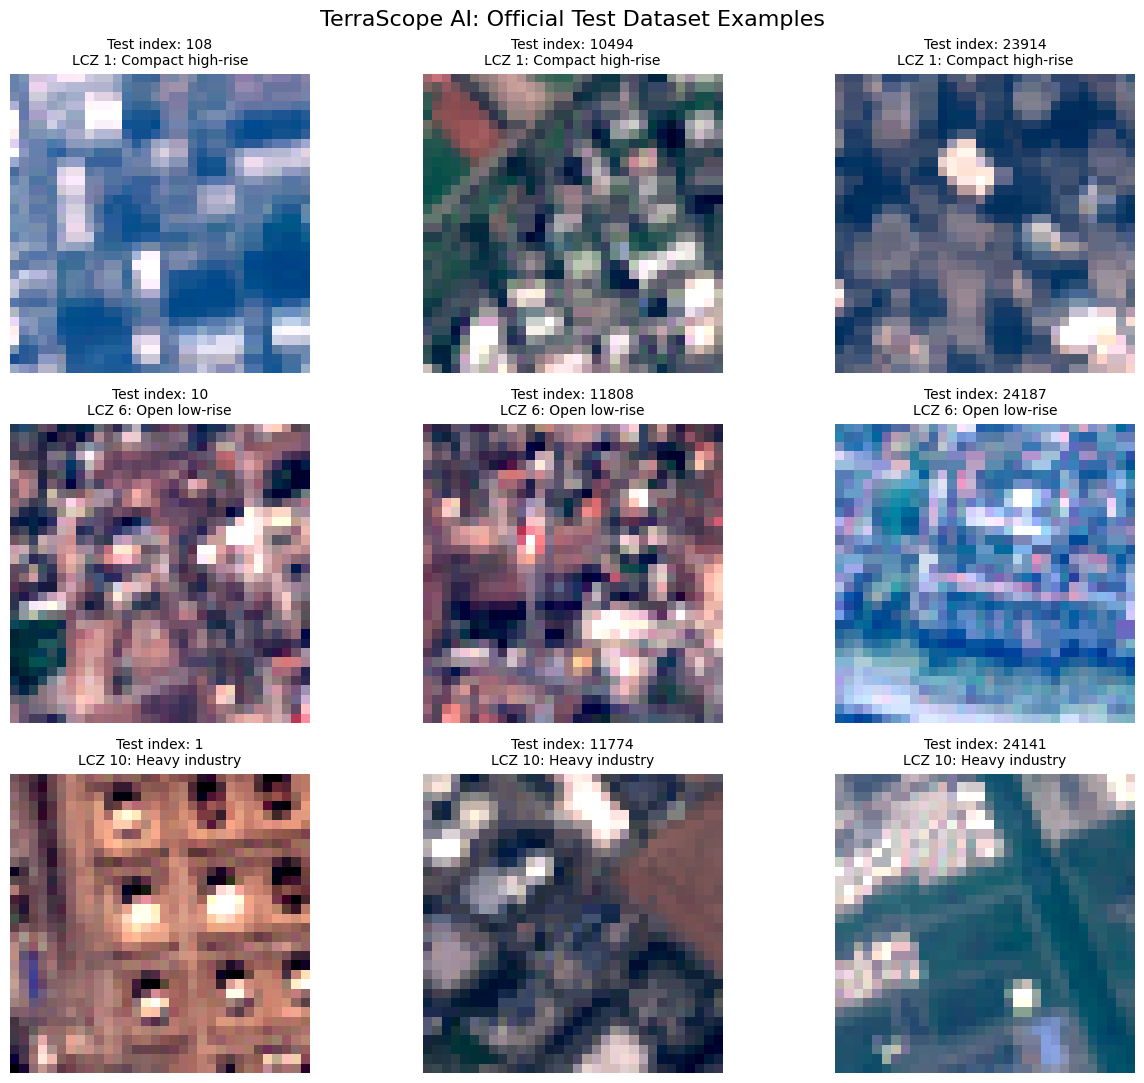

In [75]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

# Three visually interesting urban categories:
# LCZ 1: Compact high-rise
# LCZ 6: Open low-rise
# LCZ 10: Heavy industry

candidate_classes = [0, 5, 9]

selected = []

for class_id in candidate_classes:
    indices = np.where(
        (y_true == class_id) & (y_pred == class_id)
    )[0]

    positions = np.linspace(
        0, len(indices) - 1, min(3, len(indices)), dtype=int
    )

    selected.extend(indices[positions])

def enhance_for_display(image):
    """Contrast enhancement for visualization only."""
    image = image.astype(np.float32)

    low = np.percentile(image, 2)
    high = np.percentile(image, 98)

    if high <= low:
        return np.zeros_like(image)

    image = np.clip((image - low) / (high - low), 0, 1)

    # Slight brightness adjustment
    image = image ** 0.75

    return image

fig, axes = plt.subplots(3, 3, figsize=(13, 11))

with h5py.File(TEST_H5, "r") as f:
    for ax, idx in zip(axes.flat, selected):

        # B2, B3, B4 -> B4, B3, B2 (RGB)
        raw = f["sen2"][idx, :, :, :3][..., ::-1].copy()

        display_image = enhance_for_display(raw)

        class_id = int(y_true[idx])

        ax.imshow(display_image)
        ax.set_title(
            f"Test index: {idx}\n"
            f"LCZ {class_id + 1}: {CLASS_NAMES[class_id]}",
            fontsize=10
        )
        ax.axis("off")

plt.suptitle(
    "TerraScope AI: Official Test Dataset Examples",
    fontsize=16
)
plt.tight_layout()
plt.show()

In [76]:
import sys
import torch
import h5py
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

# Project location
ROOT = Path("/content/drive/MyDrive/TerraScope-AI")

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.models.resnet import build_resnet18
from src.data.preprocessing import preprocess_sentinel2_rgb

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Model configuration
NUM_CLASSES = 17
SAMPLE_INDEX = 10494

CLASS_NAMES = [
    "Compact high-rise",
    "Compact midrise",
    "Compact low-rise",
    "Open high-rise",
    "Open midrise",
    "Open low-rise",
    "Lightweight low-rise",
    "Large low-rise",
    "Sparsely built",
    "Heavy industry",
    "Dense trees",
    "Scattered trees",
    "Bush/scrub",
    "Low plants",
    "Bare rock or paved",
    "Bare soil or sand",
    "Water",
]

# Load M4 checkpoint
checkpoint_path = ROOT / "results/so2sat/M4/best_checkpoint.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

model = build_resnet18(
    num_classes=NUM_CLASSES,
    initialization="scratch"
)

model.load_state_dict(checkpoint["model_state_dict"], strict=True)
model = model.to(device)
model.eval()

print("M4 checkpoint loaded successfully.")

# Load actual official test sample
test_path = ROOT / "data/raw/testing.h5"

with h5py.File(test_path, "r") as f:
    raw_image = f["sen2"][
        SAMPLE_INDEX, :, :, :3
    ][..., ::-1].copy()

    true_label = int(
        np.argmax(f["label"][SAMPLE_INDEX])
    )

# Apply the exact project preprocessing
input_tensor = preprocess_sentinel2_rgb(raw_image)
input_tensor = input_tensor.unsqueeze(0).to(device)

# Run fresh inference
with torch.inference_mode():
    logits = model(input_tensor)
    probabilities = torch.softmax(logits, dim=1)[0]

predicted_label = int(probabilities.argmax().item())
confidence = float(probabilities[predicted_label].item())

# Verify against saved official test prediction
print("\nLIVE PREDICTION")
print("Sample index:", SAMPLE_INDEX)
print("Actual class:", true_label + 1, CLASS_NAMES[true_label])
print("Predicted class:", predicted_label + 1, CLASS_NAMES[predicted_label])
print(f"Prediction confidence: {confidence:.2%}")
print("Correct:", predicted_label == true_label)

Using device: cpu
M4 checkpoint loaded successfully.

LIVE PREDICTION
Sample index: 10494
Actual class: 1 Compact high-rise
Predicted class: 1 Compact high-rise
Prediction confidence: 100.00%
Correct: True


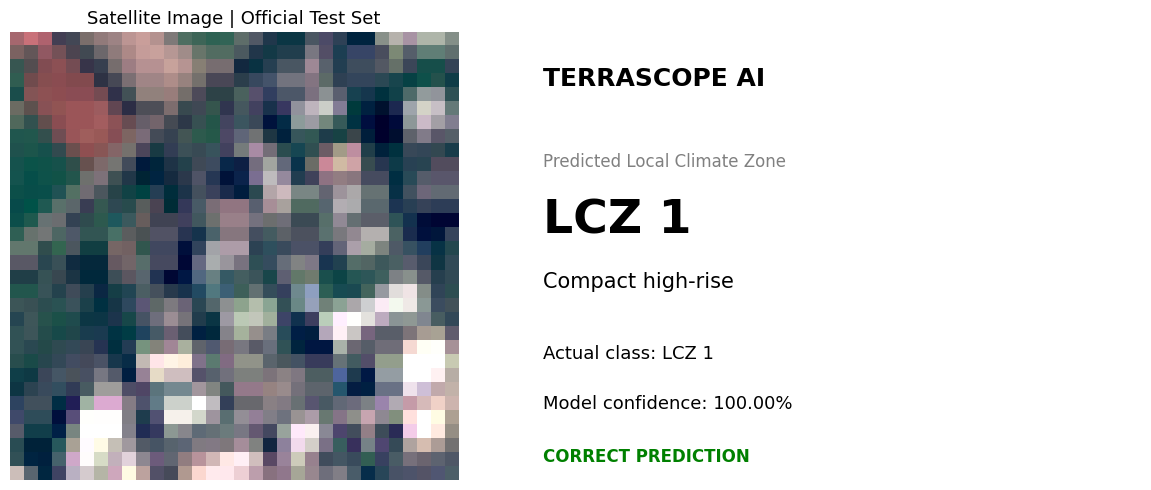

In [84]:
import matplotlib.pyplot as plt
import numpy as np

# Enhance the image for display only
def enhance_for_display(image):
    image = image.astype(np.float32)

    low = np.percentile(image, 2)
    high = np.percentile(image, 98)

    if high <= low:
        return np.zeros_like(image)

    image = np.clip((image - low) / (high - low), 0, 1)
    return image ** 0.75

display_image = enhance_for_display(raw_image)

fig = plt.figure(figsize=(12, 5))
gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.2])

# Satellite image
ax1 = fig.add_subplot(gs[0, 0])
ax1.imshow(display_image)
ax1.set_title("Satellite Image | Official Test Set", fontsize=13)
ax1.axis("off")

# Prediction results
ax2 = fig.add_subplot(gs[0, 1])
ax2.axis("off")

status = "CORRECT PREDICTION" if predicted_label == true_label else "INCORRECT PREDICTION"

ax2.text(
    0.05, 0.88, "TERRASCOPE AI",
    fontsize=18, weight="bold",
    transform=ax2.transAxes
)

ax2.text(
    0.05, 0.70, "Predicted Local Climate Zone",
    fontsize=12, color="gray",
    transform=ax2.transAxes
)

ax2.text(
    0.05, 0.55,
    f"LCZ {predicted_label + 1}",
    fontsize=34, weight="bold",
    transform=ax2.transAxes
)

ax2.text(
    0.05, 0.43,
    CLASS_NAMES[predicted_label],
    fontsize=15,
    transform=ax2.transAxes
)

ax2.text(
    0.05, 0.27,
    f"Actual class: LCZ {true_label + 1}",
    fontsize=13,
    transform=ax2.transAxes
)

ax2.text(
    0.05, 0.16,
    f"Model confidence: {confidence:.2%}",
    fontsize=13,
    transform=ax2.transAxes
)

ax2.text(
    0.05, 0.04, status,
    fontsize=12, weight="bold",
    color="green" if predicted_label == true_label else "red",
    transform=ax2.transAxes
)

plt.tight_layout()
plt.show()